<center><h1>1-ab: Introduction to Neural Networks</h1></center>

<center><h2><a href="https://rdfia.github.io/">Course link</a></h2></center>

# Warning :
# Do "File -> Save a copy in Drive" before you start modifying the notebook, otherwise your modifications will not be saved.


In [1]:
!wget https://github.com/rdfia/rdfia.github.io/raw/master/data/2-ab.zip
!unzip -j 2-ab.zip
!wget https://github.com/rdfia/rdfia.github.io/raw/master/code/2-ab/utils-data.py

--2026-11-14 14:50:53--  https://github.com/rdfia/rdfia.github.io/raw/master/data/2-ab.zip
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/2-ab.zip [following]
--2026-11-14 14:50:54--  https://raw.githubusercontent.com/rdfia/rdfia.github.io/master/data/2-ab.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.108.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13423991 (13M) [application/zip]
Saving to: ‘2-ab.zip’

2-ab.zip            100%[===================>]  12.80M  --.-KB/s    in 0.1s    

2026-11-14 14:50:55 (123 MB/s) - ‘2-ab.zip’ saved [13423991/13423991]

Archive:  2-ab.zip
  inflating: ._2-ab            

In [2]:
import math
import torch
from torch.autograd import Variable
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
%run 'utils-data.py'

# Part 1 : Forward and backward passes "by hands"

In [3]:
def init_params(nx, nh, ny):
    """
    nx, nh, ny: integers
    out params: dictionnary
    """
    params = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wh, Wy, bh, by

    params["Wh"] = torch.randn(nh, nx) * 0.3
    params["Wy"] = torch.randn(ny, nh) * 0.3
    params["bh"] = torch.zeros(nh, 1)
    params["by"] = torch.zeros(ny, 1)

    ####################
    ##      END        #
    ####################
    return params

In [4]:
def forward(params, X):
    """
    params: dictionnary
    X: (n_batch, dimension)
    """
    bsize = X.size(0)
    nh = params['Wh'].size(0)
    ny = params['Wy'].size(0)
    outputs = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for X, htilde, h, ytilde, yhat

    outputs["X"] = X.t()
    outputs["htilde"] = torch.mm(params["Wh"], outputs["X"]) + params["bh"]
    outputs["h"] = torch.tanh(outputs["htilde"])
    outputs["ytilde"] = torch.mm(params["Wy"], outputs["h"]) + params["by"]
    exp_ytilde = torch.exp(outputs["ytilde"] - torch.max(outputs["ytilde"], dim=0, keepdim=True).values)
    outputs["yhat"] = (exp_ytilde / torch.sum(exp_ytilde, dim=0, keepdim=True)).t()

    ####################
    ##      END        #
    ####################

    return outputs['yhat'], outputs

In [5]:
def loss_accuracy(Yhat, Y):

    #####################
    ## Your code here  ##
    #####################

    bsize = Y.size(0)
    L = (-torch.sum(Y * torch.log(Yhat + 1e-15)) / bsize).item()
    acc = 100.0 * torch.sum(torch.argmax(Yhat, dim=1) == torch.argmax(Y, dim=1)).item() / bsize

    ####################
    ##      END        #
    ####################

    return L, acc

In [6]:
def backward(params, outputs, Y):
    bsize = Y.shape[0]
    grads = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wy, Wh, by, bh

    d_ytilde = outputs["yhat"].t() - Y.t()
    d_htilde = torch.mm(params["Wy"].t(), d_ytilde) * (1 - outputs["h"] ** 2)

    grads["Wy"] = torch.mm(d_ytilde, outputs["h"].t()) / bsize
    grads["Wh"] = torch.mm(d_htilde, outputs["X"].t()) / bsize
    grads["by"] = torch.sum(d_ytilde, dim=1, keepdim=True) / bsize
    grads["bh"] = torch.sum(d_htilde, dim=1, keepdim=True) / bsize

    ####################
    ##      END        #
    ####################
    return grads

In [7]:
def sgd(params, grads, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the params values

    params["Wh"] = params["Wh"] - eta * grads["Wh"]
    params["Wy"] = params["Wy"] - eta * grads["Wy"]
    params["bh"] = params["bh"] - eta * grads["bh"]
    params["by"] = params["by"] - eta * grads["by"]

    ####################
    ##      END        #
    ####################
    return params

## Global learning procedure "by hands"

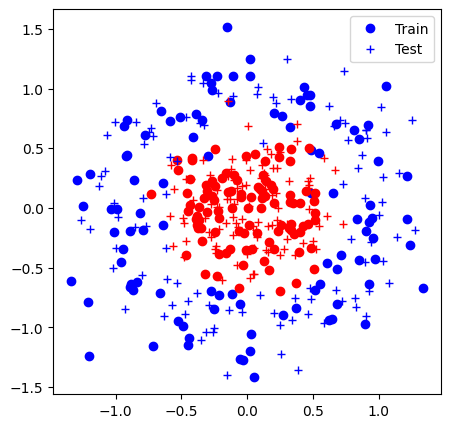

Iter 0: Acc train 53.0% (0.70), acc test 49.5% (0.70)


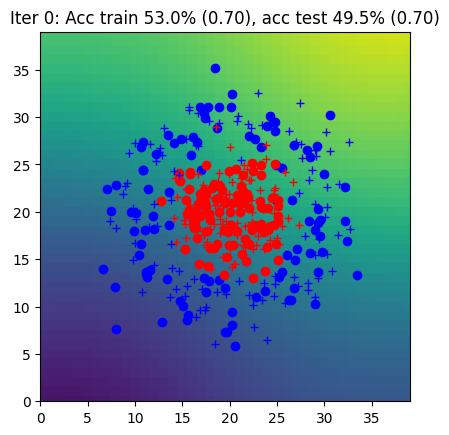

Iter 1: Acc train 53.0% (0.69), acc test 50.5% (0.69)


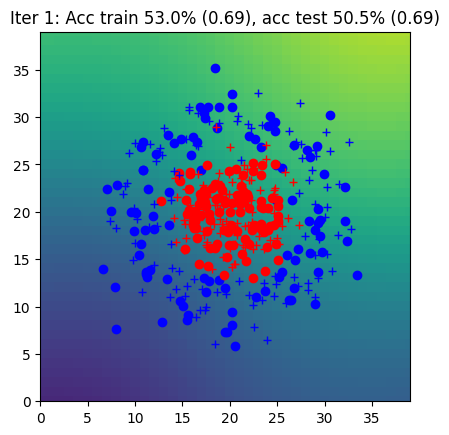

Iter 2: Acc train 54.5% (0.69), acc test 54.5% (0.69)


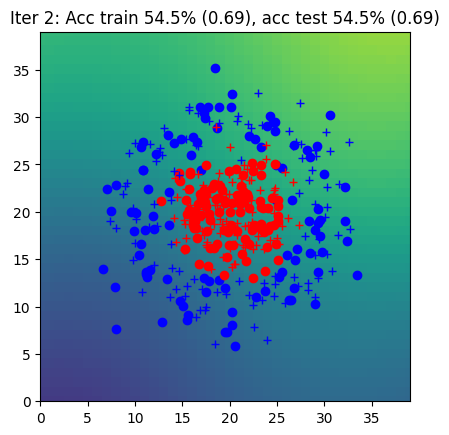

Iter 3: Acc train 53.5% (0.69), acc test 53.5% (0.69)


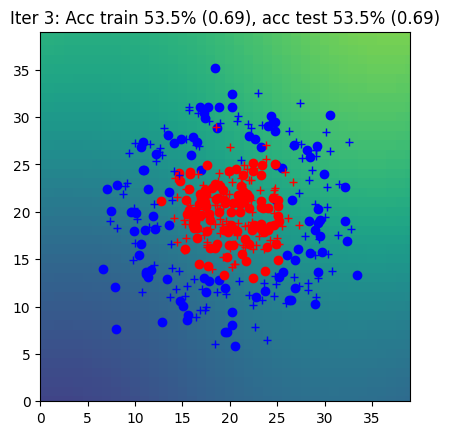

Iter 4: Acc train 57.5% (0.69), acc test 60.5% (0.69)


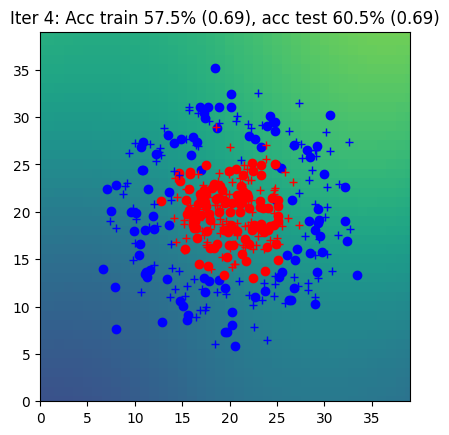

Iter 5: Acc train 58.0% (0.69), acc test 60.0% (0.69)


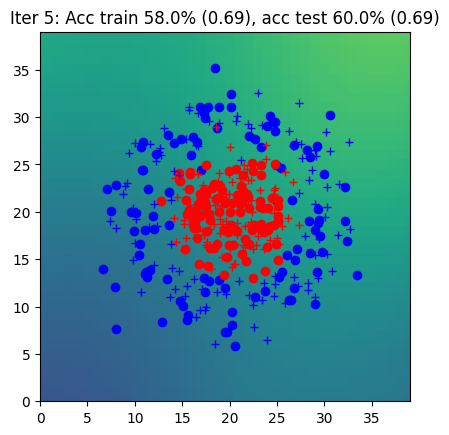

Iter 6: Acc train 56.5% (0.69), acc test 58.5% (0.69)


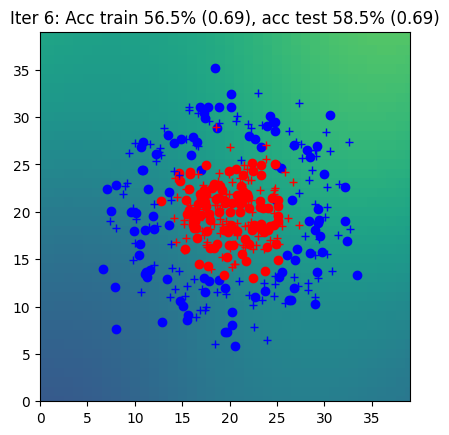

Iter 7: Acc train 53.5% (0.69), acc test 58.5% (0.69)


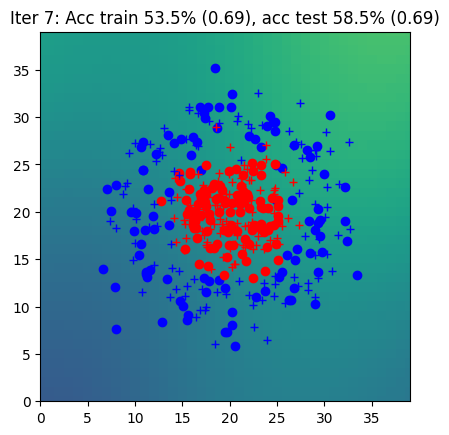

Iter 8: Acc train 58.5% (0.69), acc test 58.5% (0.69)


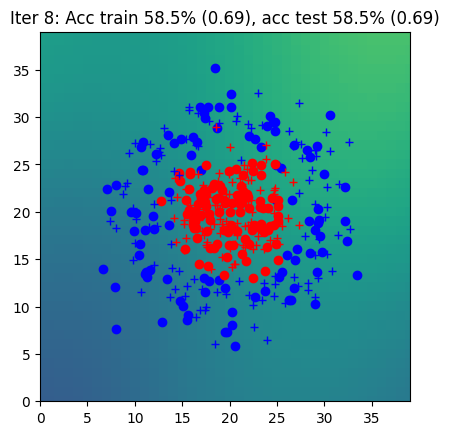

Iter 9: Acc train 53.0% (0.69), acc test 57.5% (0.69)


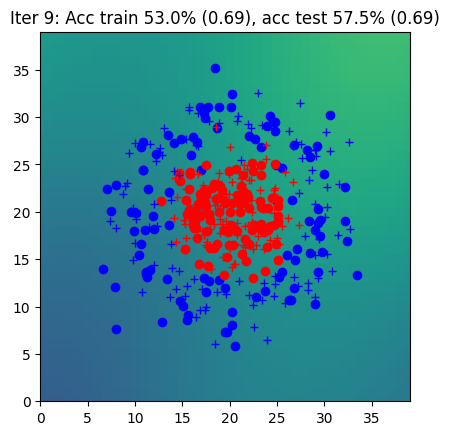

Iter 10: Acc train 53.5% (0.69), acc test 57.5% (0.69)


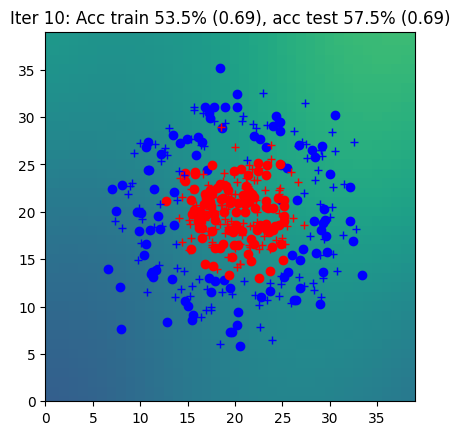

Iter 11: Acc train 54.5% (0.69), acc test 59.0% (0.69)


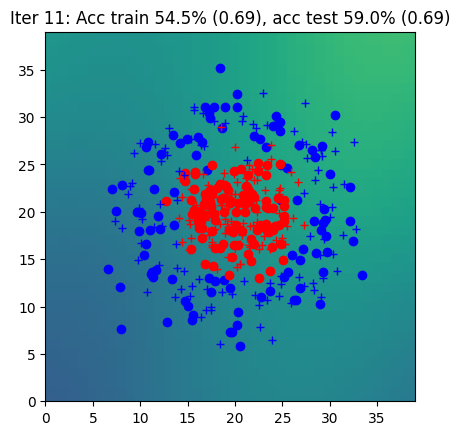

Iter 12: Acc train 58.0% (0.69), acc test 62.0% (0.69)


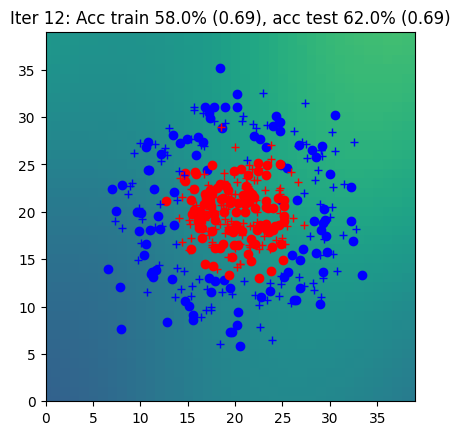

Iter 13: Acc train 56.0% (0.69), acc test 59.5% (0.69)


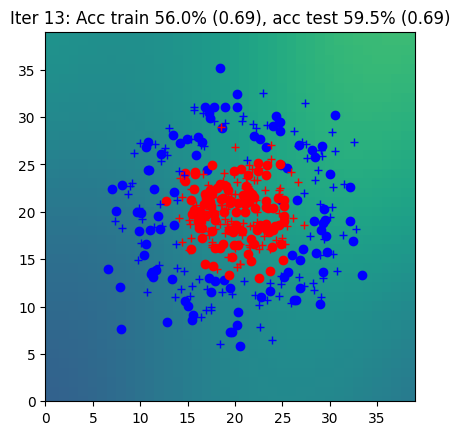

Iter 14: Acc train 60.5% (0.69), acc test 62.0% (0.69)


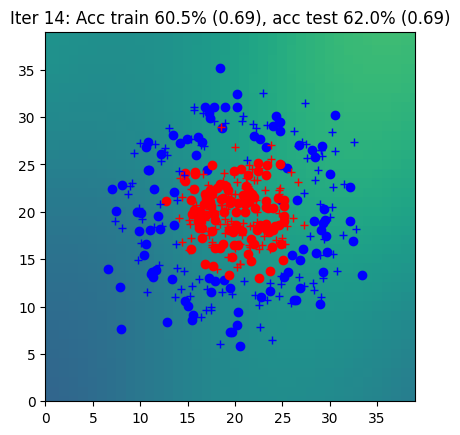

Iter 15: Acc train 59.5% (0.69), acc test 61.5% (0.69)


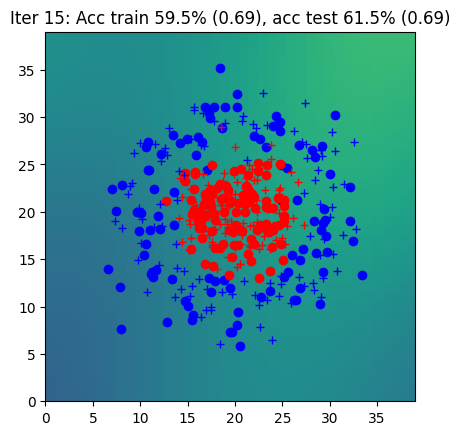

Iter 16: Acc train 60.0% (0.69), acc test 61.5% (0.69)


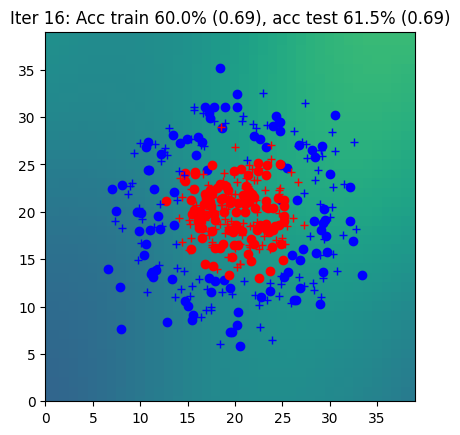

Iter 17: Acc train 59.0% (0.69), acc test 60.5% (0.69)


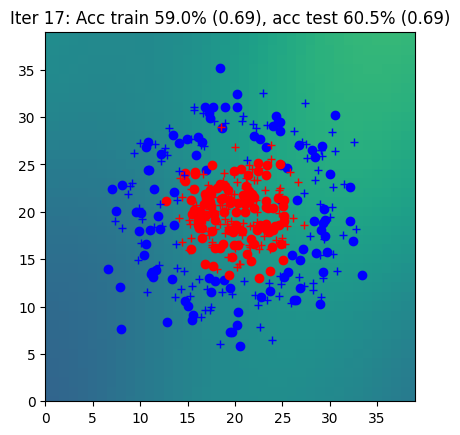

Iter 18: Acc train 61.0% (0.69), acc test 61.0% (0.69)


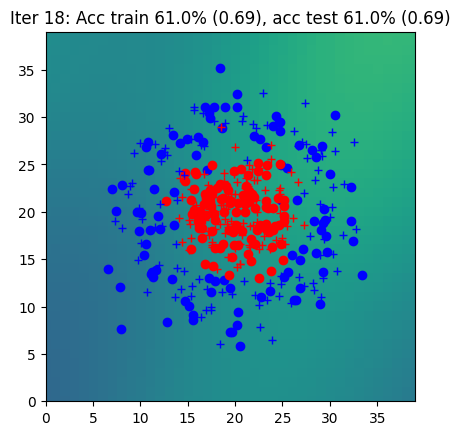

Iter 19: Acc train 58.5% (0.69), acc test 61.5% (0.69)


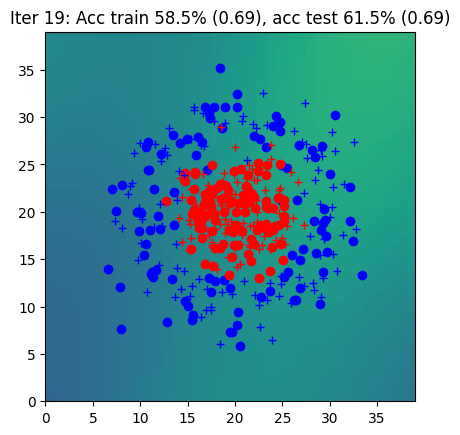

Iter 20: Acc train 58.0% (0.69), acc test 62.5% (0.69)


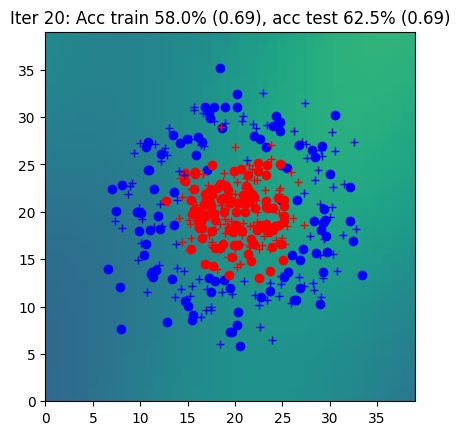

Iter 21: Acc train 58.5% (0.69), acc test 60.0% (0.69)


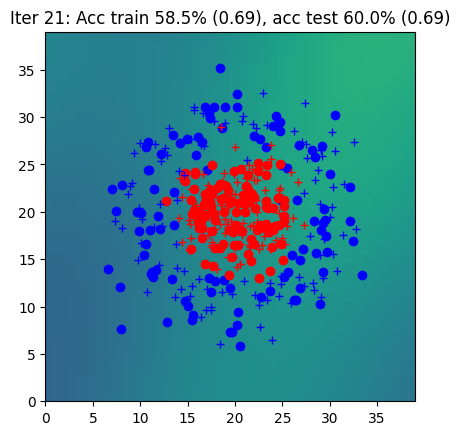

Iter 22: Acc train 58.0% (0.69), acc test 60.5% (0.69)


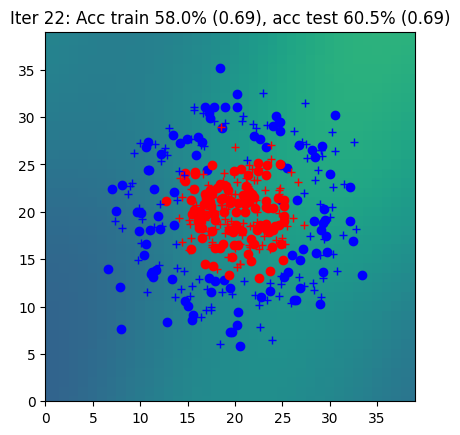

Iter 23: Acc train 58.0% (0.69), acc test 60.5% (0.69)


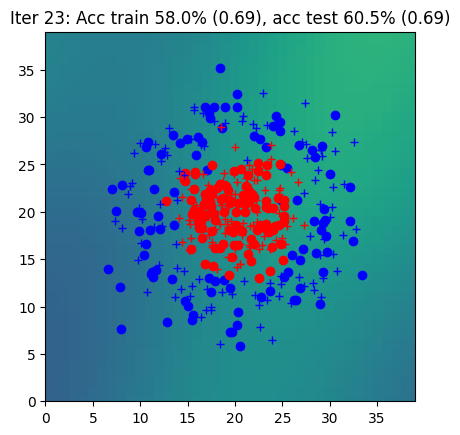

Iter 24: Acc train 59.5% (0.69), acc test 64.0% (0.69)


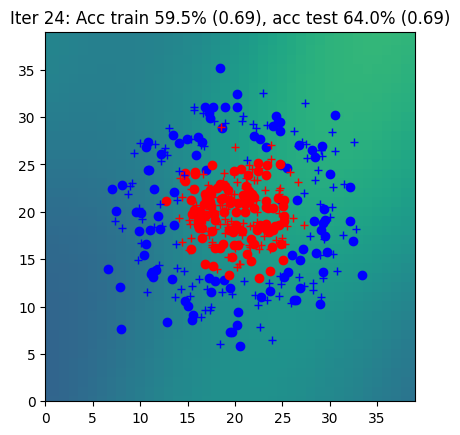

Iter 25: Acc train 59.5% (0.68), acc test 62.5% (0.69)


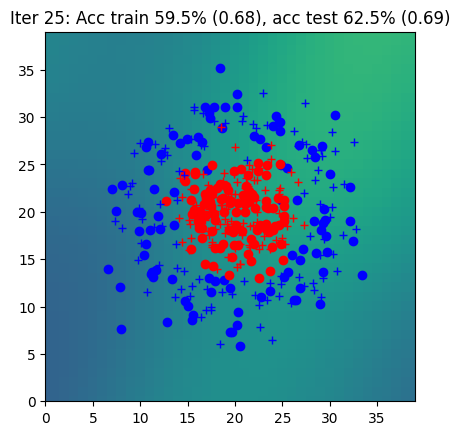

Iter 26: Acc train 60.0% (0.68), acc test 65.0% (0.69)


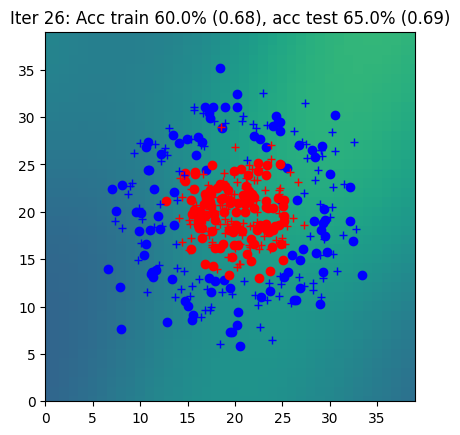

Iter 27: Acc train 60.0% (0.68), acc test 63.5% (0.68)


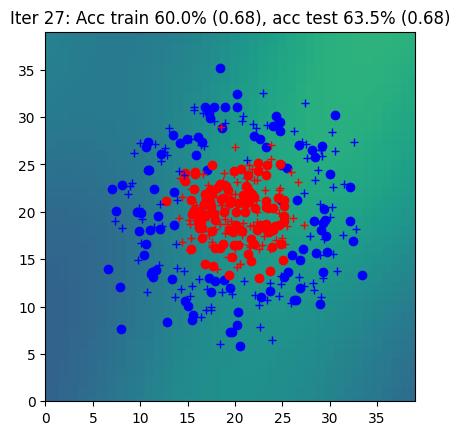

Iter 28: Acc train 58.5% (0.68), acc test 63.5% (0.68)


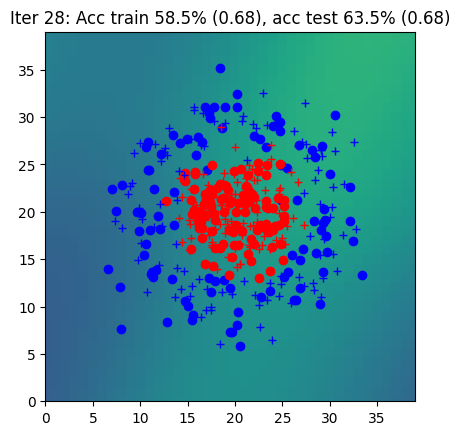

Iter 29: Acc train 60.5% (0.68), acc test 63.5% (0.68)


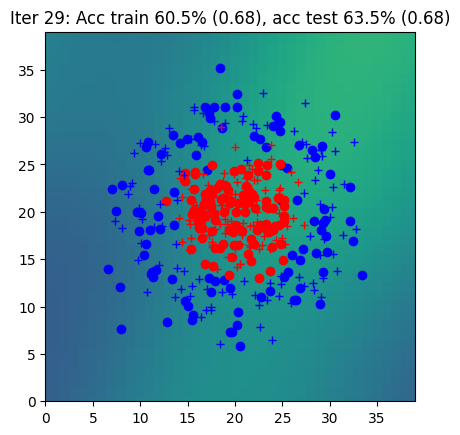

Iter 30: Acc train 60.0% (0.68), acc test 65.5% (0.68)


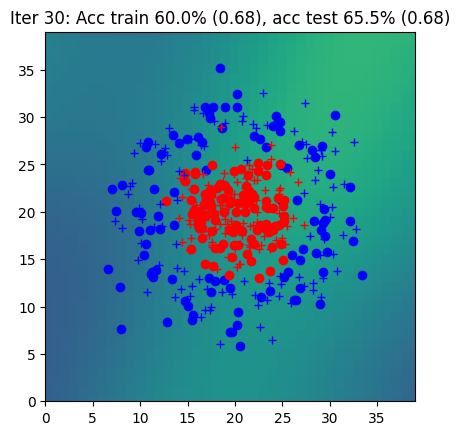

Iter 31: Acc train 61.0% (0.68), acc test 65.5% (0.68)


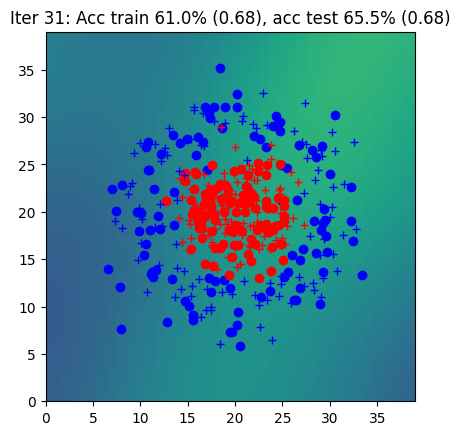

Iter 32: Acc train 61.5% (0.68), acc test 63.5% (0.68)


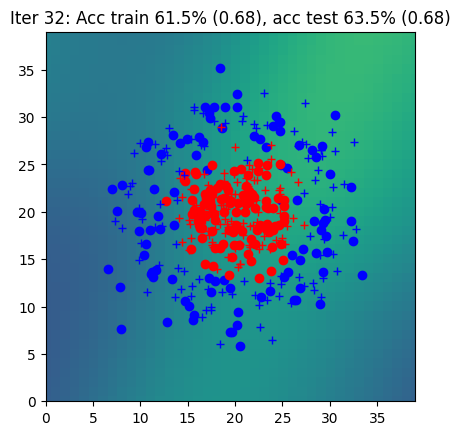

Iter 33: Acc train 62.5% (0.68), acc test 66.0% (0.68)


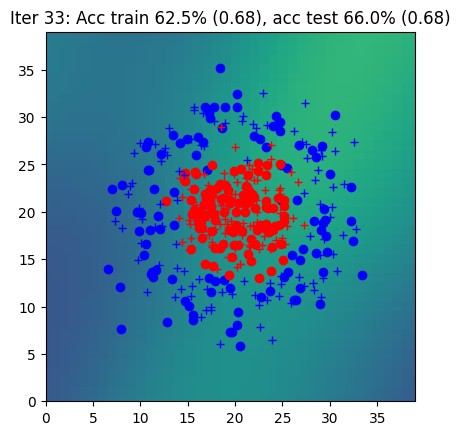

Iter 34: Acc train 62.5% (0.68), acc test 66.5% (0.68)


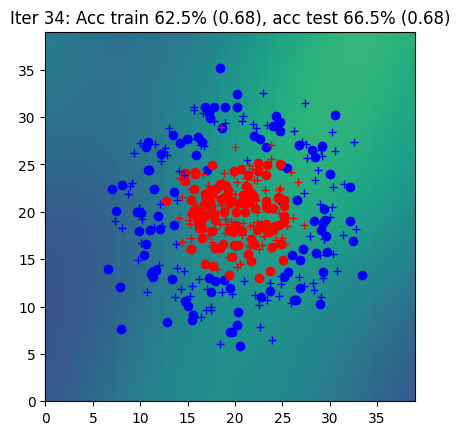

Iter 35: Acc train 62.0% (0.68), acc test 67.0% (0.68)


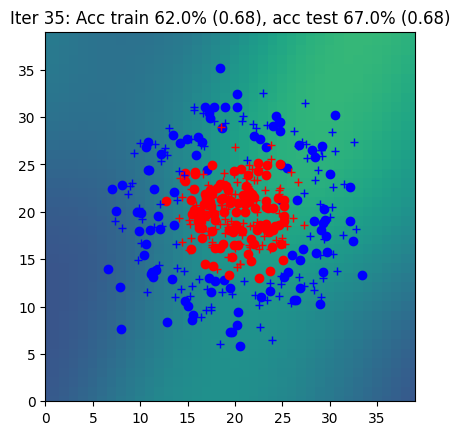

Iter 36: Acc train 63.0% (0.68), acc test 66.0% (0.68)


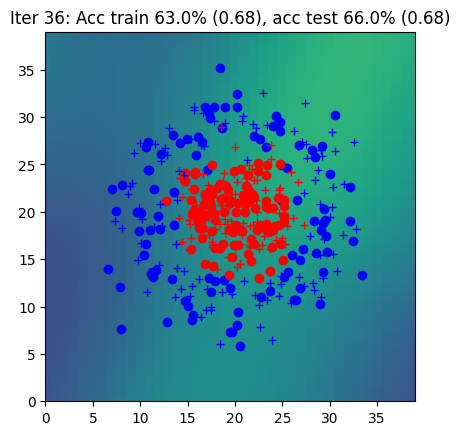

Iter 37: Acc train 64.0% (0.68), acc test 67.5% (0.68)


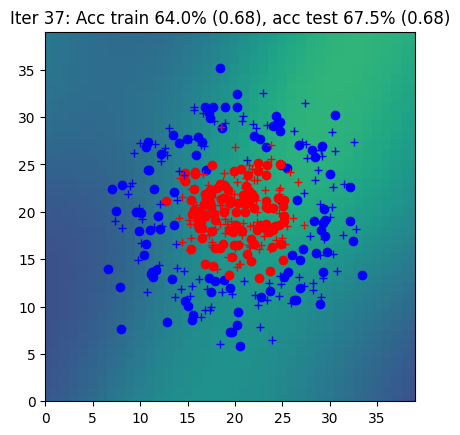

Iter 38: Acc train 64.0% (0.67), acc test 68.5% (0.68)


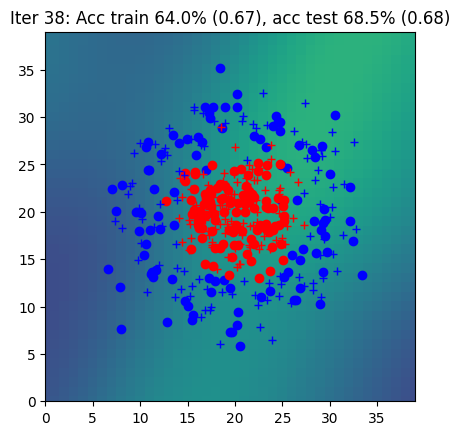

Iter 39: Acc train 64.5% (0.67), acc test 69.5% (0.67)


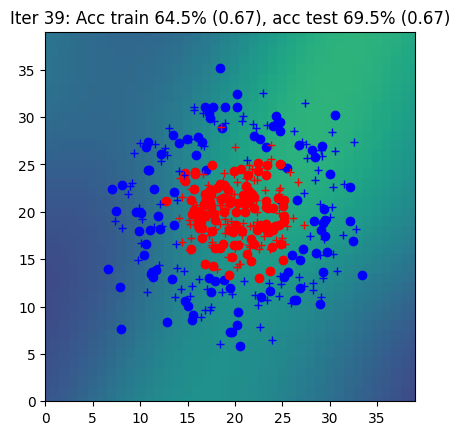

Iter 40: Acc train 67.5% (0.67), acc test 69.0% (0.67)


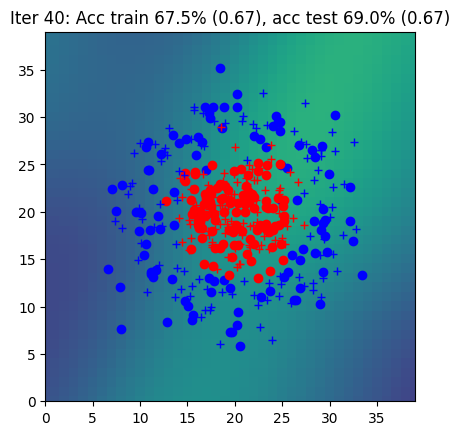

Iter 41: Acc train 66.5% (0.67), acc test 70.5% (0.67)


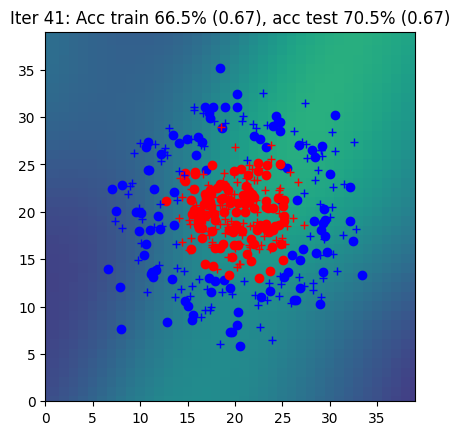

Iter 42: Acc train 67.5% (0.67), acc test 71.0% (0.67)


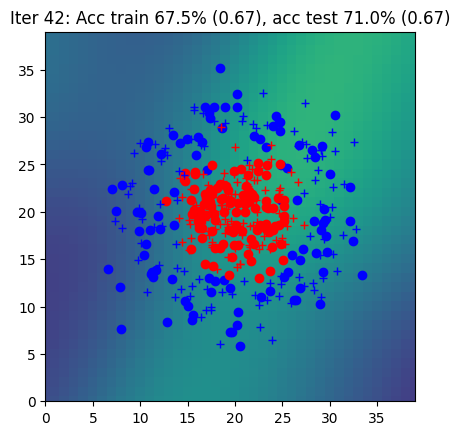

Iter 43: Acc train 66.5% (0.67), acc test 68.0% (0.67)


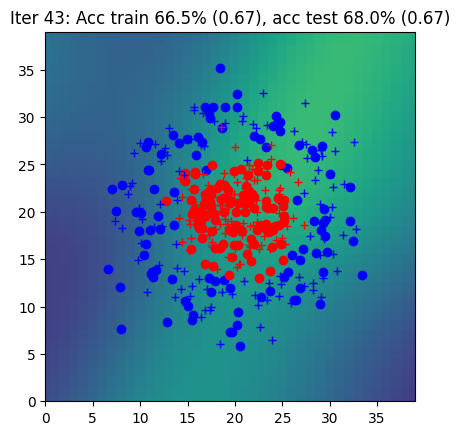

Iter 44: Acc train 68.5% (0.67), acc test 67.0% (0.67)


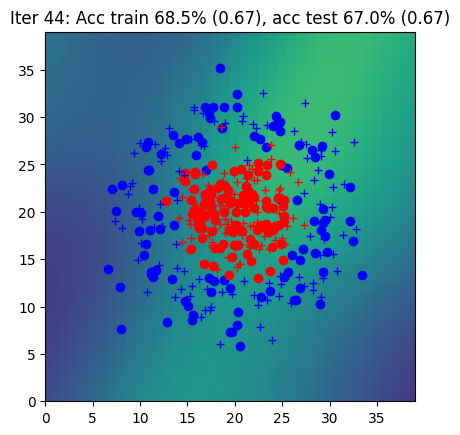

Iter 45: Acc train 66.0% (0.67), acc test 70.5% (0.67)


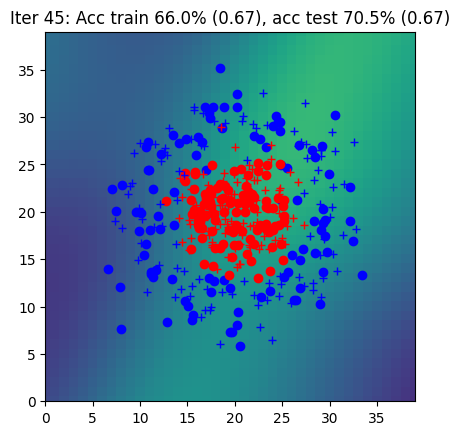

Iter 46: Acc train 69.0% (0.66), acc test 74.0% (0.66)


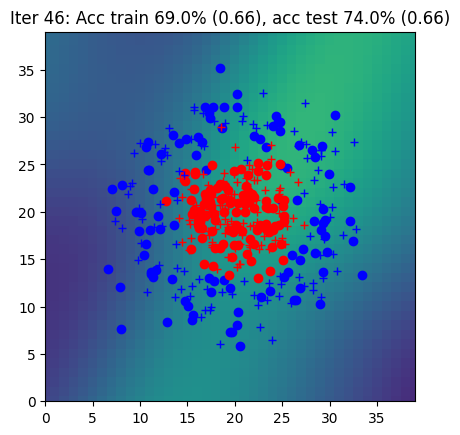

Iter 47: Acc train 71.0% (0.66), acc test 74.5% (0.66)


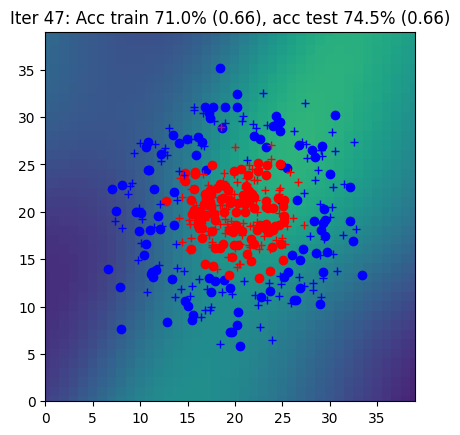

Iter 48: Acc train 71.0% (0.66), acc test 75.5% (0.66)


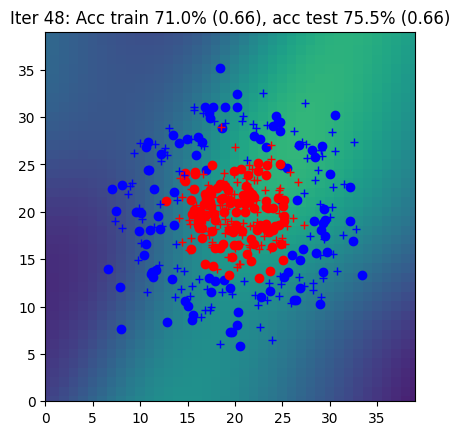

Iter 49: Acc train 68.5% (0.66), acc test 74.5% (0.66)


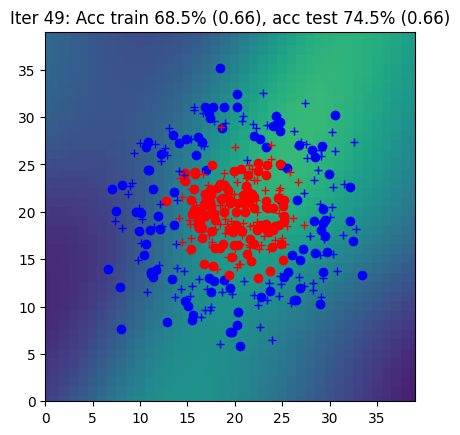

Iter 50: Acc train 70.5% (0.66), acc test 73.5% (0.66)


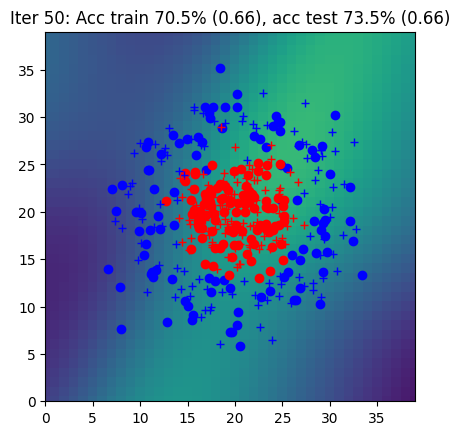

Iter 51: Acc train 70.0% (0.65), acc test 71.0% (0.65)


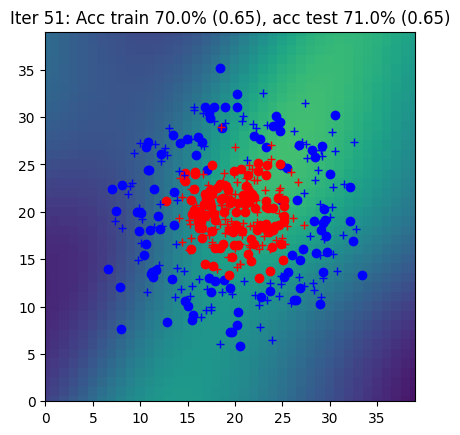

Iter 52: Acc train 70.5% (0.65), acc test 72.5% (0.65)


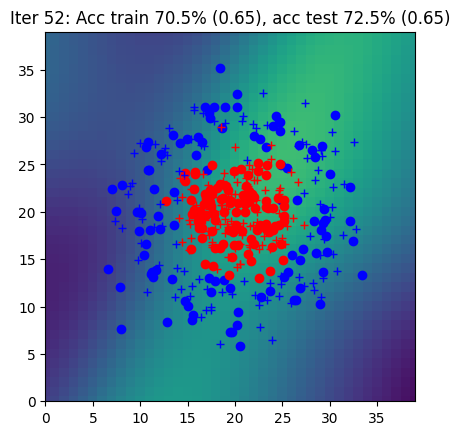

Iter 53: Acc train 70.5% (0.65), acc test 70.5% (0.65)


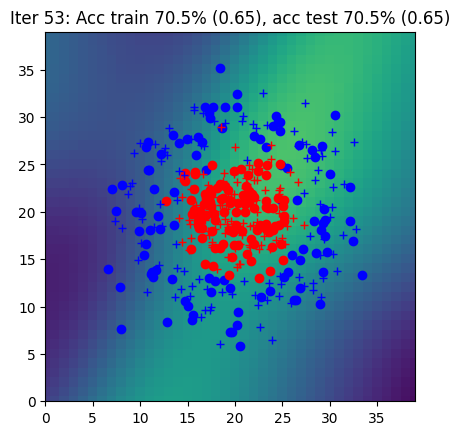

Iter 54: Acc train 70.5% (0.65), acc test 70.5% (0.65)


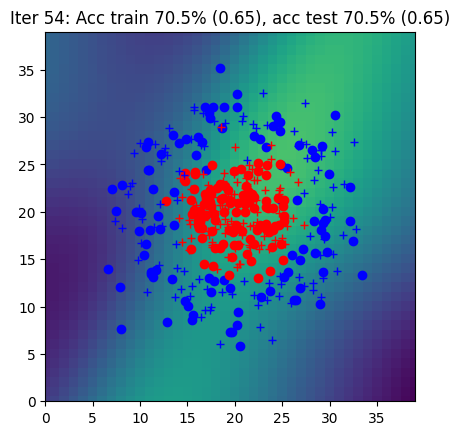

Iter 55: Acc train 71.5% (0.65), acc test 71.5% (0.65)


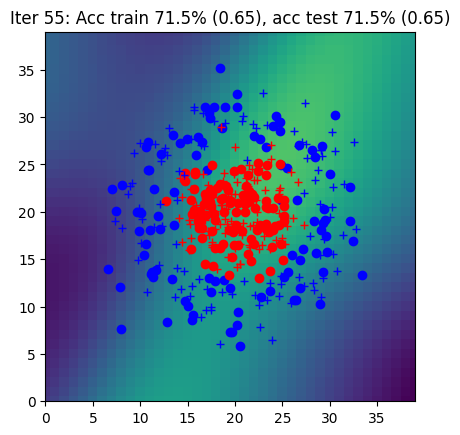

Iter 56: Acc train 71.0% (0.64), acc test 72.0% (0.64)


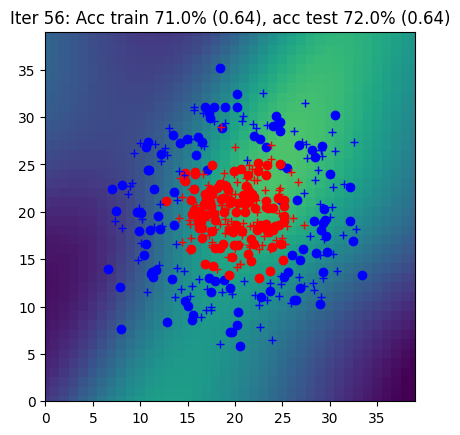

Iter 57: Acc train 72.0% (0.64), acc test 74.0% (0.64)


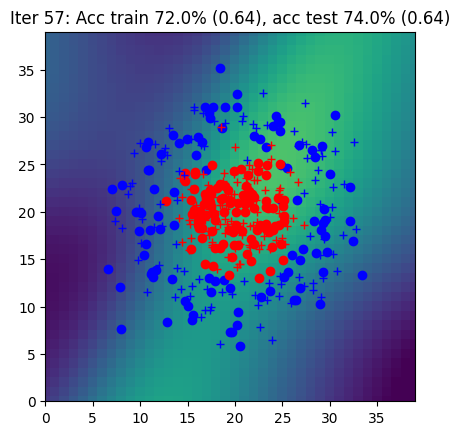

Iter 58: Acc train 72.5% (0.64), acc test 74.5% (0.64)


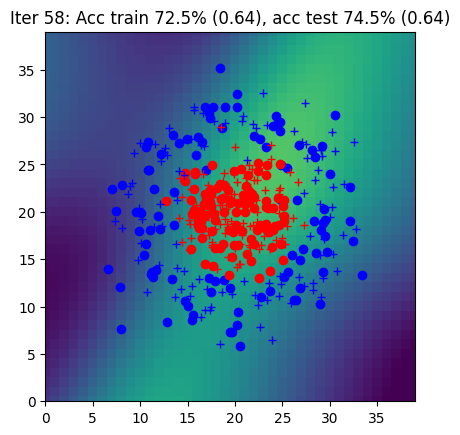

Iter 59: Acc train 73.5% (0.63), acc test 73.5% (0.63)


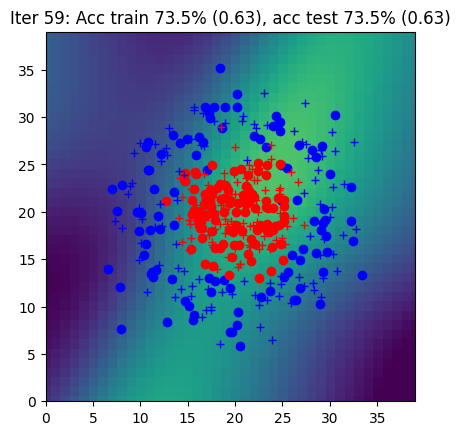

Iter 60: Acc train 75.5% (0.63), acc test 73.5% (0.63)


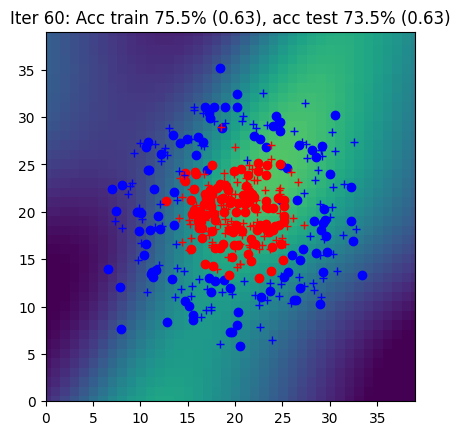

Iter 61: Acc train 76.5% (0.63), acc test 75.0% (0.63)


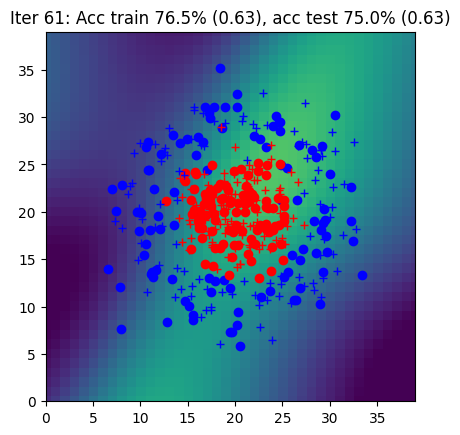

Iter 62: Acc train 77.5% (0.63), acc test 75.0% (0.63)


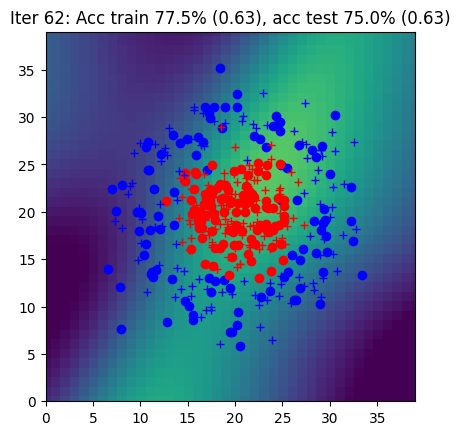

Iter 63: Acc train 76.5% (0.62), acc test 73.5% (0.62)


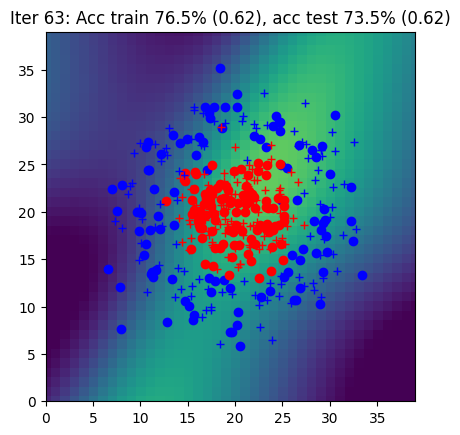

Iter 64: Acc train 79.0% (0.62), acc test 76.0% (0.62)


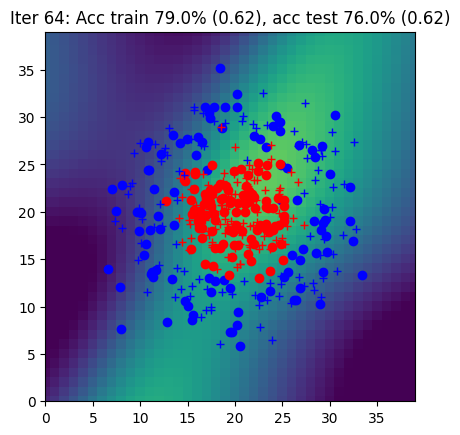

Iter 65: Acc train 80.5% (0.62), acc test 76.0% (0.62)


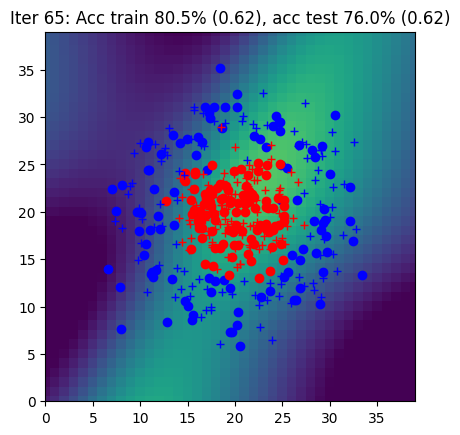

Iter 66: Acc train 79.5% (0.61), acc test 76.5% (0.61)


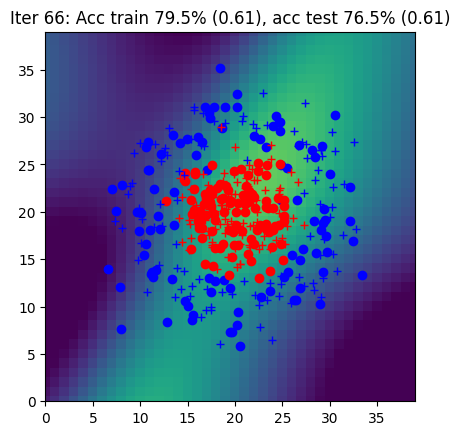

Iter 67: Acc train 79.0% (0.61), acc test 76.0% (0.61)


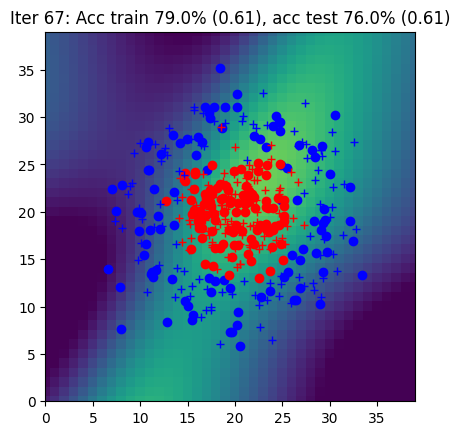

Iter 68: Acc train 79.0% (0.61), acc test 77.0% (0.60)


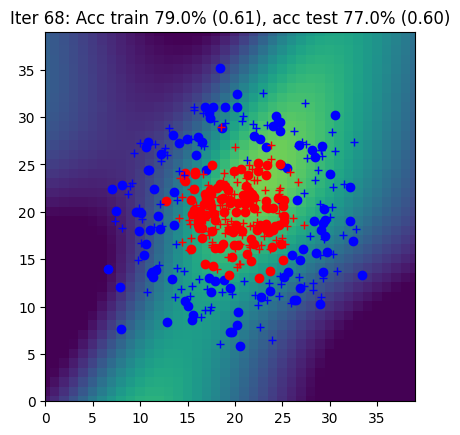

Iter 69: Acc train 79.0% (0.60), acc test 77.0% (0.60)


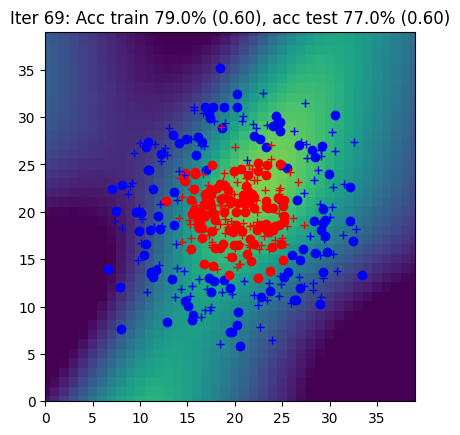

Iter 70: Acc train 81.0% (0.60), acc test 77.5% (0.60)


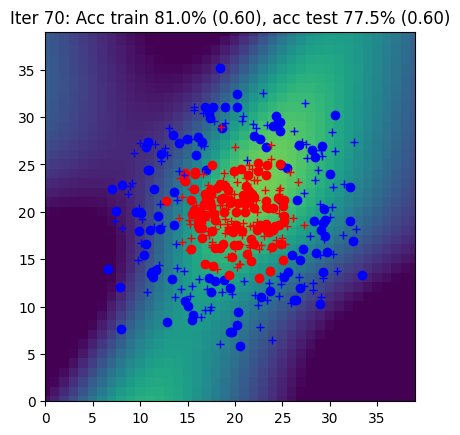

Iter 71: Acc train 80.5% (0.60), acc test 76.5% (0.59)


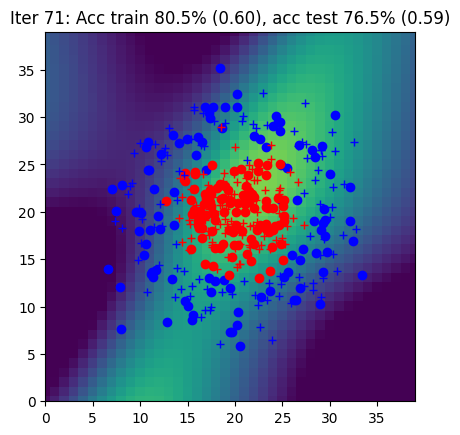

Iter 72: Acc train 79.5% (0.59), acc test 76.0% (0.59)


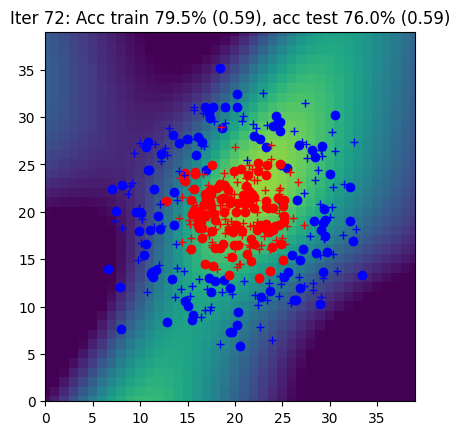

Iter 73: Acc train 80.0% (0.59), acc test 76.5% (0.59)


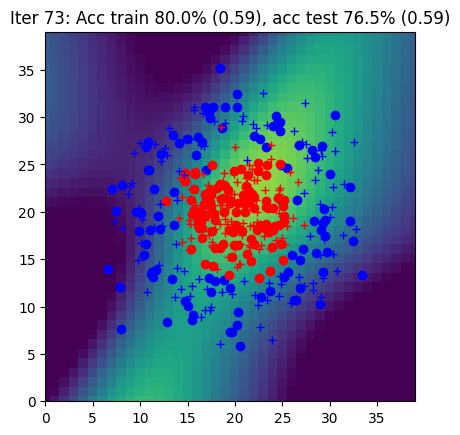

Iter 74: Acc train 80.0% (0.58), acc test 77.0% (0.58)


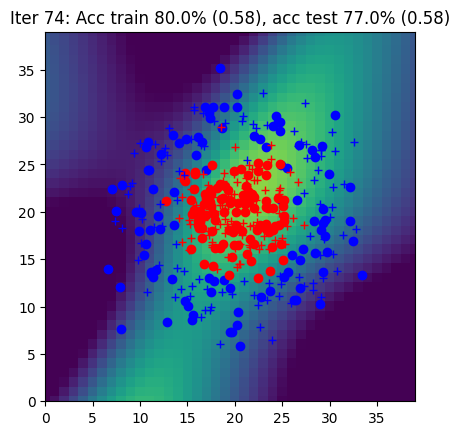

Iter 75: Acc train 80.5% (0.58), acc test 77.0% (0.58)


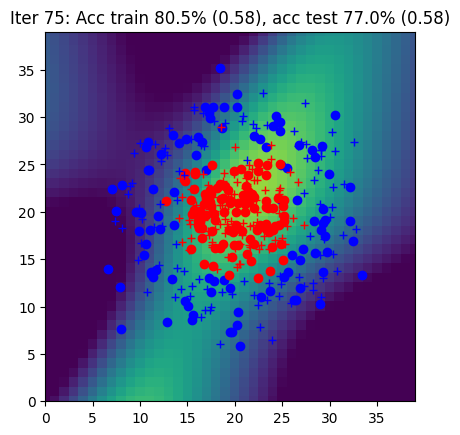

Iter 76: Acc train 80.5% (0.58), acc test 78.5% (0.57)


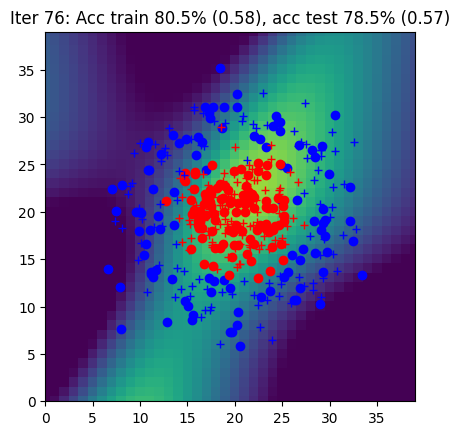

Iter 77: Acc train 80.5% (0.57), acc test 79.0% (0.57)


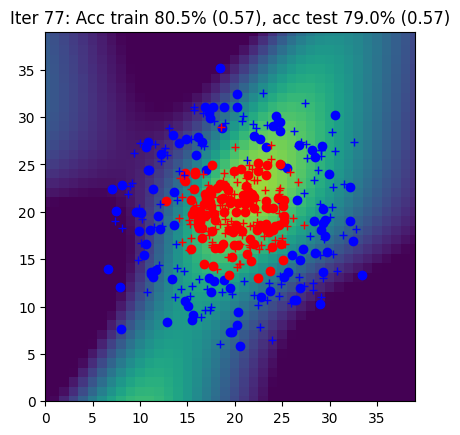

Iter 78: Acc train 80.5% (0.57), acc test 79.0% (0.56)


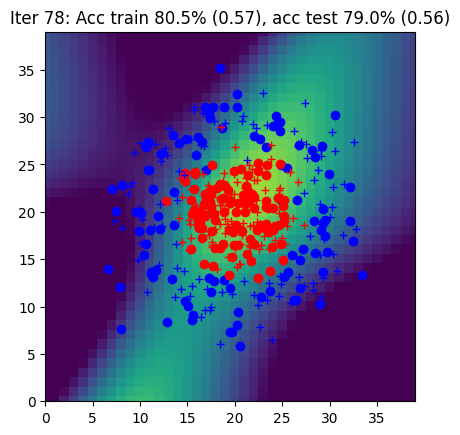

Iter 79: Acc train 80.5% (0.56), acc test 79.5% (0.56)


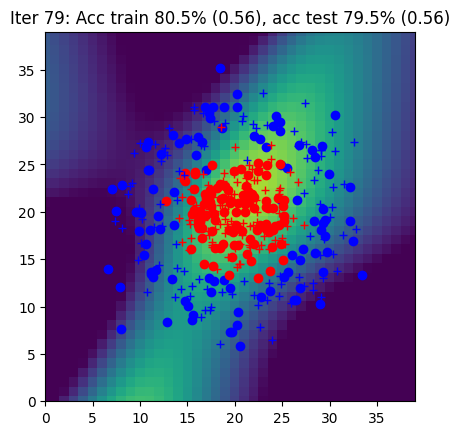

Iter 80: Acc train 80.5% (0.56), acc test 79.0% (0.56)


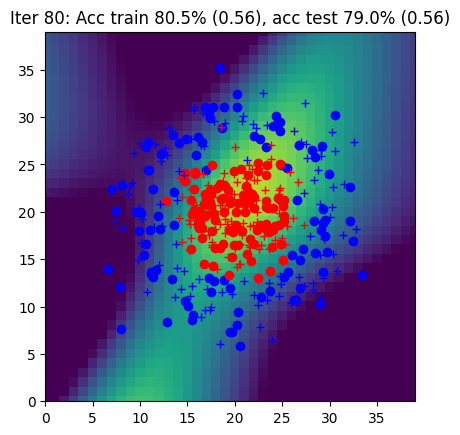

Iter 81: Acc train 80.5% (0.55), acc test 79.5% (0.55)


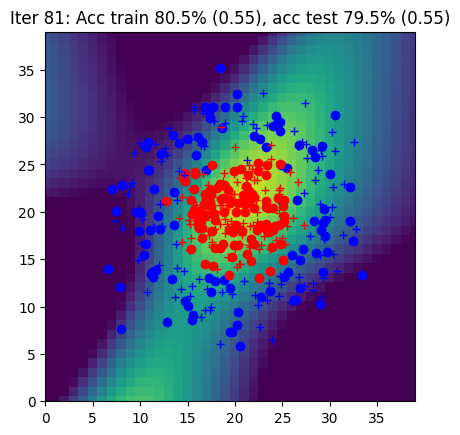

Iter 82: Acc train 80.0% (0.55), acc test 79.5% (0.55)


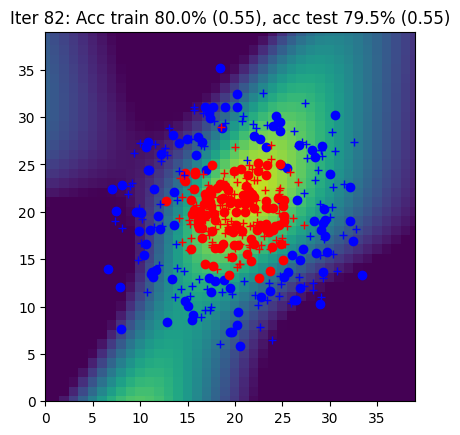

Iter 83: Acc train 80.5% (0.55), acc test 79.5% (0.54)


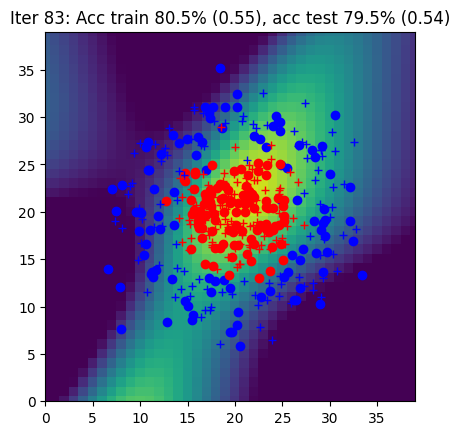

Iter 84: Acc train 80.0% (0.54), acc test 79.0% (0.54)


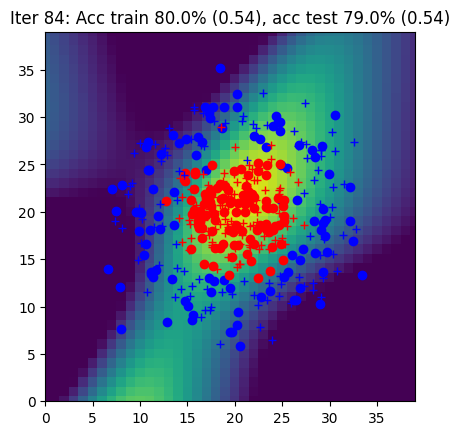

Iter 85: Acc train 80.5% (0.54), acc test 80.5% (0.53)


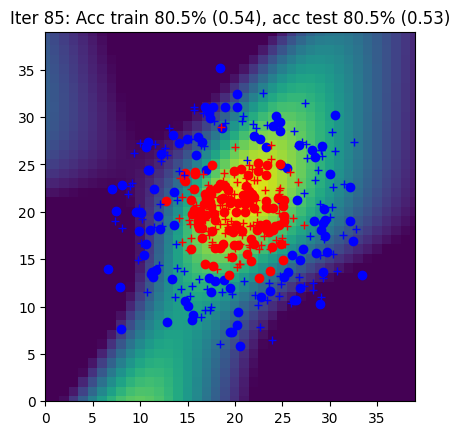

Iter 86: Acc train 80.5% (0.53), acc test 80.5% (0.53)


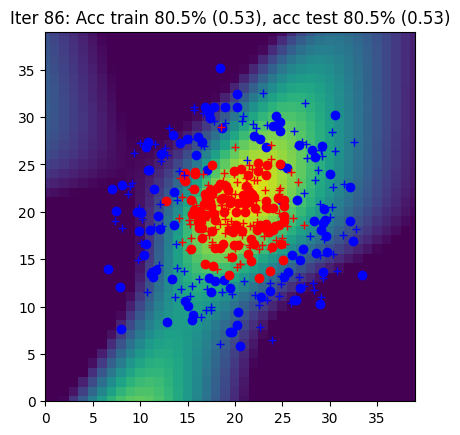

Iter 87: Acc train 80.0% (0.53), acc test 80.5% (0.52)


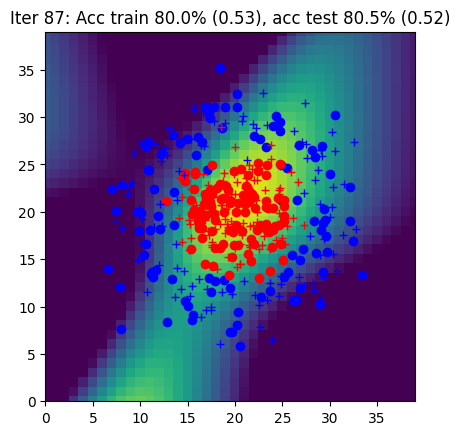

Iter 88: Acc train 80.5% (0.52), acc test 83.0% (0.52)


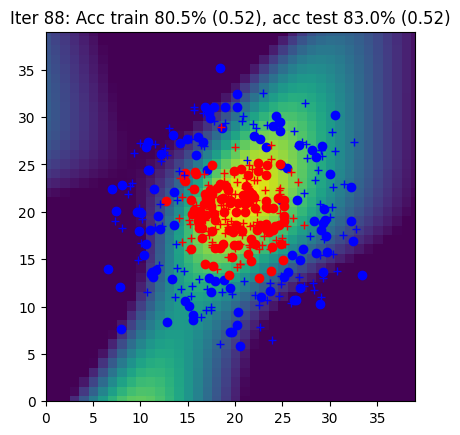

Iter 89: Acc train 83.0% (0.52), acc test 86.0% (0.51)


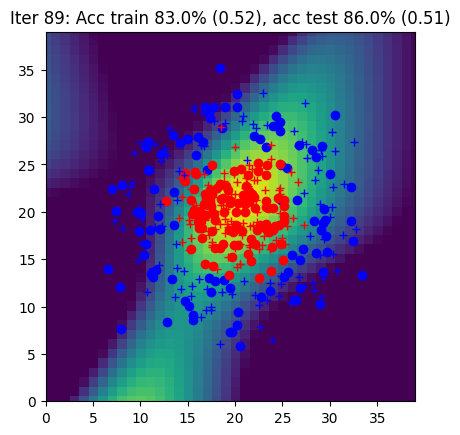

Iter 90: Acc train 81.5% (0.51), acc test 84.5% (0.51)


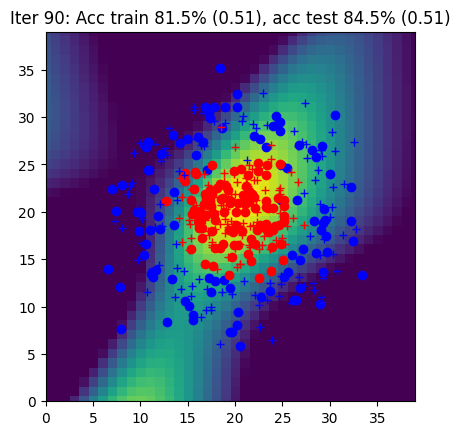

Iter 91: Acc train 80.5% (0.51), acc test 83.5% (0.50)


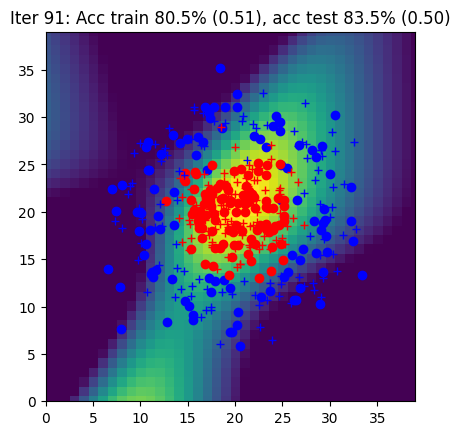

Iter 92: Acc train 82.0% (0.50), acc test 85.0% (0.50)


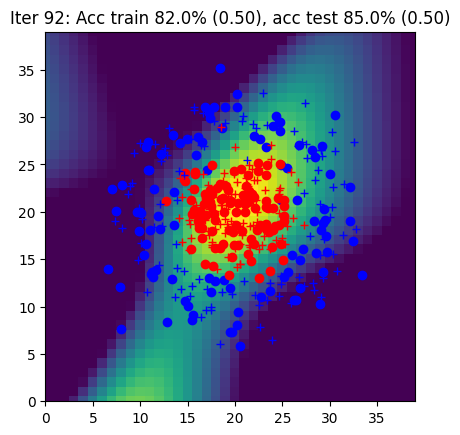

Iter 93: Acc train 84.5% (0.50), acc test 86.5% (0.49)


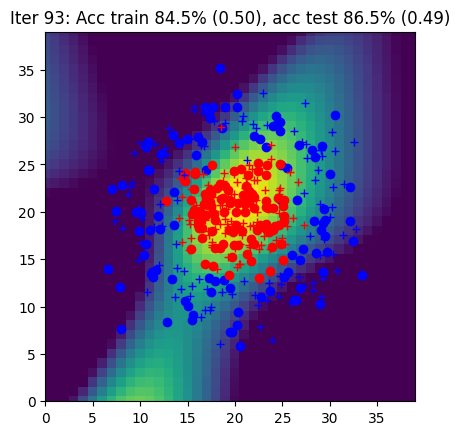

Iter 94: Acc train 84.5% (0.49), acc test 86.5% (0.49)


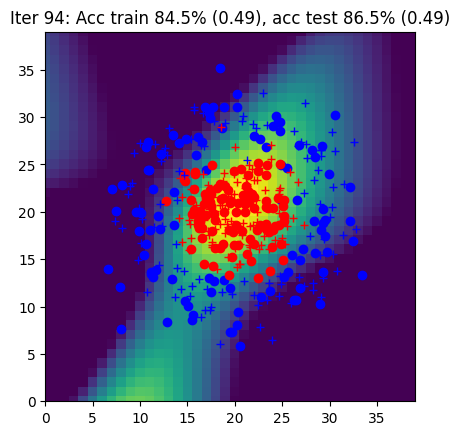

Iter 95: Acc train 84.5% (0.49), acc test 86.5% (0.48)


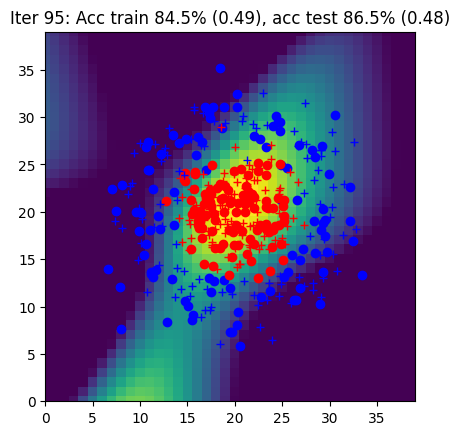

Iter 96: Acc train 83.0% (0.49), acc test 86.0% (0.48)


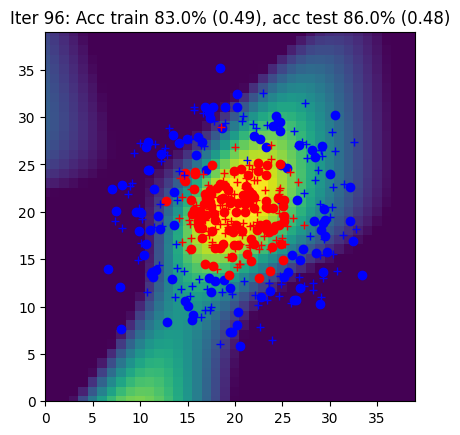

Iter 97: Acc train 82.5% (0.48), acc test 86.5% (0.48)


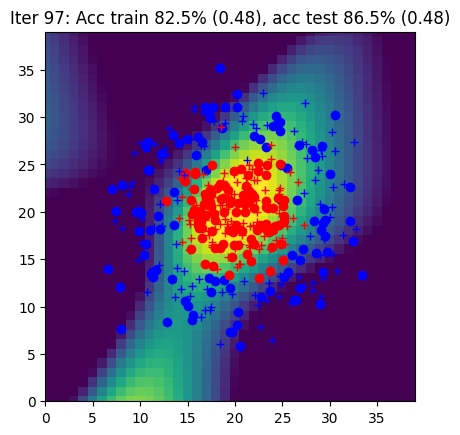

Iter 98: Acc train 84.5% (0.48), acc test 88.0% (0.47)


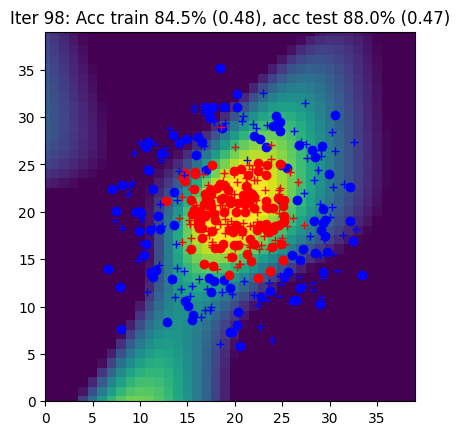

Iter 99: Acc train 84.5% (0.47), acc test 88.5% (0.47)


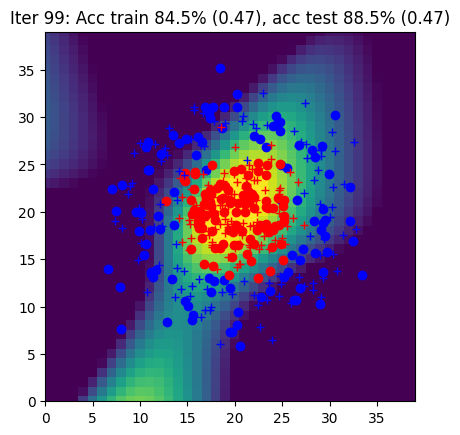

Iter 100: Acc train 84.5% (0.47), acc test 89.0% (0.46)


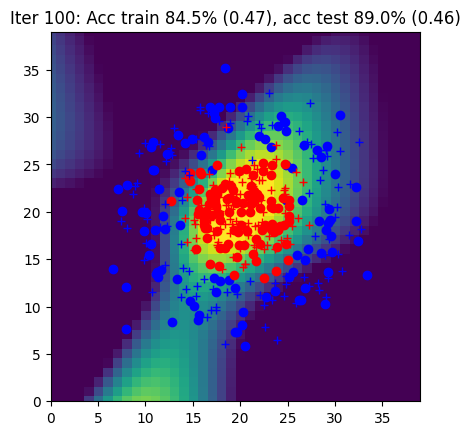

Iter 101: Acc train 85.0% (0.46), acc test 89.0% (0.46)


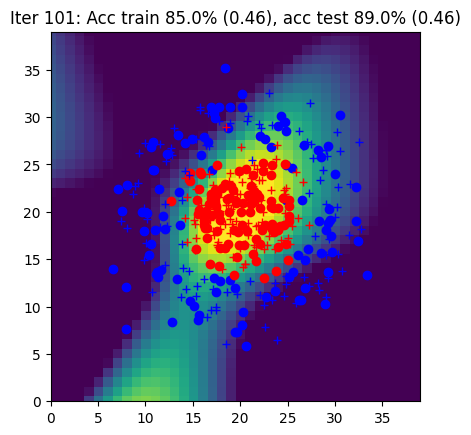

Iter 102: Acc train 85.0% (0.46), acc test 89.5% (0.45)


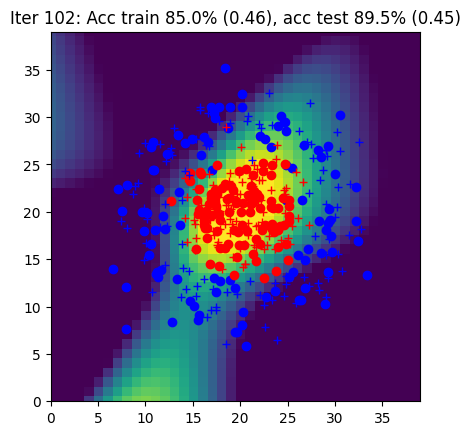

Iter 103: Acc train 87.0% (0.45), acc test 89.5% (0.45)


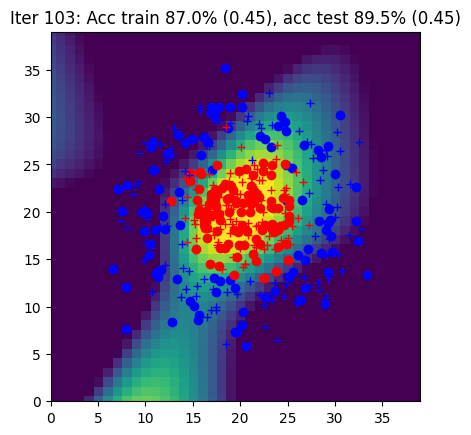

Iter 104: Acc train 87.0% (0.45), acc test 89.5% (0.44)


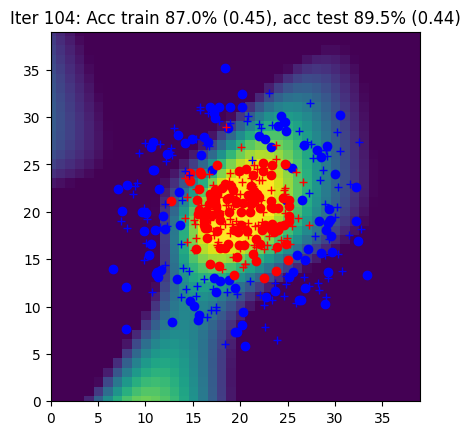

Iter 105: Acc train 86.5% (0.44), acc test 90.0% (0.44)


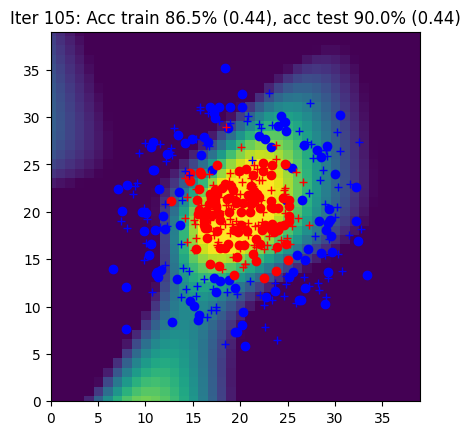

Iter 106: Acc train 87.0% (0.44), acc test 90.0% (0.43)


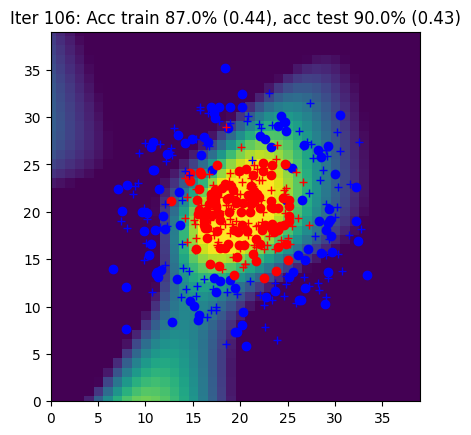

Iter 107: Acc train 87.0% (0.43), acc test 90.5% (0.43)


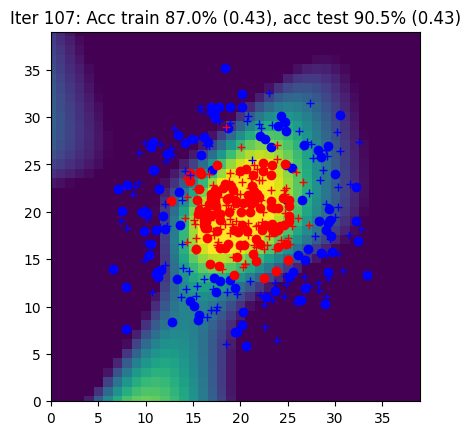

Iter 108: Acc train 87.0% (0.43), acc test 90.0% (0.42)


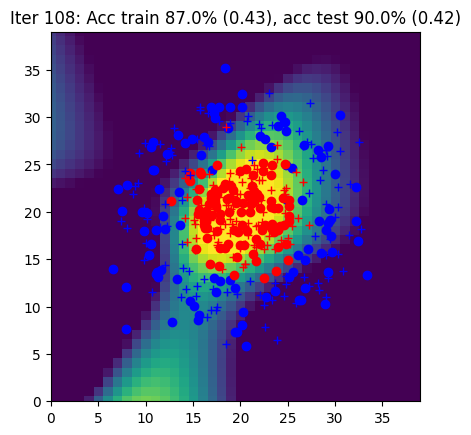

Iter 109: Acc train 87.5% (0.42), acc test 92.0% (0.42)


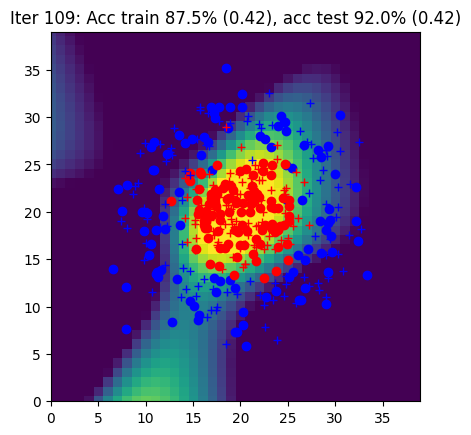

Iter 110: Acc train 87.5% (0.42), acc test 92.5% (0.41)


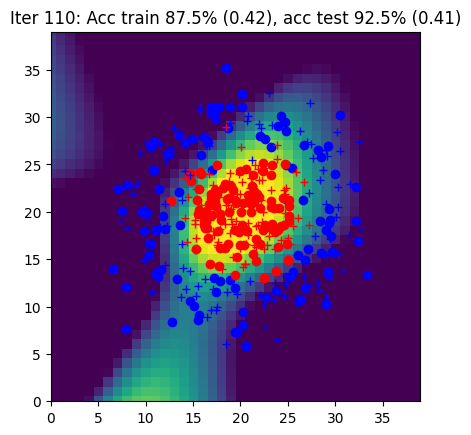

Iter 111: Acc train 88.0% (0.41), acc test 93.5% (0.41)


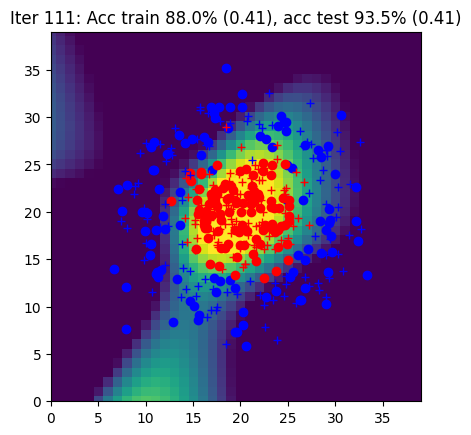

Iter 112: Acc train 88.0% (0.41), acc test 92.0% (0.40)


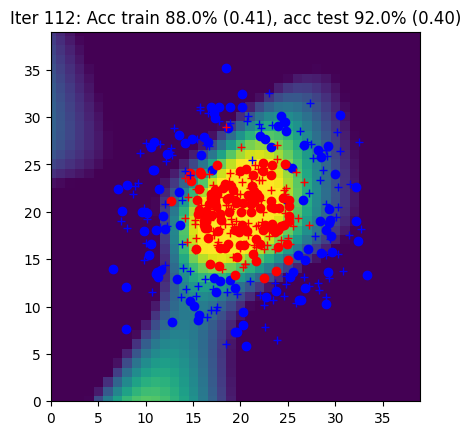

Iter 113: Acc train 88.0% (0.40), acc test 92.0% (0.40)


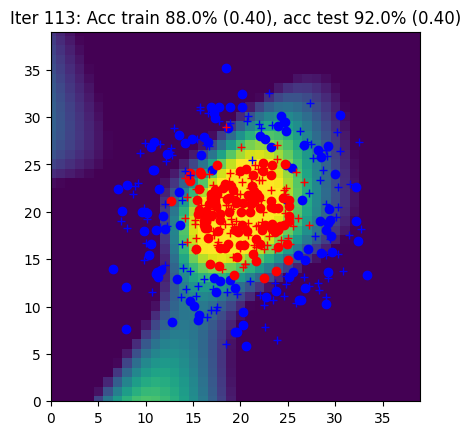

Iter 114: Acc train 89.5% (0.40), acc test 93.5% (0.39)


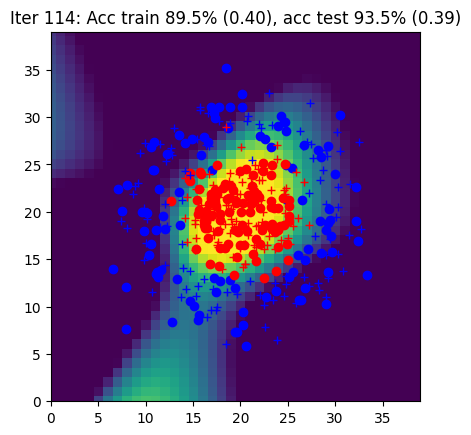

Iter 115: Acc train 89.5% (0.39), acc test 93.0% (0.39)


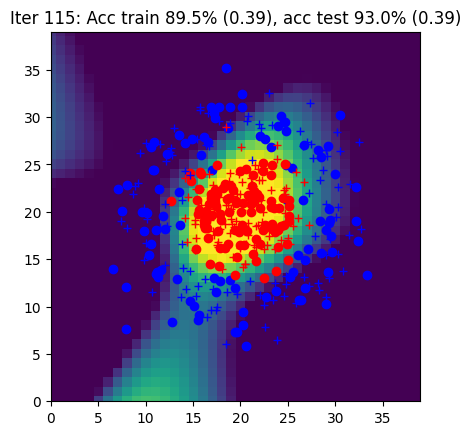

Iter 116: Acc train 89.5% (0.39), acc test 94.5% (0.38)


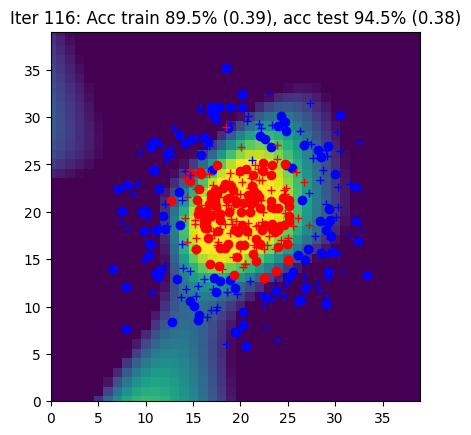

Iter 117: Acc train 89.5% (0.39), acc test 93.5% (0.38)


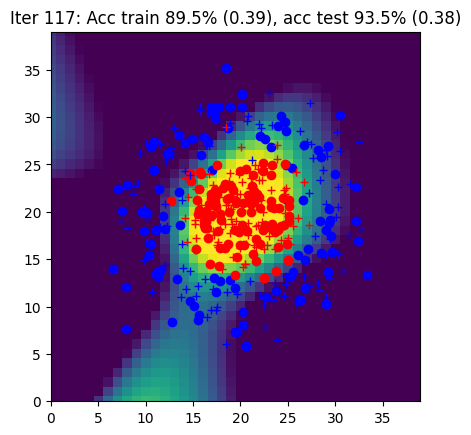

Iter 118: Acc train 89.5% (0.38), acc test 94.0% (0.37)


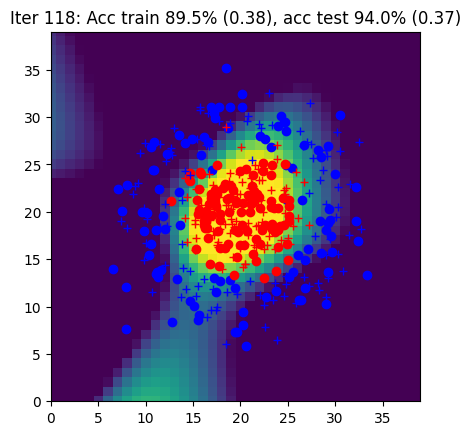

Iter 119: Acc train 90.0% (0.38), acc test 96.5% (0.37)


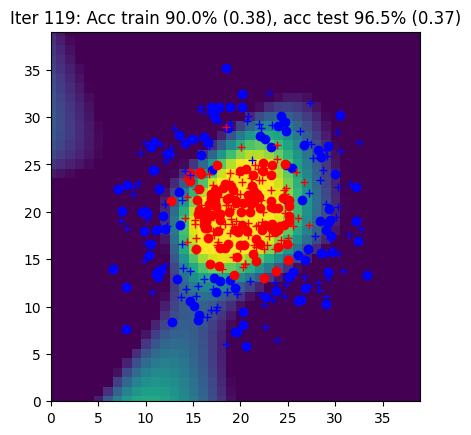

Iter 120: Acc train 90.5% (0.37), acc test 96.5% (0.37)


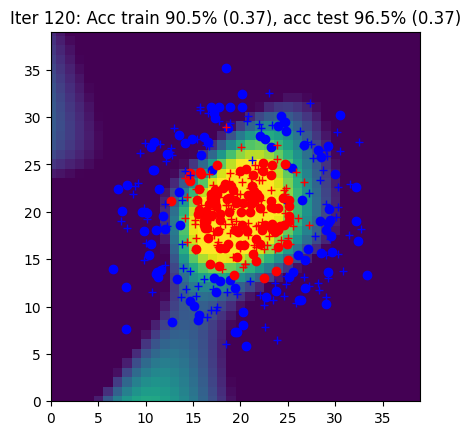

Iter 121: Acc train 91.0% (0.37), acc test 96.0% (0.36)


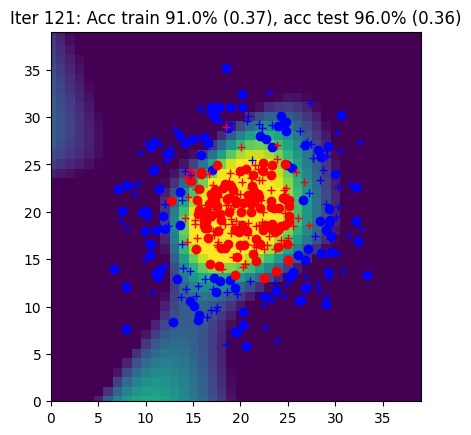

Iter 122: Acc train 90.5% (0.36), acc test 96.0% (0.36)


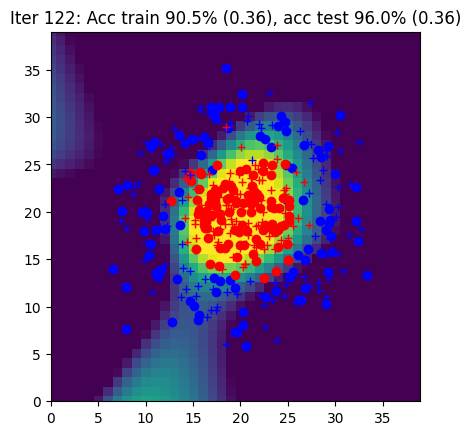

Iter 123: Acc train 90.0% (0.36), acc test 96.5% (0.35)


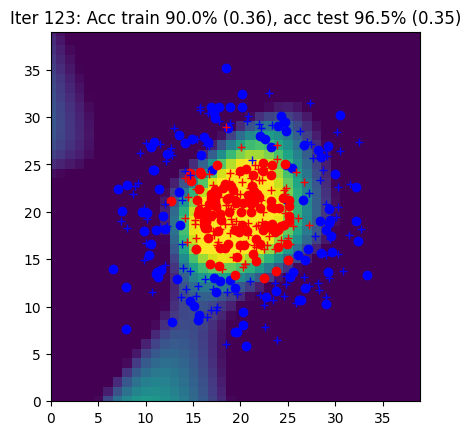

Iter 124: Acc train 91.0% (0.35), acc test 96.0% (0.35)


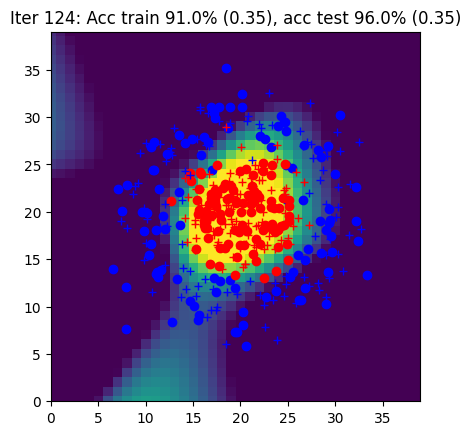

Iter 125: Acc train 91.0% (0.35), acc test 96.0% (0.34)


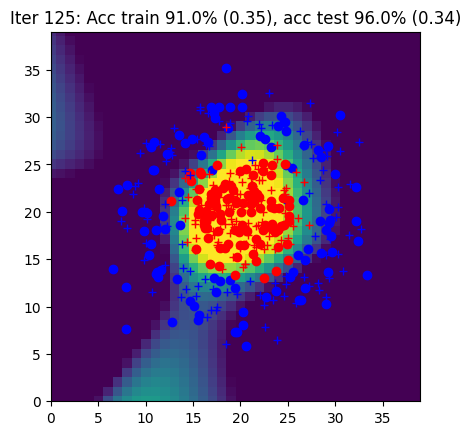

Iter 126: Acc train 91.0% (0.34), acc test 95.5% (0.34)


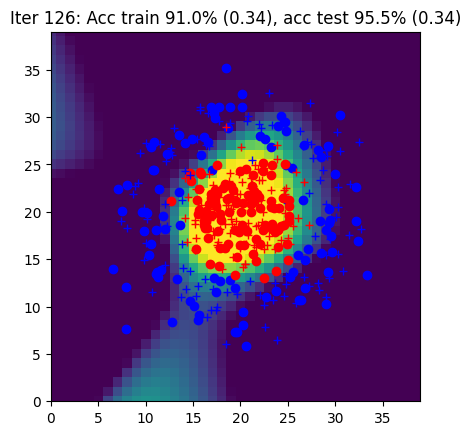

Iter 127: Acc train 91.0% (0.34), acc test 95.5% (0.34)


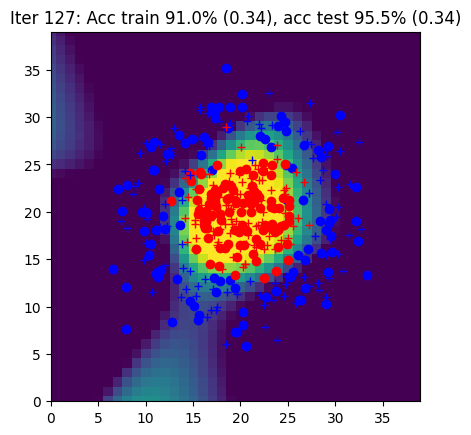

Iter 128: Acc train 91.0% (0.34), acc test 96.0% (0.33)


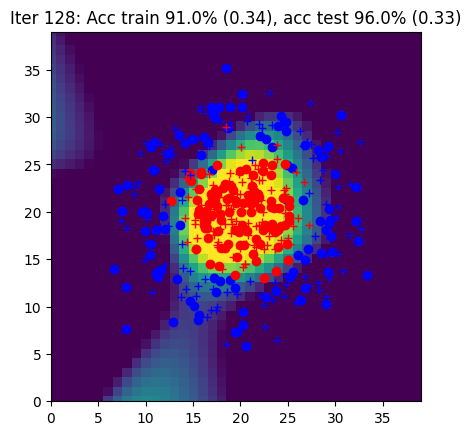

Iter 129: Acc train 91.0% (0.33), acc test 96.0% (0.33)


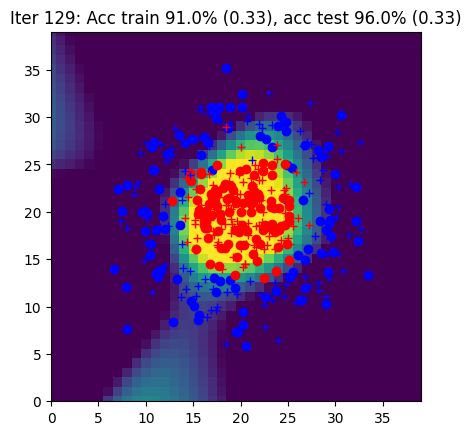

Iter 130: Acc train 91.0% (0.33), acc test 96.0% (0.32)


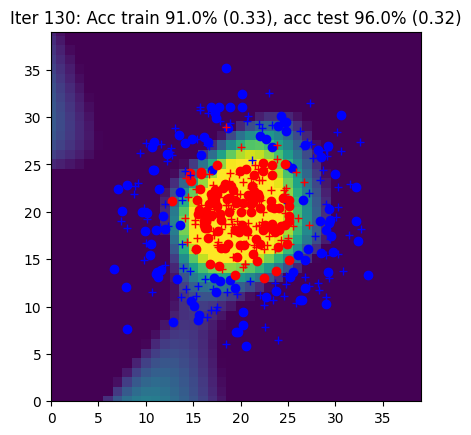

Iter 131: Acc train 91.0% (0.32), acc test 96.5% (0.32)


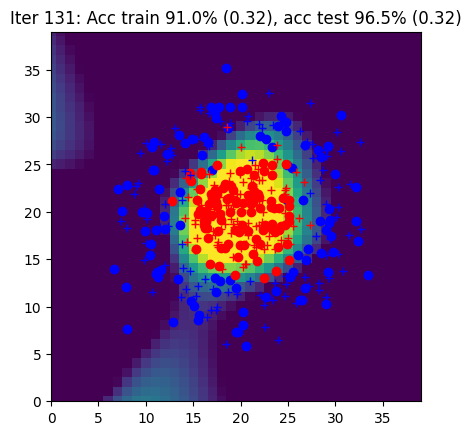

Iter 132: Acc train 91.5% (0.32), acc test 96.0% (0.32)


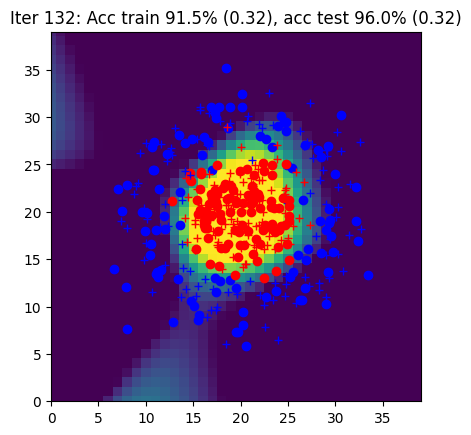

Iter 133: Acc train 91.5% (0.32), acc test 96.0% (0.31)


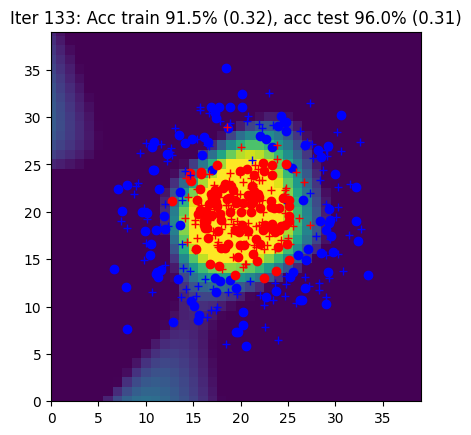

Iter 134: Acc train 92.5% (0.31), acc test 96.0% (0.31)


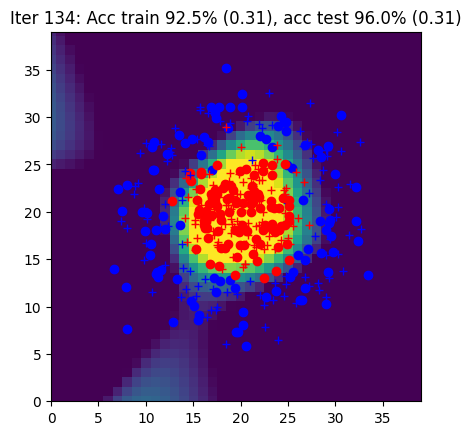

Iter 135: Acc train 92.0% (0.31), acc test 96.0% (0.31)


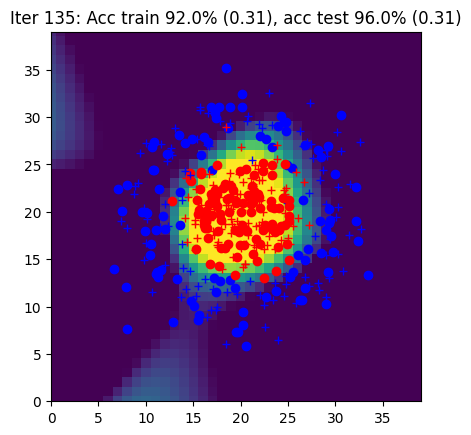

Iter 136: Acc train 93.5% (0.31), acc test 96.0% (0.30)


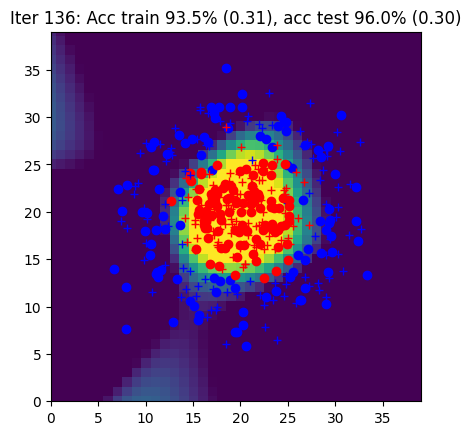

Iter 137: Acc train 94.0% (0.30), acc test 96.0% (0.30)


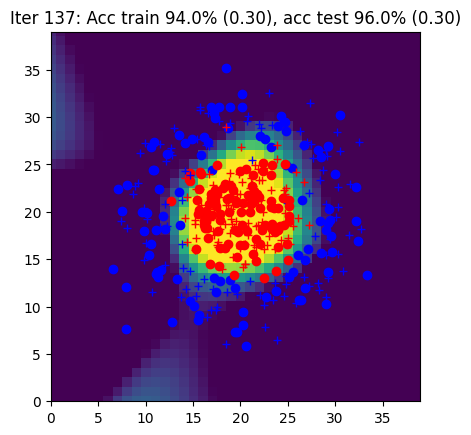

Iter 138: Acc train 94.0% (0.30), acc test 95.5% (0.30)


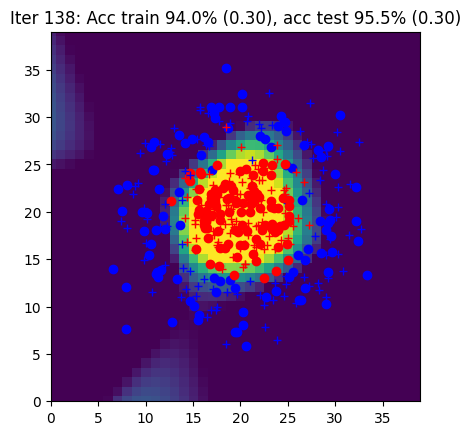

Iter 139: Acc train 94.5% (0.29), acc test 95.5% (0.29)


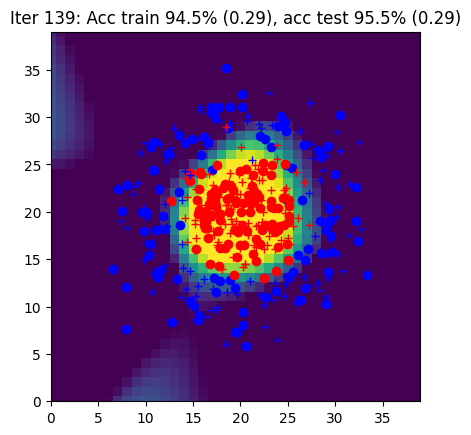

Iter 140: Acc train 95.5% (0.29), acc test 95.5% (0.29)


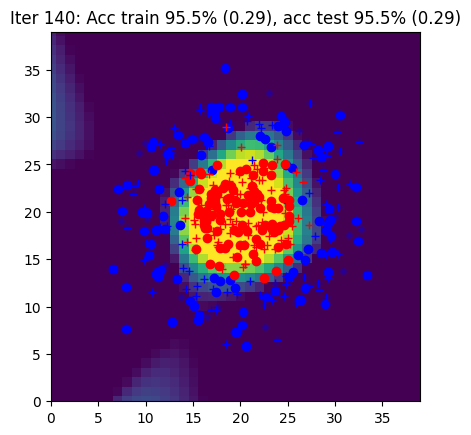

Iter 141: Acc train 95.5% (0.29), acc test 95.5% (0.29)


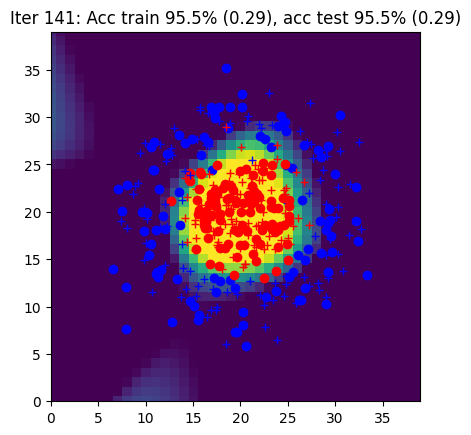

Iter 142: Acc train 95.0% (0.29), acc test 95.5% (0.28)


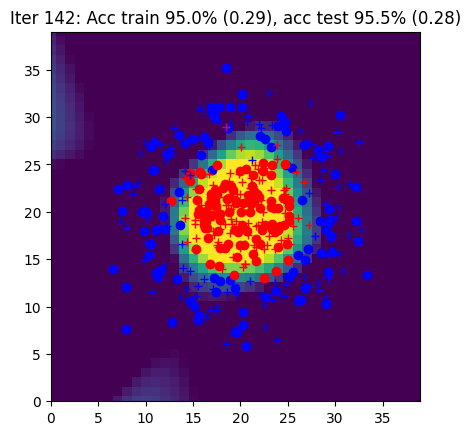

Iter 143: Acc train 95.5% (0.28), acc test 95.5% (0.28)


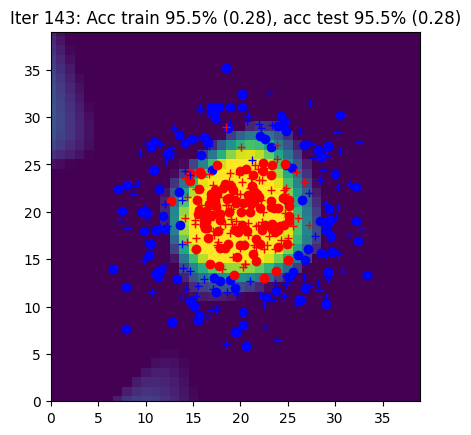

Iter 144: Acc train 95.5% (0.28), acc test 95.5% (0.28)


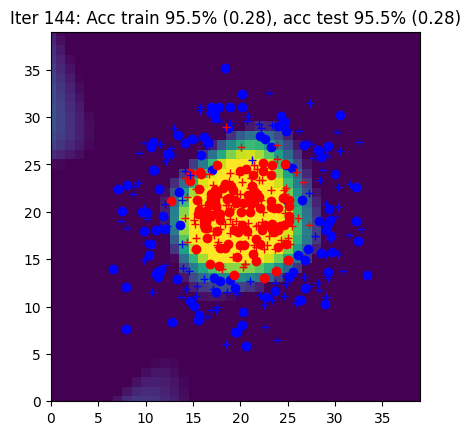

Iter 145: Acc train 95.5% (0.28), acc test 95.5% (0.27)


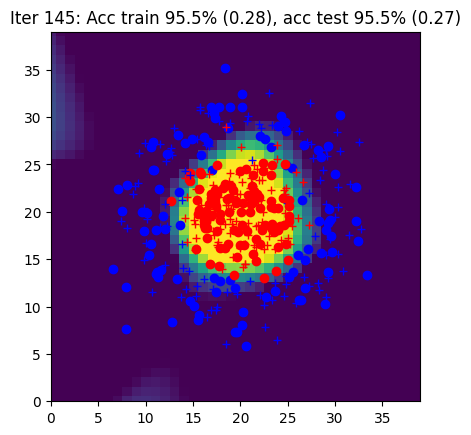

Iter 146: Acc train 95.5% (0.27), acc test 95.5% (0.27)


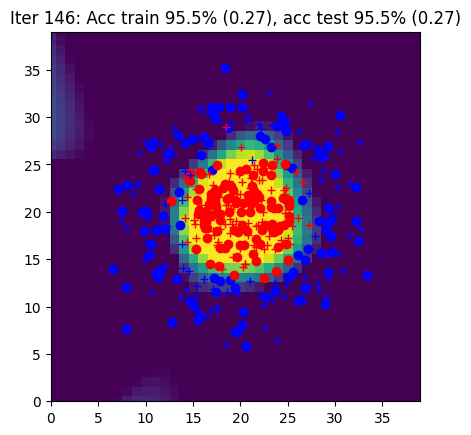

Iter 147: Acc train 95.5% (0.27), acc test 95.5% (0.27)


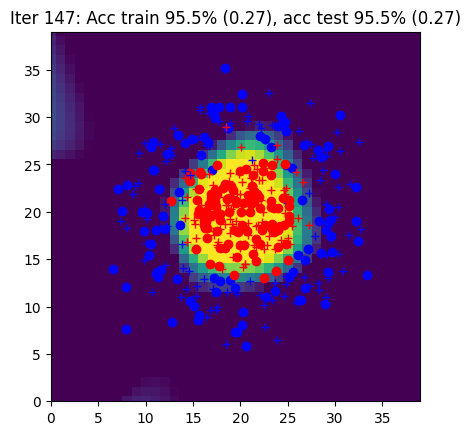

Iter 148: Acc train 95.5% (0.27), acc test 95.5% (0.27)


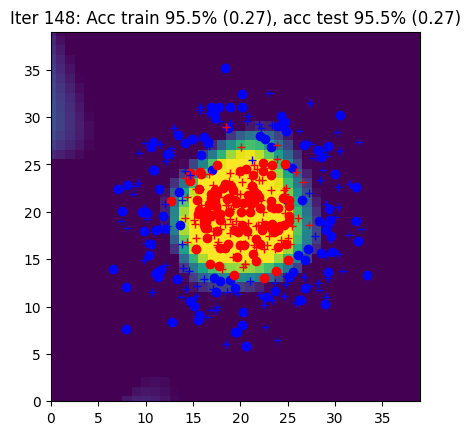

Iter 149: Acc train 95.5% (0.26), acc test 95.5% (0.26)


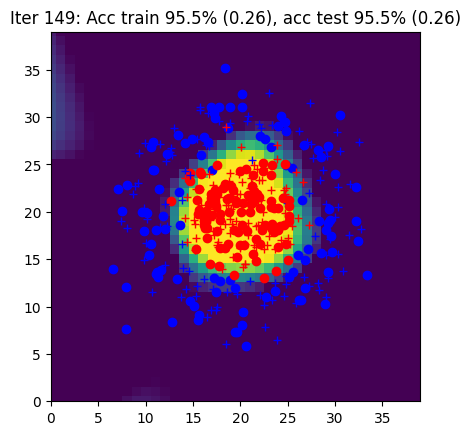

Iter 150: Acc train 95.5% (0.26), acc test 95.5% (0.26)


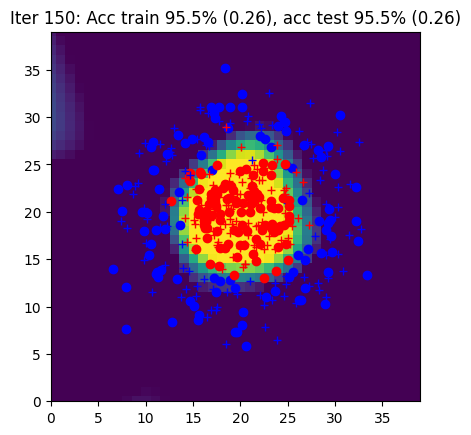

Iter 151: Acc train 96.0% (0.26), acc test 95.5% (0.26)


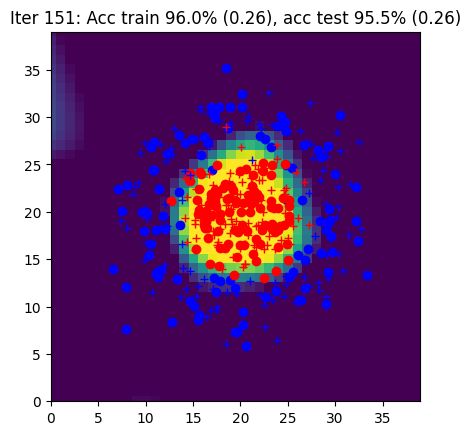

Iter 152: Acc train 96.0% (0.26), acc test 95.5% (0.26)


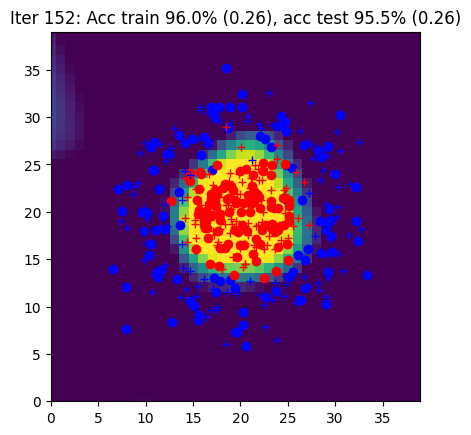

Iter 153: Acc train 96.0% (0.25), acc test 95.5% (0.26)


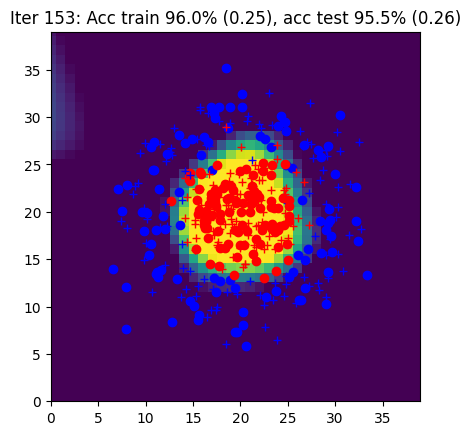

Iter 154: Acc train 96.0% (0.25), acc test 95.5% (0.25)


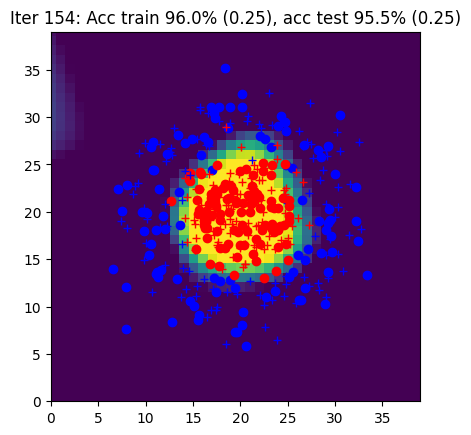

Iter 155: Acc train 96.0% (0.25), acc test 95.5% (0.25)


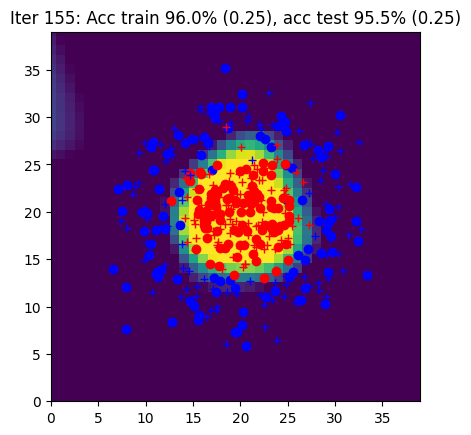

Iter 156: Acc train 96.0% (0.25), acc test 95.5% (0.25)


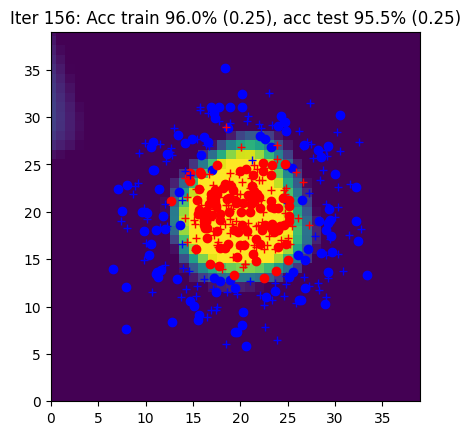

Iter 157: Acc train 96.5% (0.25), acc test 95.5% (0.25)


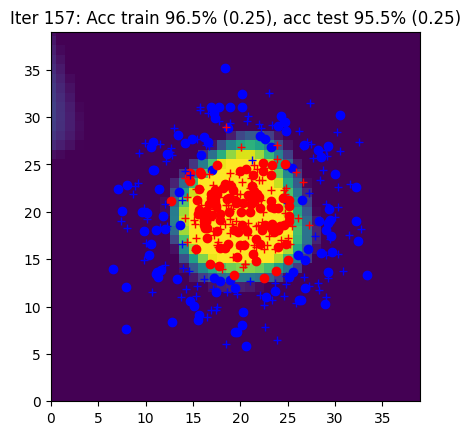

Iter 158: Acc train 96.0% (0.24), acc test 95.5% (0.25)


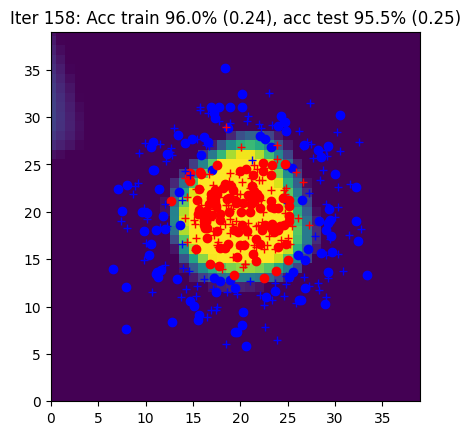

Iter 159: Acc train 96.0% (0.24), acc test 95.5% (0.24)


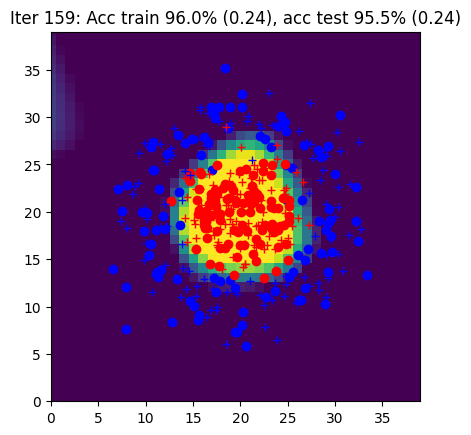

Iter 160: Acc train 96.0% (0.24), acc test 95.5% (0.24)


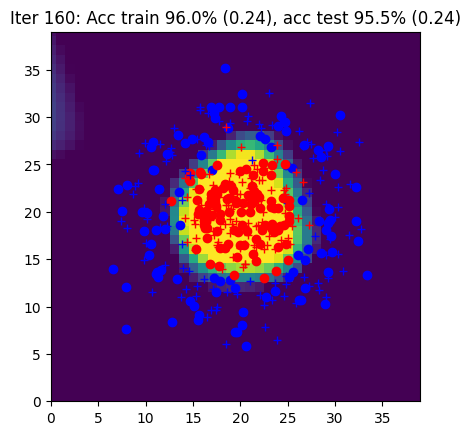

Iter 161: Acc train 96.0% (0.24), acc test 95.5% (0.24)


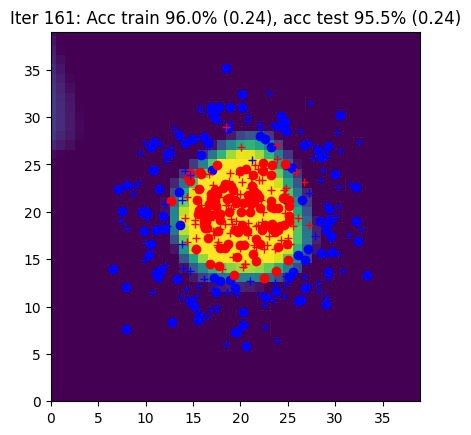

Iter 162: Acc train 96.0% (0.24), acc test 95.5% (0.24)


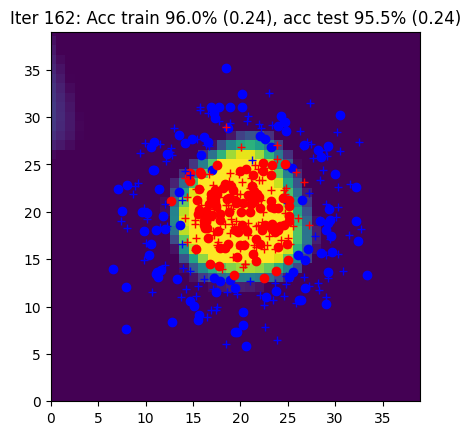

Iter 163: Acc train 96.0% (0.23), acc test 95.5% (0.24)


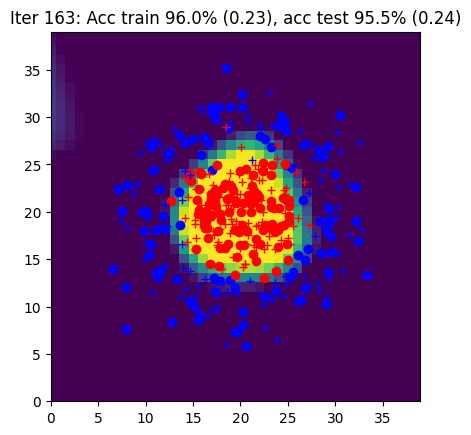

Iter 164: Acc train 96.0% (0.23), acc test 95.5% (0.24)


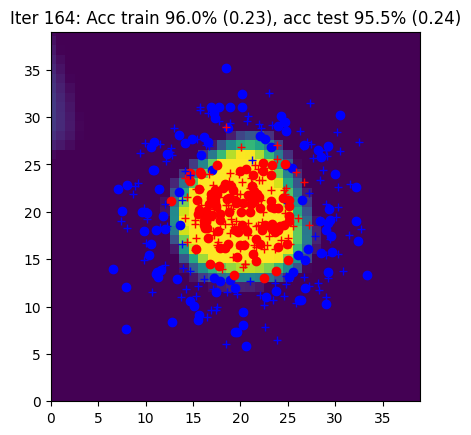

Iter 165: Acc train 96.0% (0.23), acc test 95.5% (0.23)


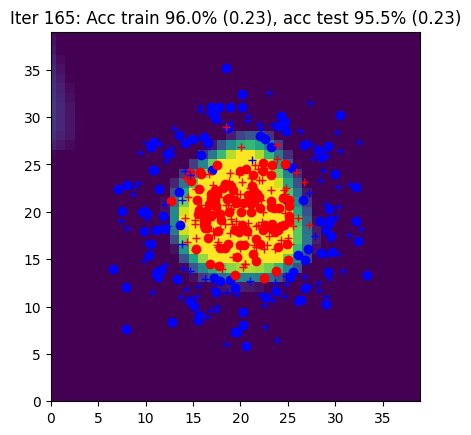

Iter 166: Acc train 96.0% (0.23), acc test 95.5% (0.23)


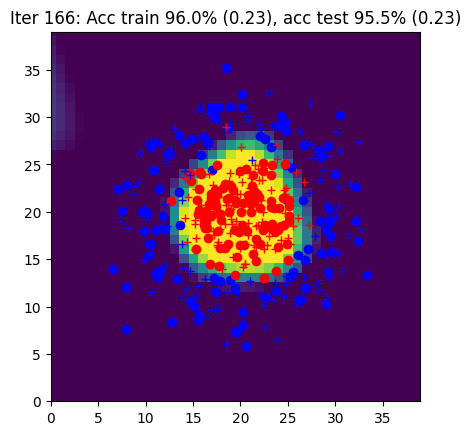

Iter 167: Acc train 96.0% (0.23), acc test 95.5% (0.23)


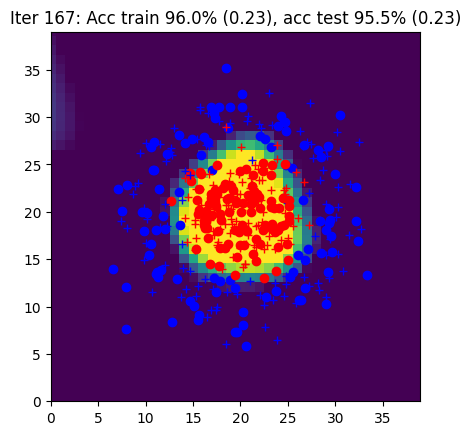

Iter 168: Acc train 96.0% (0.23), acc test 95.5% (0.23)


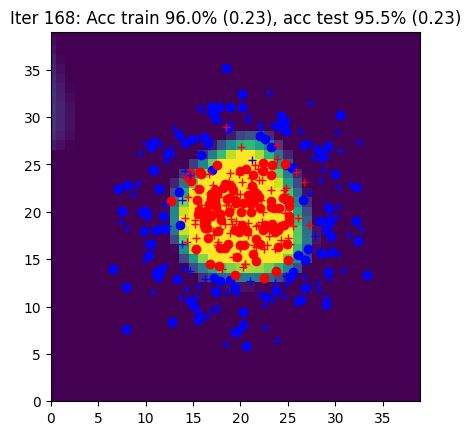

Iter 169: Acc train 95.5% (0.22), acc test 95.0% (0.23)


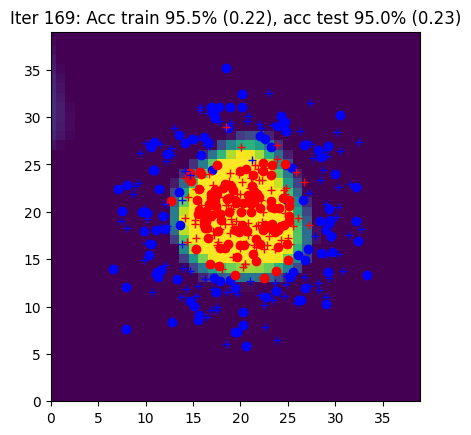

Iter 170: Acc train 96.0% (0.22), acc test 95.5% (0.23)


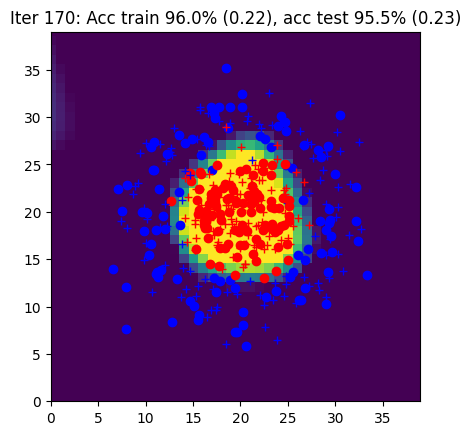

Iter 171: Acc train 95.5% (0.22), acc test 95.5% (0.22)


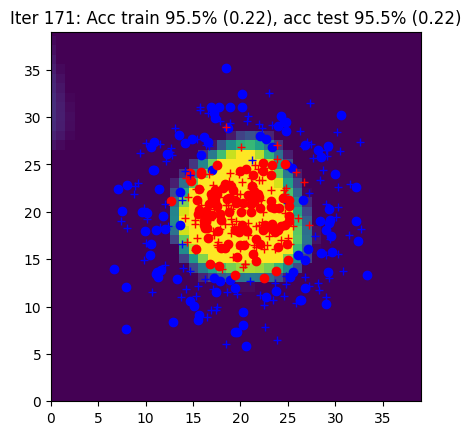

Iter 172: Acc train 95.5% (0.22), acc test 95.0% (0.22)


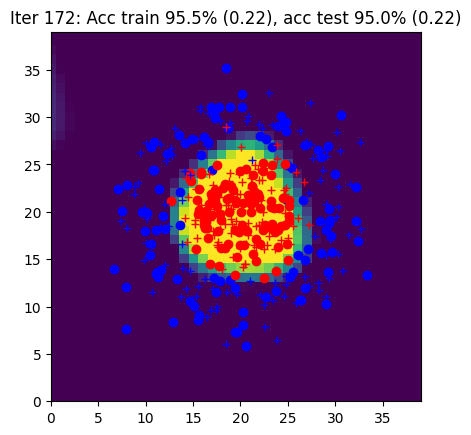

Iter 173: Acc train 95.5% (0.22), acc test 95.0% (0.22)


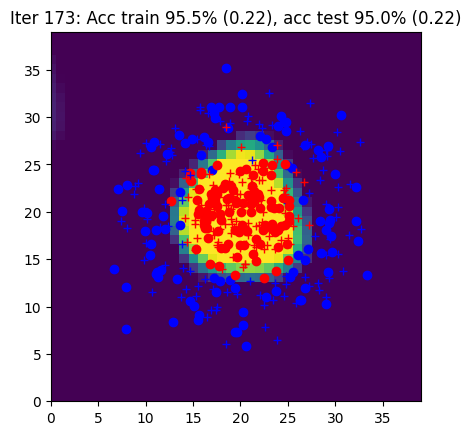

Iter 174: Acc train 95.5% (0.22), acc test 95.0% (0.22)


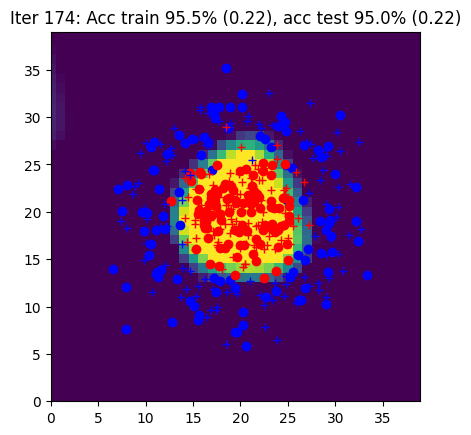

Iter 175: Acc train 96.0% (0.21), acc test 95.0% (0.22)


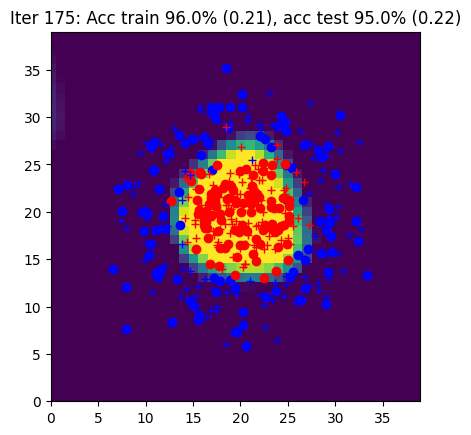

Iter 176: Acc train 95.5% (0.21), acc test 95.0% (0.22)


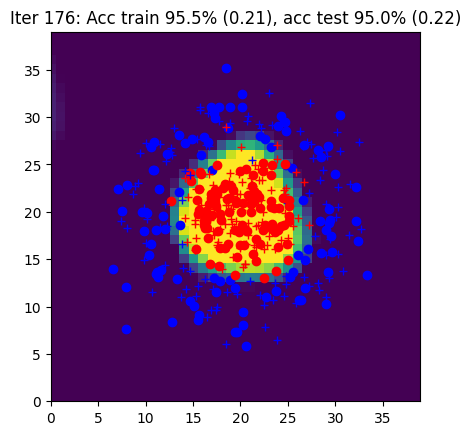

Iter 177: Acc train 95.5% (0.21), acc test 95.0% (0.22)


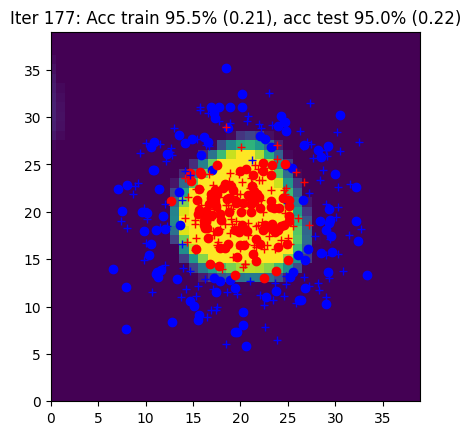

Iter 178: Acc train 95.5% (0.21), acc test 95.0% (0.22)


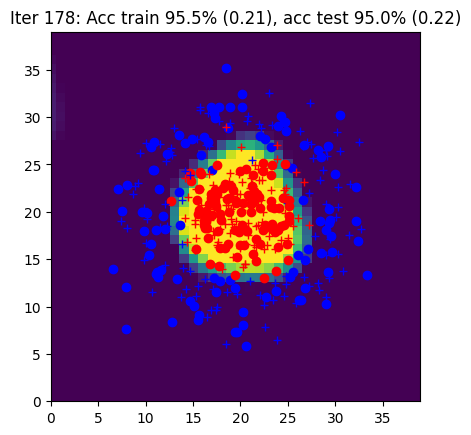

Iter 179: Acc train 95.5% (0.21), acc test 95.0% (0.22)


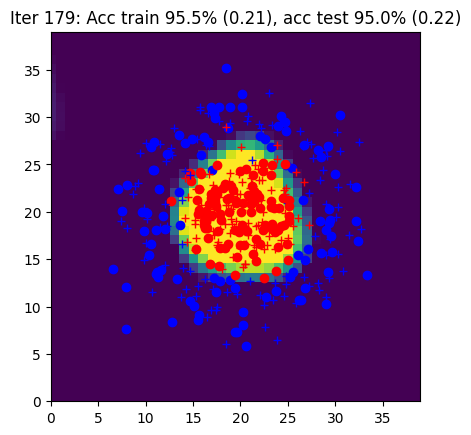

Iter 180: Acc train 95.5% (0.21), acc test 95.0% (0.21)


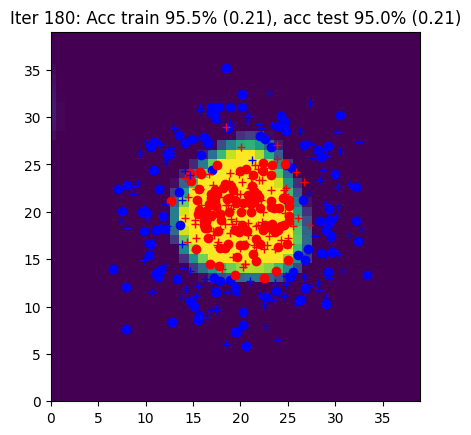

Iter 181: Acc train 95.5% (0.21), acc test 95.0% (0.21)


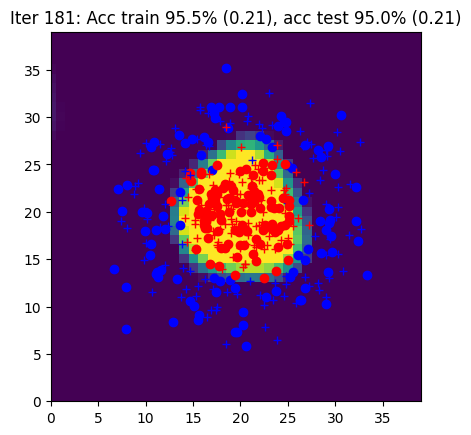

Iter 182: Acc train 96.0% (0.21), acc test 95.0% (0.21)


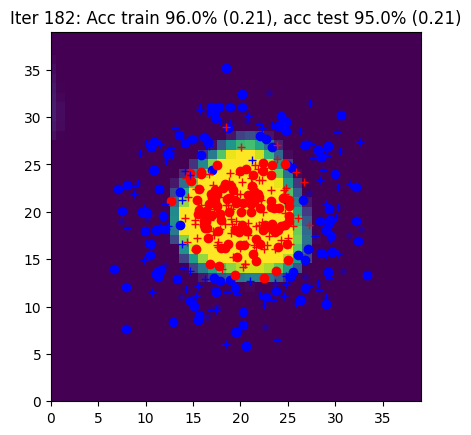

Iter 183: Acc train 95.5% (0.20), acc test 95.0% (0.21)


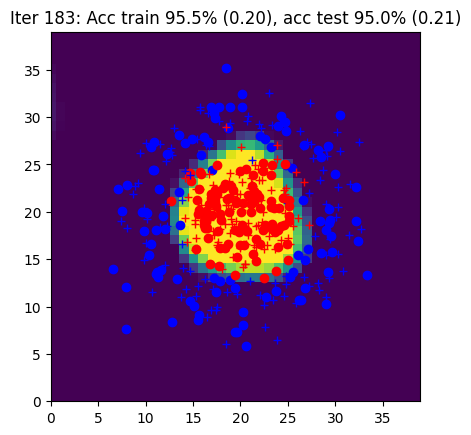

Iter 184: Acc train 96.0% (0.20), acc test 95.0% (0.21)


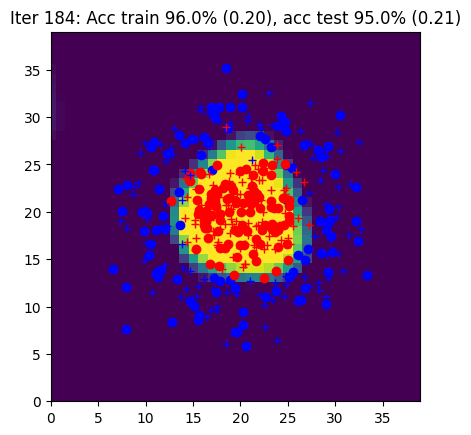

Iter 185: Acc train 95.5% (0.20), acc test 95.0% (0.21)


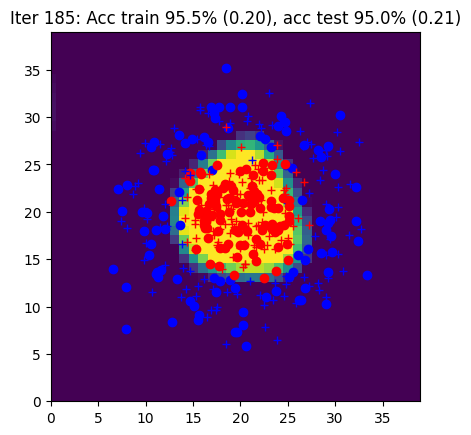

Iter 186: Acc train 95.5% (0.20), acc test 95.0% (0.21)


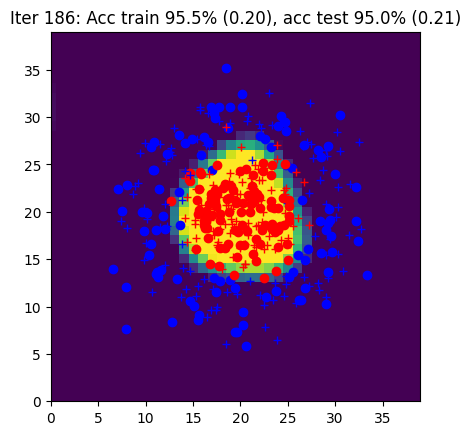

Iter 187: Acc train 95.5% (0.20), acc test 95.0% (0.21)


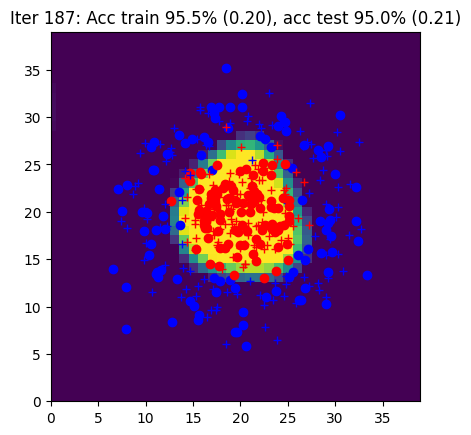

Iter 188: Acc train 95.5% (0.20), acc test 95.0% (0.21)


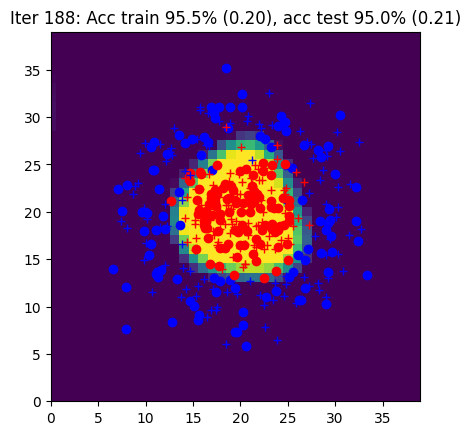

Iter 189: Acc train 95.5% (0.20), acc test 95.0% (0.21)


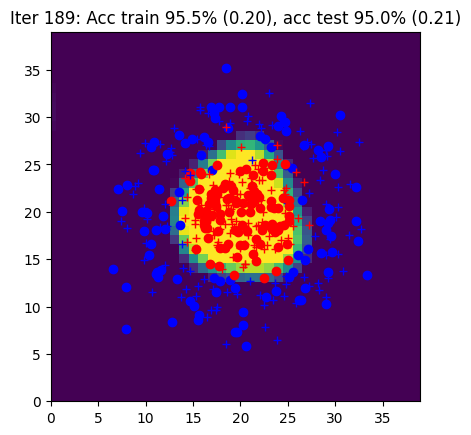

Iter 190: Acc train 95.5% (0.20), acc test 95.0% (0.21)


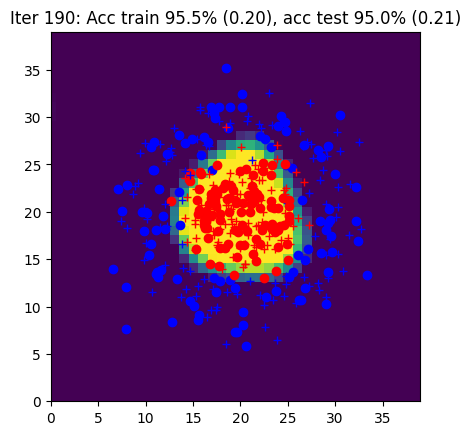

Iter 191: Acc train 95.5% (0.20), acc test 95.0% (0.20)


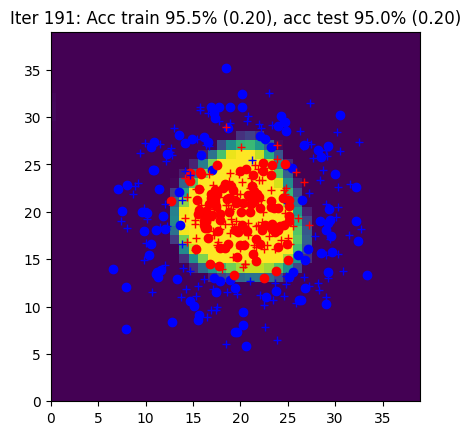

Iter 192: Acc train 95.5% (0.19), acc test 95.0% (0.20)


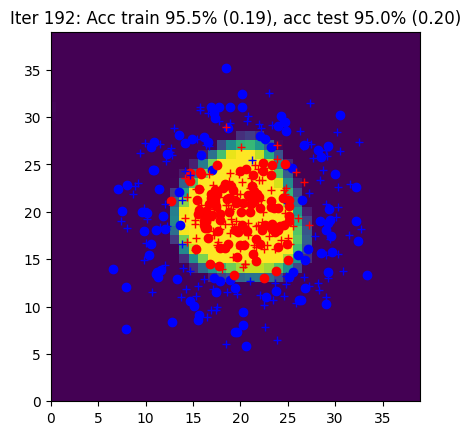

Iter 193: Acc train 95.5% (0.19), acc test 95.0% (0.20)


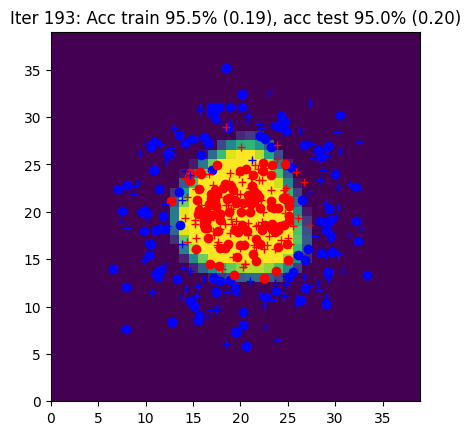

Iter 194: Acc train 95.5% (0.19), acc test 95.0% (0.20)


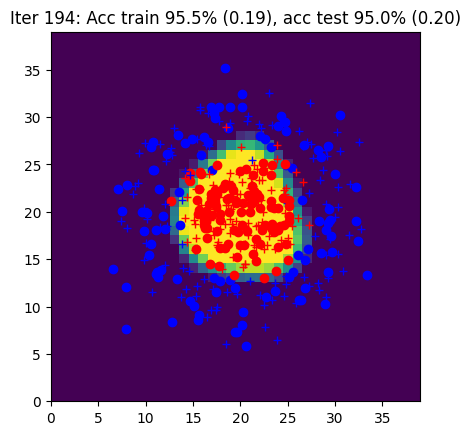

Iter 195: Acc train 95.5% (0.19), acc test 95.0% (0.20)


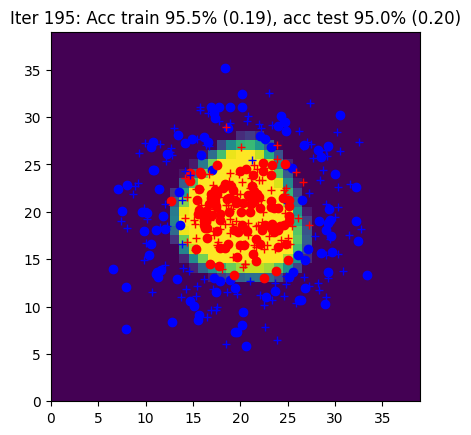

Iter 196: Acc train 95.5% (0.19), acc test 95.0% (0.20)


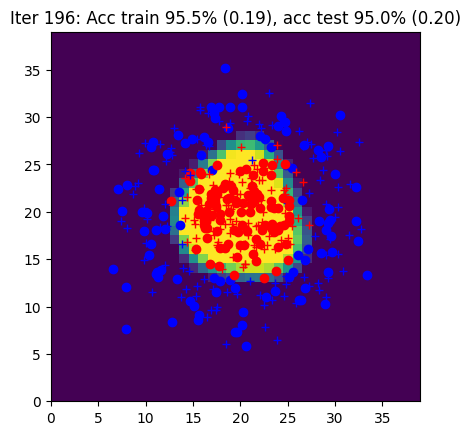

Iter 197: Acc train 95.5% (0.19), acc test 95.0% (0.20)


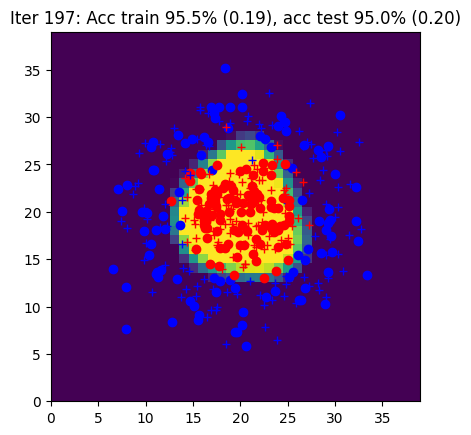

Iter 198: Acc train 95.5% (0.19), acc test 95.0% (0.20)


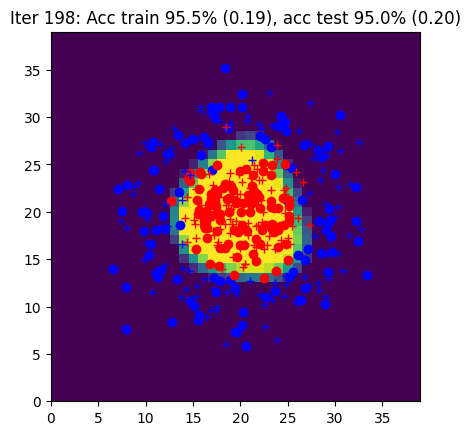

Iter 199: Acc train 95.5% (0.19), acc test 95.0% (0.20)


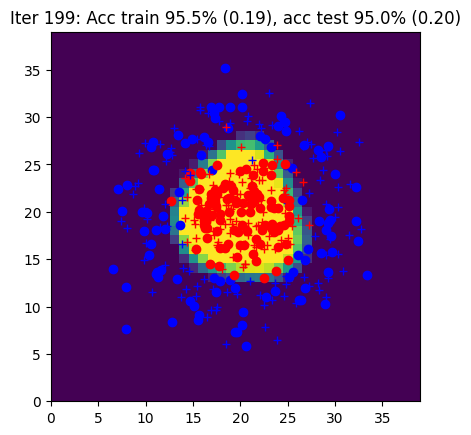

Iter 200: Acc train 95.5% (0.19), acc test 95.0% (0.20)


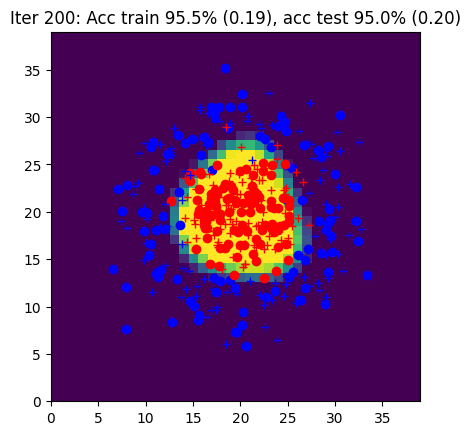

Iter 201: Acc train 95.5% (0.19), acc test 95.0% (0.20)


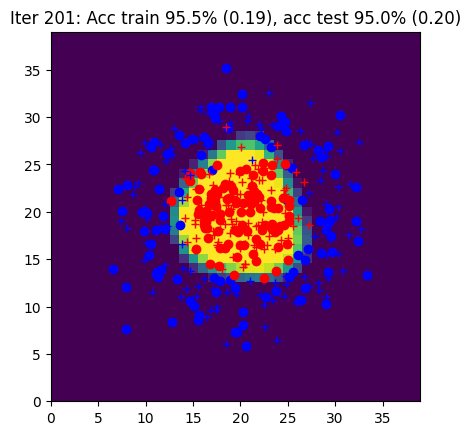

Iter 202: Acc train 95.5% (0.19), acc test 95.0% (0.20)


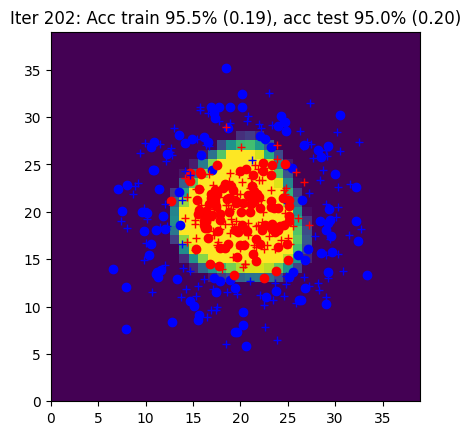

Iter 203: Acc train 95.5% (0.19), acc test 94.5% (0.20)


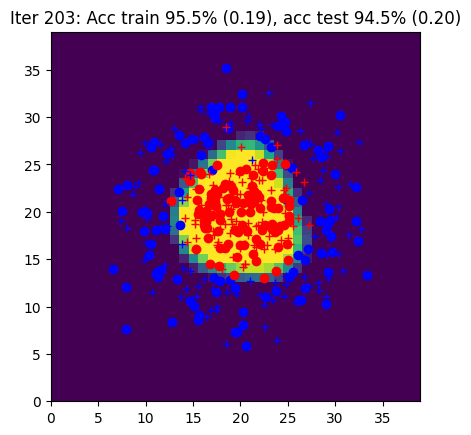

Iter 204: Acc train 95.5% (0.18), acc test 95.0% (0.19)


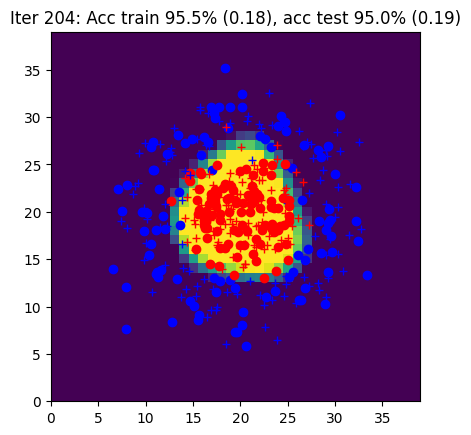

Iter 205: Acc train 95.5% (0.18), acc test 95.0% (0.19)


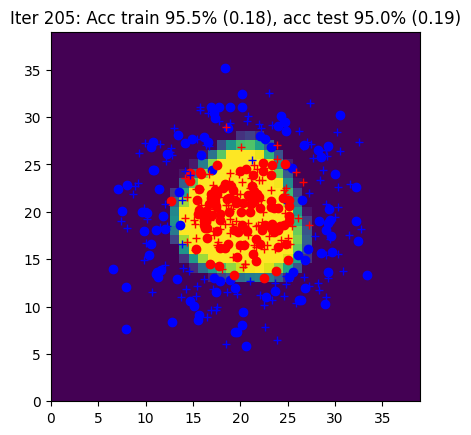

Iter 206: Acc train 95.5% (0.18), acc test 95.0% (0.19)


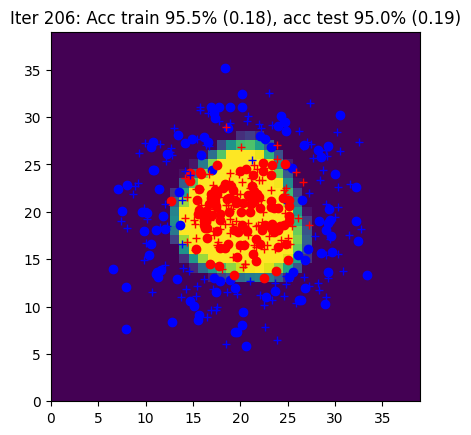

Iter 207: Acc train 95.5% (0.18), acc test 95.0% (0.19)


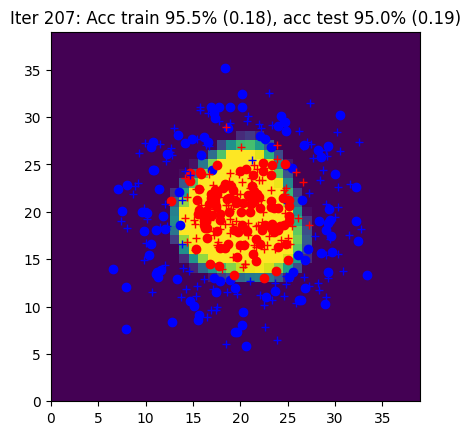

Iter 208: Acc train 95.5% (0.18), acc test 95.0% (0.19)


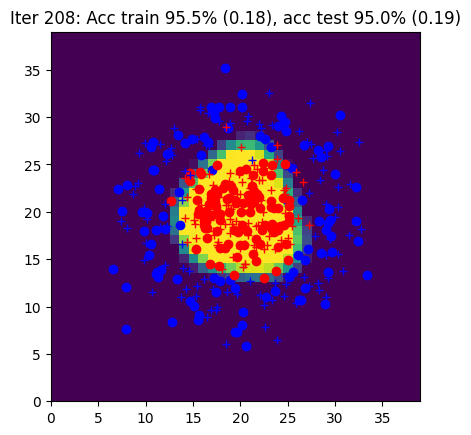

Iter 209: Acc train 95.5% (0.18), acc test 95.0% (0.19)


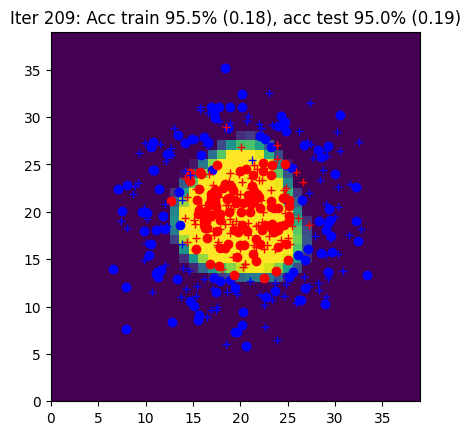

Iter 210: Acc train 95.5% (0.18), acc test 95.0% (0.19)


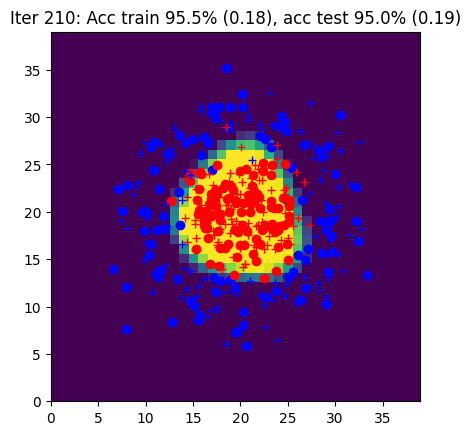

Iter 211: Acc train 95.5% (0.18), acc test 95.0% (0.19)


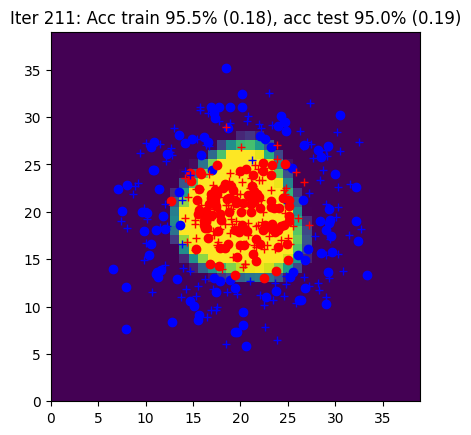

Iter 212: Acc train 95.0% (0.18), acc test 94.5% (0.19)


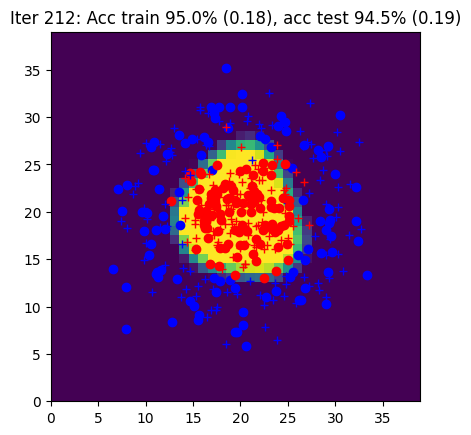

Iter 213: Acc train 95.0% (0.18), acc test 94.5% (0.19)


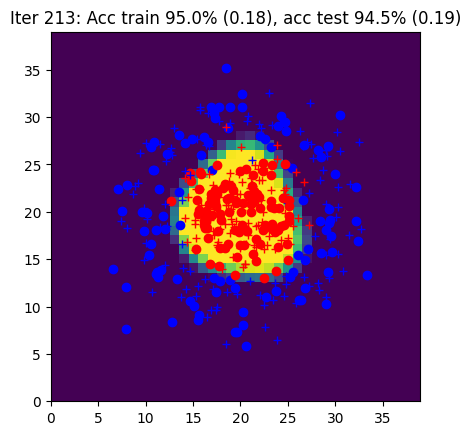

Iter 214: Acc train 95.5% (0.18), acc test 95.0% (0.19)


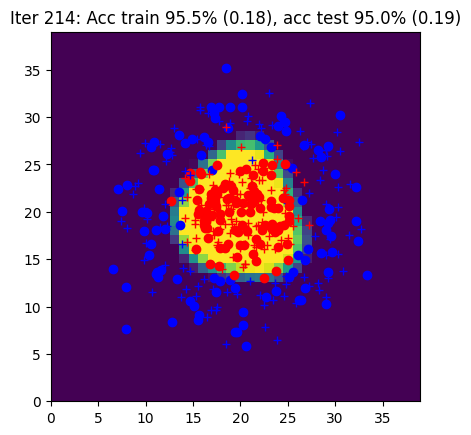

Iter 215: Acc train 95.5% (0.18), acc test 95.0% (0.19)


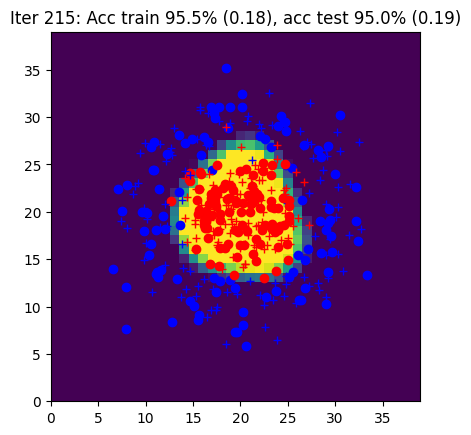

Iter 216: Acc train 95.5% (0.18), acc test 95.0% (0.19)


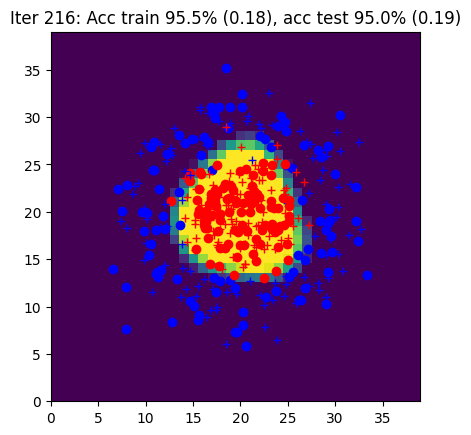

Iter 217: Acc train 95.5% (0.17), acc test 95.0% (0.19)


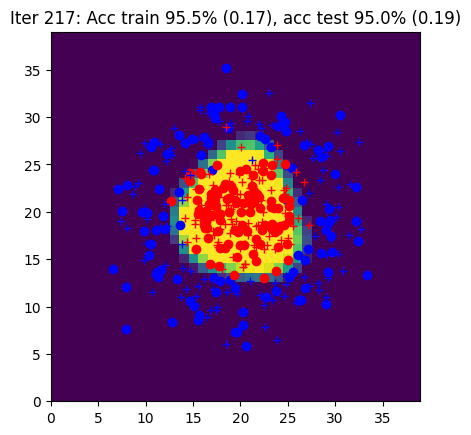

Iter 218: Acc train 95.5% (0.17), acc test 95.0% (0.19)


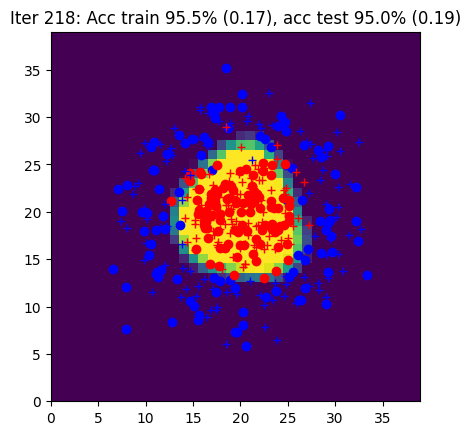

Iter 219: Acc train 95.5% (0.17), acc test 95.0% (0.19)


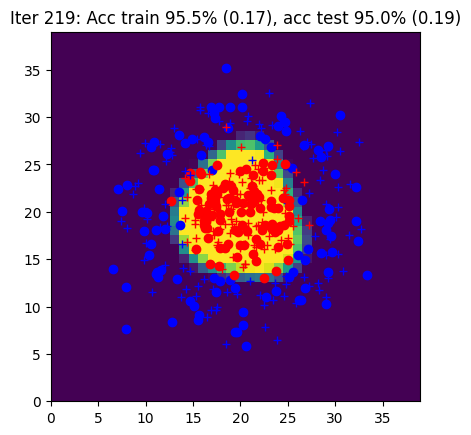

Iter 220: Acc train 95.0% (0.17), acc test 95.0% (0.18)


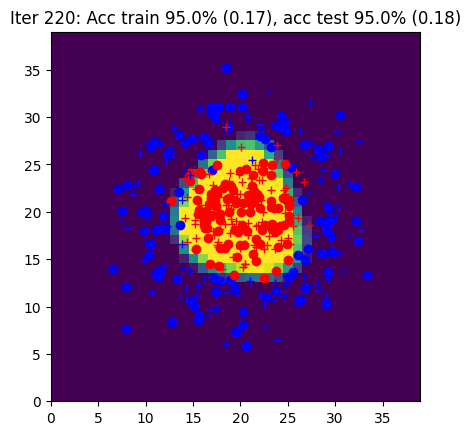

Iter 221: Acc train 95.5% (0.17), acc test 95.0% (0.18)


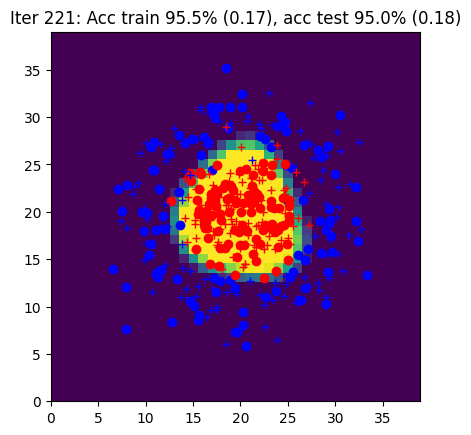

Iter 222: Acc train 95.0% (0.17), acc test 94.5% (0.18)


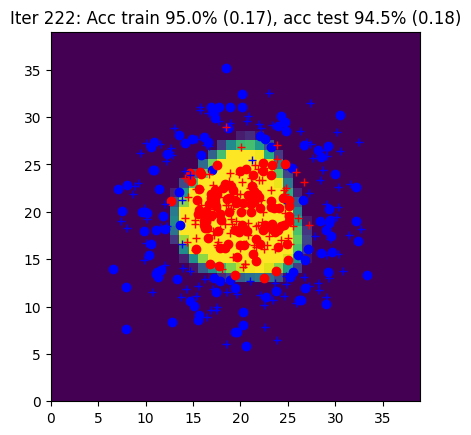

Iter 223: Acc train 95.0% (0.17), acc test 94.5% (0.18)


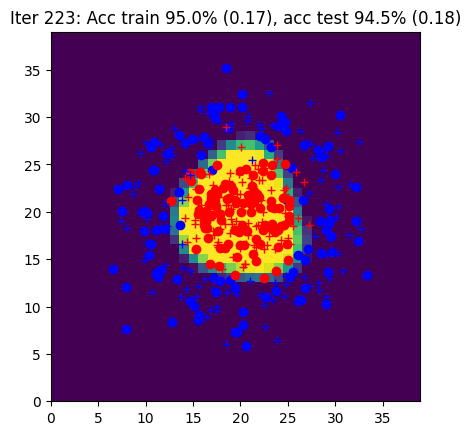

Iter 224: Acc train 95.5% (0.17), acc test 95.0% (0.18)


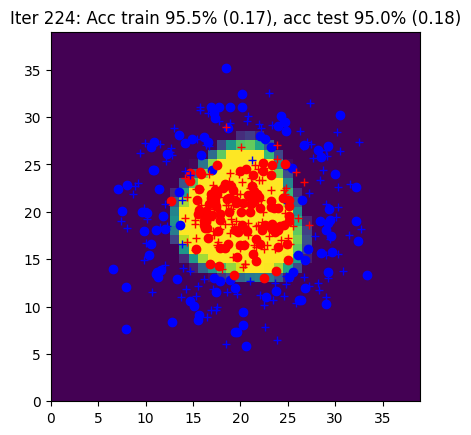

Iter 225: Acc train 95.0% (0.17), acc test 95.0% (0.18)


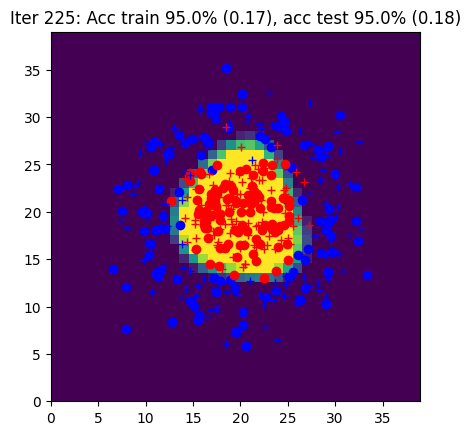

Iter 226: Acc train 95.0% (0.17), acc test 94.5% (0.18)


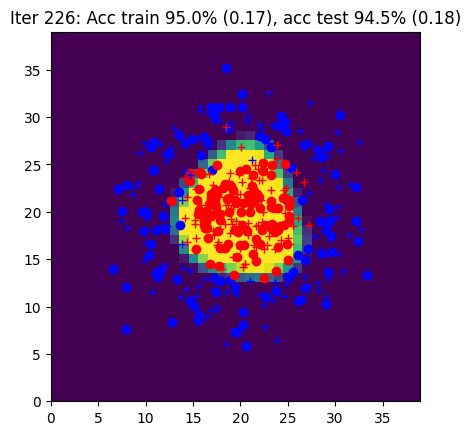

Iter 227: Acc train 95.5% (0.17), acc test 95.0% (0.18)


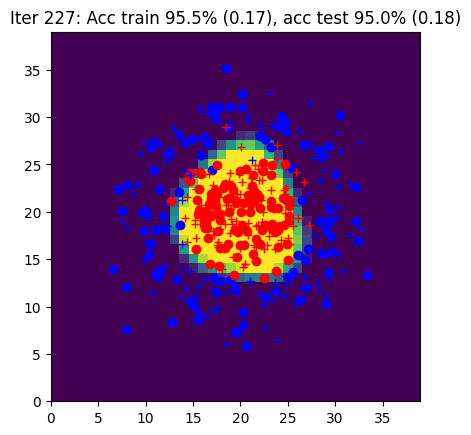

Iter 228: Acc train 96.0% (0.17), acc test 95.0% (0.18)


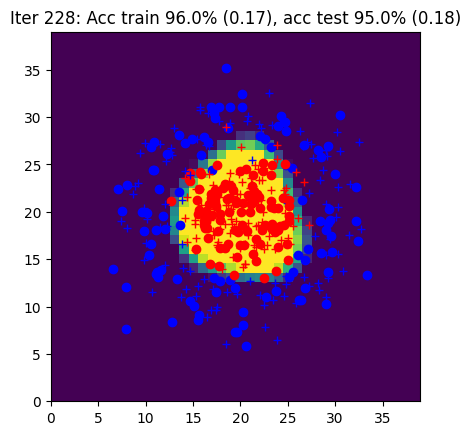

Iter 229: Acc train 95.5% (0.17), acc test 95.0% (0.18)


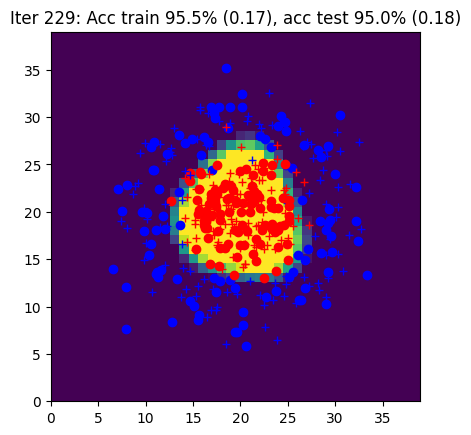

Iter 230: Acc train 95.5% (0.17), acc test 95.0% (0.18)


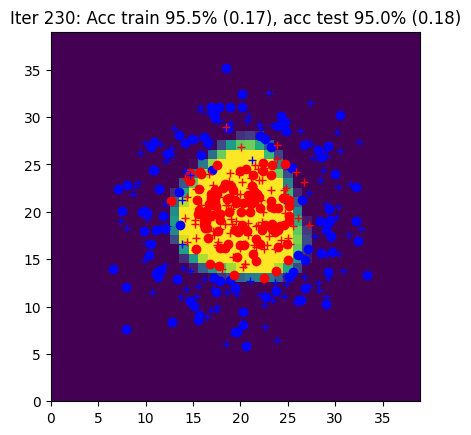

Iter 231: Acc train 96.0% (0.17), acc test 95.0% (0.18)


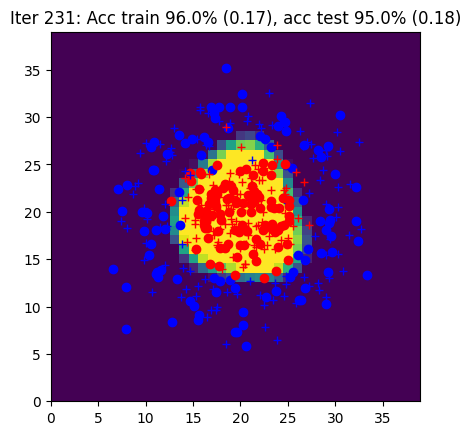

Iter 232: Acc train 95.5% (0.17), acc test 95.0% (0.18)


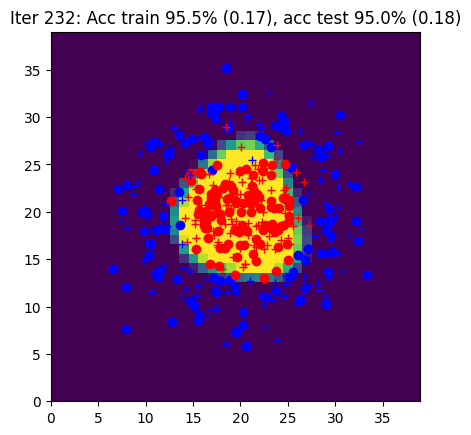

Iter 233: Acc train 95.0% (0.17), acc test 94.5% (0.18)


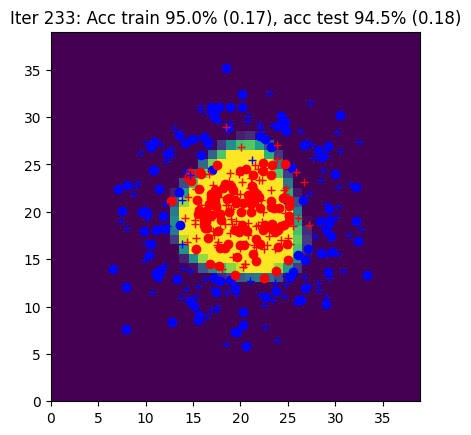

Iter 234: Acc train 95.5% (0.17), acc test 94.5% (0.18)


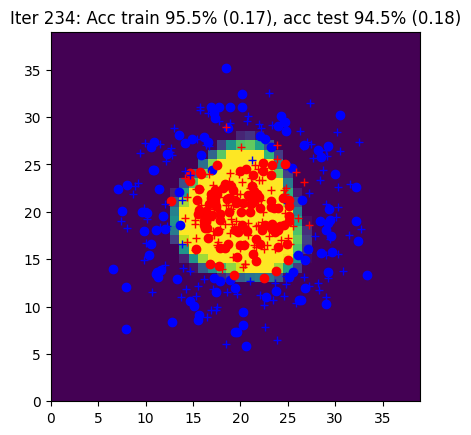

Iter 235: Acc train 95.0% (0.16), acc test 94.5% (0.18)


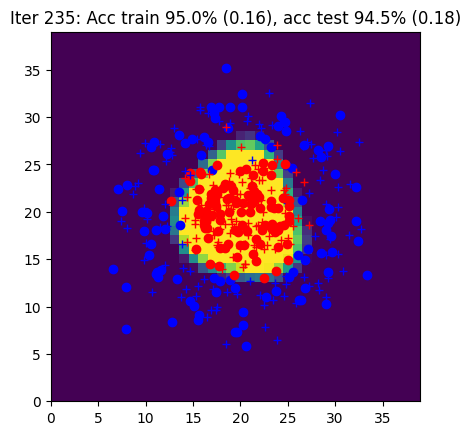

Iter 236: Acc train 95.5% (0.16), acc test 95.0% (0.18)


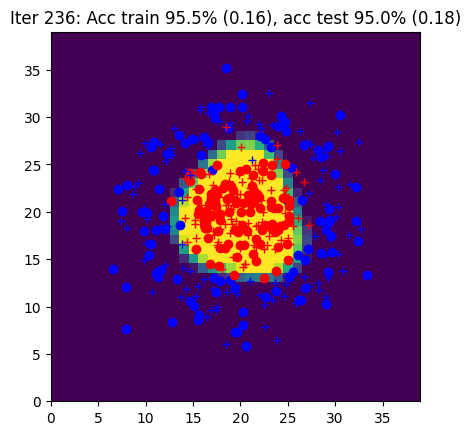

Iter 237: Acc train 95.5% (0.16), acc test 95.0% (0.18)


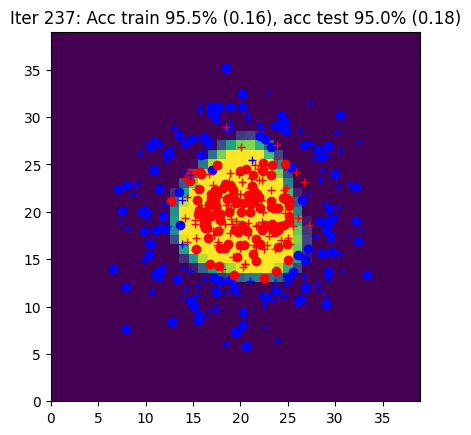

Iter 238: Acc train 95.5% (0.16), acc test 95.0% (0.18)


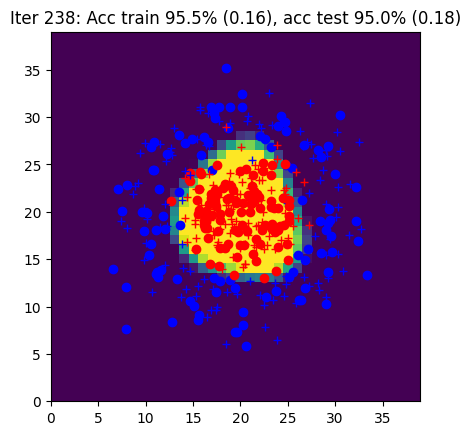

Iter 239: Acc train 95.5% (0.16), acc test 94.5% (0.18)


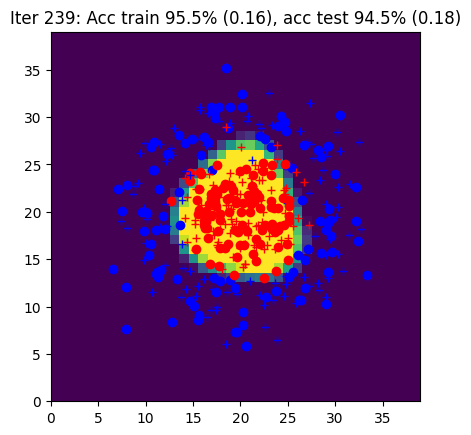

Iter 240: Acc train 95.0% (0.16), acc test 94.5% (0.18)


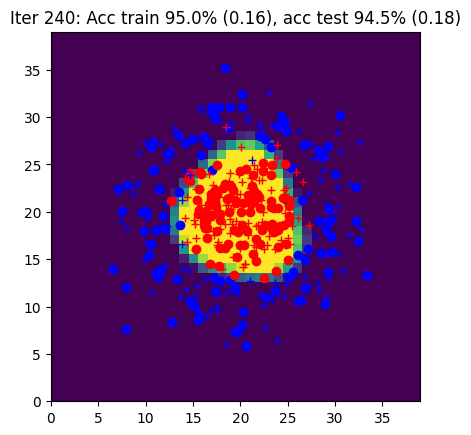

Iter 241: Acc train 95.5% (0.16), acc test 95.0% (0.18)


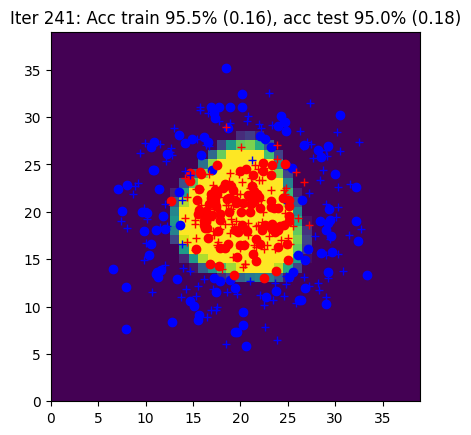

Iter 242: Acc train 95.5% (0.16), acc test 94.5% (0.18)


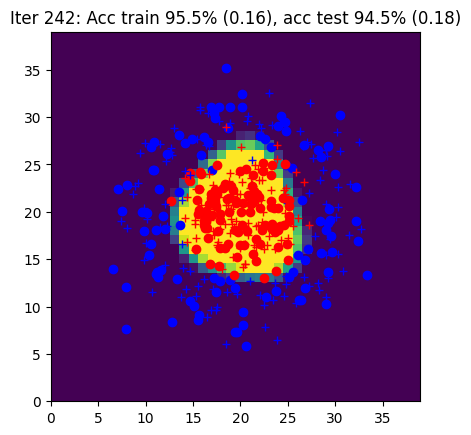

Iter 243: Acc train 95.5% (0.16), acc test 94.5% (0.18)


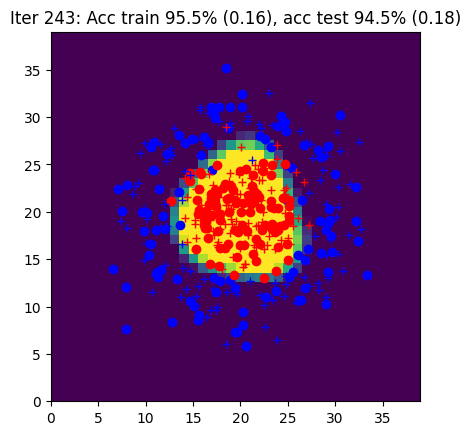

Iter 244: Acc train 95.0% (0.16), acc test 94.5% (0.18)


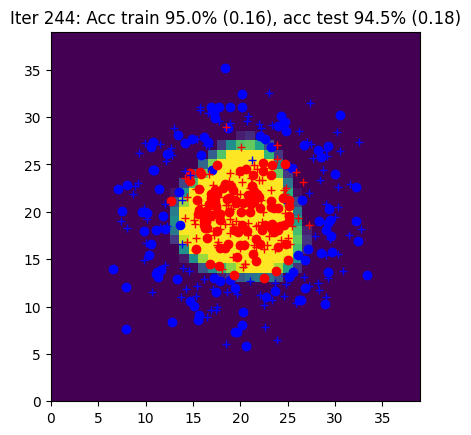

Iter 245: Acc train 95.5% (0.16), acc test 94.5% (0.18)


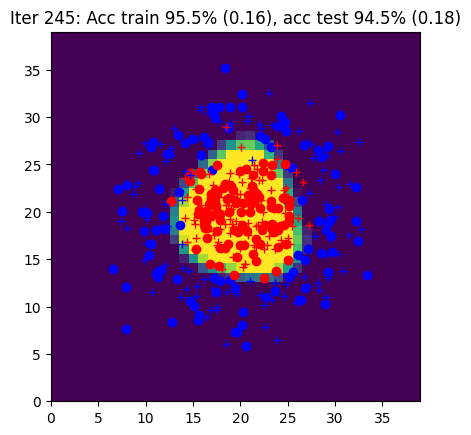

Iter 246: Acc train 95.0% (0.16), acc test 94.5% (0.18)


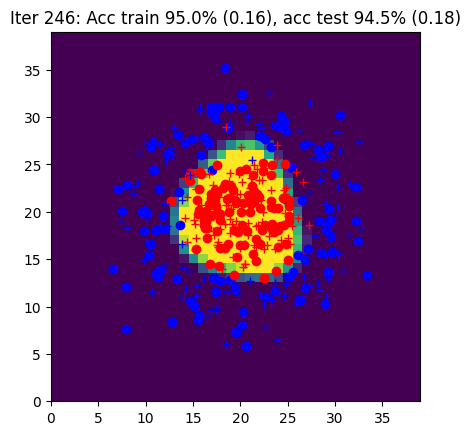

Iter 247: Acc train 95.0% (0.16), acc test 94.5% (0.18)


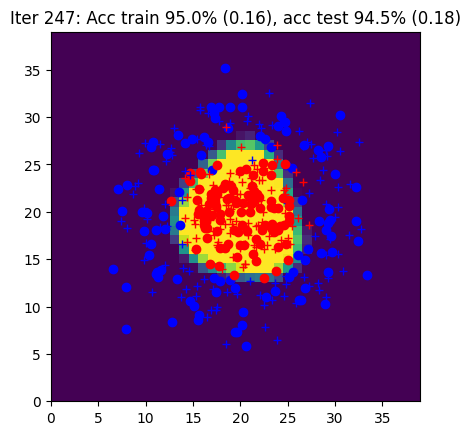

Iter 248: Acc train 95.0% (0.16), acc test 94.5% (0.18)


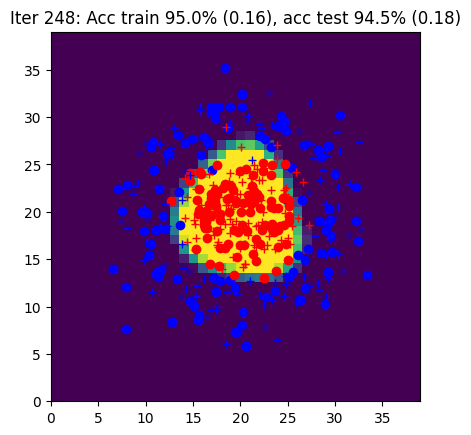

Iter 249: Acc train 95.0% (0.16), acc test 94.5% (0.18)


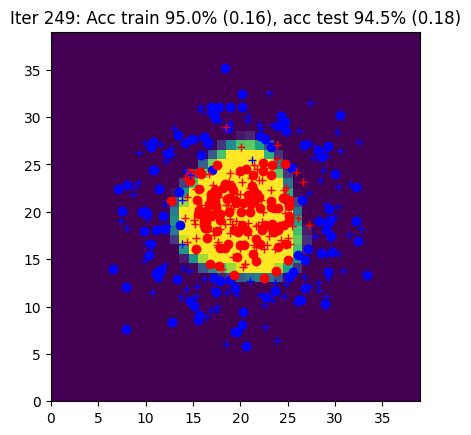

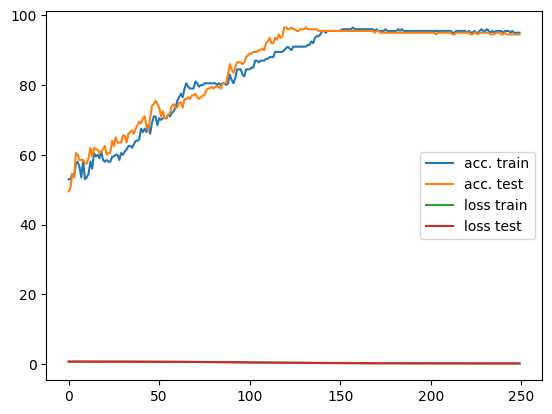

In [8]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

params = init_params(nx, nh, ny)

curves = [[],[], [], []]

# epoch
for iteration in range(250):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j+1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: forward, loss_accuracy, backward, sgd
        _, outputs = forward(params, X)
        grads = backward(params, outputs, Y)
        params = sgd(params, grads, eta)


    ####################
    ##      END        #
    ####################


    Yhat_train, _ = forward(params, data.Xtrain)
    Yhat_test, _ = forward(params, data.Xtest)
    Ltrain, acctrain = loss_accuracy(Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(Yhat_test, data.Ytest)
    Ygrid, _ = forward(params, data.Xgrid)

    title = 'Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})'.format(iteration, acctrain, Ltrain, acctest, Ltest)
    print(title)
    data.plot_data_with_grid(Ygrid, title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 2 : Simplification of the backward pass with `torch.autograd`



In [9]:
def init_params(nx, nh, ny):
    """
    nx, nh, ny: integers
    out params: dictionnary
    """
    params = {}

    #####################
    ## Your code here  ##
    #####################
    # fill values for Wh, Wy, bh, by
    # activaye autograd on the network weights

    params["Wh"] = (torch.randn(nh, nx) * 0.3).requires_grad_(True)
    params["Wy"] = (torch.randn(ny, nh) * 0.3).requires_grad_(True)
    params["bh"] = torch.zeros(nh, 1, requires_grad=True)
    params["by"] = torch.zeros(ny, 1, requires_grad=True)

    ####################
    ##      END        #
    ####################
    return params

The function `forward` remains unchanged from previous part.

The function `backward` is no longer used because of "autograd".

In [10]:
def sgd(params, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the network weights
    # warning: use torch.no_grad()
    # and reset to zero the gradient accumulators

    with torch.no_grad():
        for k in ["Wh", "Wy", "bh", "by"]:
            params[k] -= eta * params[k].grad
            params[k].grad.zero_()

    ####################
    ##      END        #
    ####################
    return params

## Global learning procedure with autograd

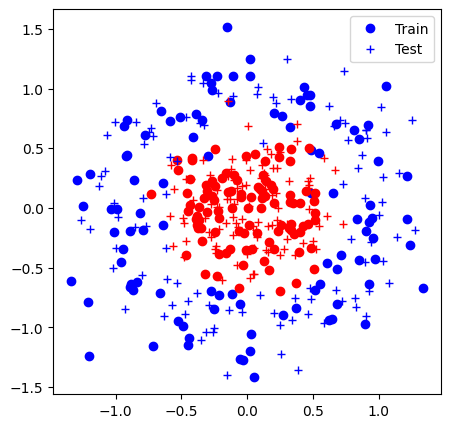

Iter 0: Acc train 52.0% (0.70), acc test 52.5% (0.69)


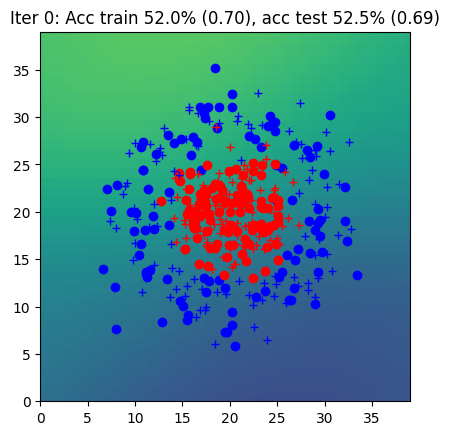

Iter 1: Acc train 55.5% (0.69), acc test 52.0% (0.69)


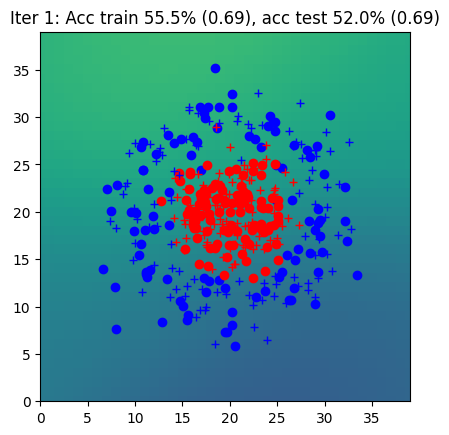

Iter 2: Acc train 59.0% (0.69), acc test 58.5% (0.69)


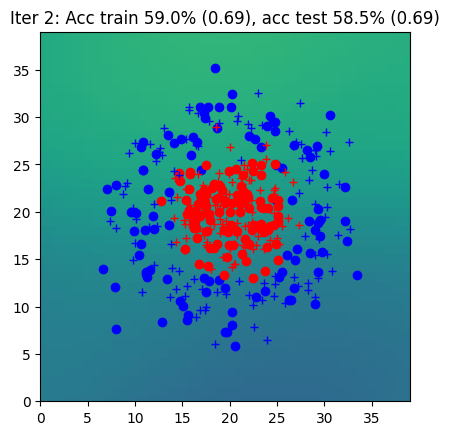

Iter 3: Acc train 61.5% (0.69), acc test 62.0% (0.69)


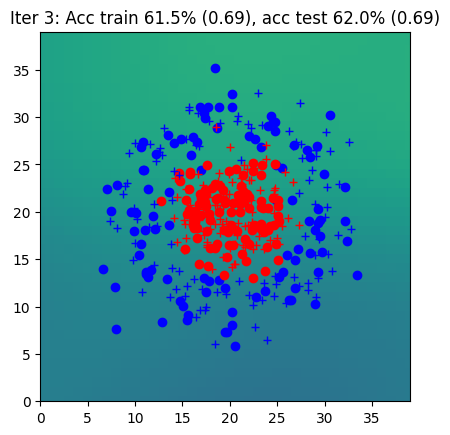

Iter 4: Acc train 64.0% (0.69), acc test 66.5% (0.69)


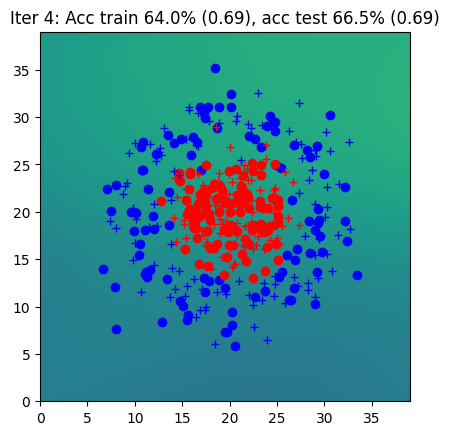

Iter 5: Acc train 65.5% (0.69), acc test 63.0% (0.69)


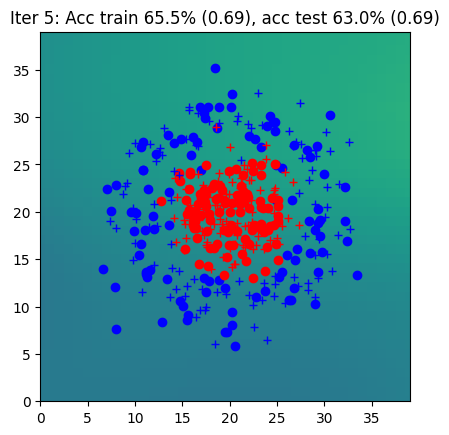

Iter 6: Acc train 66.0% (0.69), acc test 67.0% (0.69)


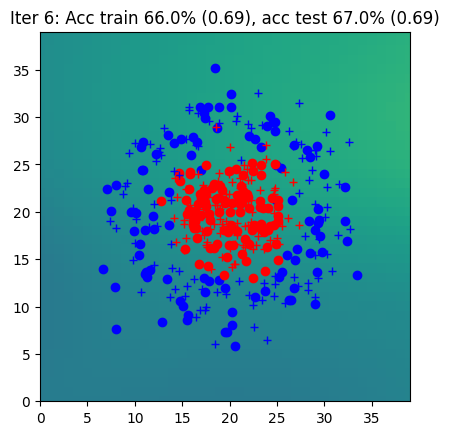

Iter 7: Acc train 66.0% (0.69), acc test 68.0% (0.69)


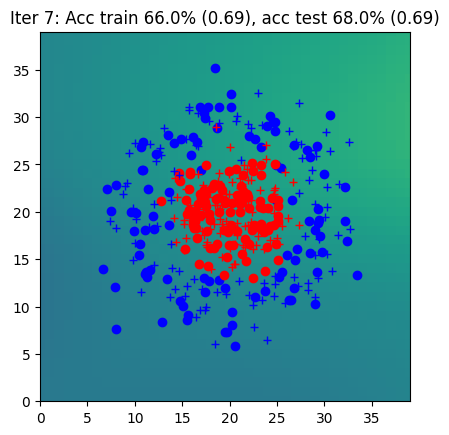

Iter 8: Acc train 67.0% (0.69), acc test 67.5% (0.69)


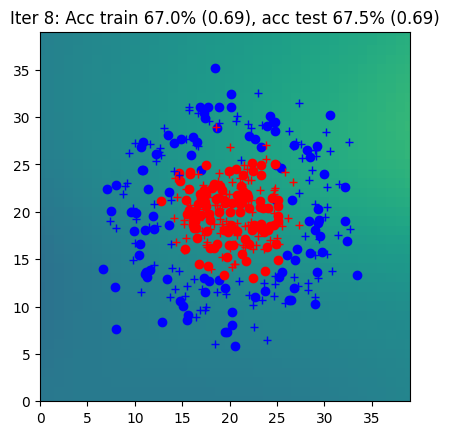

Iter 9: Acc train 67.5% (0.69), acc test 69.0% (0.69)


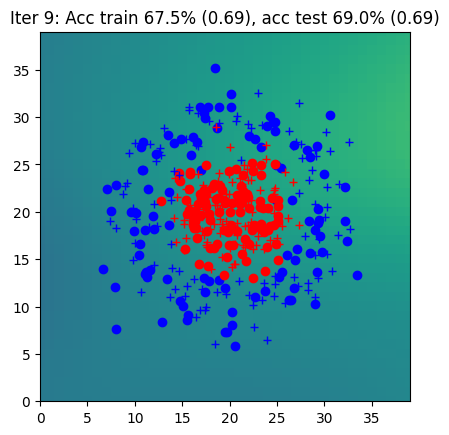

Iter 10: Acc train 70.5% (0.69), acc test 68.5% (0.69)


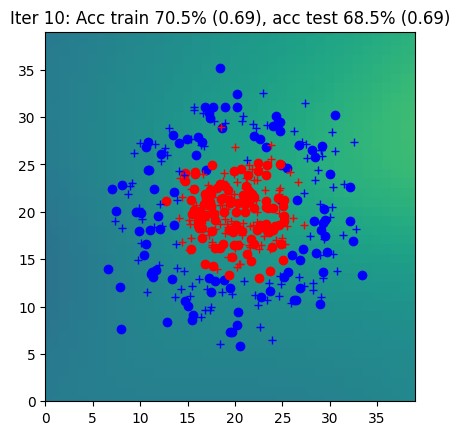

Iter 11: Acc train 70.5% (0.69), acc test 70.0% (0.69)


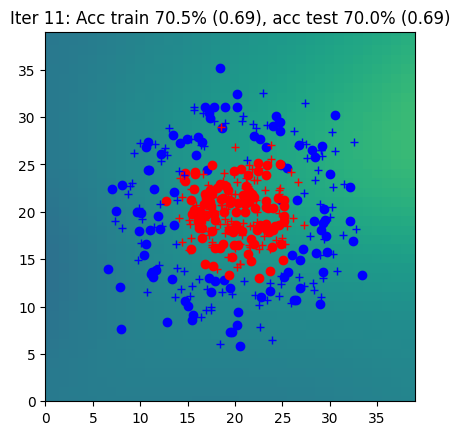

Iter 12: Acc train 71.0% (0.68), acc test 69.5% (0.69)


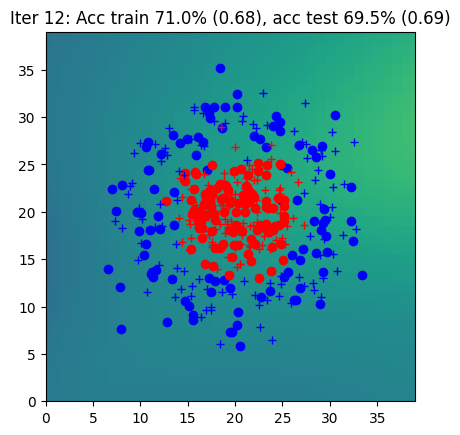

Iter 13: Acc train 73.5% (0.68), acc test 72.5% (0.69)


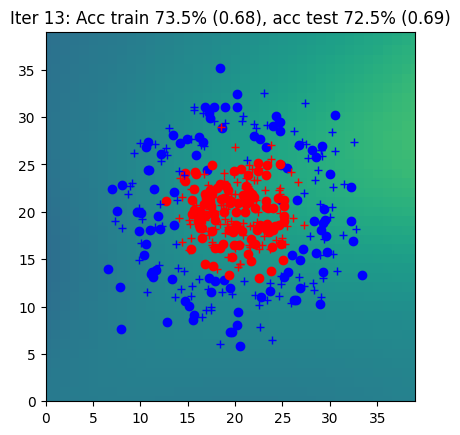

Iter 14: Acc train 74.5% (0.68), acc test 73.0% (0.68)


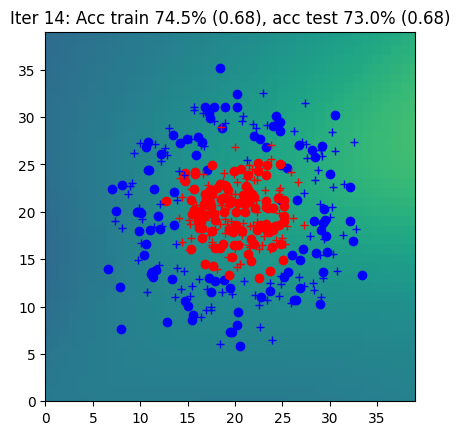

Iter 15: Acc train 74.0% (0.68), acc test 74.5% (0.68)


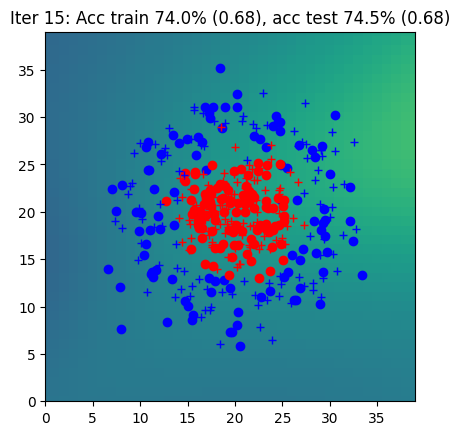

Iter 16: Acc train 76.0% (0.68), acc test 74.0% (0.68)


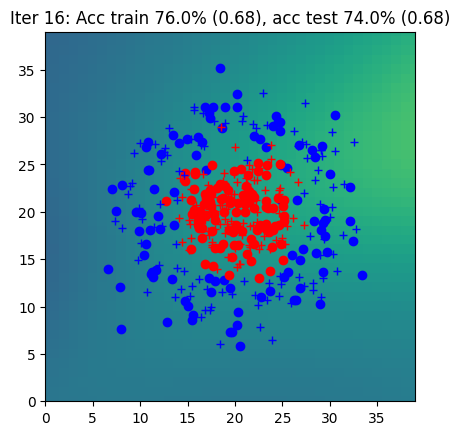

Iter 17: Acc train 74.5% (0.68), acc test 75.5% (0.68)


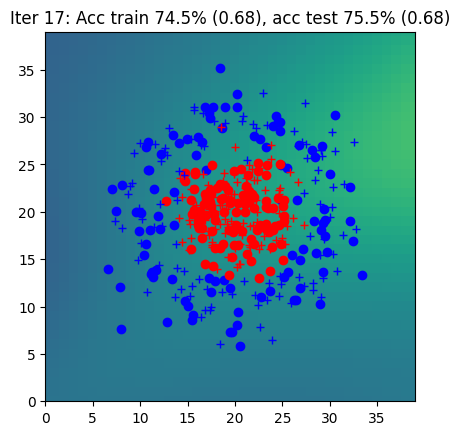

Iter 18: Acc train 76.0% (0.68), acc test 76.0% (0.68)


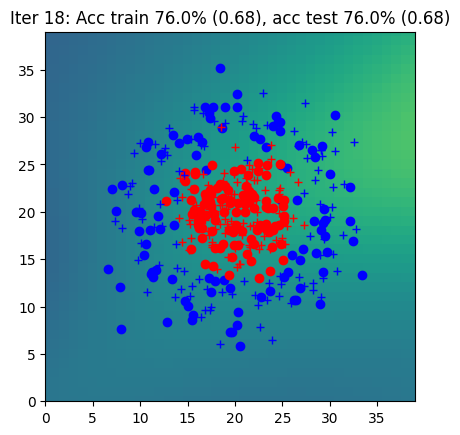

Iter 19: Acc train 77.0% (0.68), acc test 77.0% (0.68)


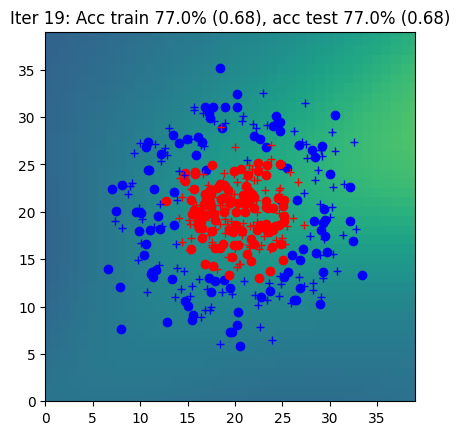

Iter 20: Acc train 78.5% (0.68), acc test 77.5% (0.68)


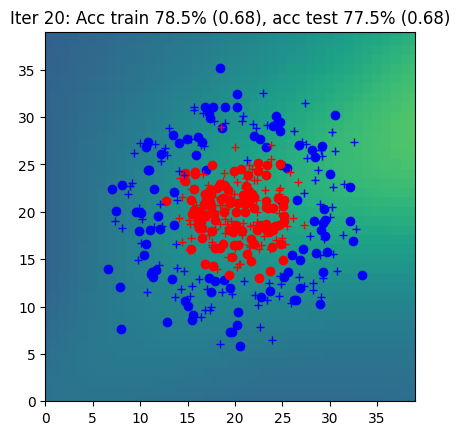

Iter 21: Acc train 77.5% (0.68), acc test 79.0% (0.68)


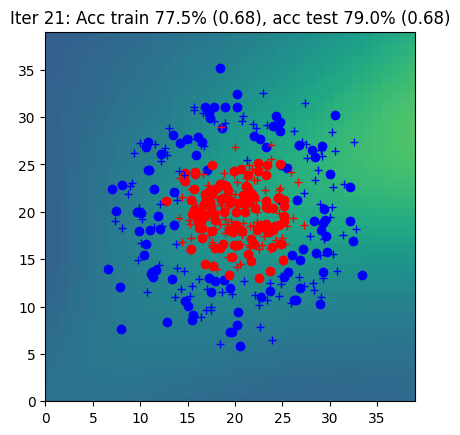

Iter 22: Acc train 76.5% (0.67), acc test 76.5% (0.68)


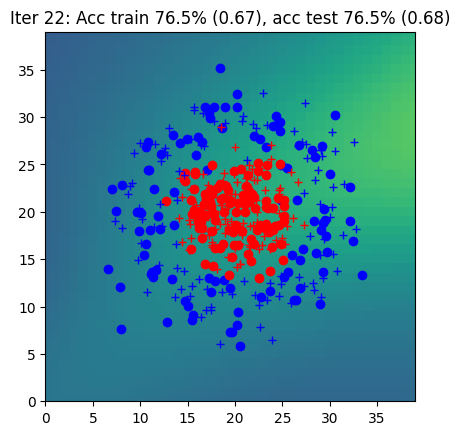

Iter 23: Acc train 80.0% (0.67), acc test 81.5% (0.67)


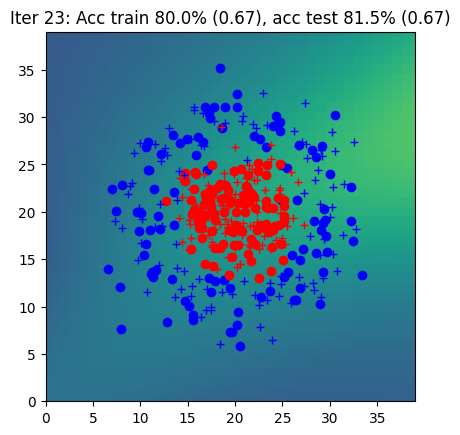

Iter 24: Acc train 78.5% (0.67), acc test 79.0% (0.67)


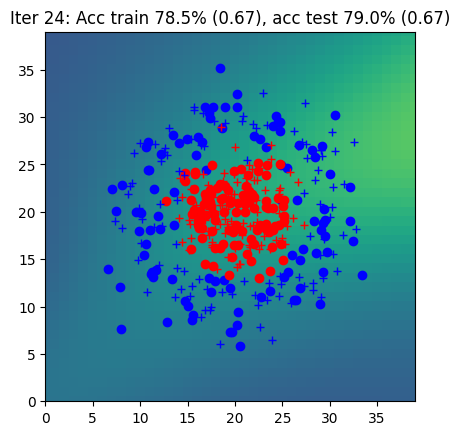

Iter 25: Acc train 75.5% (0.67), acc test 73.5% (0.67)


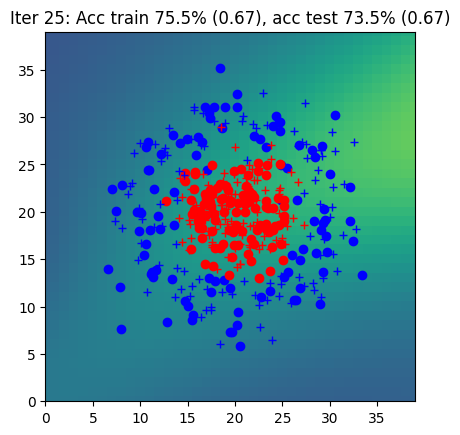

Iter 26: Acc train 77.0% (0.67), acc test 75.0% (0.67)


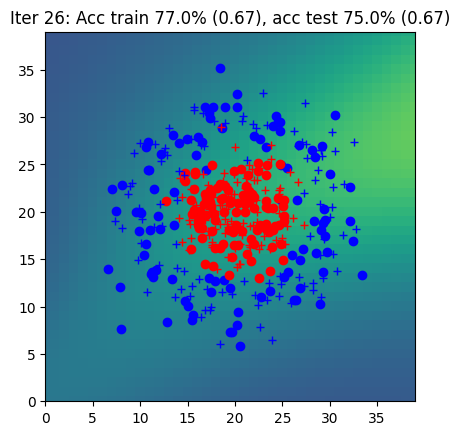

Iter 27: Acc train 80.5% (0.67), acc test 83.0% (0.67)


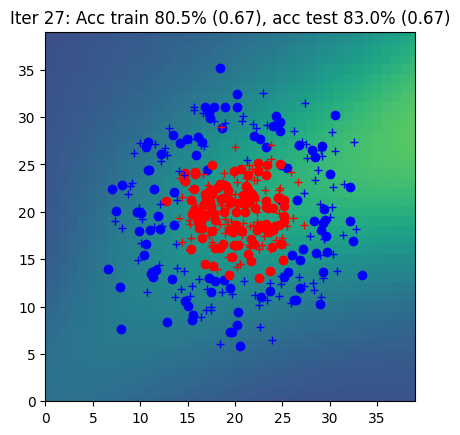

Iter 28: Acc train 80.5% (0.67), acc test 81.5% (0.67)


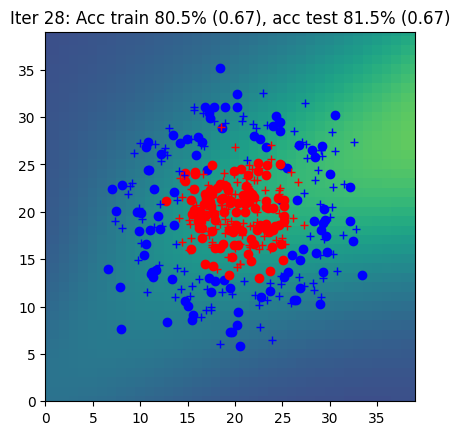

Iter 29: Acc train 80.0% (0.66), acc test 78.5% (0.67)


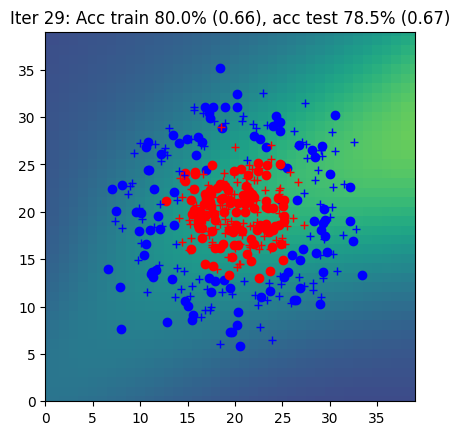

Iter 30: Acc train 79.0% (0.66), acc test 79.0% (0.66)


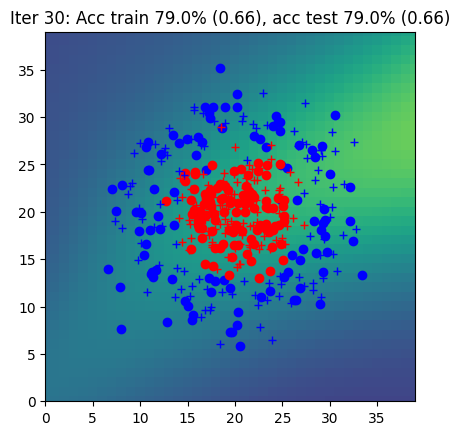

Iter 31: Acc train 78.5% (0.66), acc test 79.0% (0.66)


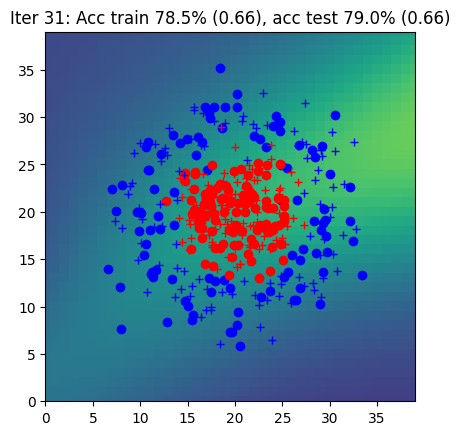

Iter 32: Acc train 79.0% (0.66), acc test 83.5% (0.66)


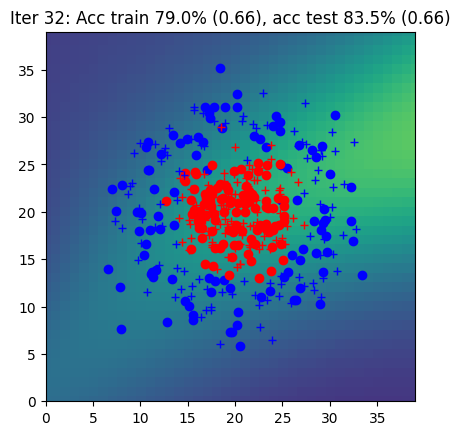

Iter 33: Acc train 80.0% (0.66), acc test 83.5% (0.66)


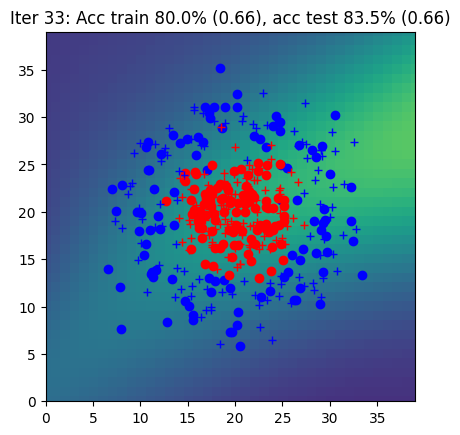

Iter 34: Acc train 80.5% (0.65), acc test 82.5% (0.65)


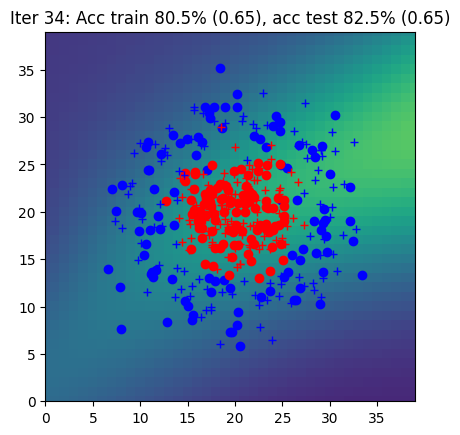

Iter 35: Acc train 79.0% (0.65), acc test 80.5% (0.65)


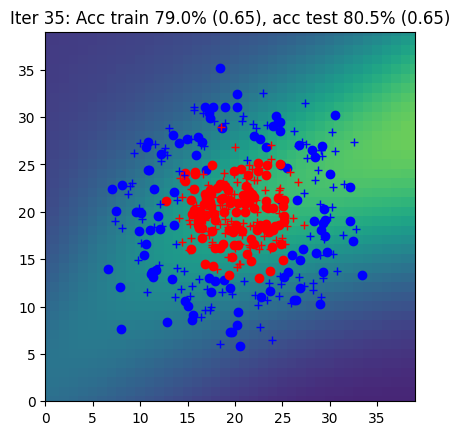

Iter 36: Acc train 75.0% (0.65), acc test 77.0% (0.65)


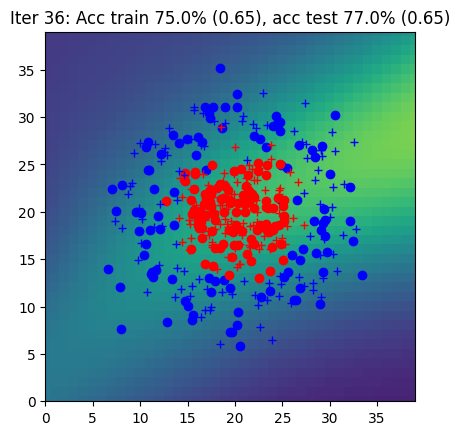

Iter 37: Acc train 74.5% (0.65), acc test 77.5% (0.65)


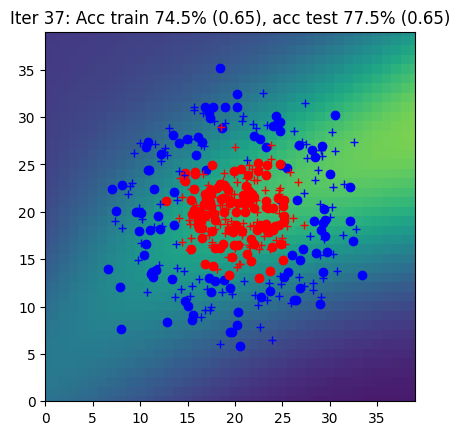

Iter 38: Acc train 76.0% (0.64), acc test 80.0% (0.64)


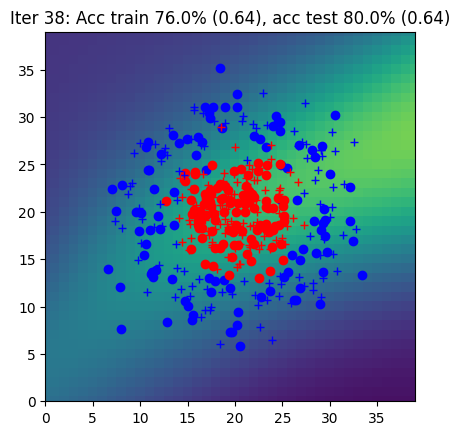

Iter 39: Acc train 76.5% (0.64), acc test 80.5% (0.64)


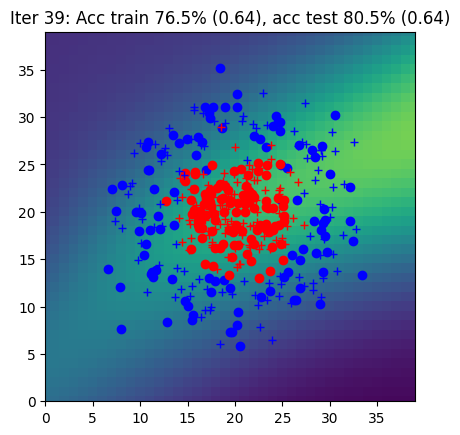

Iter 40: Acc train 75.5% (0.64), acc test 79.5% (0.64)


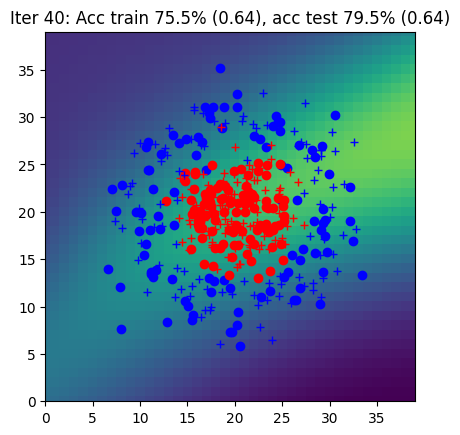

Iter 41: Acc train 76.5% (0.63), acc test 80.0% (0.63)


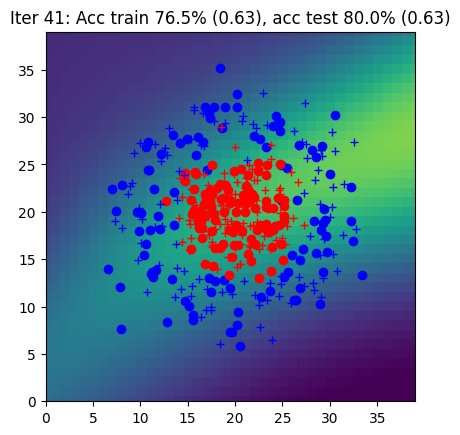

Iter 42: Acc train 75.5% (0.63), acc test 82.0% (0.63)


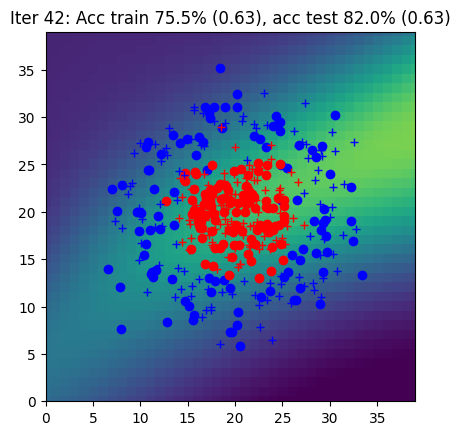

Iter 43: Acc train 76.0% (0.63), acc test 81.5% (0.63)


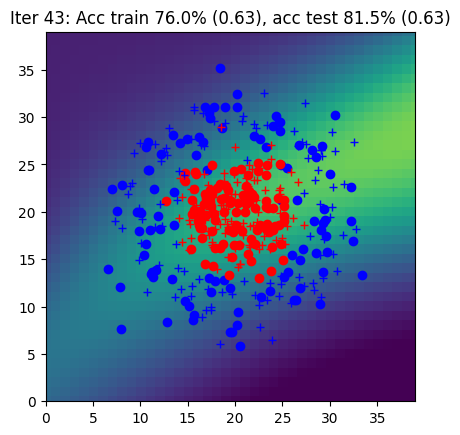

Iter 44: Acc train 76.0% (0.62), acc test 81.0% (0.62)


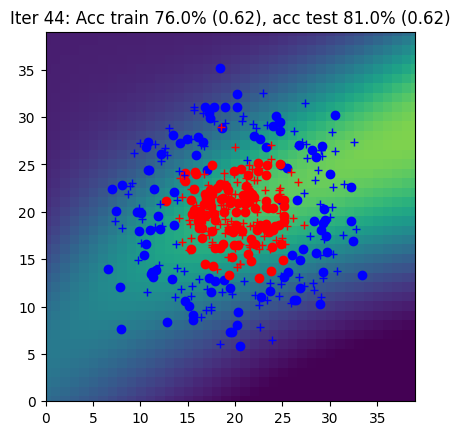

Iter 45: Acc train 75.5% (0.62), acc test 79.0% (0.62)


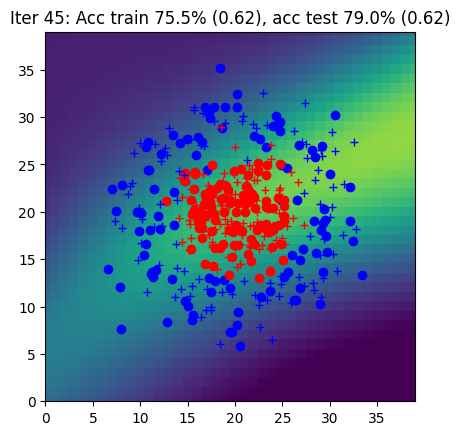

Iter 46: Acc train 78.5% (0.62), acc test 81.5% (0.62)


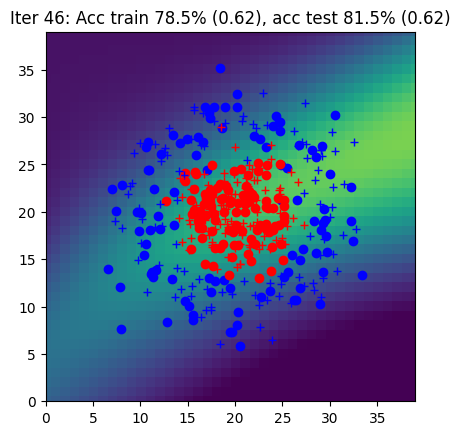

Iter 47: Acc train 79.5% (0.61), acc test 81.0% (0.61)


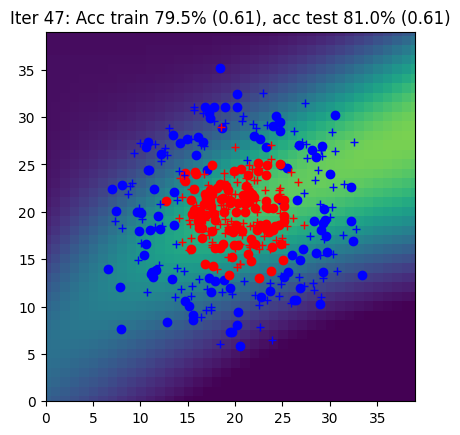

Iter 48: Acc train 77.0% (0.61), acc test 79.0% (0.61)


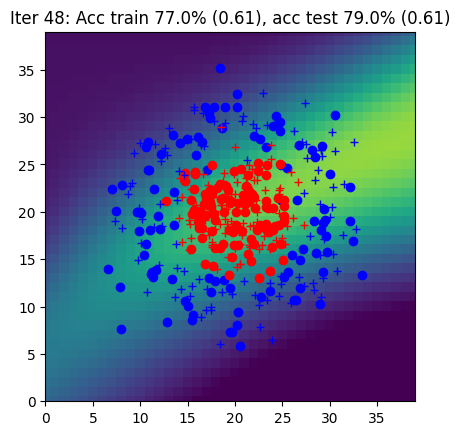

Iter 49: Acc train 79.0% (0.61), acc test 81.5% (0.61)


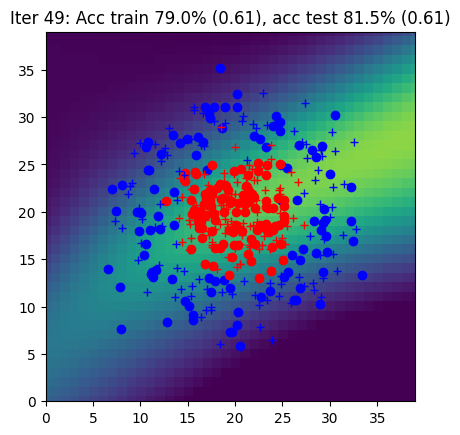

Iter 50: Acc train 77.0% (0.60), acc test 80.0% (0.60)


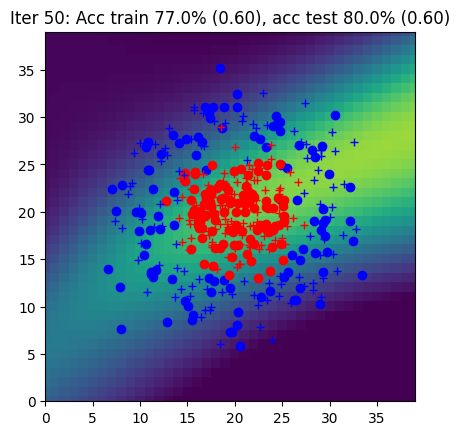

Iter 51: Acc train 77.0% (0.60), acc test 80.5% (0.60)


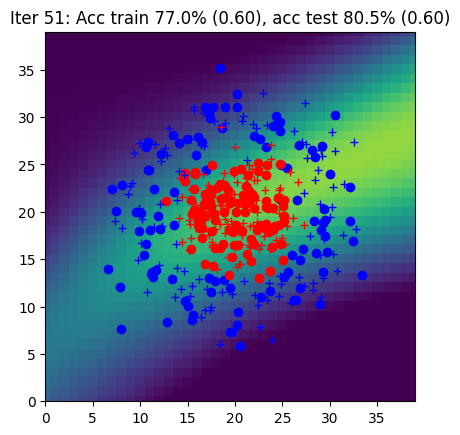

Iter 52: Acc train 76.5% (0.59), acc test 80.0% (0.60)


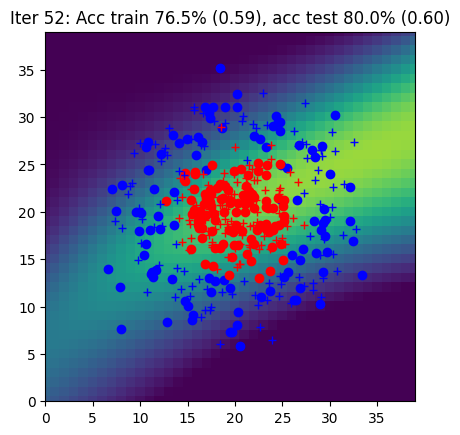

Iter 53: Acc train 76.0% (0.59), acc test 80.0% (0.59)


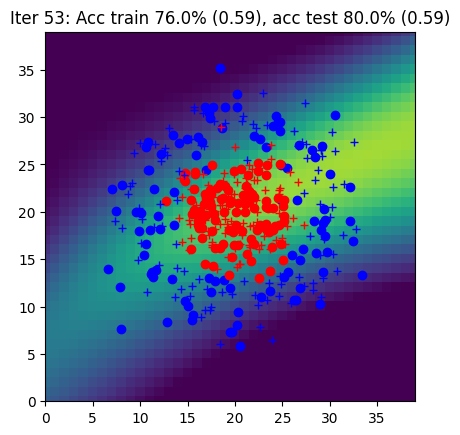

Iter 54: Acc train 77.0% (0.59), acc test 80.0% (0.59)


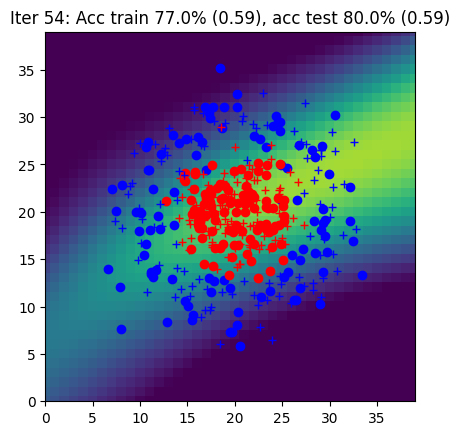

Iter 55: Acc train 79.0% (0.58), acc test 80.5% (0.58)


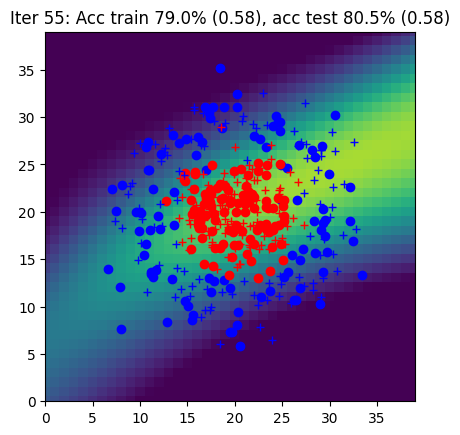

Iter 56: Acc train 77.0% (0.58), acc test 80.0% (0.58)


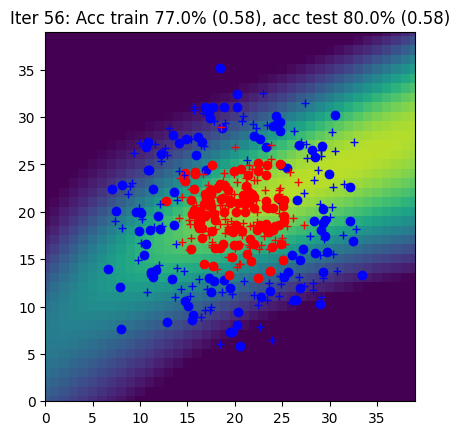

Iter 57: Acc train 77.0% (0.58), acc test 80.0% (0.58)


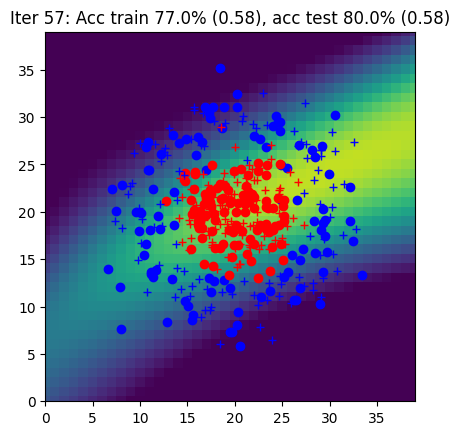

Iter 58: Acc train 79.0% (0.57), acc test 80.0% (0.57)


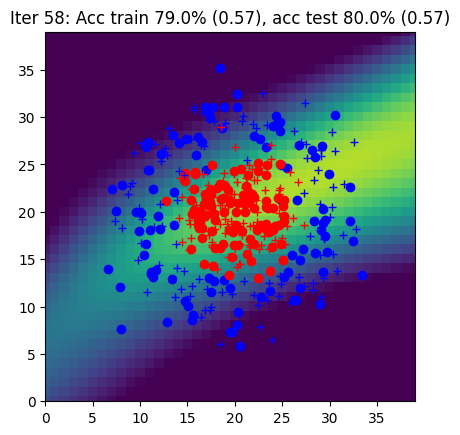

Iter 59: Acc train 78.5% (0.57), acc test 80.5% (0.57)


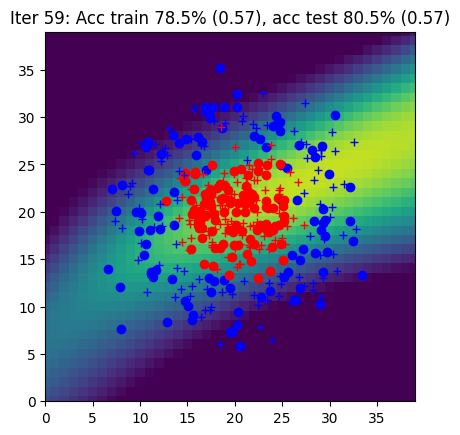

Iter 60: Acc train 79.0% (0.56), acc test 80.5% (0.56)


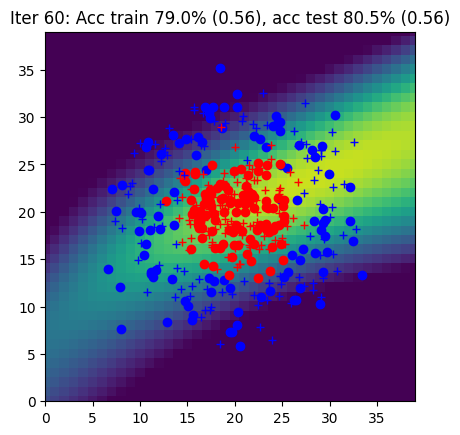

Iter 61: Acc train 78.5% (0.56), acc test 80.5% (0.56)


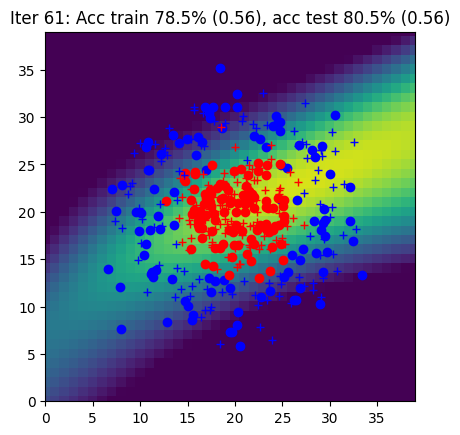

Iter 62: Acc train 78.5% (0.56), acc test 80.5% (0.56)


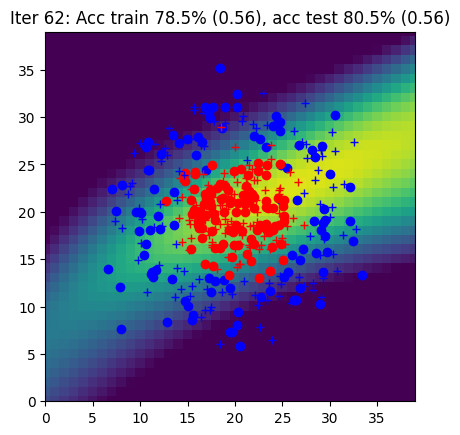

Iter 63: Acc train 78.5% (0.55), acc test 80.5% (0.55)


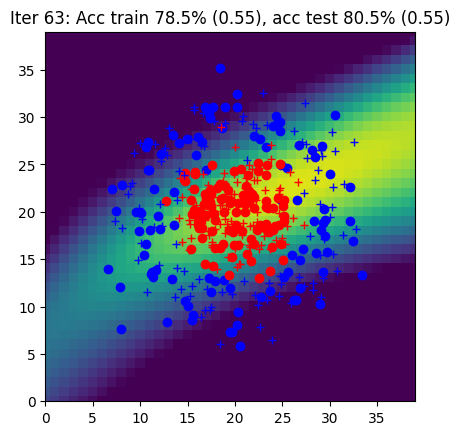

Iter 64: Acc train 78.5% (0.55), acc test 80.0% (0.55)


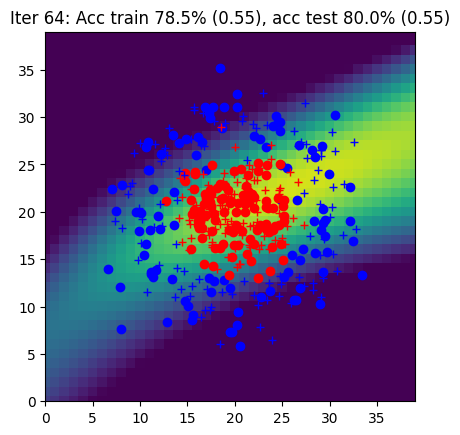

Iter 65: Acc train 78.5% (0.54), acc test 80.5% (0.54)


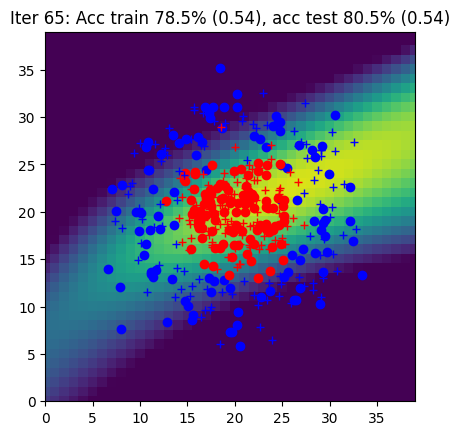

Iter 66: Acc train 77.5% (0.54), acc test 80.0% (0.54)


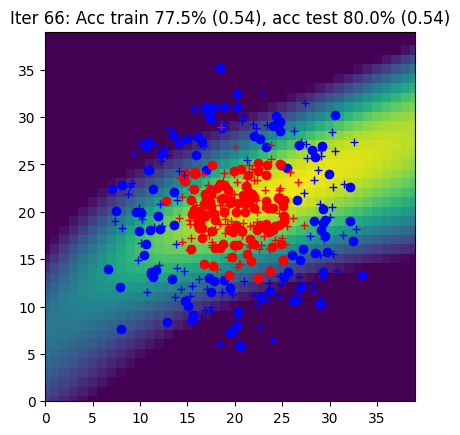

Iter 67: Acc train 78.0% (0.54), acc test 80.5% (0.54)


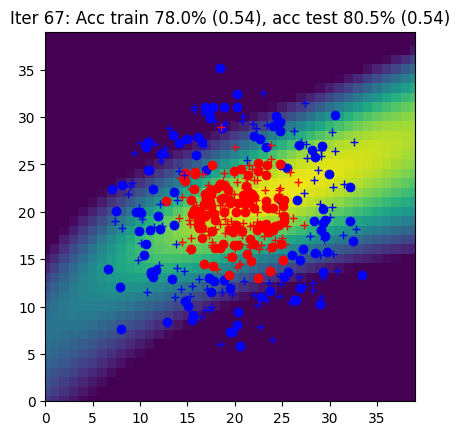

Iter 68: Acc train 78.0% (0.53), acc test 80.5% (0.53)


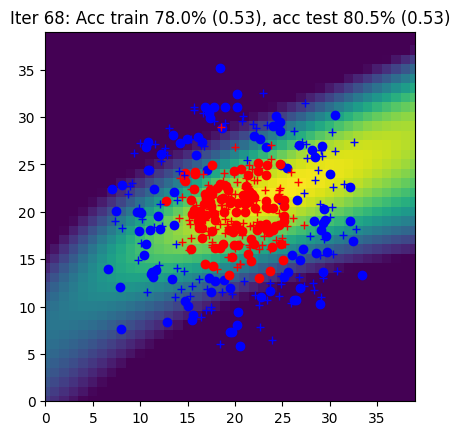

Iter 69: Acc train 77.5% (0.53), acc test 80.5% (0.53)


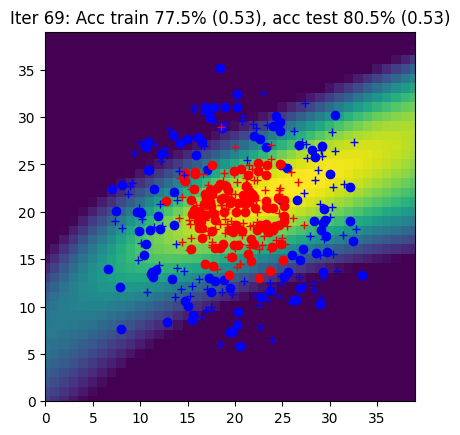

Iter 70: Acc train 79.0% (0.53), acc test 80.0% (0.53)


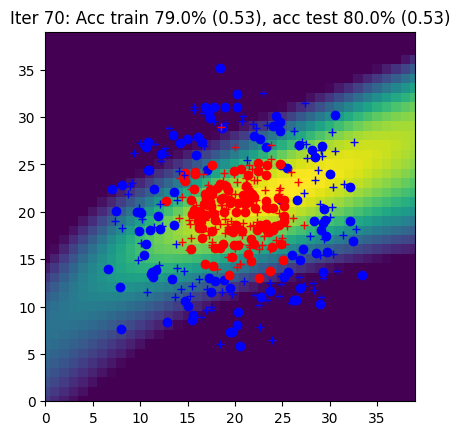

Iter 71: Acc train 80.0% (0.52), acc test 80.5% (0.52)


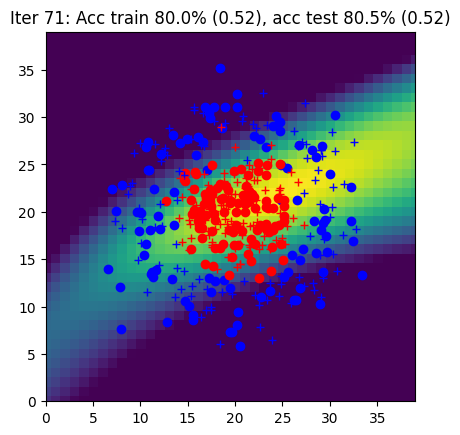

Iter 72: Acc train 80.5% (0.52), acc test 80.0% (0.52)


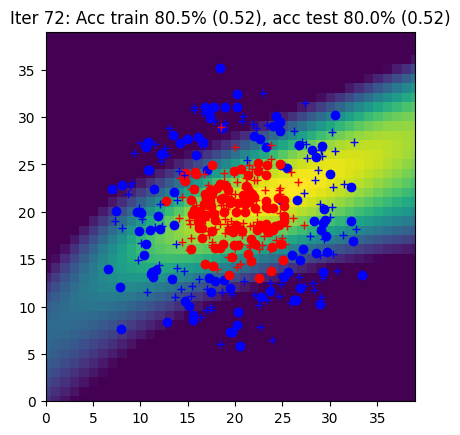

Iter 73: Acc train 80.5% (0.52), acc test 80.0% (0.52)


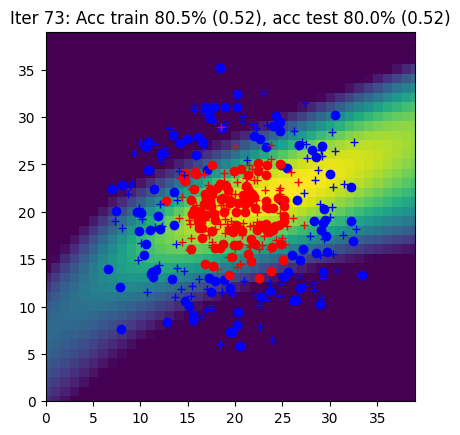

Iter 74: Acc train 80.5% (0.51), acc test 80.0% (0.51)


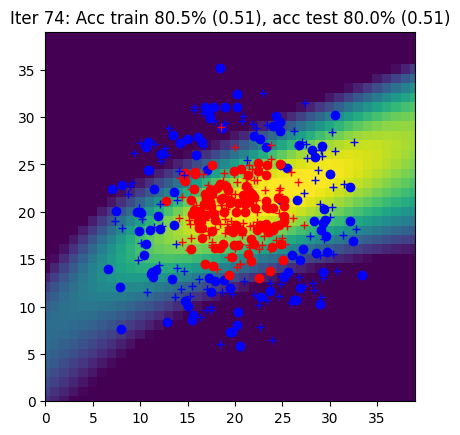

Iter 75: Acc train 81.0% (0.51), acc test 80.0% (0.51)


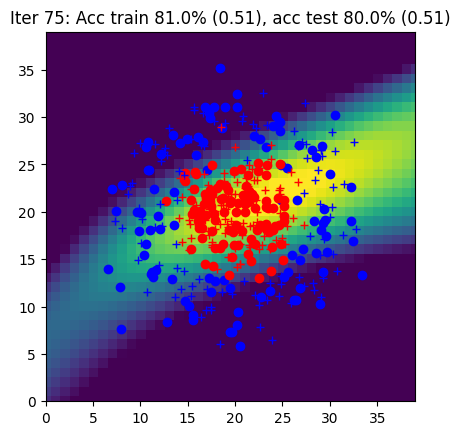

Iter 76: Acc train 80.0% (0.51), acc test 80.5% (0.51)


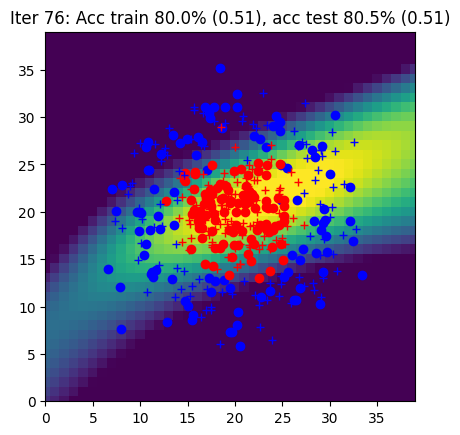

Iter 77: Acc train 79.5% (0.50), acc test 80.0% (0.50)


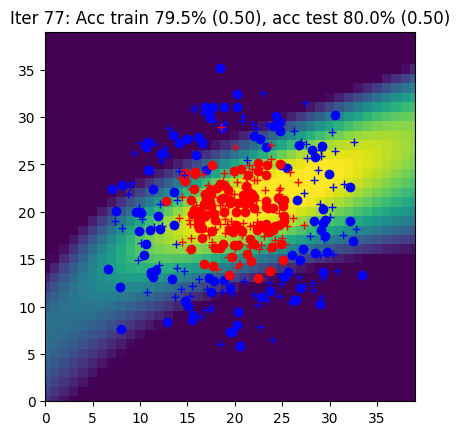

Iter 78: Acc train 79.0% (0.50), acc test 79.0% (0.50)


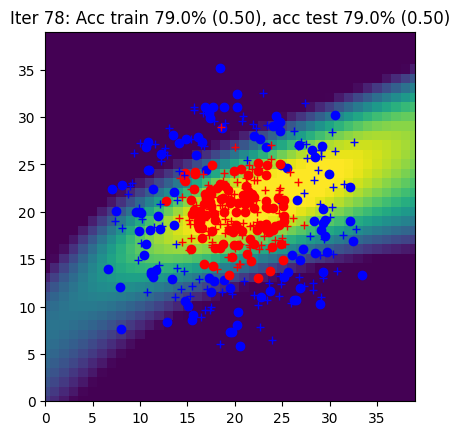

Iter 79: Acc train 79.5% (0.50), acc test 79.0% (0.50)


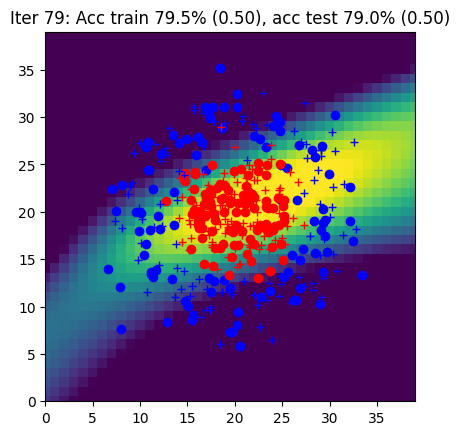

Iter 80: Acc train 80.5% (0.49), acc test 79.5% (0.49)


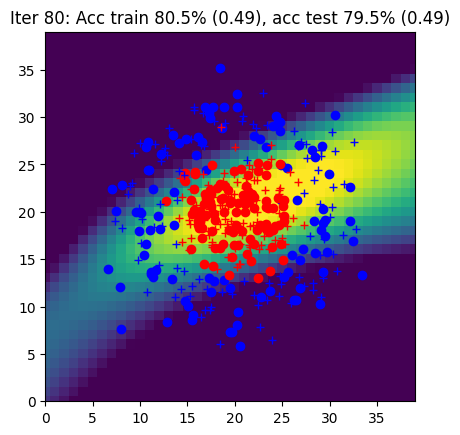

Iter 81: Acc train 80.0% (0.49), acc test 79.0% (0.49)


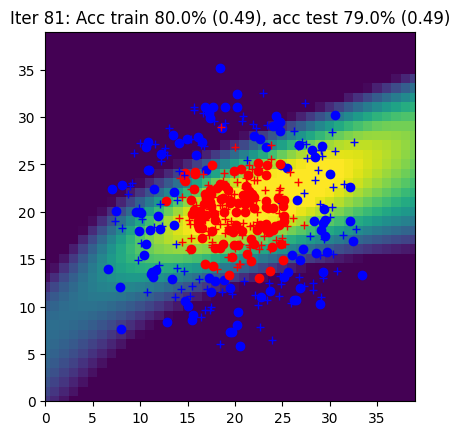

Iter 82: Acc train 80.5% (0.49), acc test 79.5% (0.49)


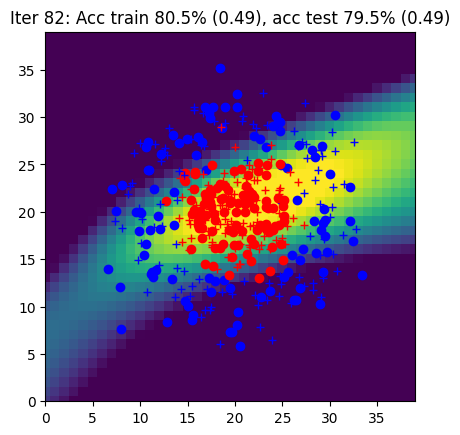

Iter 83: Acc train 79.5% (0.48), acc test 79.0% (0.48)


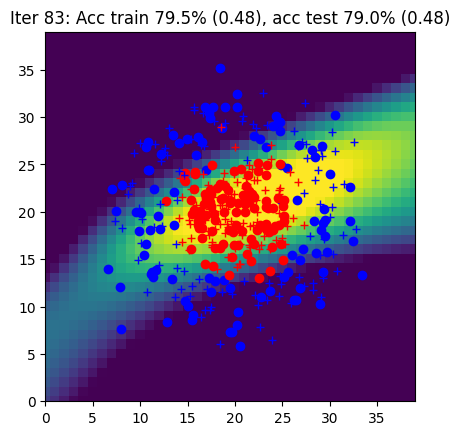

Iter 84: Acc train 79.5% (0.48), acc test 78.5% (0.48)


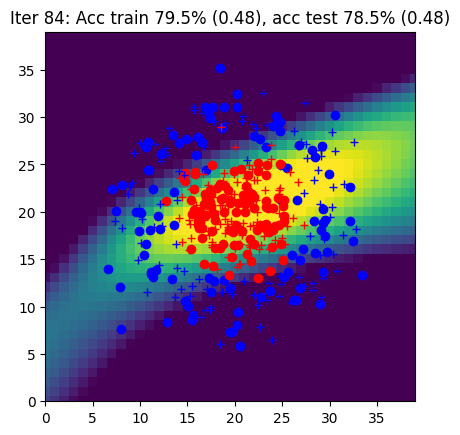

Iter 85: Acc train 79.5% (0.48), acc test 79.0% (0.48)


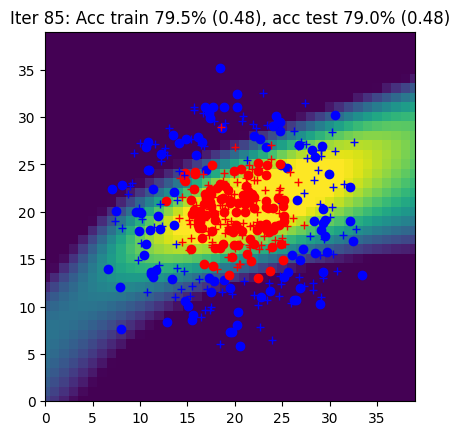

Iter 86: Acc train 79.5% (0.48), acc test 79.0% (0.47)


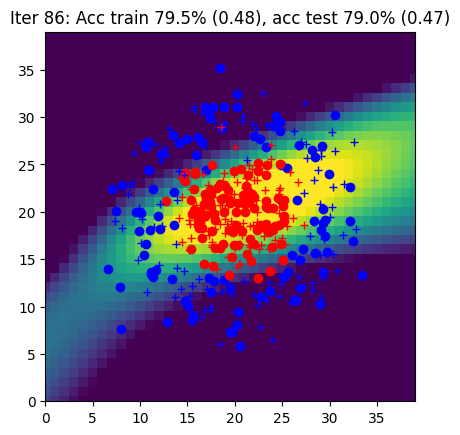

Iter 87: Acc train 80.5% (0.47), acc test 80.0% (0.47)


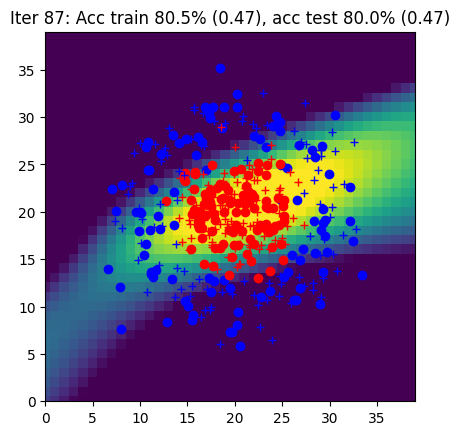

Iter 88: Acc train 80.5% (0.47), acc test 80.0% (0.47)


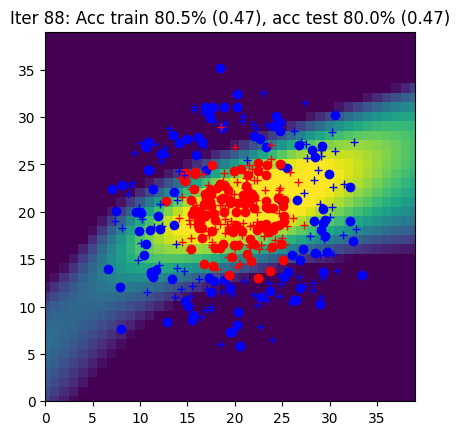

Iter 89: Acc train 81.5% (0.47), acc test 80.5% (0.47)


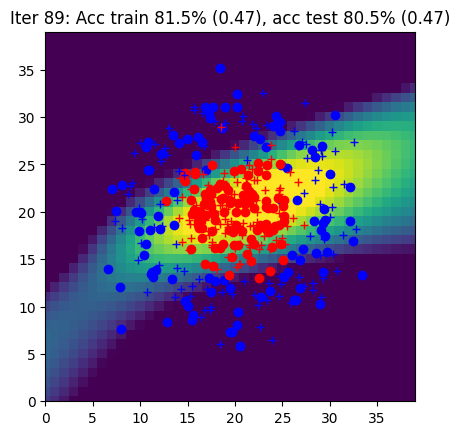

Iter 90: Acc train 81.0% (0.46), acc test 80.5% (0.46)


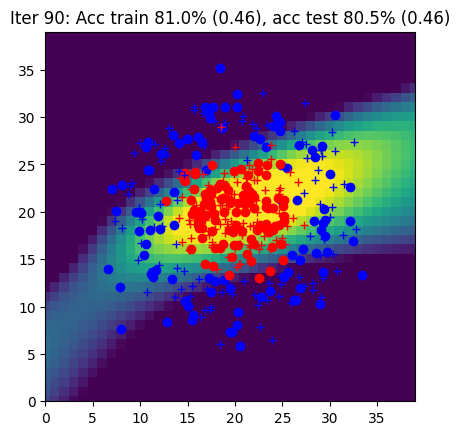

Iter 91: Acc train 81.5% (0.46), acc test 80.5% (0.46)


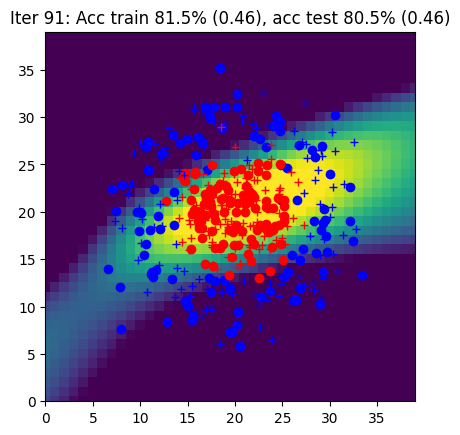

Iter 92: Acc train 80.5% (0.46), acc test 80.0% (0.46)


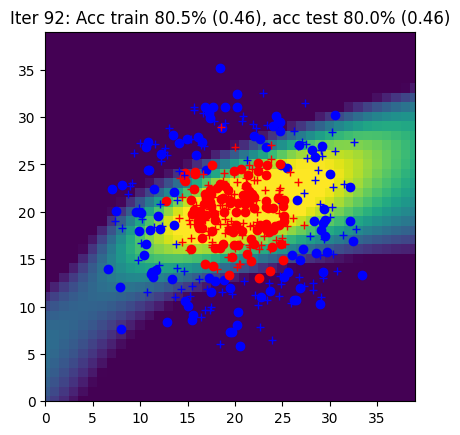

Iter 93: Acc train 81.0% (0.46), acc test 80.0% (0.45)


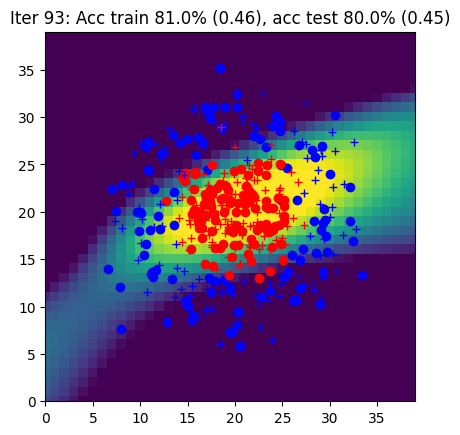

Iter 94: Acc train 81.0% (0.45), acc test 80.0% (0.45)


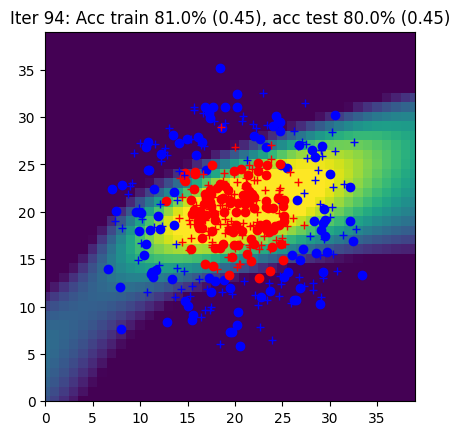

Iter 95: Acc train 81.5% (0.45), acc test 81.0% (0.45)


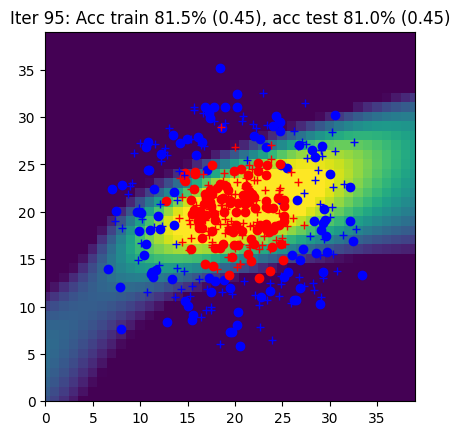

Iter 96: Acc train 81.5% (0.45), acc test 81.0% (0.44)


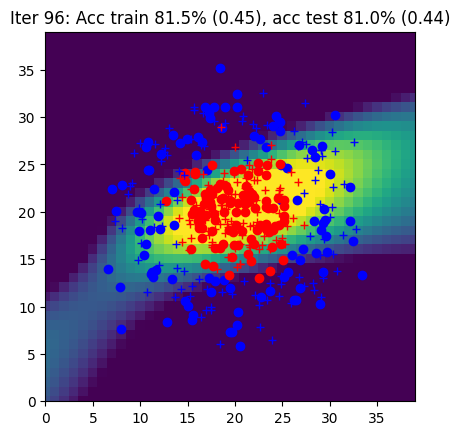

Iter 97: Acc train 81.0% (0.44), acc test 80.5% (0.44)


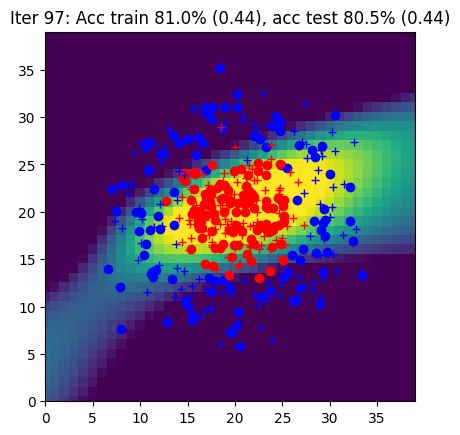

Iter 98: Acc train 81.5% (0.44), acc test 80.5% (0.44)


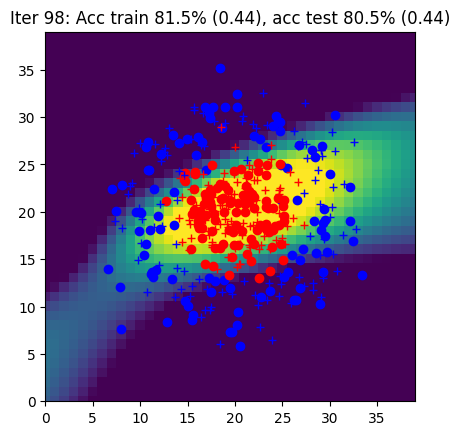

Iter 99: Acc train 82.0% (0.44), acc test 81.0% (0.43)


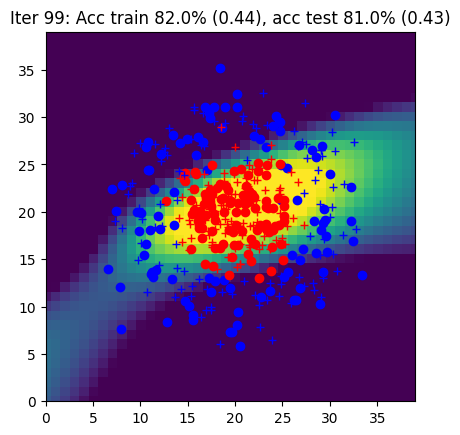

Iter 100: Acc train 81.5% (0.43), acc test 80.5% (0.43)


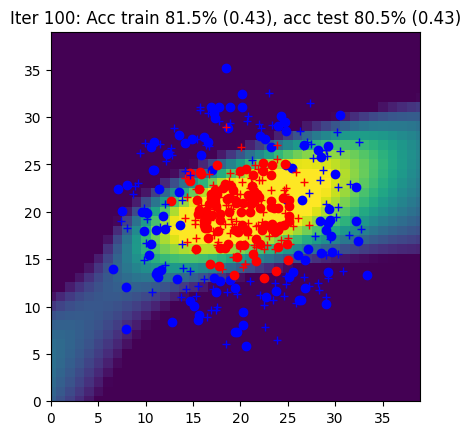

Iter 101: Acc train 82.5% (0.43), acc test 83.0% (0.43)


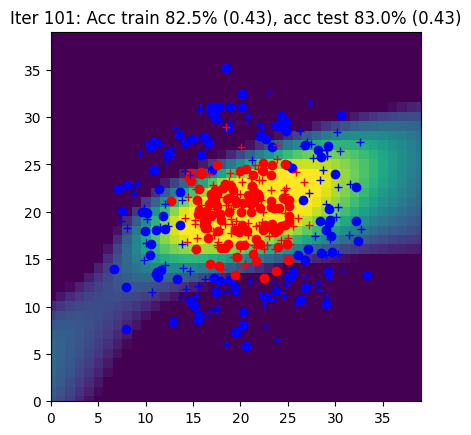

Iter 102: Acc train 82.0% (0.43), acc test 82.5% (0.42)


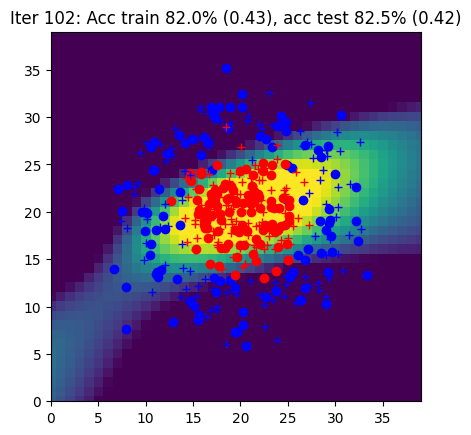

Iter 103: Acc train 82.0% (0.42), acc test 81.5% (0.42)


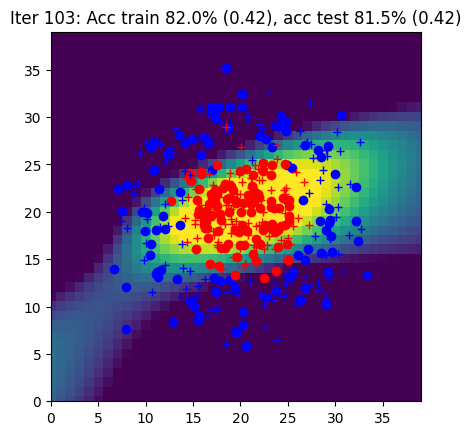

Iter 104: Acc train 82.0% (0.42), acc test 83.0% (0.41)


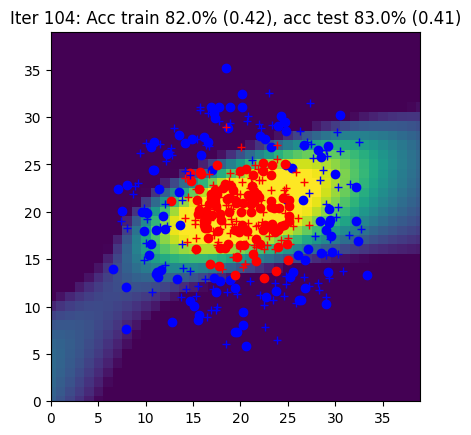

Iter 105: Acc train 82.5% (0.42), acc test 81.0% (0.41)


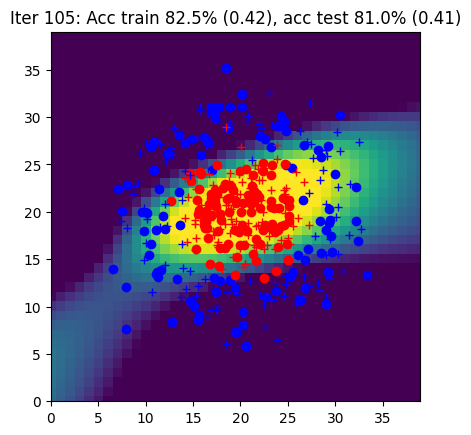

Iter 106: Acc train 82.0% (0.41), acc test 83.5% (0.41)


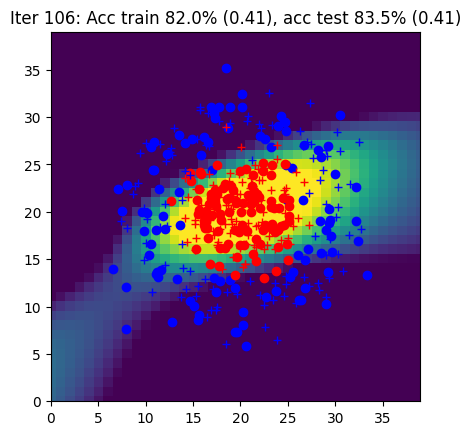

Iter 107: Acc train 83.5% (0.41), acc test 84.0% (0.40)


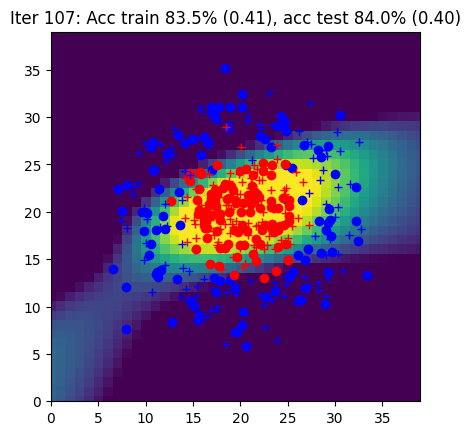

Iter 108: Acc train 84.0% (0.41), acc test 84.5% (0.40)


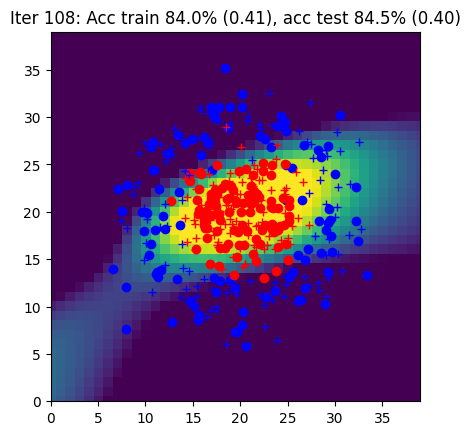

Iter 109: Acc train 84.5% (0.40), acc test 84.5% (0.39)


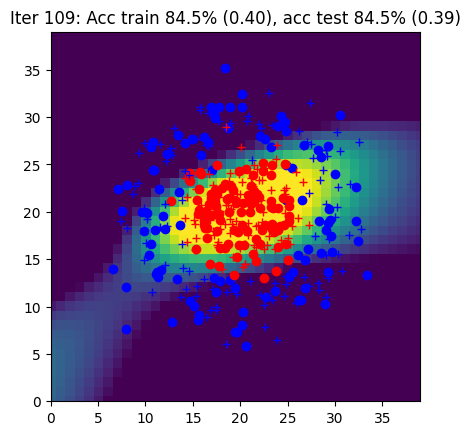

Iter 110: Acc train 84.5% (0.40), acc test 84.5% (0.39)


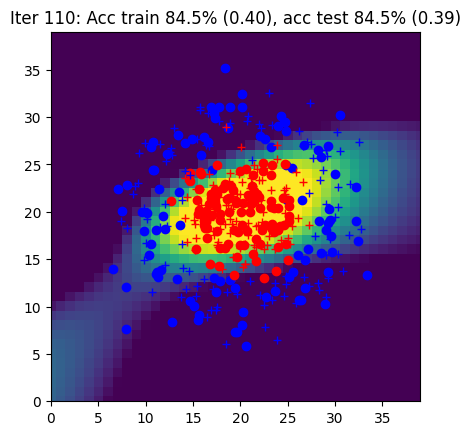

Iter 111: Acc train 85.0% (0.39), acc test 85.5% (0.39)


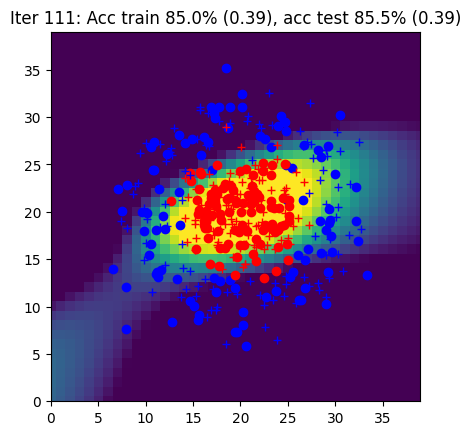

Iter 112: Acc train 85.5% (0.39), acc test 86.0% (0.38)


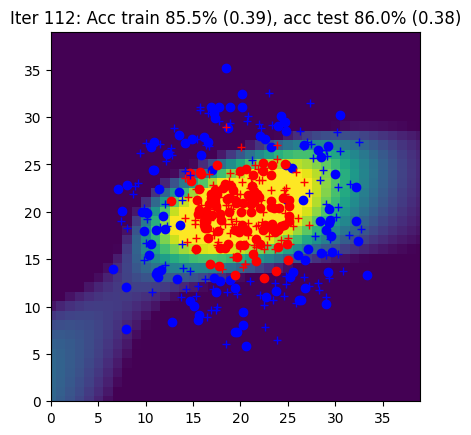

Iter 113: Acc train 85.5% (0.39), acc test 86.0% (0.38)


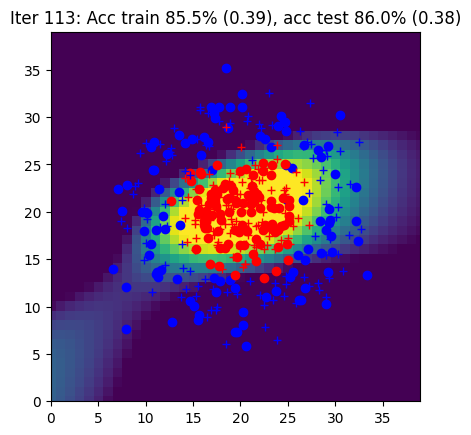

Iter 114: Acc train 85.5% (0.38), acc test 87.0% (0.37)


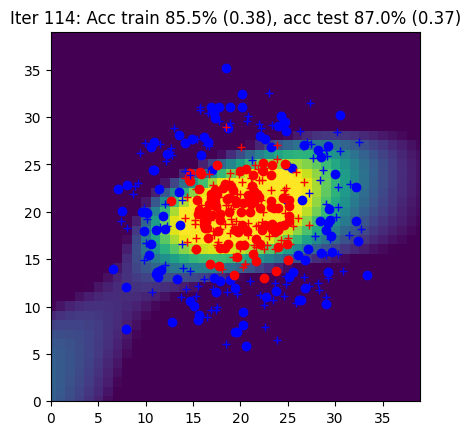

Iter 115: Acc train 86.5% (0.38), acc test 88.0% (0.37)


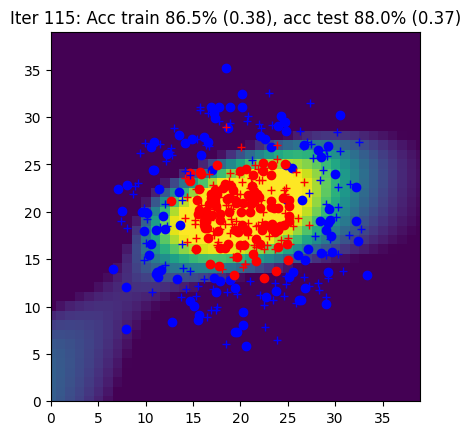

Iter 116: Acc train 88.0% (0.37), acc test 88.0% (0.37)


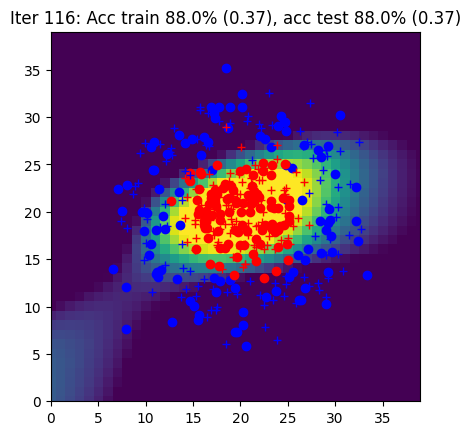

Iter 117: Acc train 87.5% (0.37), acc test 89.0% (0.36)


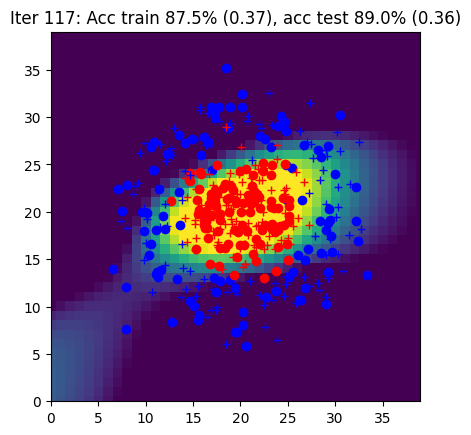

Iter 118: Acc train 88.5% (0.37), acc test 89.5% (0.36)


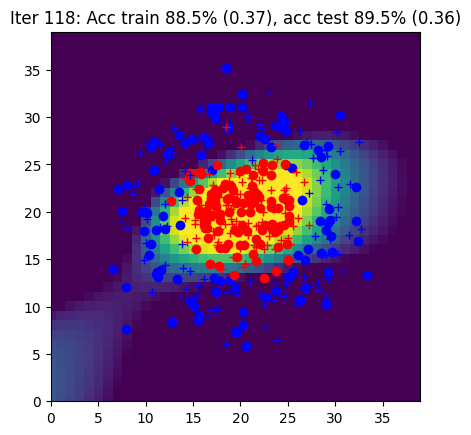

Iter 119: Acc train 89.0% (0.36), acc test 90.5% (0.35)


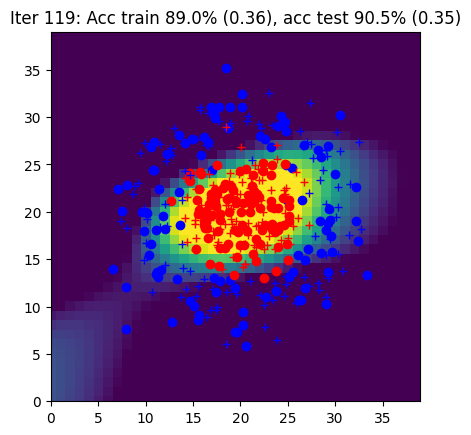

Iter 120: Acc train 89.5% (0.36), acc test 90.5% (0.35)


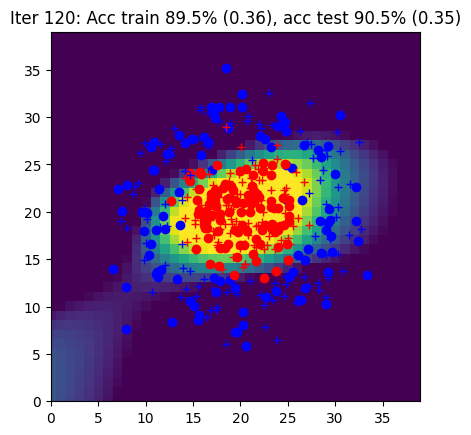

Iter 121: Acc train 89.5% (0.35), acc test 91.0% (0.34)


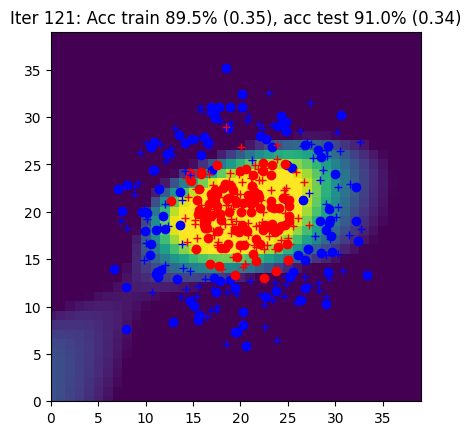

Iter 122: Acc train 89.5% (0.35), acc test 91.0% (0.34)


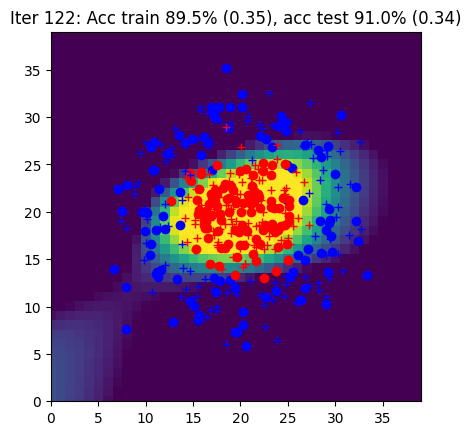

Iter 123: Acc train 91.0% (0.34), acc test 91.5% (0.34)


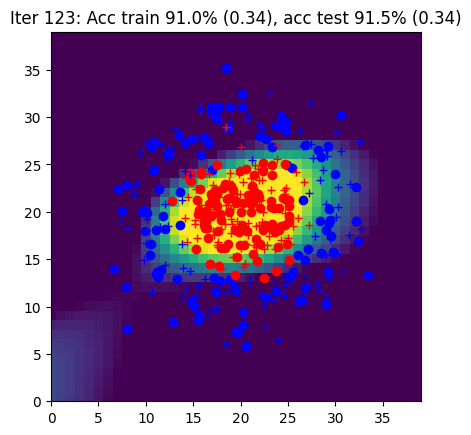

Iter 124: Acc train 91.0% (0.34), acc test 92.0% (0.33)


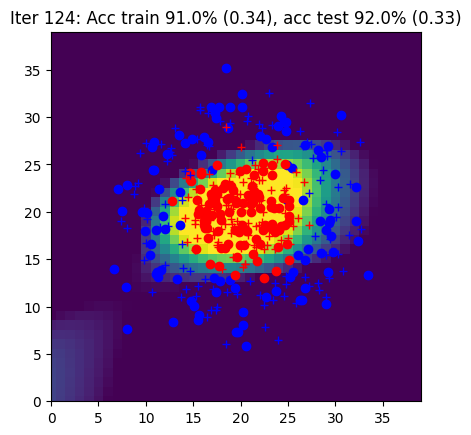

Iter 125: Acc train 91.0% (0.34), acc test 92.0% (0.33)


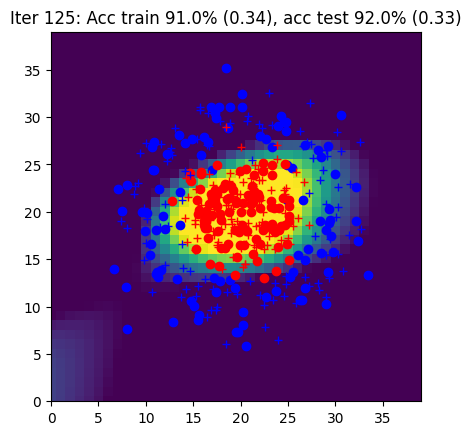

Iter 126: Acc train 91.0% (0.33), acc test 92.0% (0.32)


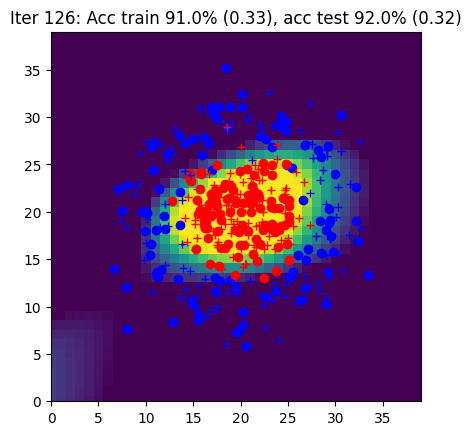

Iter 127: Acc train 91.5% (0.33), acc test 92.5% (0.32)


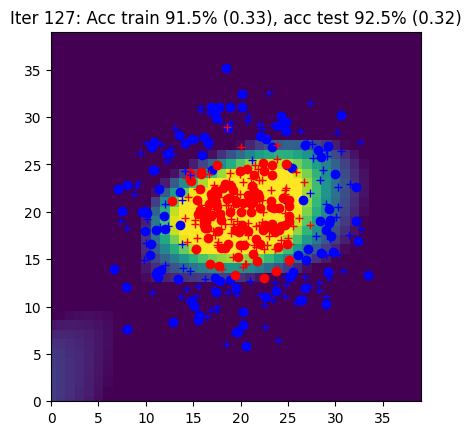

Iter 128: Acc train 91.5% (0.32), acc test 94.5% (0.32)


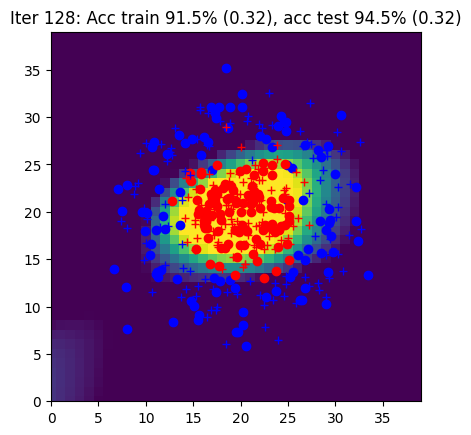

Iter 129: Acc train 92.0% (0.32), acc test 93.5% (0.31)


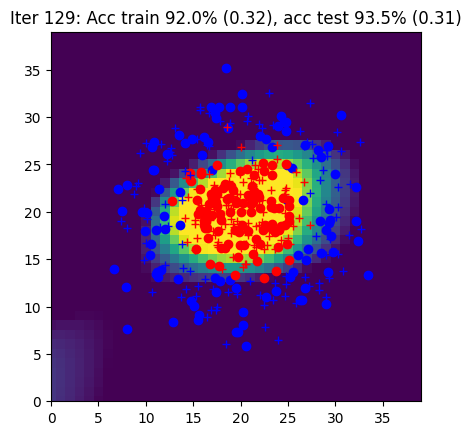

Iter 130: Acc train 91.5% (0.32), acc test 95.0% (0.31)


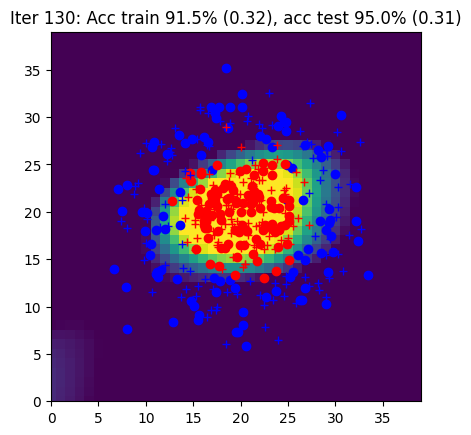

Iter 131: Acc train 92.0% (0.31), acc test 95.0% (0.30)


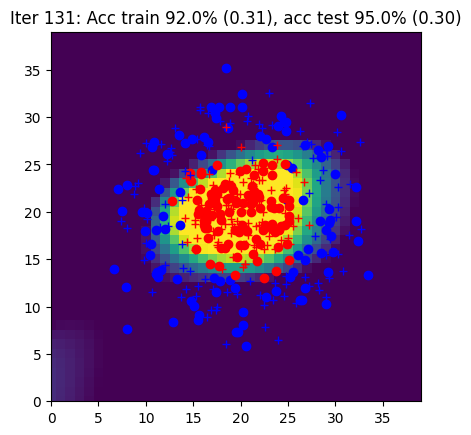

Iter 132: Acc train 92.0% (0.31), acc test 95.5% (0.30)


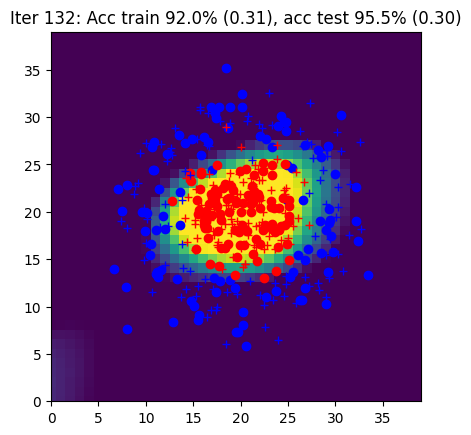

Iter 133: Acc train 92.0% (0.30), acc test 95.5% (0.30)


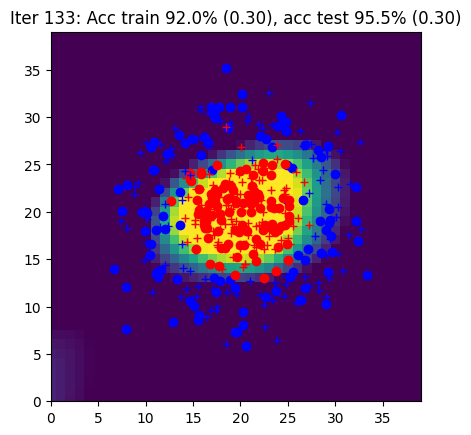

Iter 134: Acc train 92.0% (0.30), acc test 95.5% (0.29)


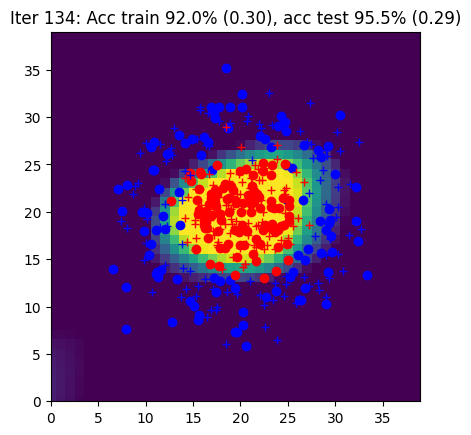

Iter 135: Acc train 92.0% (0.30), acc test 95.5% (0.29)


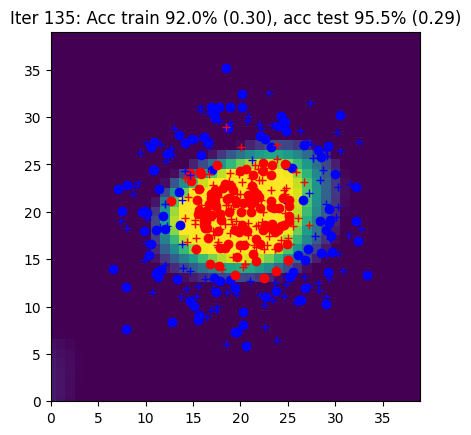

Iter 136: Acc train 92.0% (0.29), acc test 95.5% (0.29)


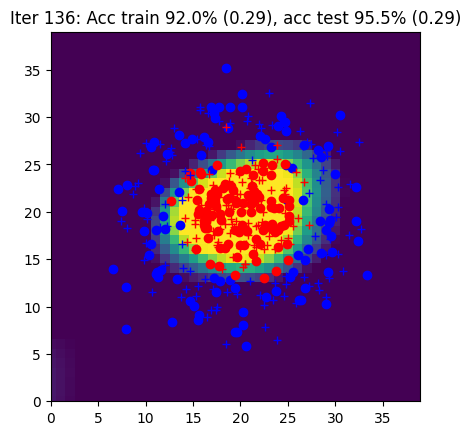

Iter 137: Acc train 92.5% (0.29), acc test 95.5% (0.28)


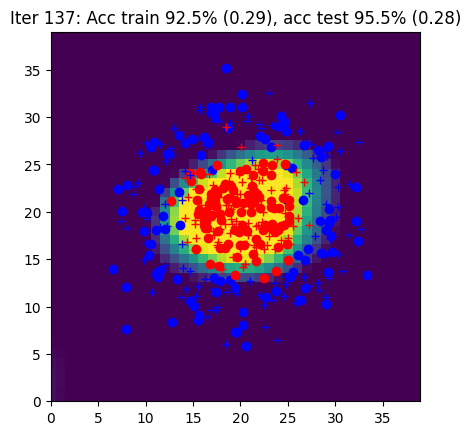

Iter 138: Acc train 94.0% (0.29), acc test 95.5% (0.28)


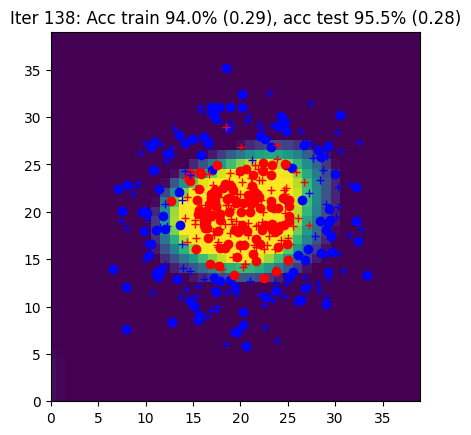

Iter 139: Acc train 93.0% (0.28), acc test 95.0% (0.28)


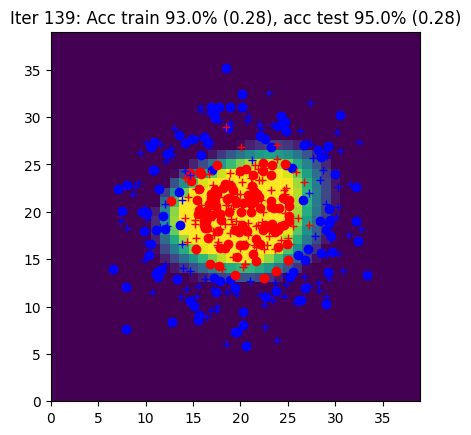

Iter 140: Acc train 94.0% (0.28), acc test 95.0% (0.27)


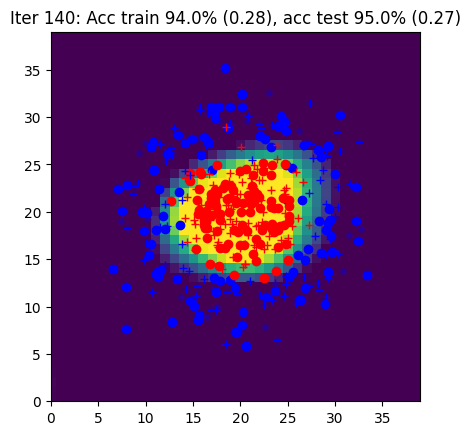

Iter 141: Acc train 93.0% (0.28), acc test 95.0% (0.27)


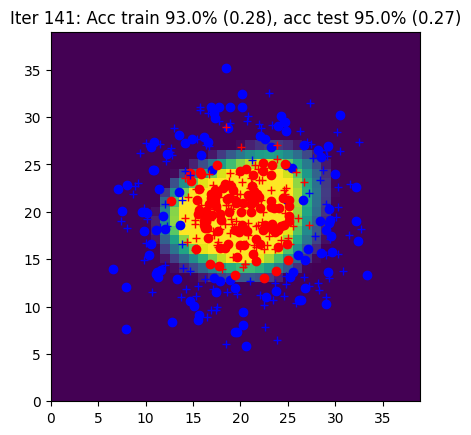

Iter 142: Acc train 94.5% (0.27), acc test 95.0% (0.27)


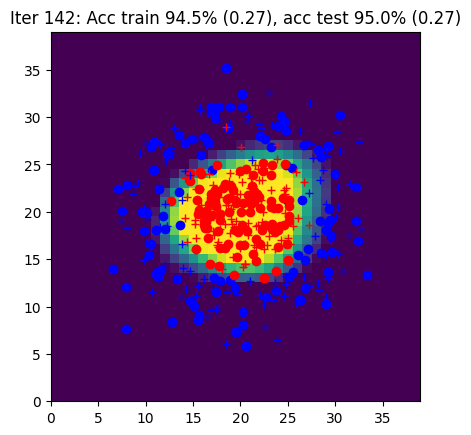

Iter 143: Acc train 94.5% (0.27), acc test 95.0% (0.27)


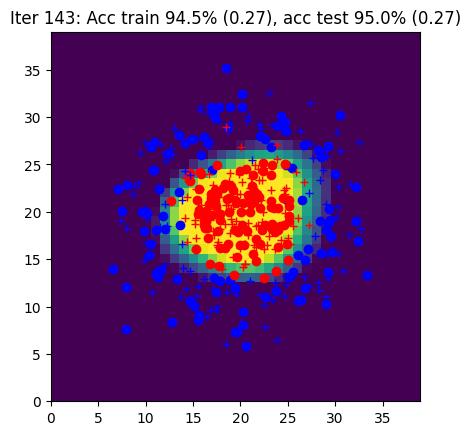

Iter 144: Acc train 94.5% (0.27), acc test 95.0% (0.26)


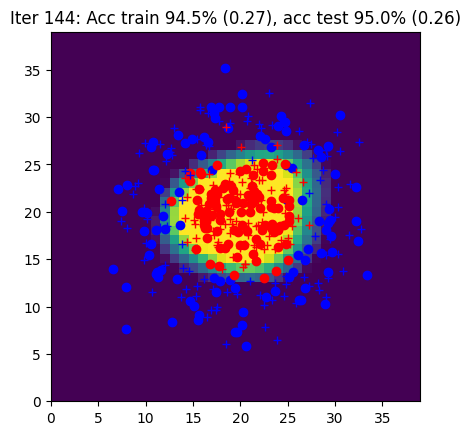

Iter 145: Acc train 94.0% (0.27), acc test 95.5% (0.26)


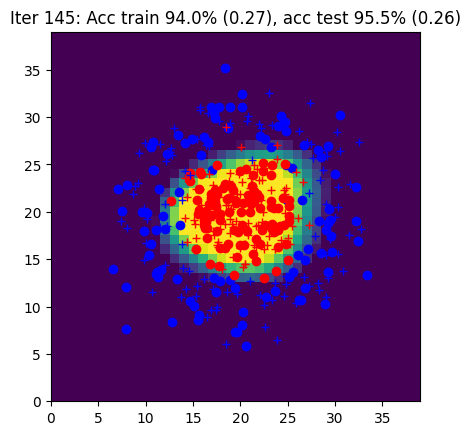

Iter 146: Acc train 94.5% (0.26), acc test 95.5% (0.26)


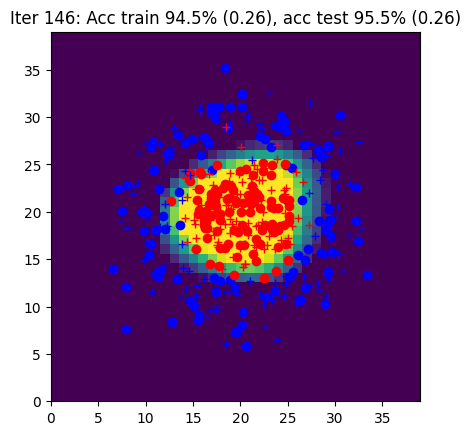

Iter 147: Acc train 94.0% (0.26), acc test 96.0% (0.26)


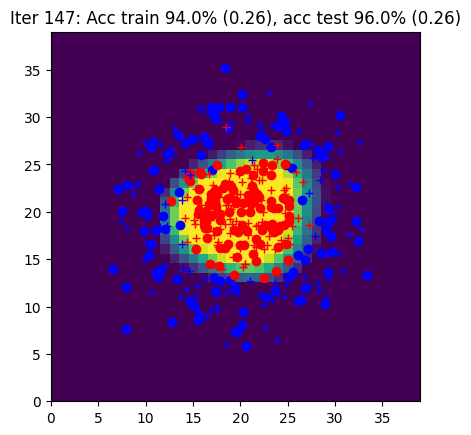

Iter 148: Acc train 94.0% (0.26), acc test 96.0% (0.25)


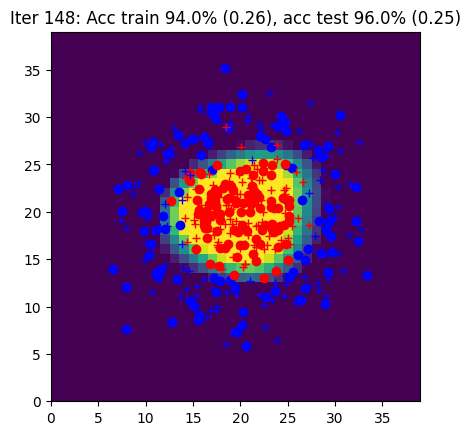

Iter 149: Acc train 94.5% (0.25), acc test 96.0% (0.25)


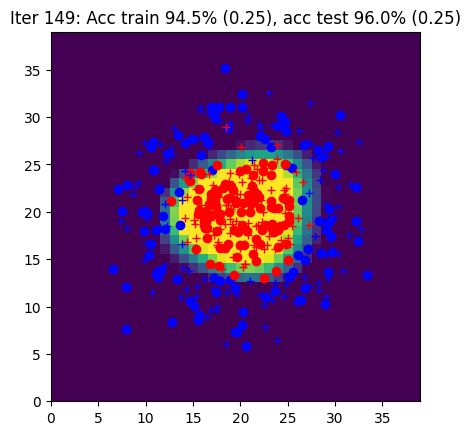

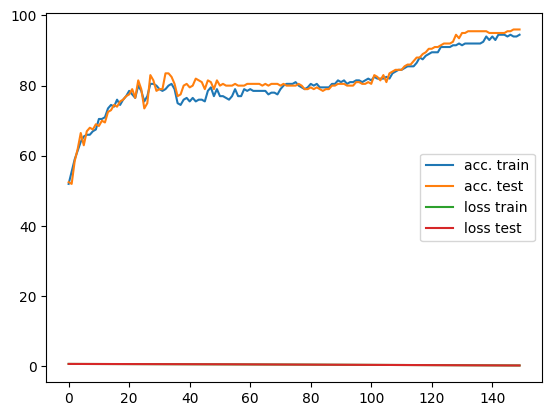

In [11]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

params = init_params(nx, nh, ny)

curves = [[],[], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j+1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: forward, loss_accuracy, sgd
        # and the backward function with autograd
        Yhat, _ = forward(params, X)
        L = -torch.sum(Y * torch.log(Yhat + 1e-15)) / Nbatch
        L.backward()
        params = sgd(params, eta)

    ####################
    ##      END        #
    ####################


    Yhat_train, _ = forward(params, data.Xtrain)
    Yhat_test, _ = forward(params, data.Xtest)
    Ltrain, acctrain = loss_accuracy(Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(Yhat_test, data.Ytest)
    Ygrid, _ = forward(params, data.Xgrid)

    title = 'Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})'.format(iteration, acctrain, Ltrain, acctest, Ltest)
    print(title)
    # detach() is used to remove the predictions from the computational graph in autograd
    data.plot_data_with_grid(Ygrid.detach(), title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 3 : Simplification of the forward pass with `torch.nn`

`init_params` and `forward` are replaced by the `init_model` function which defines the network architecture and the loss.

In [12]:
def init_model(nx, nh, ny):

    #####################
    ## Your code here  ##
    #####################

    model = torch.nn.Sequential(
        torch.nn.Linear(nx, nh),
        torch.nn.Tanh(),
        torch.nn.Linear(nh, ny)
    )
    loss = torch.nn.CrossEntropyLoss()

    ####################
    ##      END        #
    ####################

    return model, loss

In [13]:
def loss_accuracy(loss, Yhat, Y):

    #####################
    ## Your code here  ##
    #####################
    # call the loss function

    L = loss(Yhat, Y).item()
    acc = 100.0 * torch.sum(torch.argmax(Yhat, dim=1) == torch.argmax(Y, dim=1)).item() / Y.size(0)

    ####################
    ##      END        #
    ####################

    return L, acc

In [14]:
def sgd(model, eta):

    #####################
    ## Your code here  ##
    #####################
    # update the network weights
    # warning: use torch.no_grad()
    # and reset to zero the gradient accumulators
    with torch.no_grad():
        for param in model.parameters():
            param -= eta * param.grad
            param.grad.zero_()


    ####################
    ##      END        #
    ####################
    return model

## Global learning procedure with autograd and `torch.nn`

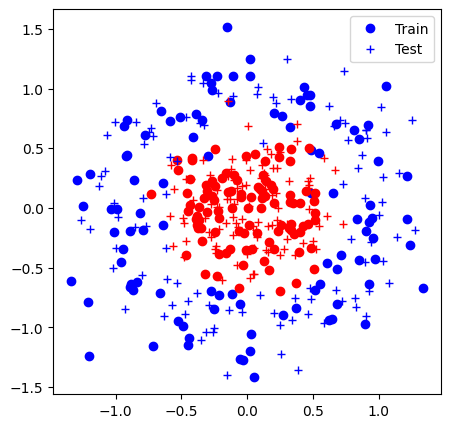

Iter 0: Acc train 50.0% (0.72), acc test 50.0% (0.73)


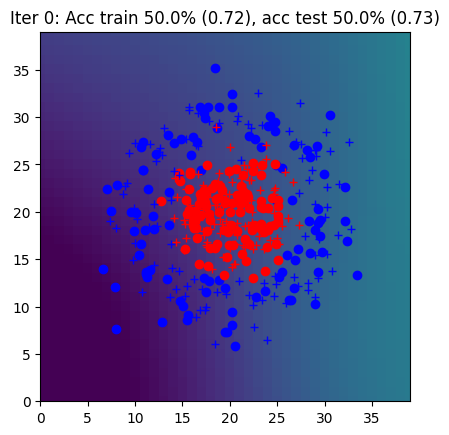

Iter 1: Acc train 48.5% (0.69), acc test 48.5% (0.69)


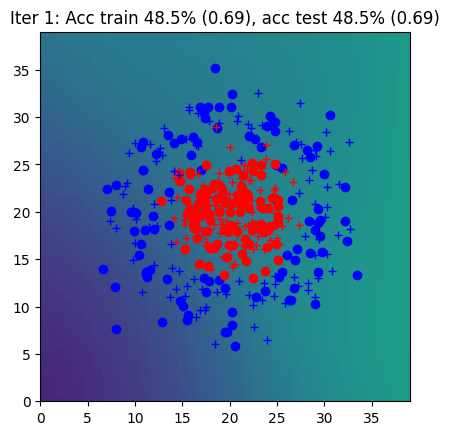

Iter 2: Acc train 42.5% (0.69), acc test 40.0% (0.69)


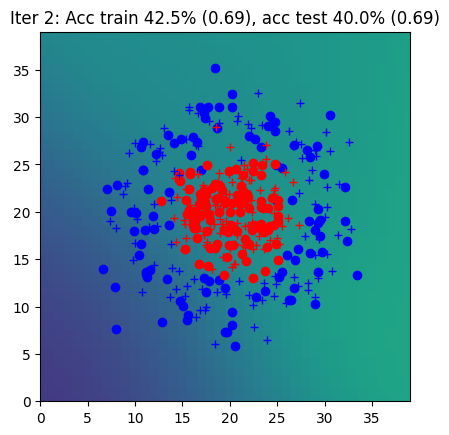

Iter 3: Acc train 51.5% (0.68), acc test 53.5% (0.69)


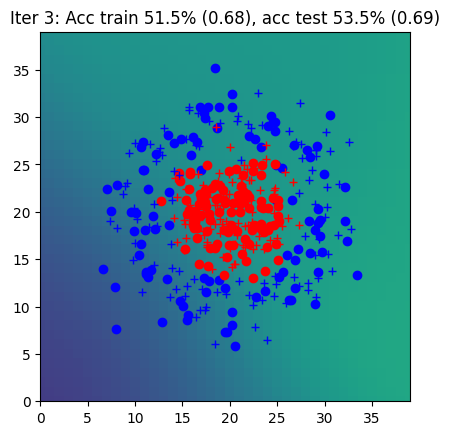

Iter 4: Acc train 66.5% (0.68), acc test 62.5% (0.69)


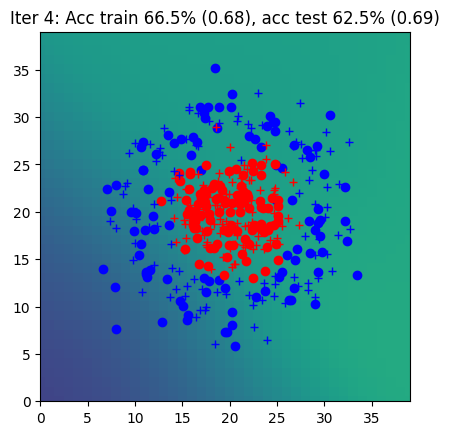

Iter 5: Acc train 66.0% (0.68), acc test 62.5% (0.68)


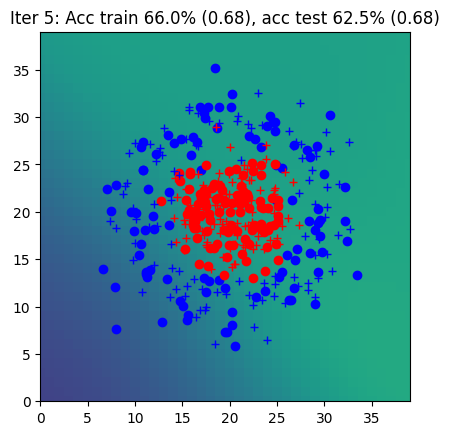

Iter 6: Acc train 65.5% (0.68), acc test 62.5% (0.68)


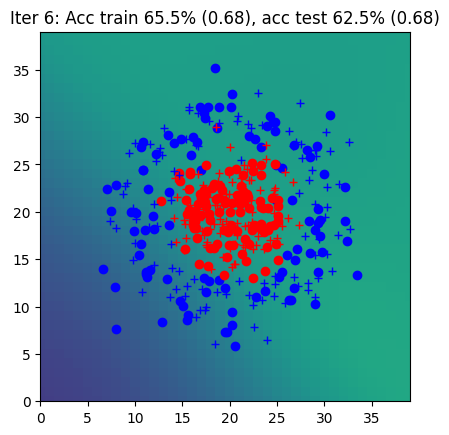

Iter 7: Acc train 66.0% (0.68), acc test 63.0% (0.68)


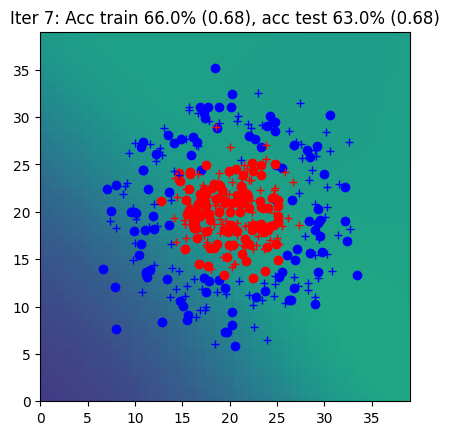

Iter 8: Acc train 65.0% (0.68), acc test 62.0% (0.68)


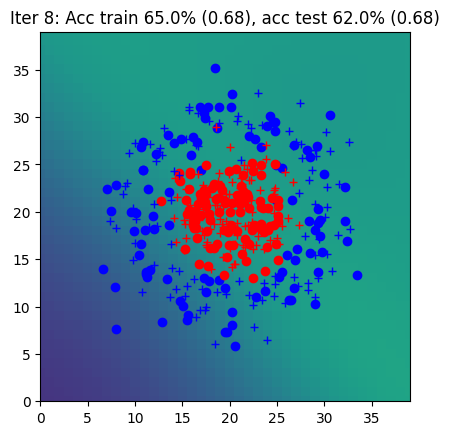

Iter 9: Acc train 66.0% (0.68), acc test 64.0% (0.68)


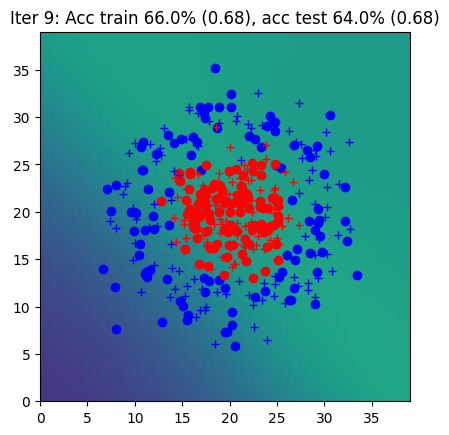

Iter 10: Acc train 66.0% (0.68), acc test 64.0% (0.68)


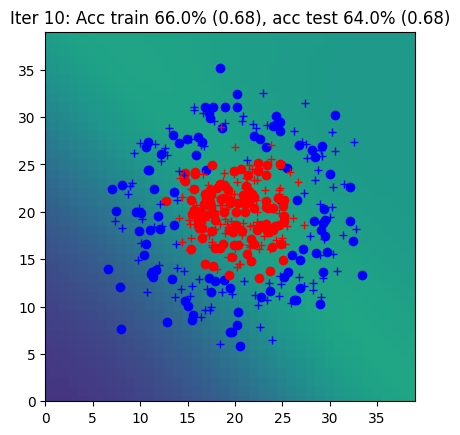

Iter 11: Acc train 66.0% (0.67), acc test 64.0% (0.68)


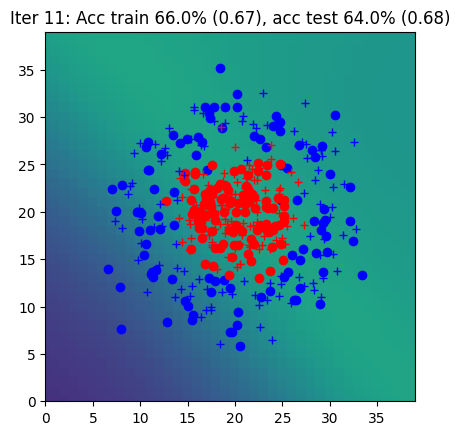

Iter 12: Acc train 66.0% (0.67), acc test 64.0% (0.68)


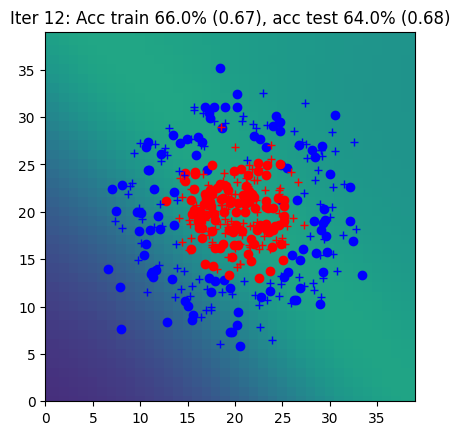

Iter 13: Acc train 66.0% (0.67), acc test 64.0% (0.67)


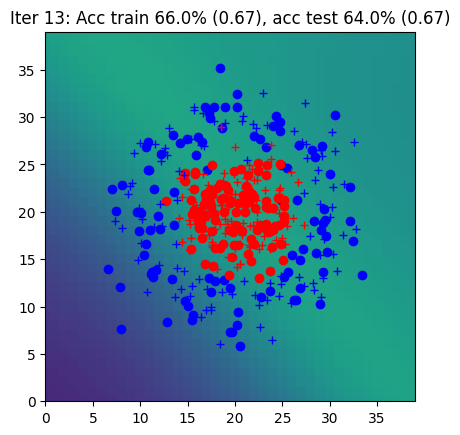

Iter 14: Acc train 66.0% (0.67), acc test 64.0% (0.67)


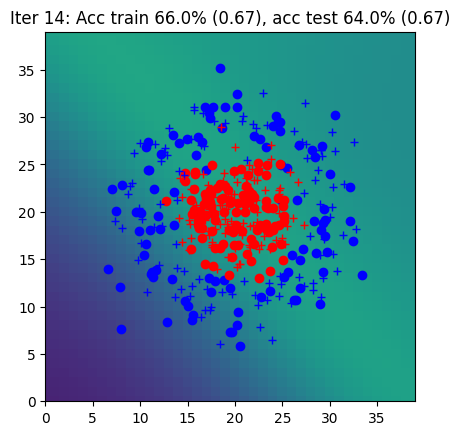

Iter 15: Acc train 66.0% (0.67), acc test 64.5% (0.67)


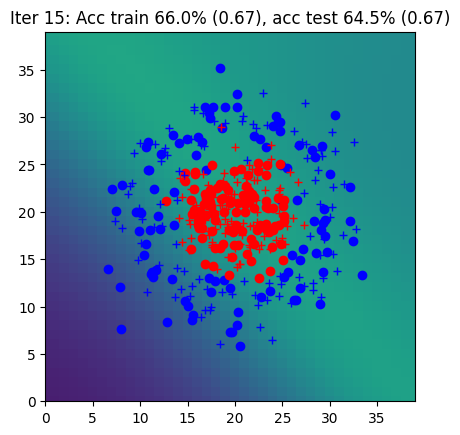

Iter 16: Acc train 67.0% (0.67), acc test 65.5% (0.67)


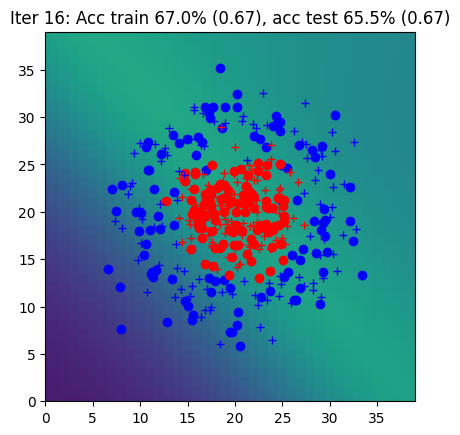

Iter 17: Acc train 68.0% (0.66), acc test 68.0% (0.67)


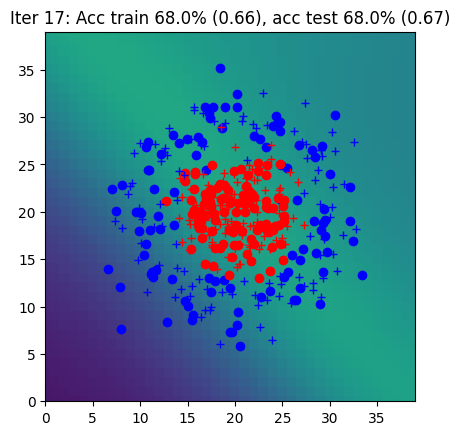

Iter 18: Acc train 67.0% (0.66), acc test 67.0% (0.67)


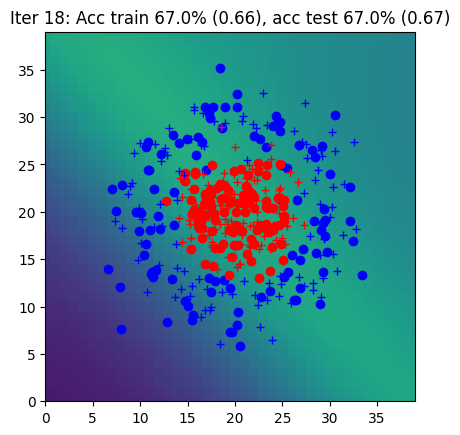

Iter 19: Acc train 66.5% (0.66), acc test 66.5% (0.66)


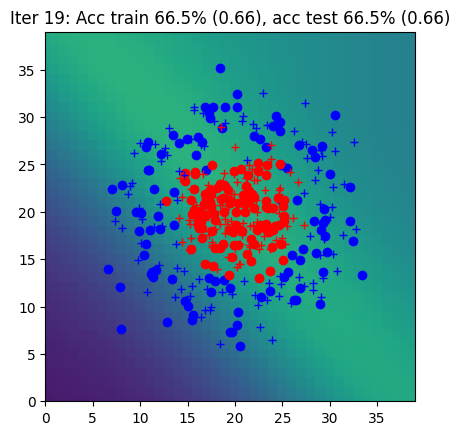

Iter 20: Acc train 67.5% (0.66), acc test 68.0% (0.66)


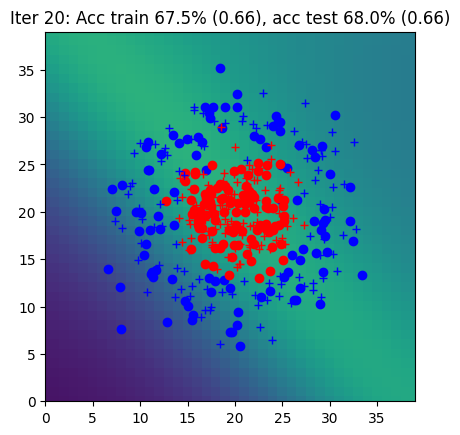

Iter 21: Acc train 69.0% (0.65), acc test 71.0% (0.66)


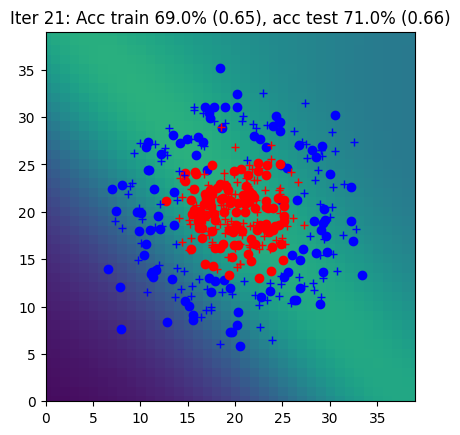

Iter 22: Acc train 71.5% (0.65), acc test 74.0% (0.66)


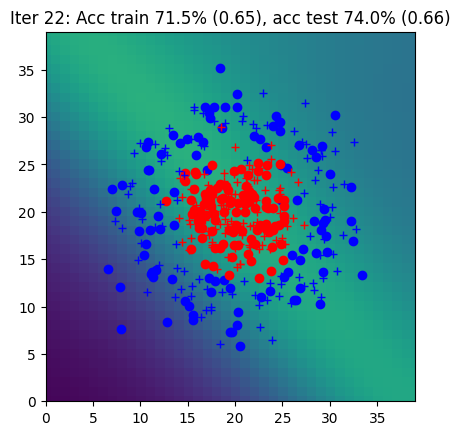

Iter 23: Acc train 73.5% (0.65), acc test 75.5% (0.66)


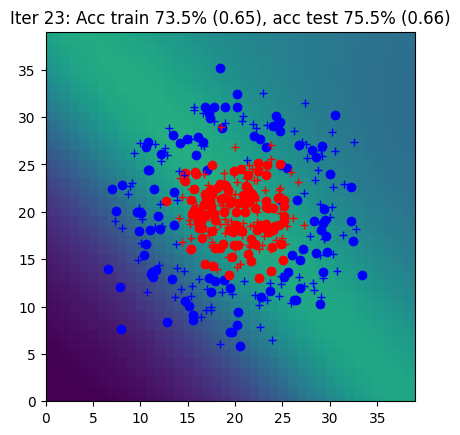

Iter 24: Acc train 73.5% (0.65), acc test 74.0% (0.65)


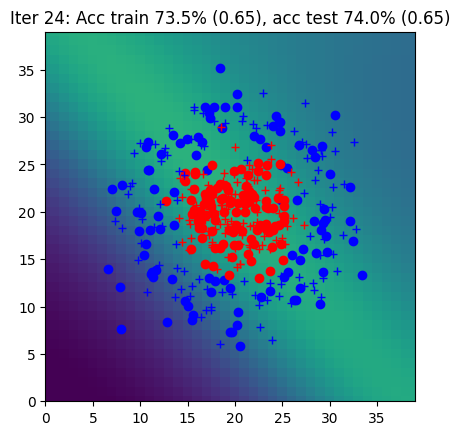

Iter 25: Acc train 72.5% (0.64), acc test 74.0% (0.65)


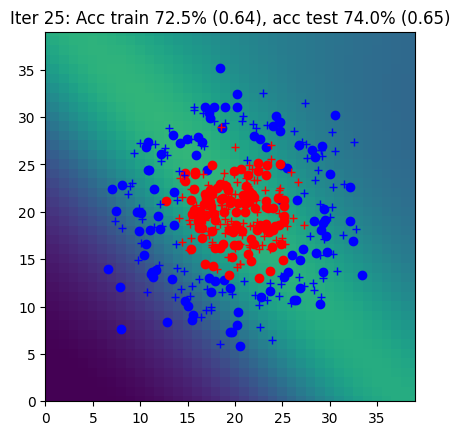

Iter 26: Acc train 74.0% (0.64), acc test 76.0% (0.65)


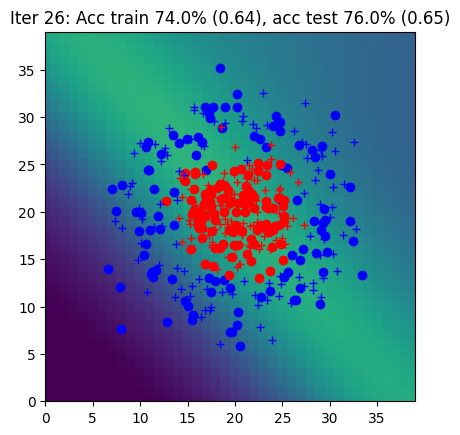

Iter 27: Acc train 75.5% (0.64), acc test 74.0% (0.65)


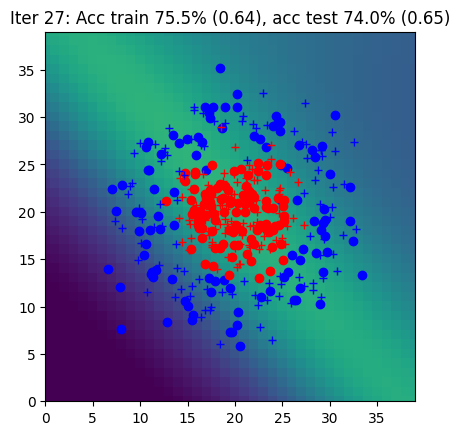

Iter 28: Acc train 74.0% (0.64), acc test 75.5% (0.64)


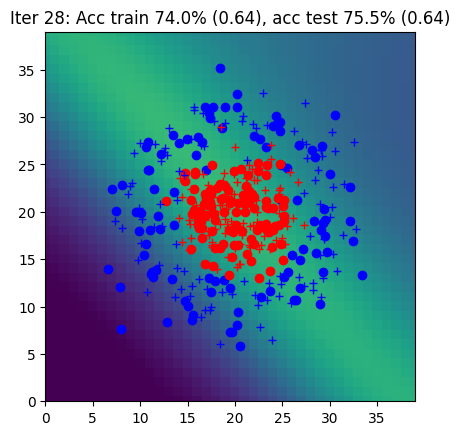

Iter 29: Acc train 76.0% (0.63), acc test 76.0% (0.64)


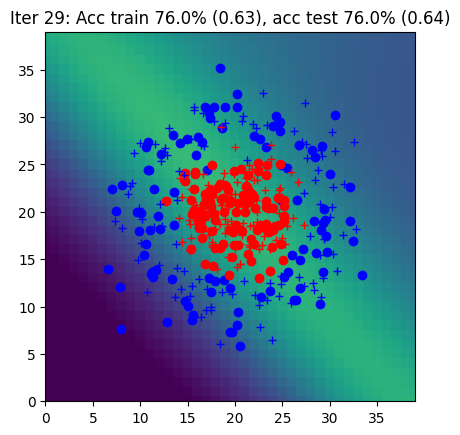

Iter 30: Acc train 77.5% (0.63), acc test 76.0% (0.64)


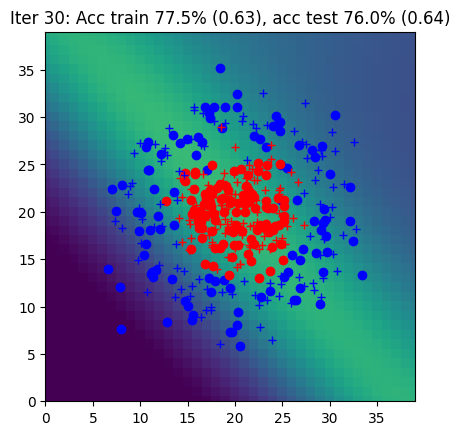

Iter 31: Acc train 78.0% (0.63), acc test 76.5% (0.63)


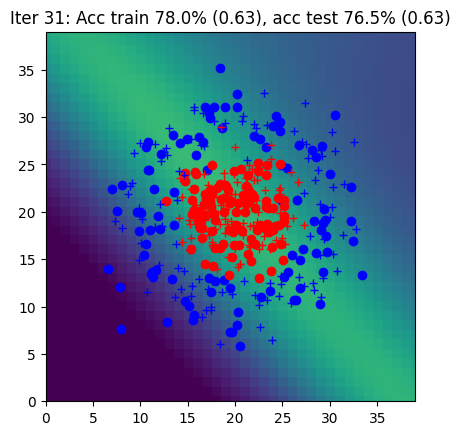

Iter 32: Acc train 77.0% (0.62), acc test 76.5% (0.63)


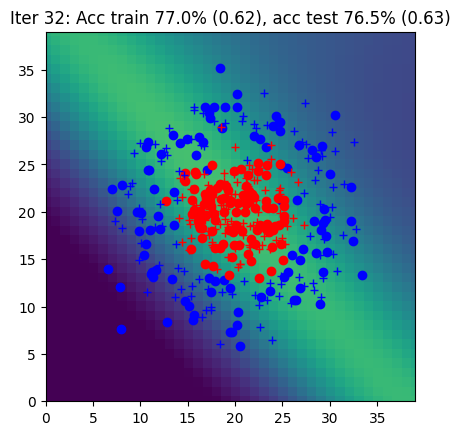

Iter 33: Acc train 78.5% (0.62), acc test 76.0% (0.63)


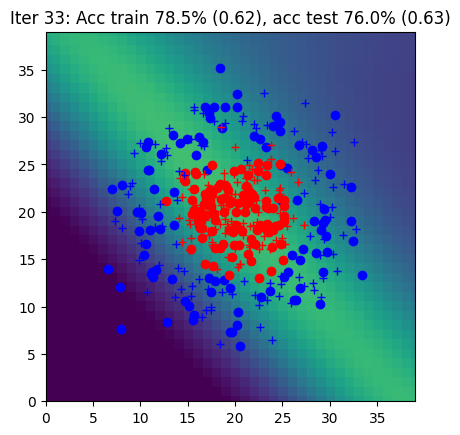

Iter 34: Acc train 78.0% (0.62), acc test 77.0% (0.63)


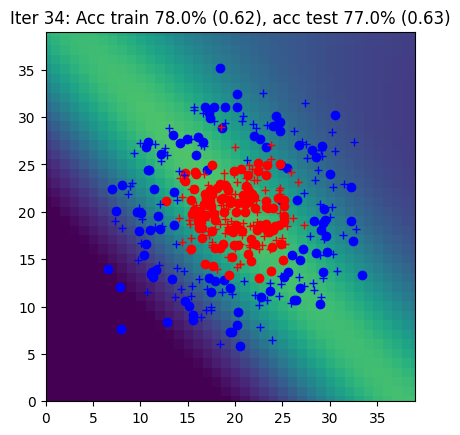

Iter 35: Acc train 79.0% (0.61), acc test 76.5% (0.62)


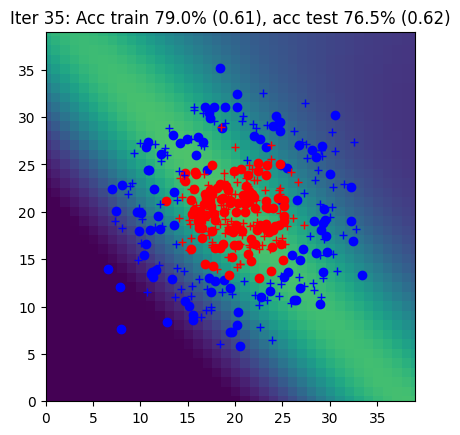

Iter 36: Acc train 79.0% (0.61), acc test 76.5% (0.62)


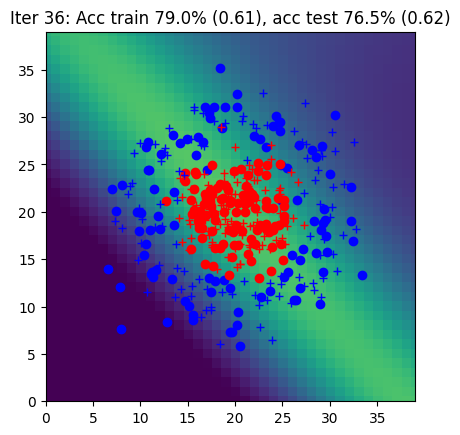

Iter 37: Acc train 78.0% (0.60), acc test 76.5% (0.62)


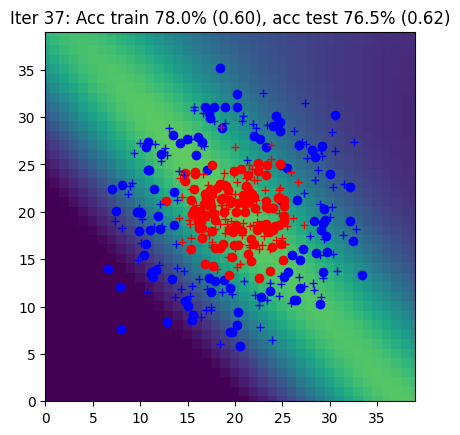

Iter 38: Acc train 77.0% (0.60), acc test 76.5% (0.61)


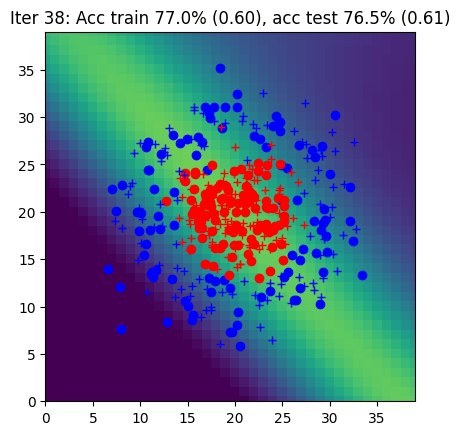

Iter 39: Acc train 80.0% (0.60), acc test 76.5% (0.61)


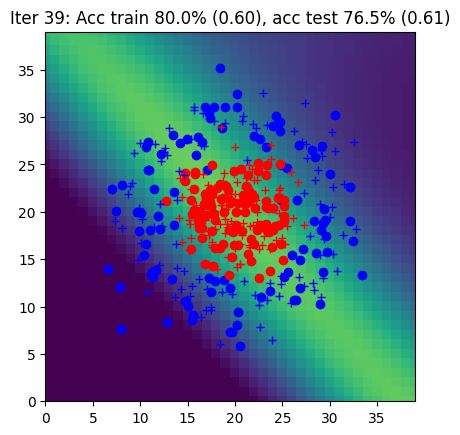

Iter 40: Acc train 80.5% (0.59), acc test 76.5% (0.61)


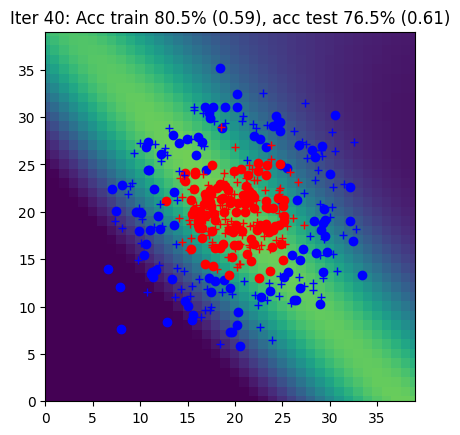

Iter 41: Acc train 80.5% (0.59), acc test 76.5% (0.60)


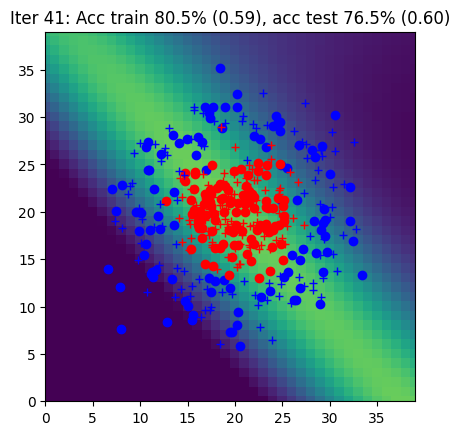

Iter 42: Acc train 81.0% (0.58), acc test 76.5% (0.60)


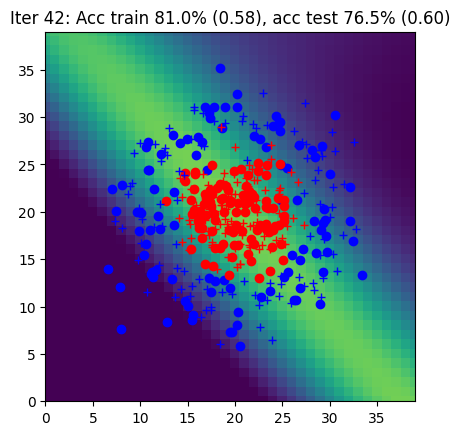

Iter 43: Acc train 81.0% (0.58), acc test 76.5% (0.60)


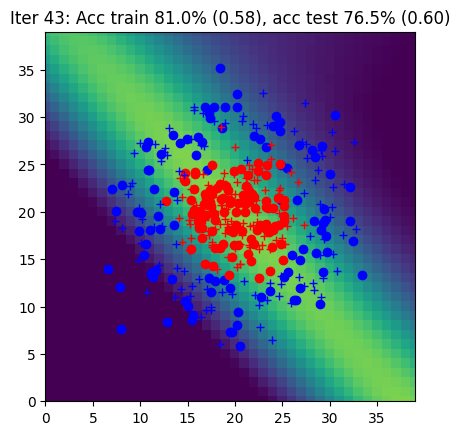

Iter 44: Acc train 81.0% (0.58), acc test 76.5% (0.59)


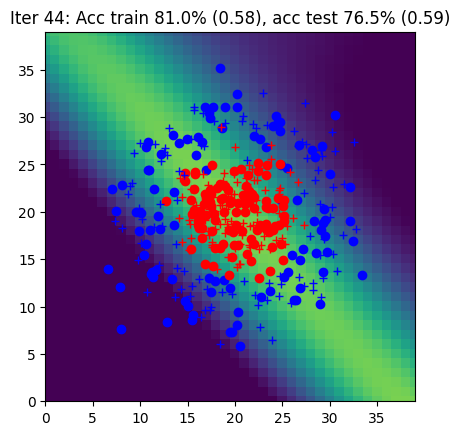

Iter 45: Acc train 80.5% (0.57), acc test 77.0% (0.59)


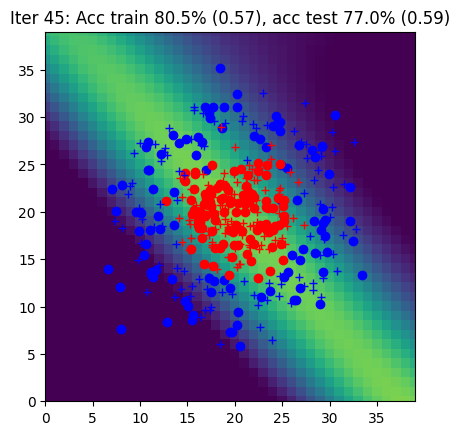

Iter 46: Acc train 80.5% (0.57), acc test 76.0% (0.59)


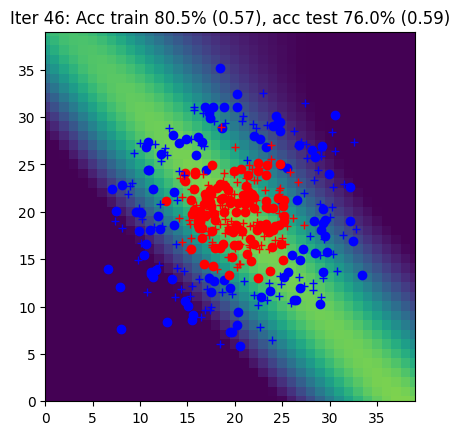

Iter 47: Acc train 81.5% (0.56), acc test 76.5% (0.58)


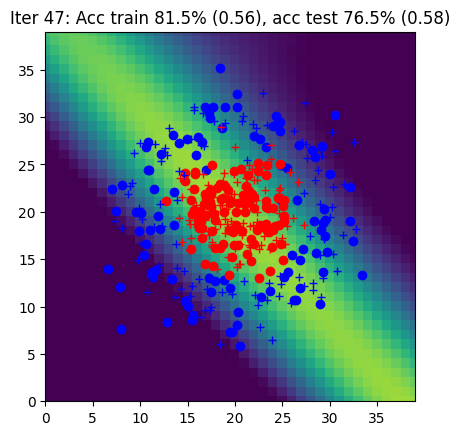

Iter 48: Acc train 81.5% (0.56), acc test 77.0% (0.58)


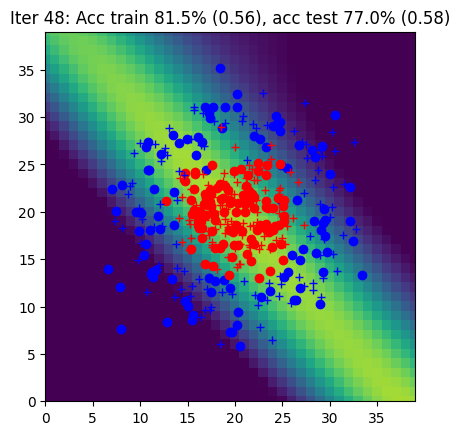

Iter 49: Acc train 81.5% (0.56), acc test 75.0% (0.58)


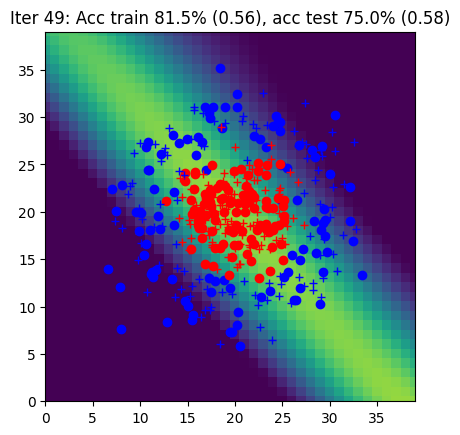

Iter 50: Acc train 80.5% (0.55), acc test 77.0% (0.57)


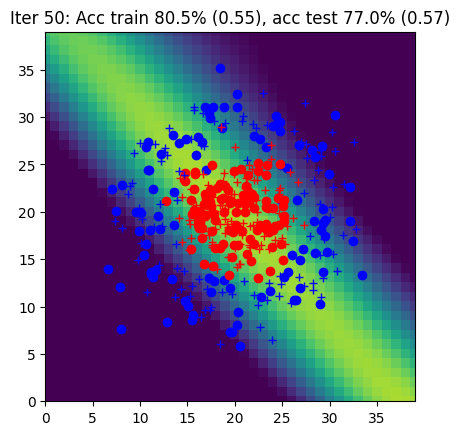

Iter 51: Acc train 81.5% (0.55), acc test 75.0% (0.57)


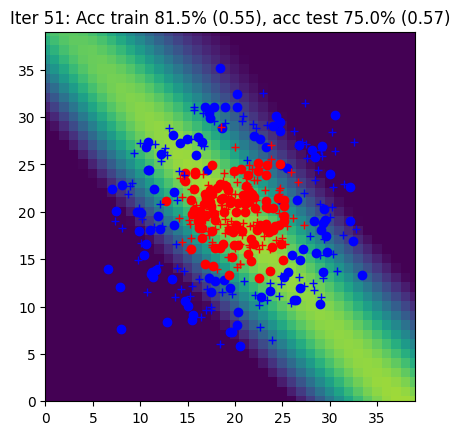

Iter 52: Acc train 80.5% (0.54), acc test 76.0% (0.57)


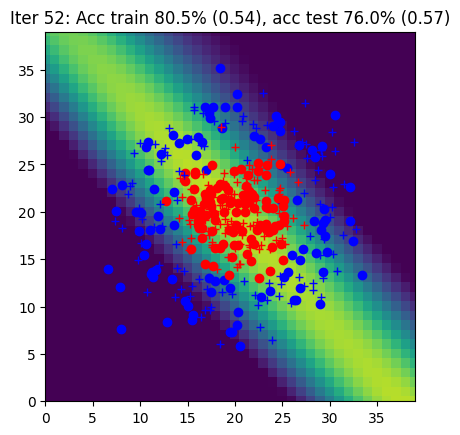

Iter 53: Acc train 81.0% (0.54), acc test 77.0% (0.56)


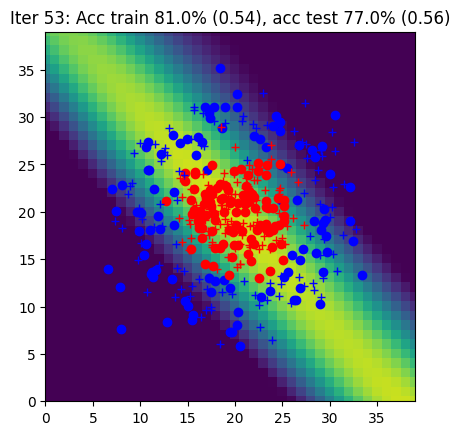

Iter 54: Acc train 81.0% (0.54), acc test 76.5% (0.56)


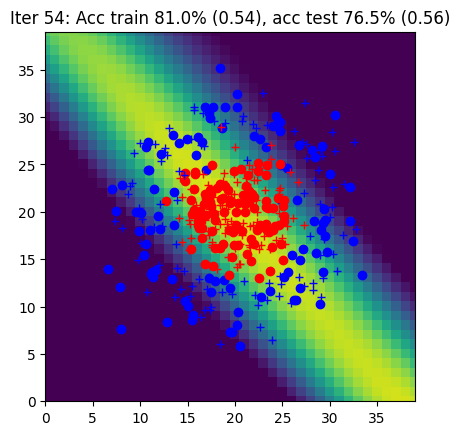

Iter 55: Acc train 81.5% (0.53), acc test 75.5% (0.56)


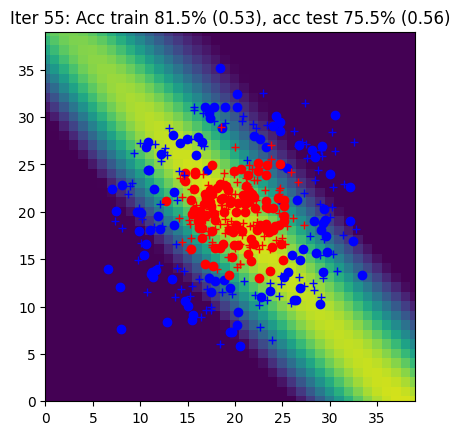

Iter 56: Acc train 81.0% (0.53), acc test 77.0% (0.55)


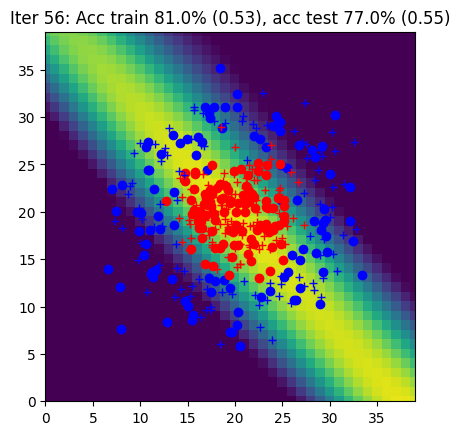

Iter 57: Acc train 81.0% (0.53), acc test 76.5% (0.55)


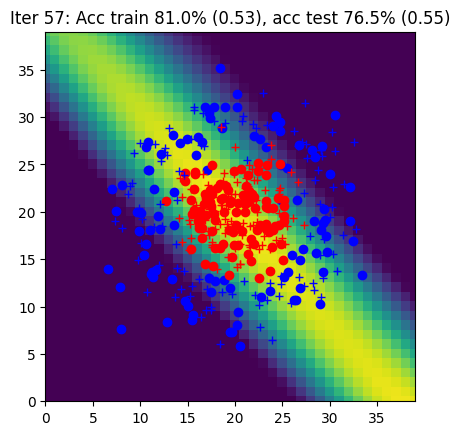

Iter 58: Acc train 81.0% (0.52), acc test 77.0% (0.55)


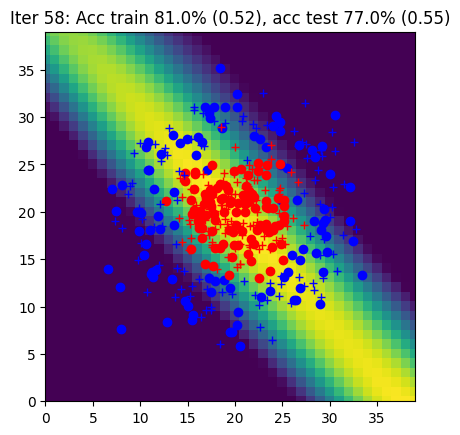

Iter 59: Acc train 81.5% (0.52), acc test 75.0% (0.55)


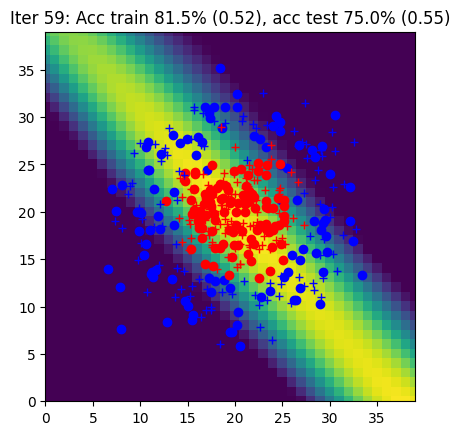

Iter 60: Acc train 81.5% (0.52), acc test 74.5% (0.54)


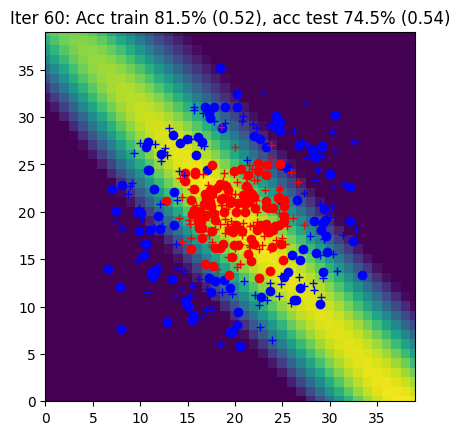

Iter 61: Acc train 81.5% (0.51), acc test 75.5% (0.54)


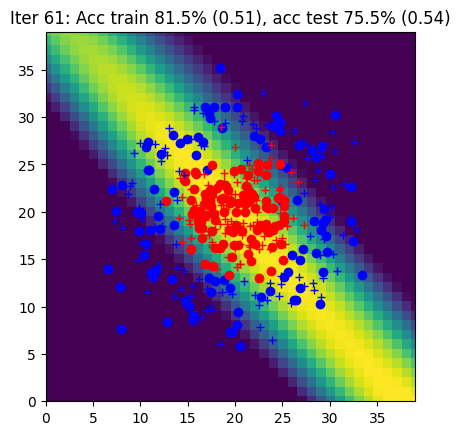

Iter 62: Acc train 82.5% (0.51), acc test 75.0% (0.54)


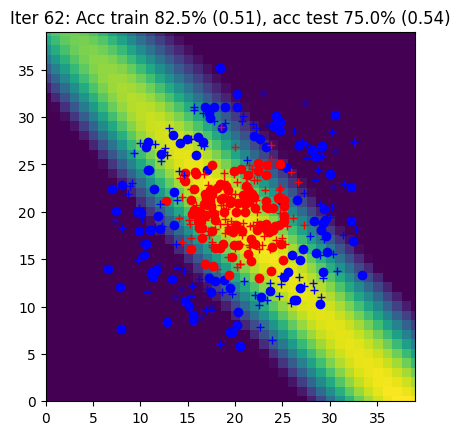

Iter 63: Acc train 81.5% (0.51), acc test 74.5% (0.54)


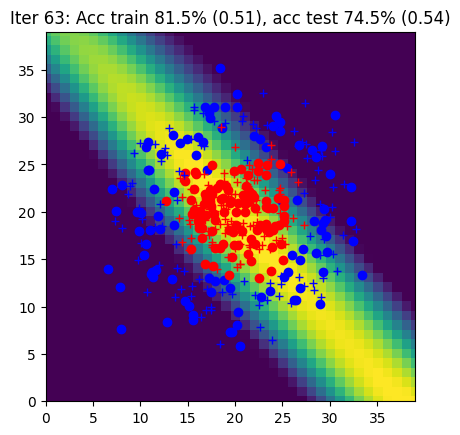

Iter 64: Acc train 82.5% (0.50), acc test 75.0% (0.53)


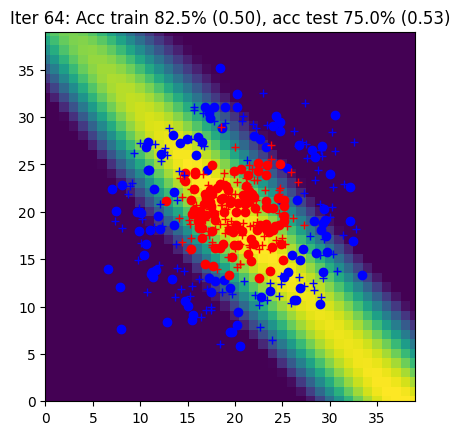

Iter 65: Acc train 82.5% (0.50), acc test 75.5% (0.53)


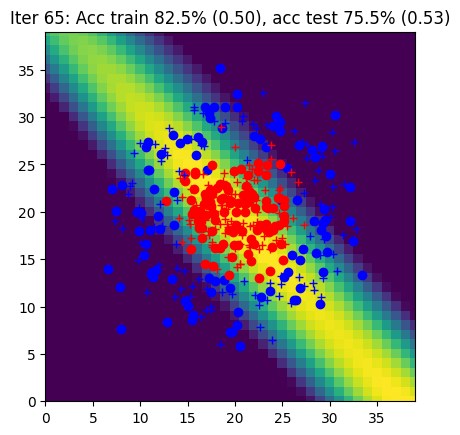

Iter 66: Acc train 81.5% (0.50), acc test 74.5% (0.53)


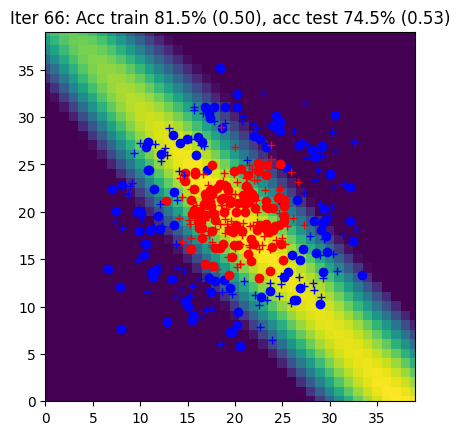

Iter 67: Acc train 82.0% (0.49), acc test 74.0% (0.53)


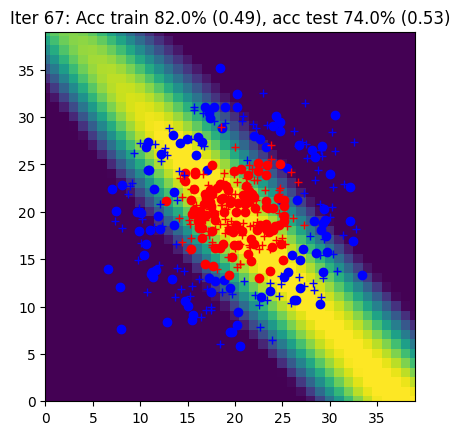

Iter 68: Acc train 82.5% (0.49), acc test 75.0% (0.53)


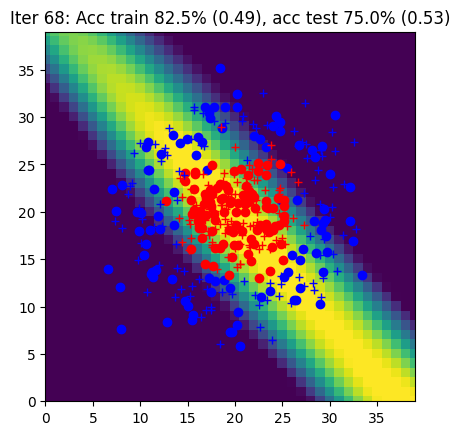

Iter 69: Acc train 82.5% (0.49), acc test 75.0% (0.52)


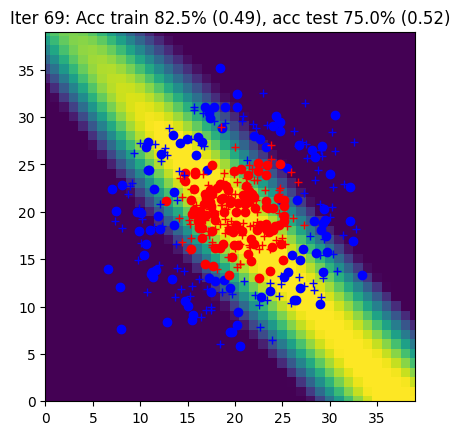

Iter 70: Acc train 82.5% (0.49), acc test 75.5% (0.52)


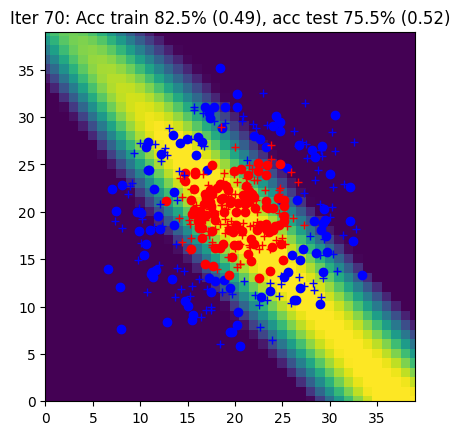

Iter 71: Acc train 82.5% (0.48), acc test 75.0% (0.52)


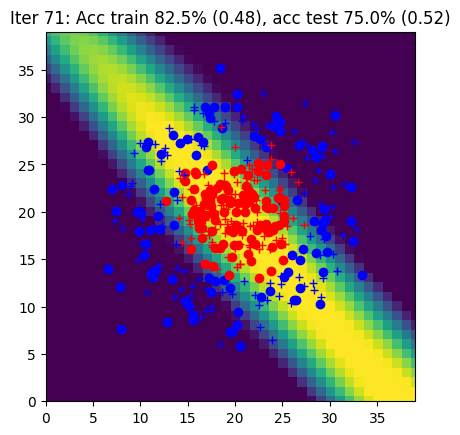

Iter 72: Acc train 82.0% (0.48), acc test 75.5% (0.52)


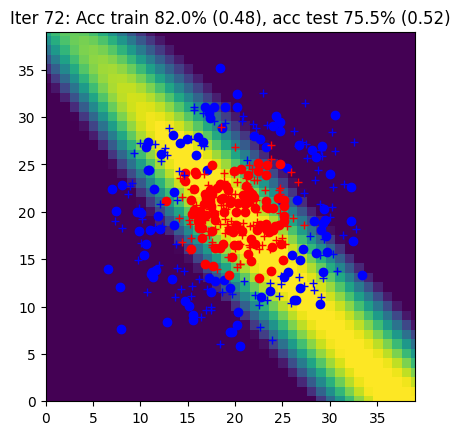

Iter 73: Acc train 82.5% (0.48), acc test 75.5% (0.52)


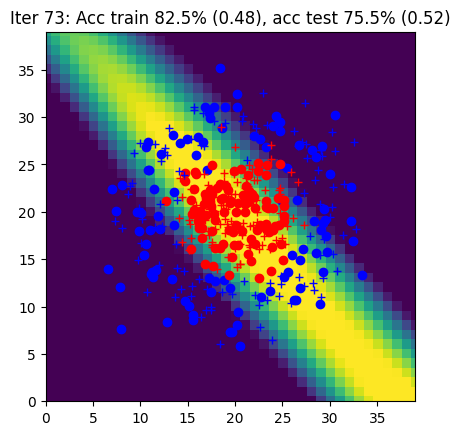

Iter 74: Acc train 82.5% (0.48), acc test 75.5% (0.51)


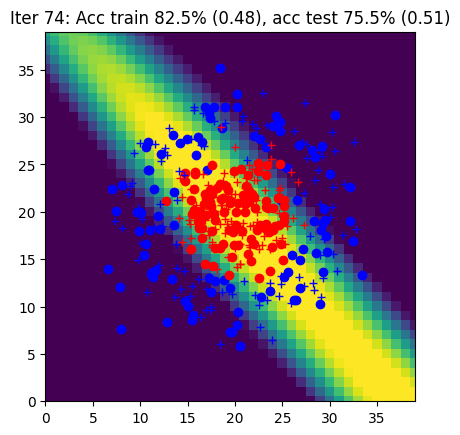

Iter 75: Acc train 82.5% (0.47), acc test 74.5% (0.51)


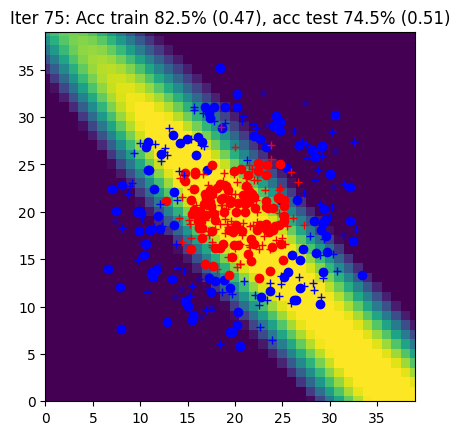

Iter 76: Acc train 82.5% (0.47), acc test 76.0% (0.51)


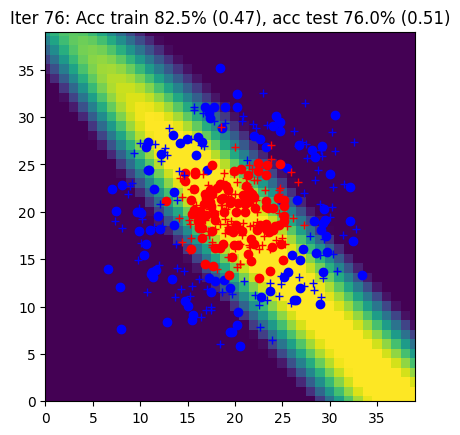

Iter 77: Acc train 81.0% (0.47), acc test 75.0% (0.51)


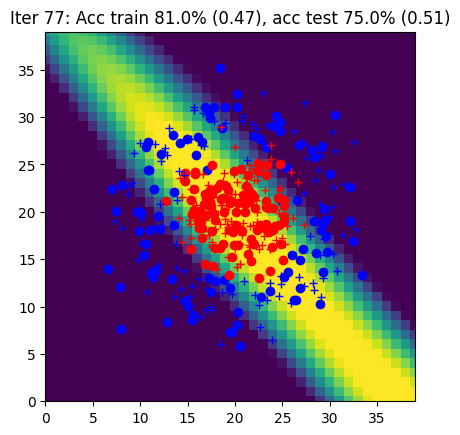

Iter 78: Acc train 82.0% (0.47), acc test 76.0% (0.51)


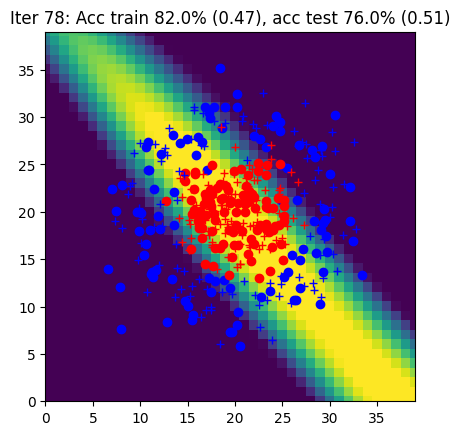

Iter 79: Acc train 82.5% (0.46), acc test 76.0% (0.51)


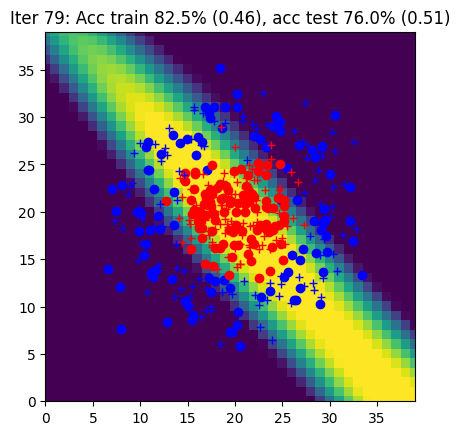

Iter 80: Acc train 82.0% (0.46), acc test 76.0% (0.50)


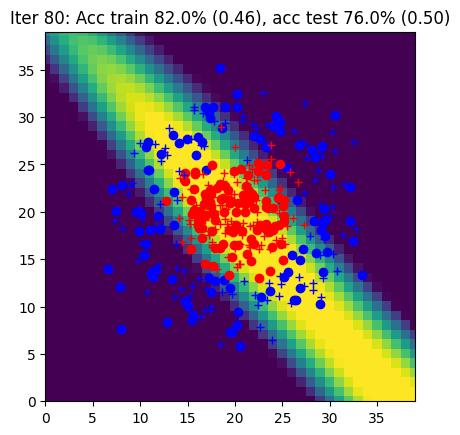

Iter 81: Acc train 81.0% (0.46), acc test 75.0% (0.50)


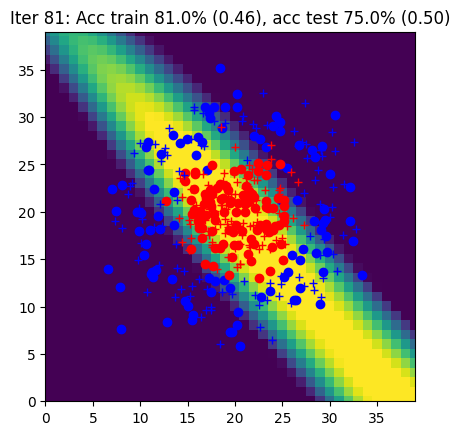

Iter 82: Acc train 82.5% (0.46), acc test 76.0% (0.50)


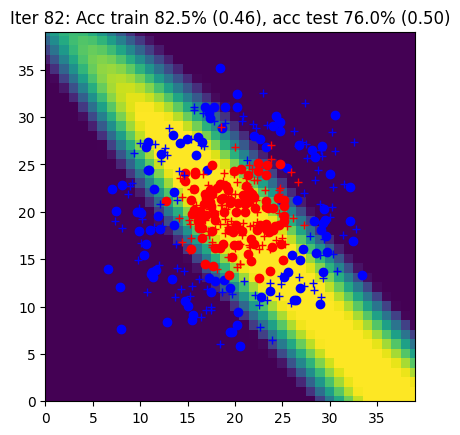

Iter 83: Acc train 82.0% (0.46), acc test 76.0% (0.50)


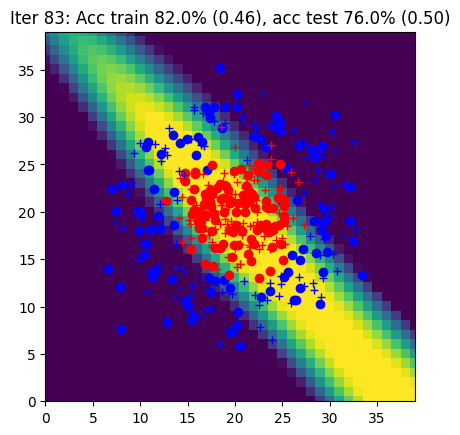

Iter 84: Acc train 82.5% (0.45), acc test 76.0% (0.50)


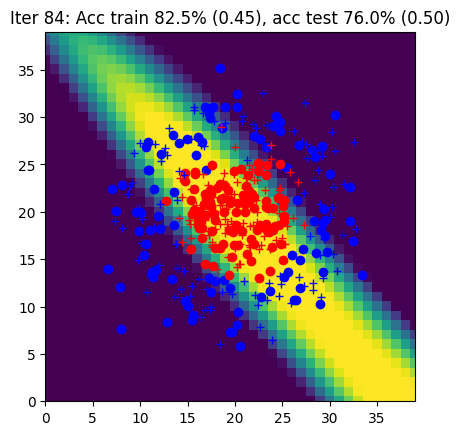

Iter 85: Acc train 82.0% (0.45), acc test 76.0% (0.49)


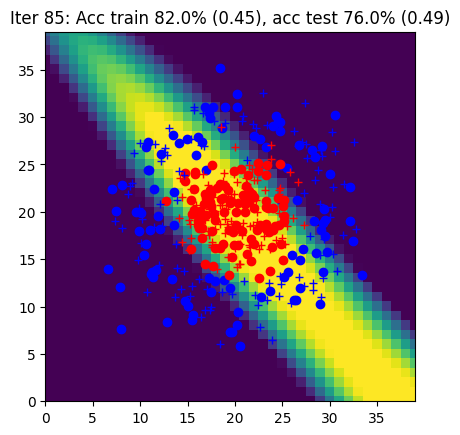

Iter 86: Acc train 82.0% (0.45), acc test 76.0% (0.49)


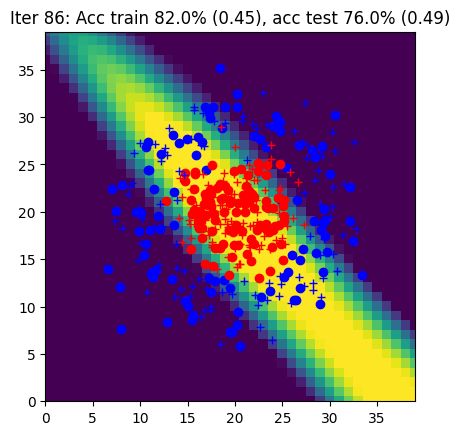

Iter 87: Acc train 82.0% (0.45), acc test 76.5% (0.49)


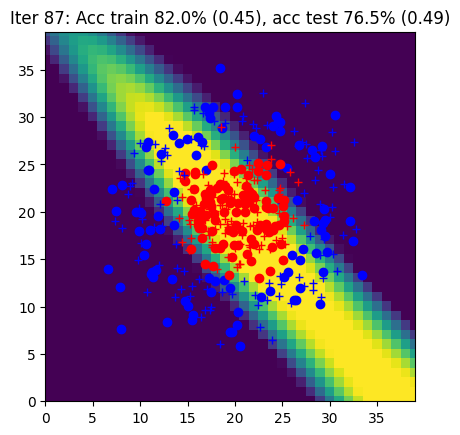

Iter 88: Acc train 81.5% (0.44), acc test 77.0% (0.49)


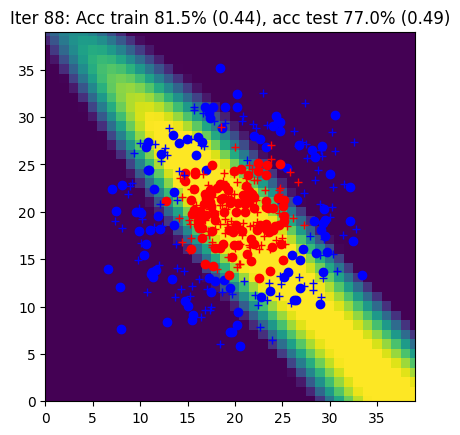

Iter 89: Acc train 82.0% (0.44), acc test 77.0% (0.49)


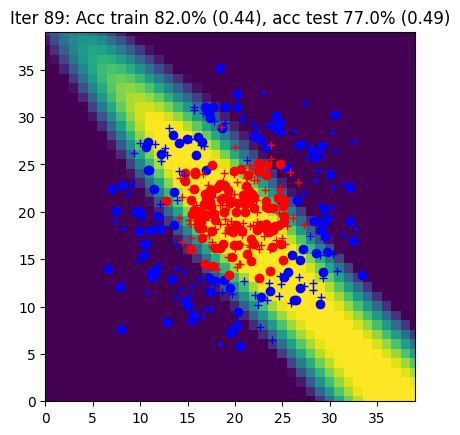

Iter 90: Acc train 82.0% (0.44), acc test 77.5% (0.48)


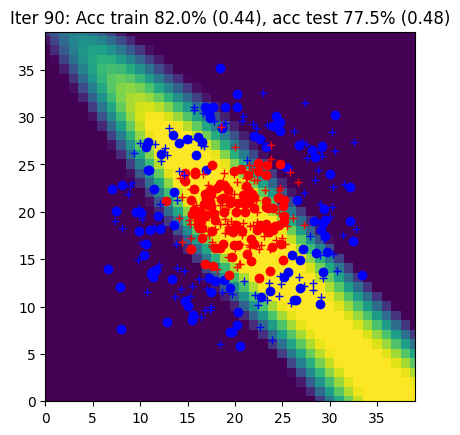

Iter 91: Acc train 81.5% (0.44), acc test 75.5% (0.48)


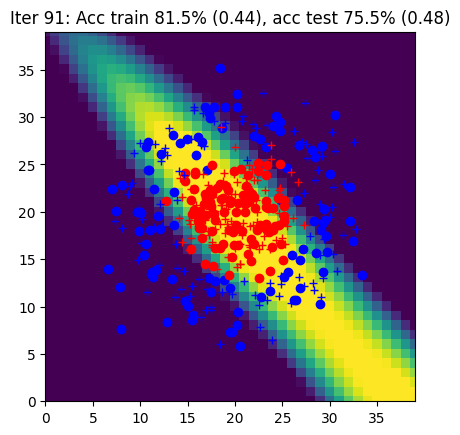

Iter 92: Acc train 81.5% (0.43), acc test 75.5% (0.48)


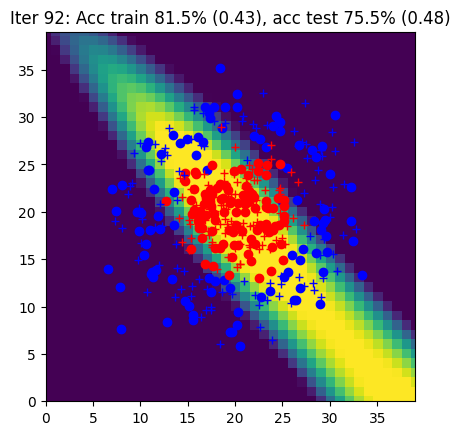

Iter 93: Acc train 82.0% (0.43), acc test 76.0% (0.48)


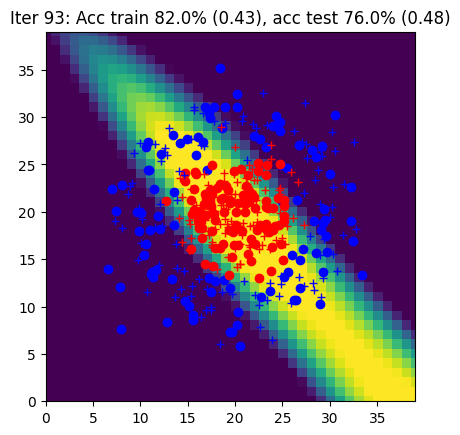

Iter 94: Acc train 81.5% (0.43), acc test 76.5% (0.47)


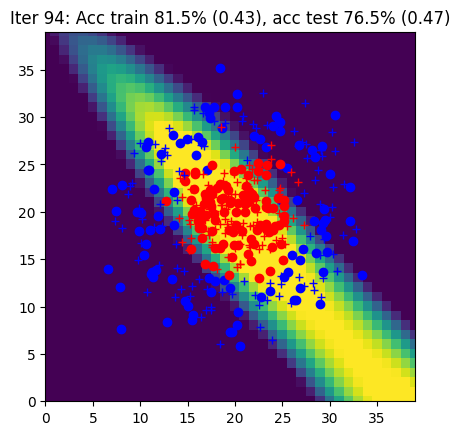

Iter 95: Acc train 82.5% (0.43), acc test 77.0% (0.47)


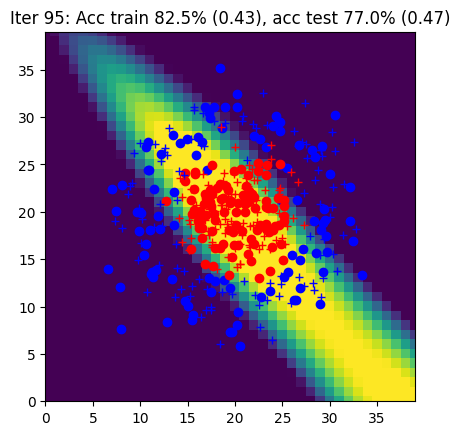

Iter 96: Acc train 83.0% (0.42), acc test 77.0% (0.47)


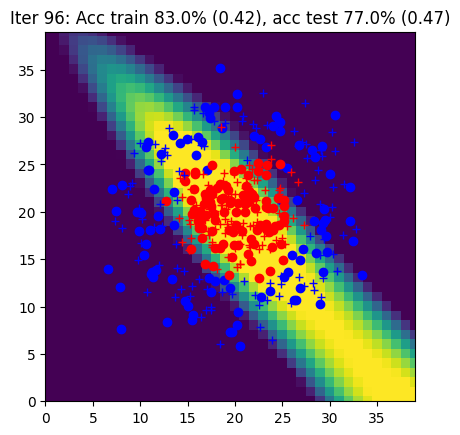

Iter 97: Acc train 83.0% (0.42), acc test 77.0% (0.47)


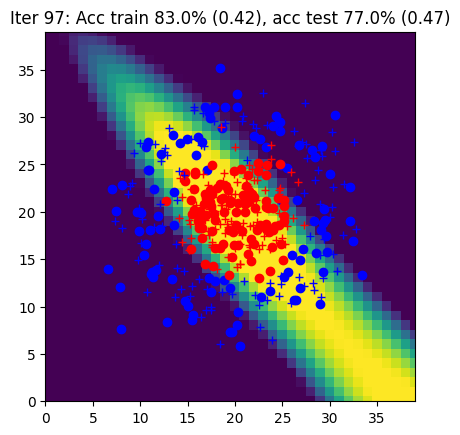

Iter 98: Acc train 82.0% (0.42), acc test 76.5% (0.46)


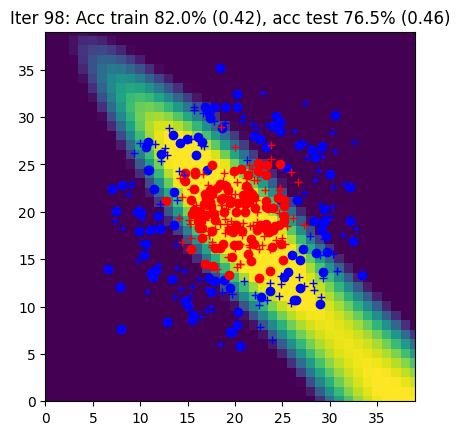

Iter 99: Acc train 83.0% (0.41), acc test 77.0% (0.46)


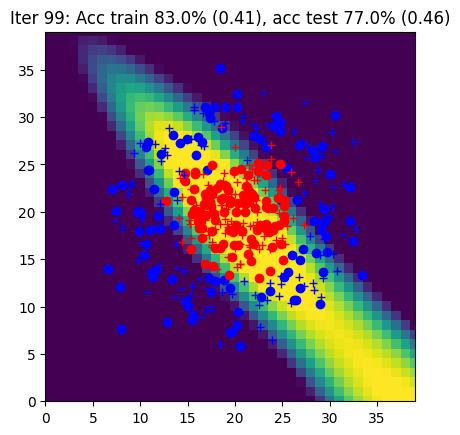

Iter 100: Acc train 83.0% (0.41), acc test 77.5% (0.46)


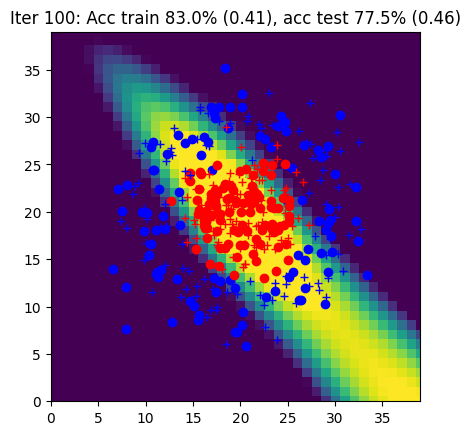

Iter 101: Acc train 83.0% (0.41), acc test 77.5% (0.45)


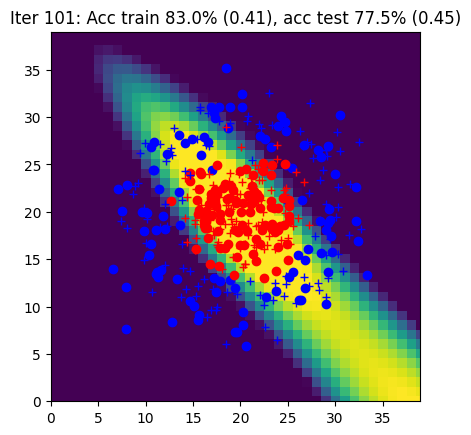

Iter 102: Acc train 83.0% (0.41), acc test 77.5% (0.45)


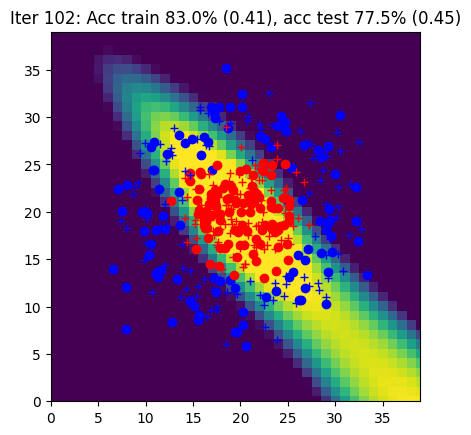

Iter 103: Acc train 83.0% (0.40), acc test 77.5% (0.45)


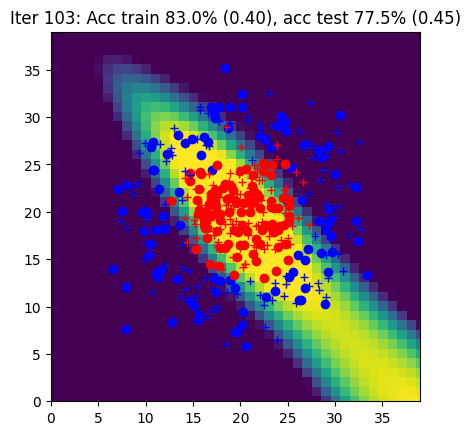

Iter 104: Acc train 83.0% (0.40), acc test 77.0% (0.44)


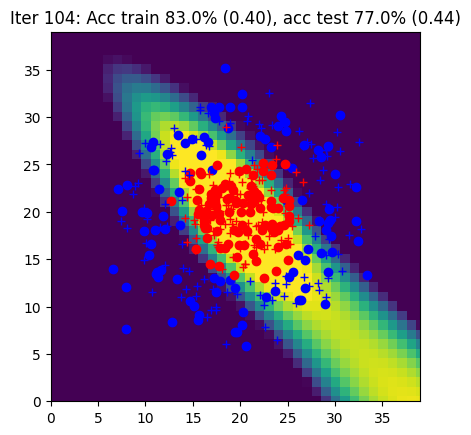

Iter 105: Acc train 83.0% (0.40), acc test 78.0% (0.44)


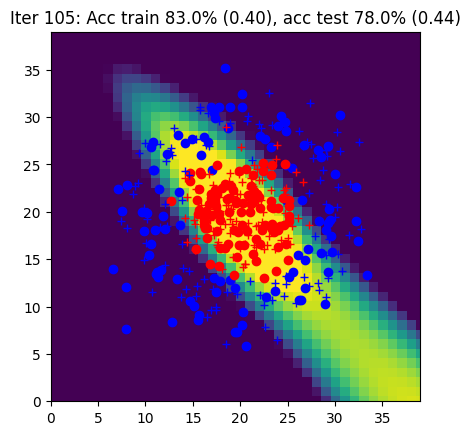

Iter 106: Acc train 83.0% (0.39), acc test 78.0% (0.44)


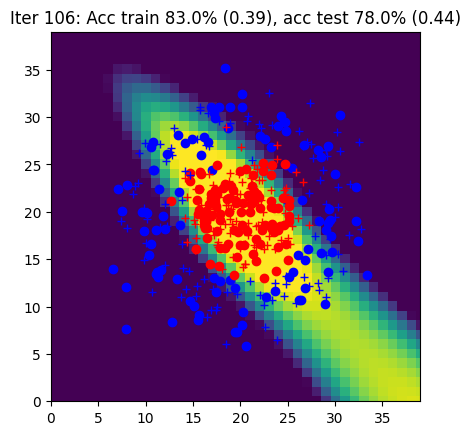

Iter 107: Acc train 83.0% (0.39), acc test 78.0% (0.43)


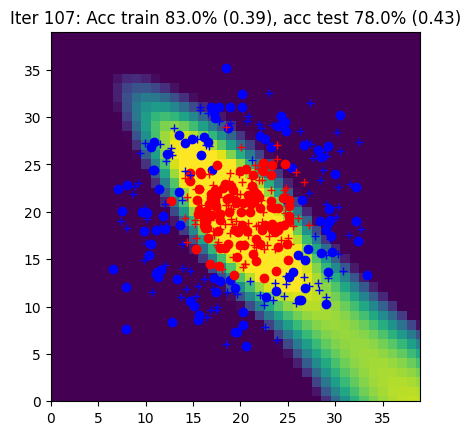

Iter 108: Acc train 83.0% (0.38), acc test 78.0% (0.43)


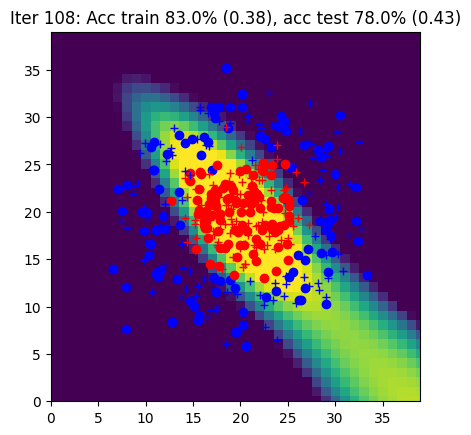

Iter 109: Acc train 83.5% (0.38), acc test 78.0% (0.42)


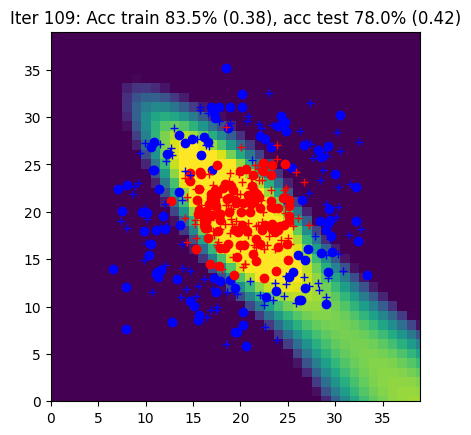

Iter 110: Acc train 83.5% (0.38), acc test 78.5% (0.42)


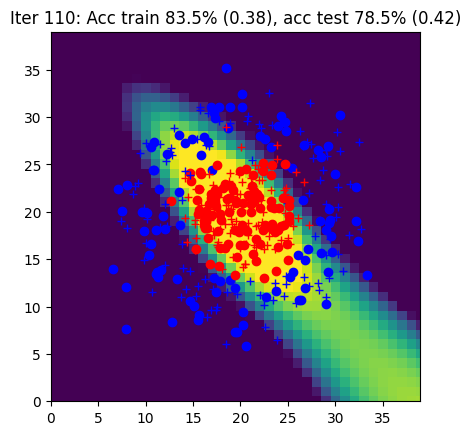

Iter 111: Acc train 84.0% (0.37), acc test 78.0% (0.42)


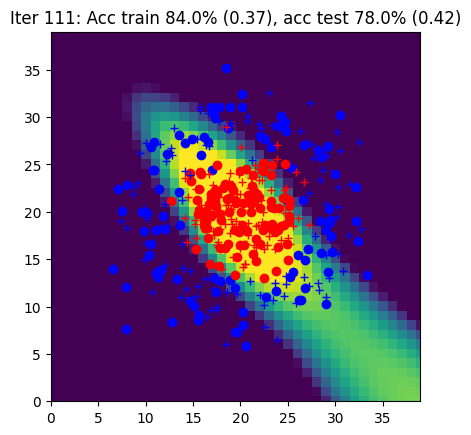

Iter 112: Acc train 84.5% (0.37), acc test 78.5% (0.41)


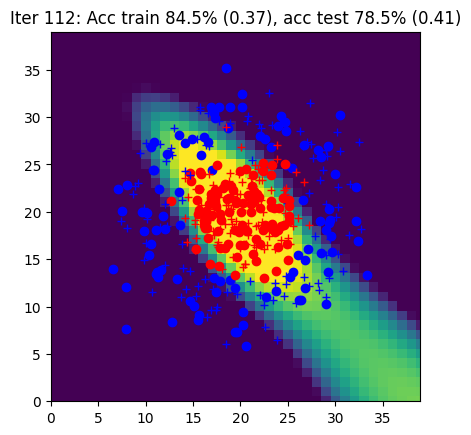

Iter 113: Acc train 84.5% (0.37), acc test 78.5% (0.41)


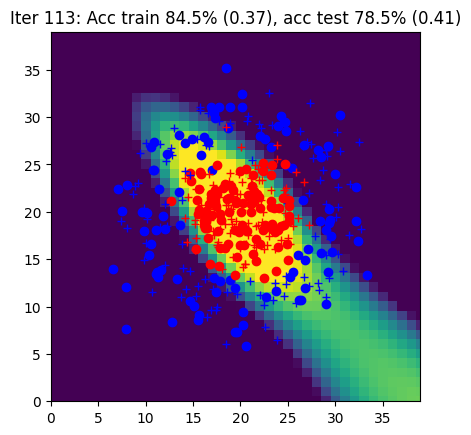

Iter 114: Acc train 84.5% (0.36), acc test 78.5% (0.40)


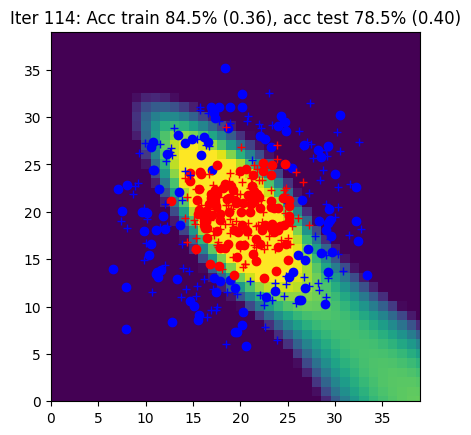

Iter 115: Acc train 85.0% (0.36), acc test 79.0% (0.40)


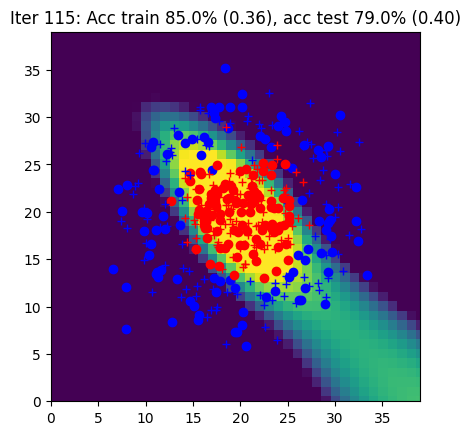

Iter 116: Acc train 85.5% (0.35), acc test 78.5% (0.39)


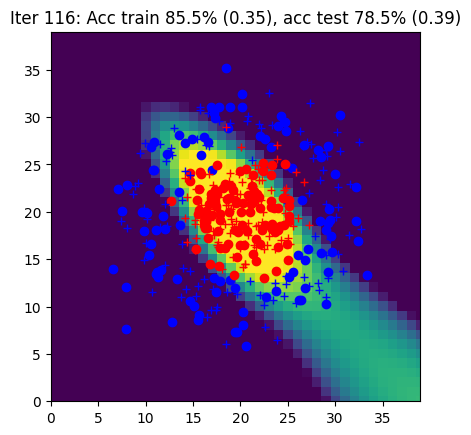

Iter 117: Acc train 85.5% (0.35), acc test 79.5% (0.39)


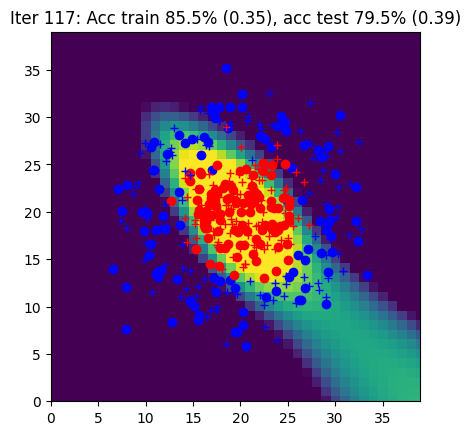

Iter 118: Acc train 85.5% (0.35), acc test 79.5% (0.38)


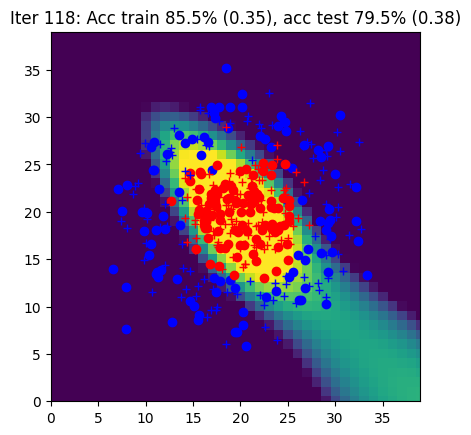

Iter 119: Acc train 86.0% (0.34), acc test 80.0% (0.38)


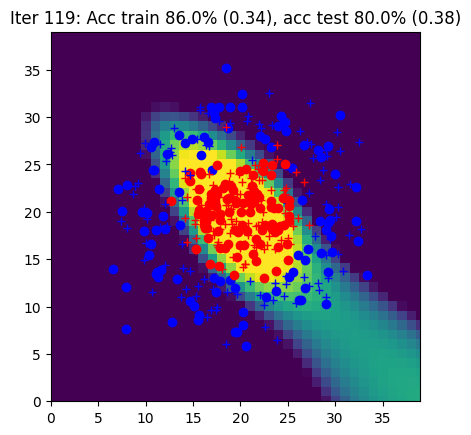

Iter 120: Acc train 86.0% (0.34), acc test 81.0% (0.38)


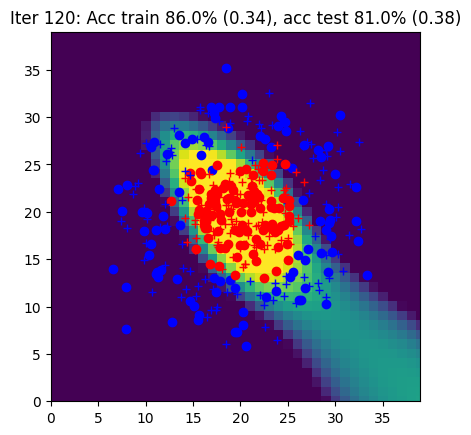

Iter 121: Acc train 85.5% (0.33), acc test 81.0% (0.37)


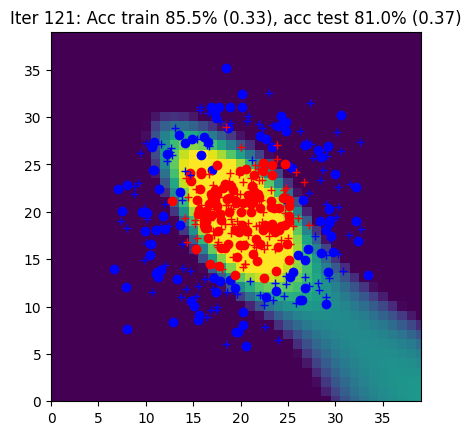

Iter 122: Acc train 85.5% (0.33), acc test 81.5% (0.37)


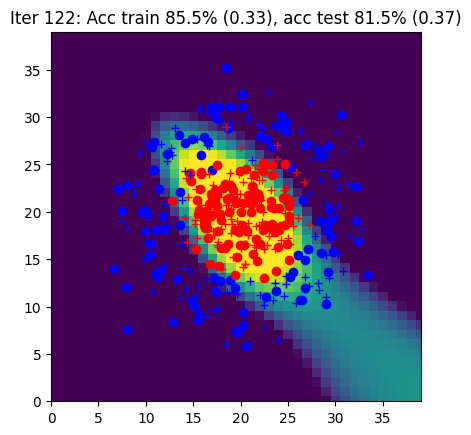

Iter 123: Acc train 86.5% (0.32), acc test 82.0% (0.36)


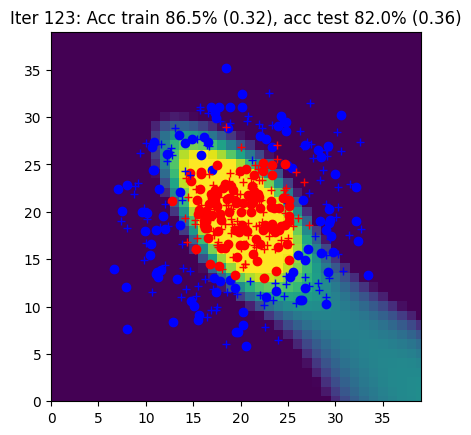

Iter 124: Acc train 86.5% (0.32), acc test 83.5% (0.36)


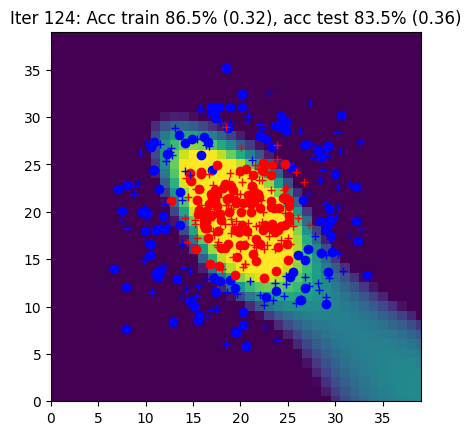

Iter 125: Acc train 86.5% (0.32), acc test 84.5% (0.35)


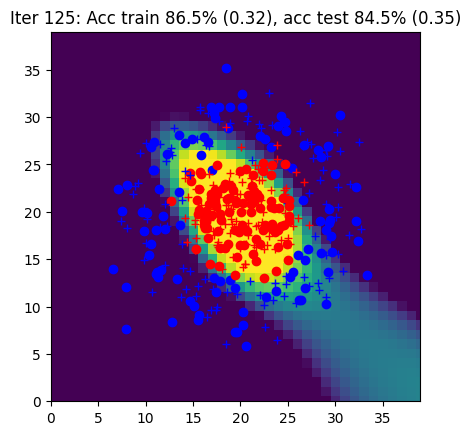

Iter 126: Acc train 86.5% (0.31), acc test 84.5% (0.35)


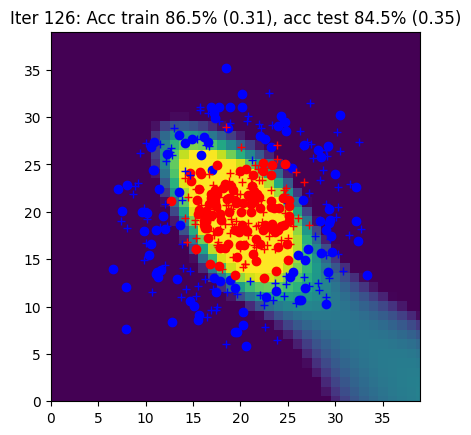

Iter 127: Acc train 89.0% (0.31), acc test 86.5% (0.34)


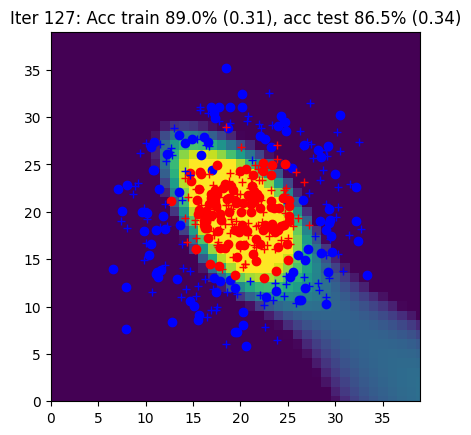

Iter 128: Acc train 89.5% (0.31), acc test 86.5% (0.34)


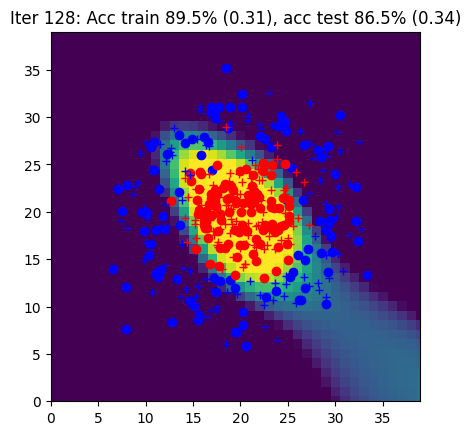

Iter 129: Acc train 90.0% (0.30), acc test 88.0% (0.33)


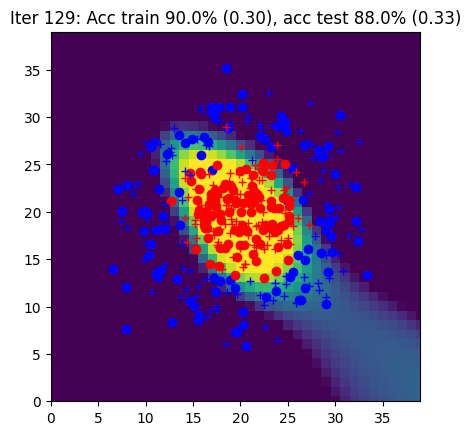

Iter 130: Acc train 90.5% (0.30), acc test 88.0% (0.33)


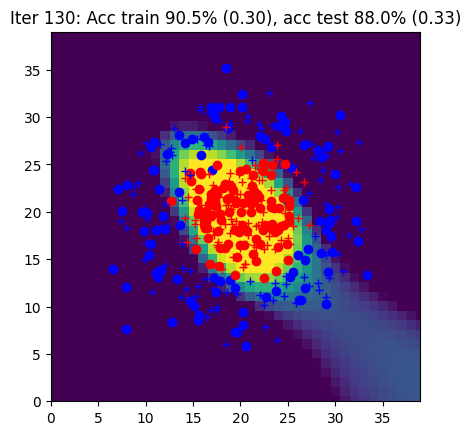

Iter 131: Acc train 92.0% (0.29), acc test 89.5% (0.33)


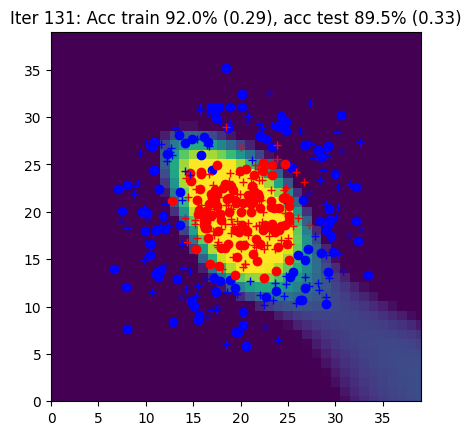

Iter 132: Acc train 91.0% (0.29), acc test 90.0% (0.32)


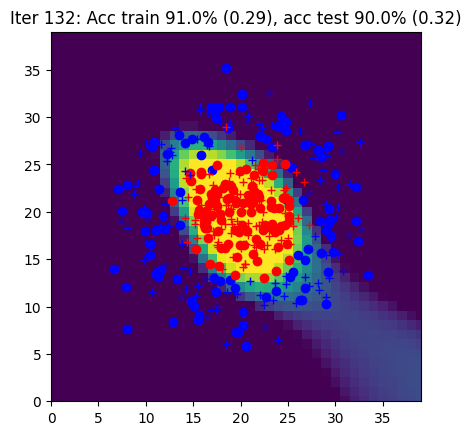

Iter 133: Acc train 92.0% (0.29), acc test 90.0% (0.32)


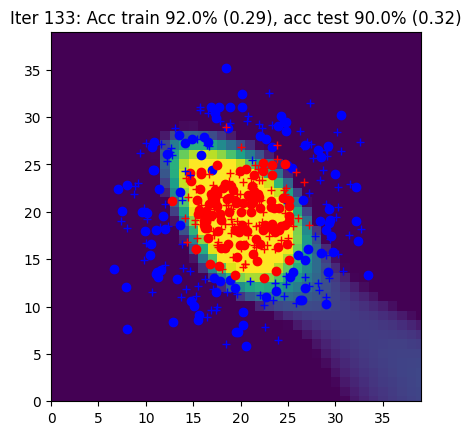

Iter 134: Acc train 93.0% (0.28), acc test 91.0% (0.31)


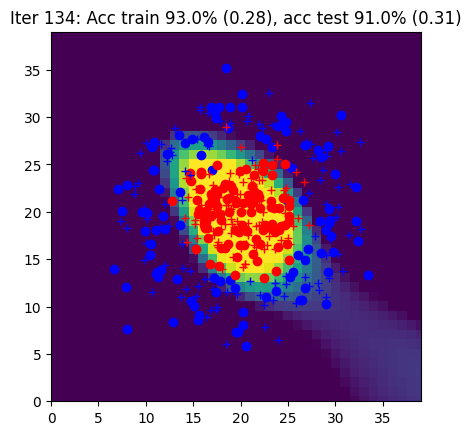

Iter 135: Acc train 93.0% (0.28), acc test 91.0% (0.31)


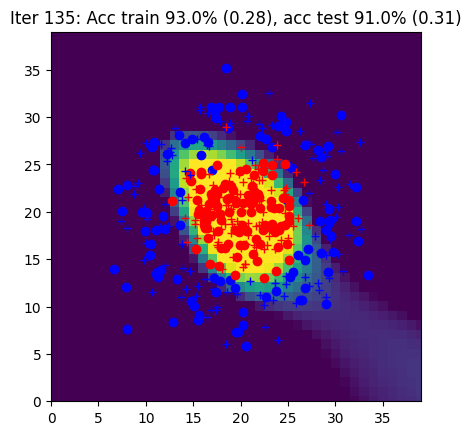

Iter 136: Acc train 94.0% (0.28), acc test 91.0% (0.31)


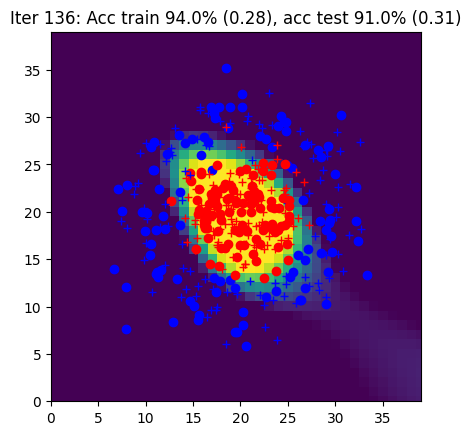

Iter 137: Acc train 93.5% (0.27), acc test 91.5% (0.30)


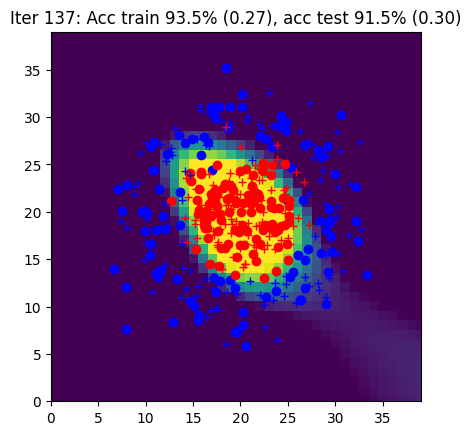

Iter 138: Acc train 94.0% (0.27), acc test 92.0% (0.30)


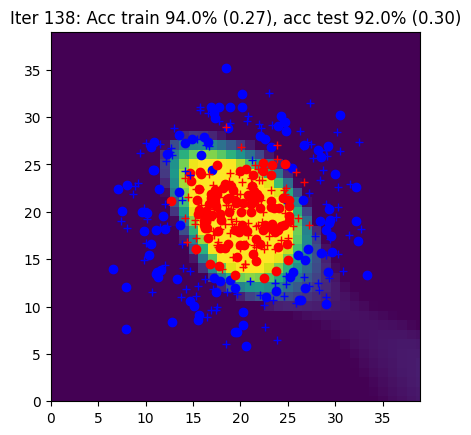

Iter 139: Acc train 94.5% (0.27), acc test 92.0% (0.29)


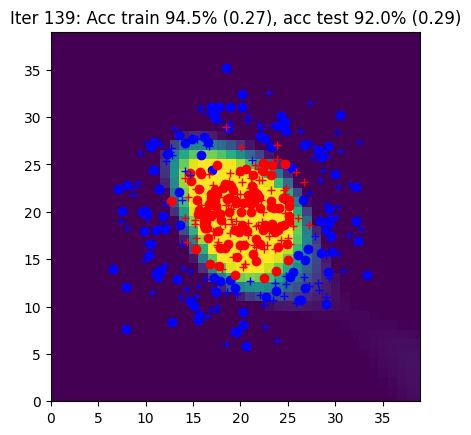

Iter 140: Acc train 94.0% (0.26), acc test 92.0% (0.29)


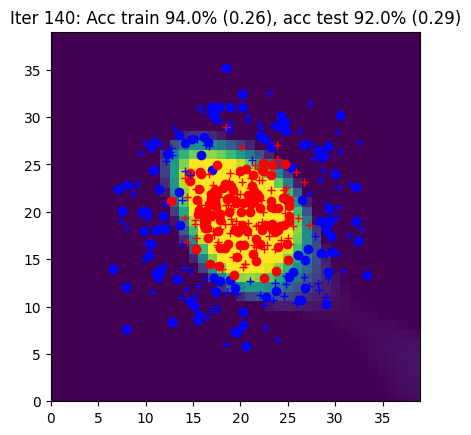

Iter 141: Acc train 94.5% (0.26), acc test 93.0% (0.29)


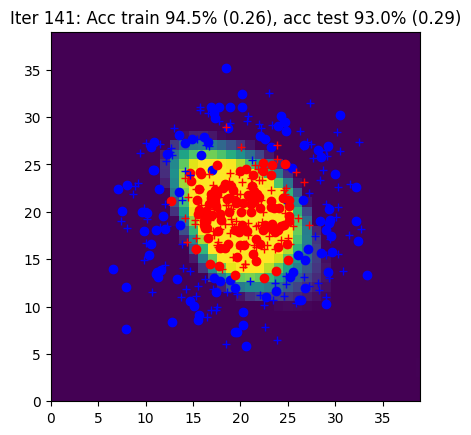

Iter 142: Acc train 94.5% (0.26), acc test 93.0% (0.28)


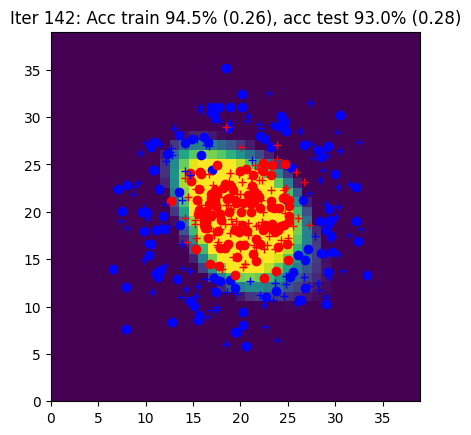

Iter 143: Acc train 94.5% (0.26), acc test 93.0% (0.28)


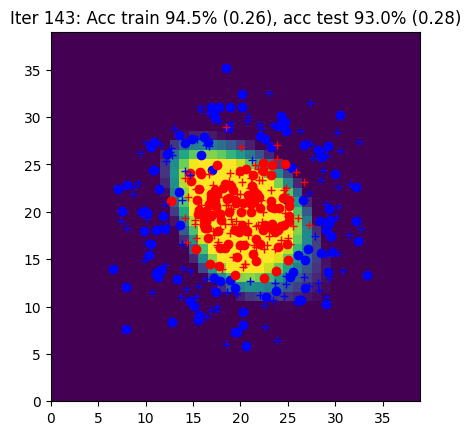

Iter 144: Acc train 94.5% (0.25), acc test 93.0% (0.28)


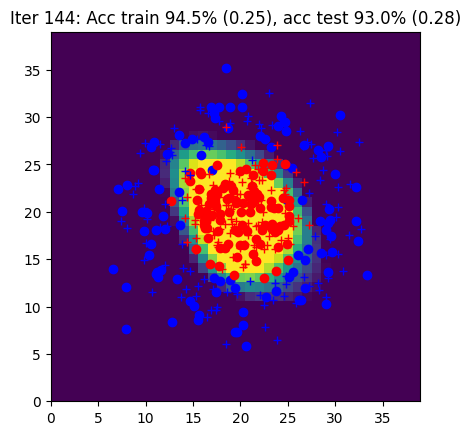

Iter 145: Acc train 94.5% (0.25), acc test 93.0% (0.27)


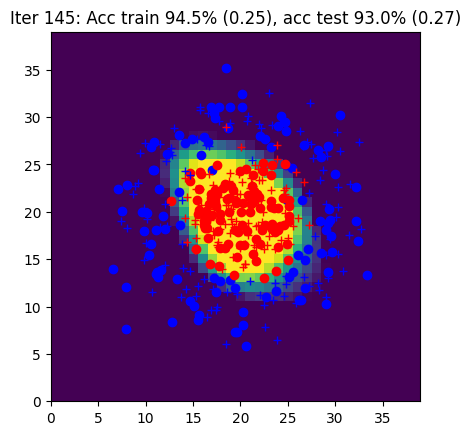

Iter 146: Acc train 94.5% (0.25), acc test 93.0% (0.27)


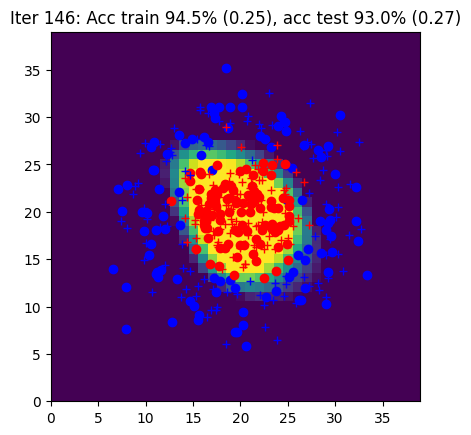

Iter 147: Acc train 94.5% (0.25), acc test 93.0% (0.27)


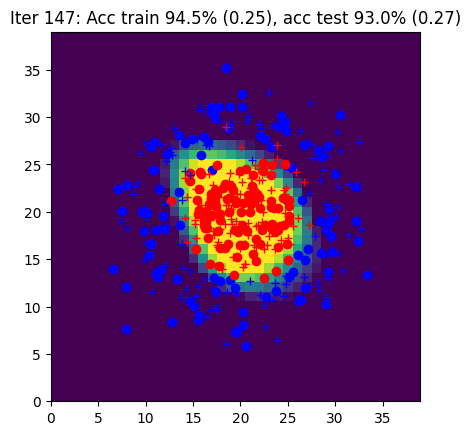

Iter 148: Acc train 95.0% (0.24), acc test 93.0% (0.27)


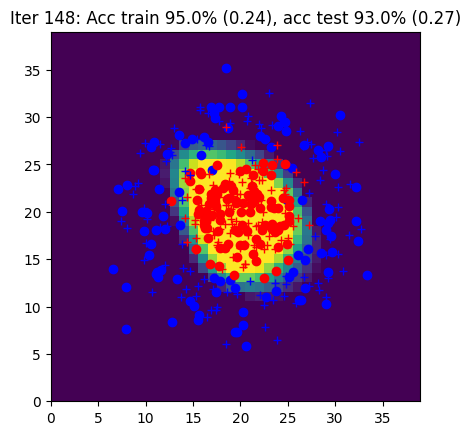

Iter 149: Acc train 95.0% (0.24), acc test 93.0% (0.26)


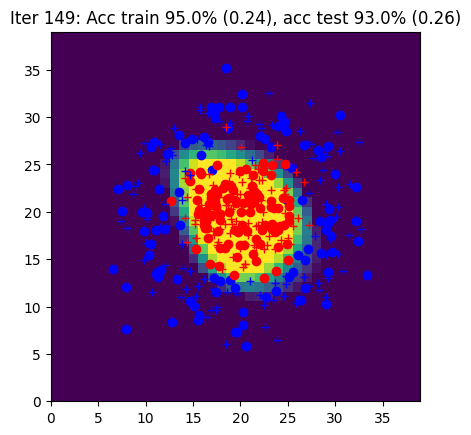

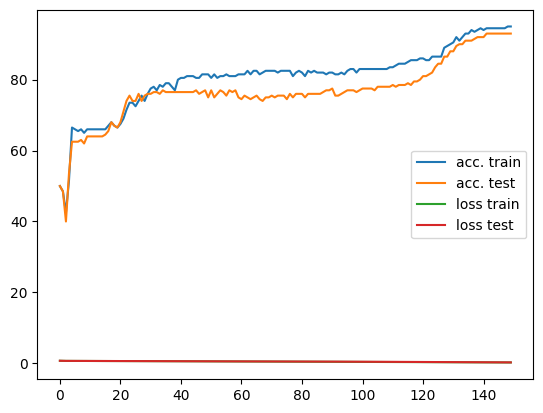

In [15]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

model, loss = init_model(nx, nh, ny)

curves = [[],[], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code here  ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j+1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: loss_accuracy, sgd
        # the forward with the predict method from the model
        # and the backward function with autograd
        L = loss(model(X), Y)
        L.backward()
        model = sgd(model, eta)

    ####################
    ##      END        #
    ####################


    Yhat_train = model(data.Xtrain)
    Yhat_test = model(data.Xtest)
    Ltrain, acctrain = loss_accuracy(loss, Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(loss, Yhat_test, data.Ytest)
    Ygrid = model(data.Xgrid)

    title = 'Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})'.format(iteration, acctrain, Ltrain, acctest, Ltest)
    print(title)
    data.plot_data_with_grid(torch.nn.Softmax(dim=1)(Ygrid.detach()), title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 4 : Simplification of the SGD with `torch.optim`

In [16]:
def init_model(nx, nh, ny, eta):

    #####################
    ## Your code here  ##
    #####################

    model = torch.nn.Sequential(
        torch.nn.Linear(nx, nh),
        torch.nn.Tanh(),
        torch.nn.Linear(nh, ny)
    )
    loss = torch.nn.CrossEntropyLoss()
    optim = torch.optim.SGD(model.parameters(), lr=eta)

    ####################
    ##      END        #
    ####################

    return model, loss, optim

The `sgd` function is replaced by calling the `optim.zero_grad()` before the backward and `optim.step()` after.

## Algorithme global d'apprentissage (avec autograd, les couches `torch.nn` et `torch.optim`)

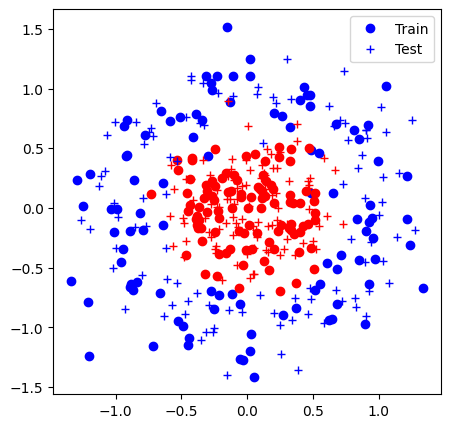

Iter 0: Acc train 50.0% (0.73), acc test 50.0% (0.73)


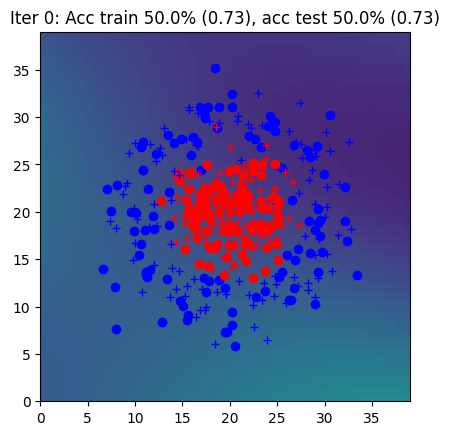

Iter 1: Acc train 48.5% (0.70), acc test 48.5% (0.70)


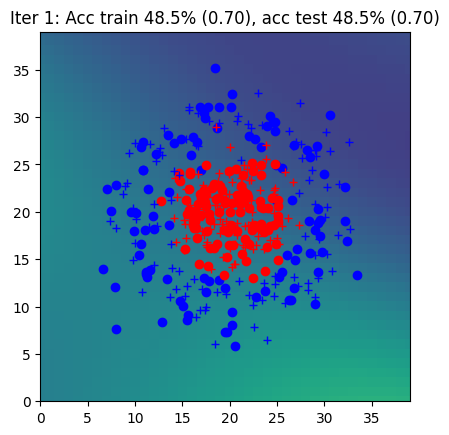

Iter 2: Acc train 36.5% (0.70), acc test 34.5% (0.70)


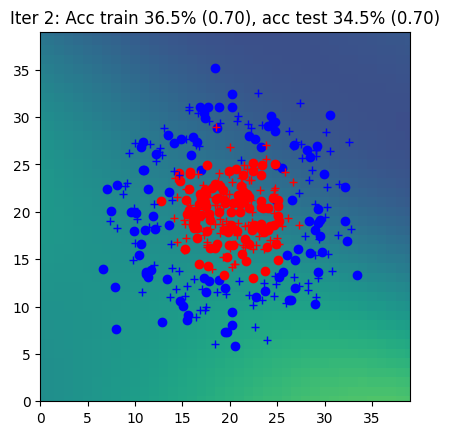

Iter 3: Acc train 38.0% (0.69), acc test 38.5% (0.70)


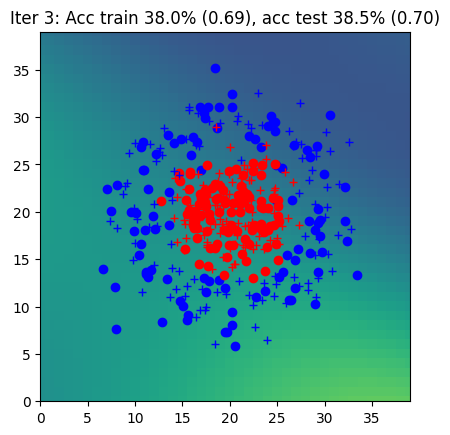

Iter 4: Acc train 47.0% (0.69), acc test 46.5% (0.69)


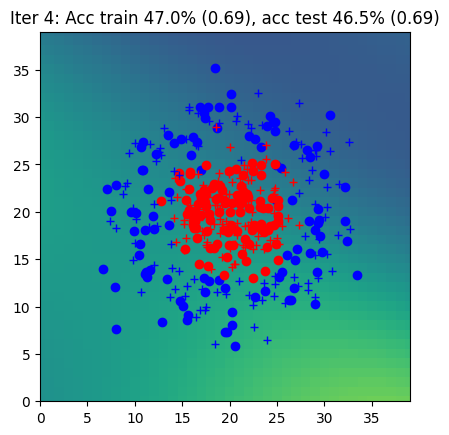

Iter 5: Acc train 56.5% (0.69), acc test 55.5% (0.69)


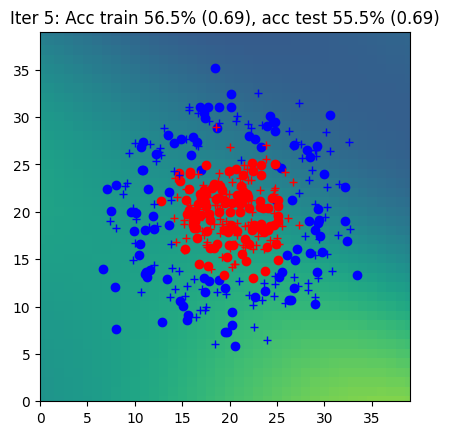

Iter 6: Acc train 57.5% (0.69), acc test 56.0% (0.69)


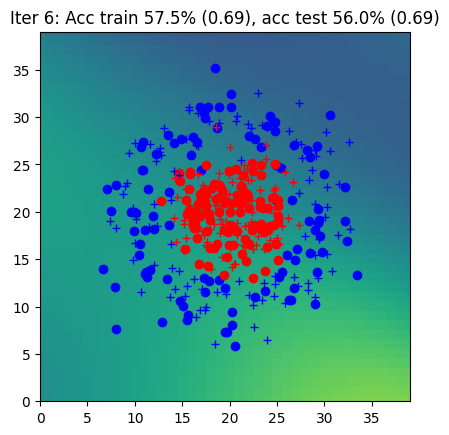

Iter 7: Acc train 63.0% (0.69), acc test 59.5% (0.69)


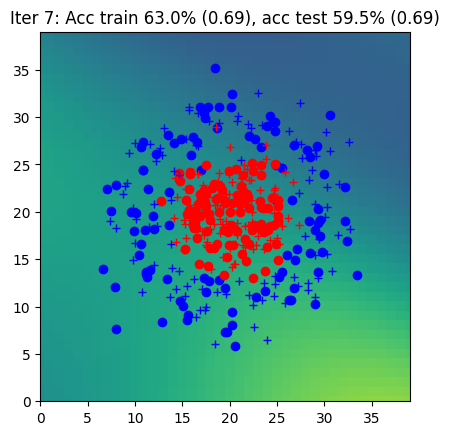

Iter 8: Acc train 63.0% (0.69), acc test 59.5% (0.69)


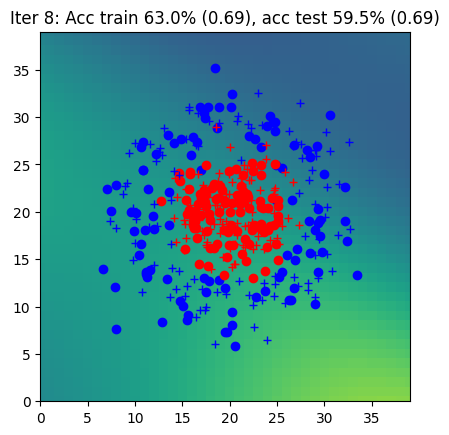

Iter 9: Acc train 63.5% (0.69), acc test 58.5% (0.69)


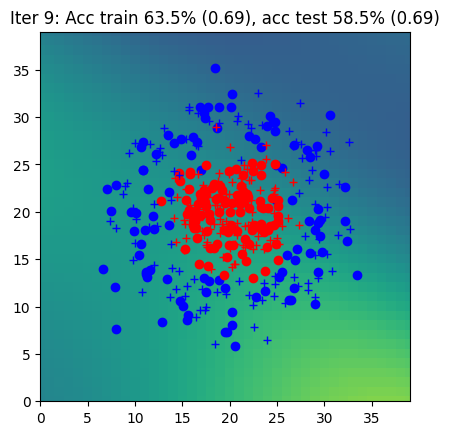

Iter 10: Acc train 64.5% (0.69), acc test 60.0% (0.69)


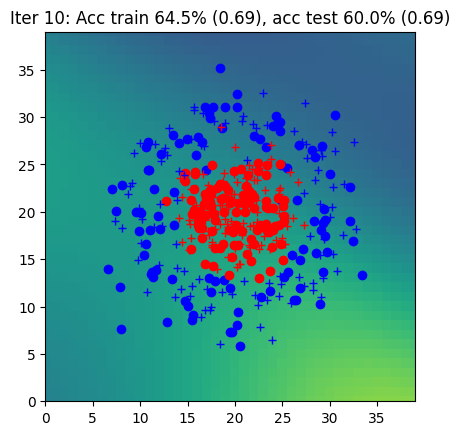

Iter 11: Acc train 63.0% (0.68), acc test 62.5% (0.69)


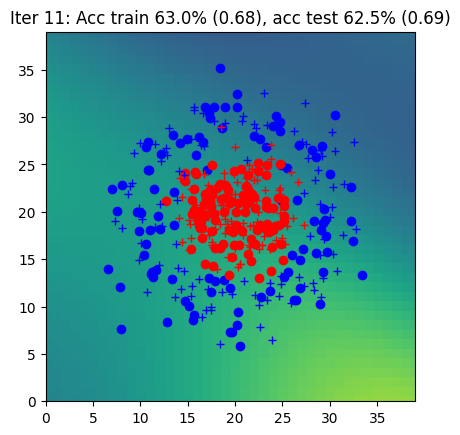

Iter 12: Acc train 64.5% (0.68), acc test 59.0% (0.69)


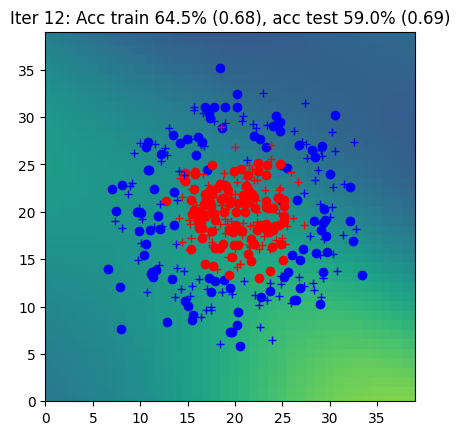

Iter 13: Acc train 61.0% (0.68), acc test 57.5% (0.69)


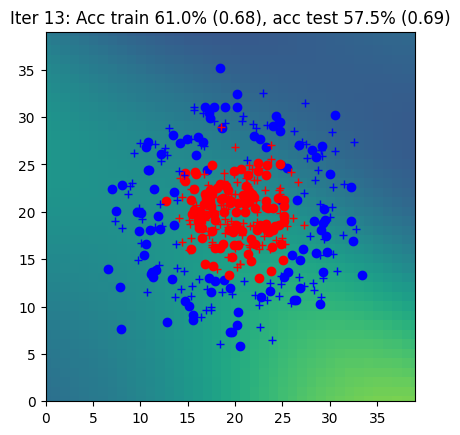

Iter 14: Acc train 61.0% (0.68), acc test 59.0% (0.68)


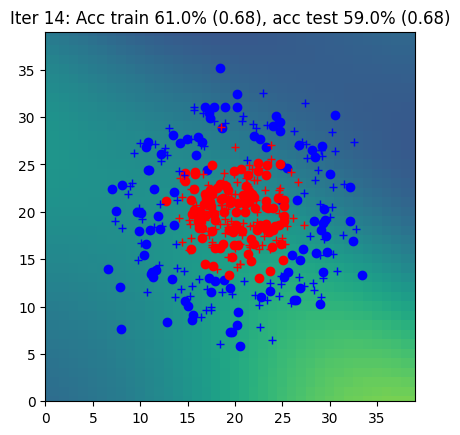

Iter 15: Acc train 64.0% (0.68), acc test 61.5% (0.68)


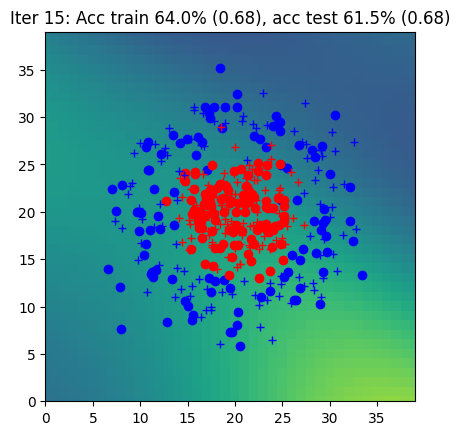

Iter 16: Acc train 63.5% (0.68), acc test 63.5% (0.68)


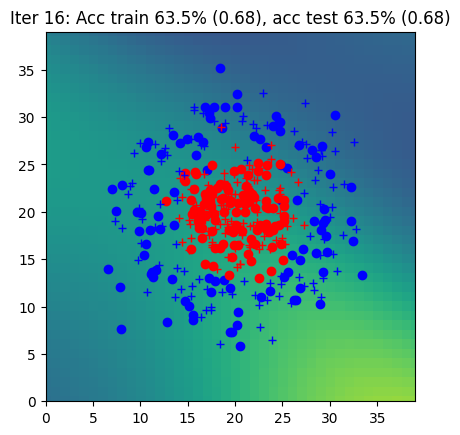

Iter 17: Acc train 64.0% (0.68), acc test 64.0% (0.68)


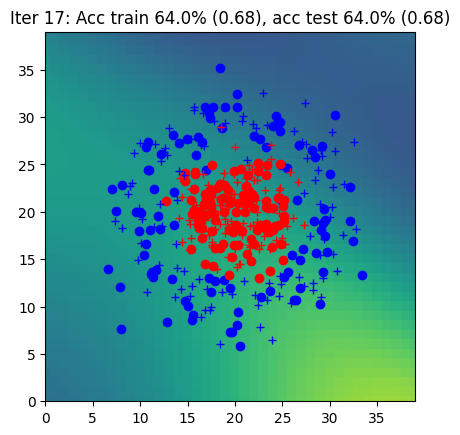

Iter 18: Acc train 64.0% (0.68), acc test 63.5% (0.68)


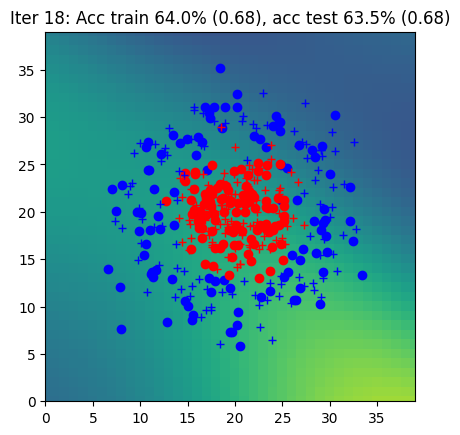

Iter 19: Acc train 65.0% (0.68), acc test 64.0% (0.68)


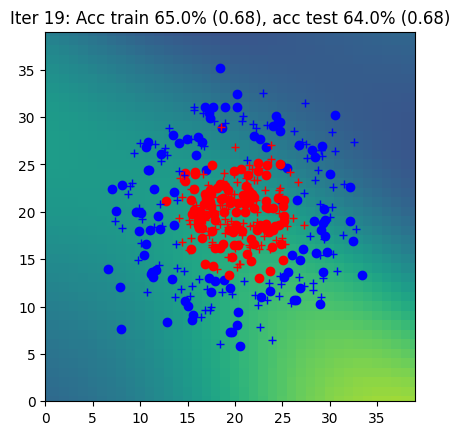

Iter 20: Acc train 66.0% (0.67), acc test 63.5% (0.68)


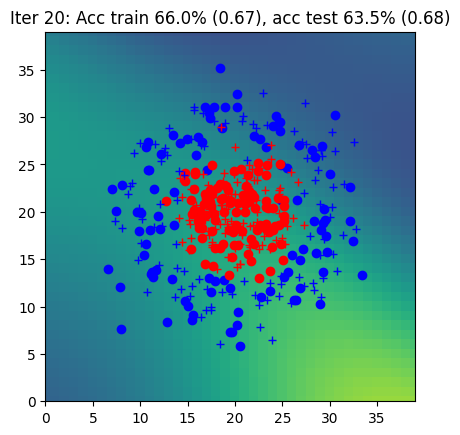

Iter 21: Acc train 66.0% (0.67), acc test 64.0% (0.68)


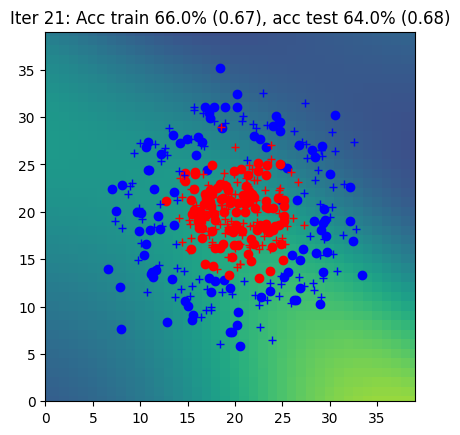

Iter 22: Acc train 67.0% (0.67), acc test 64.0% (0.68)


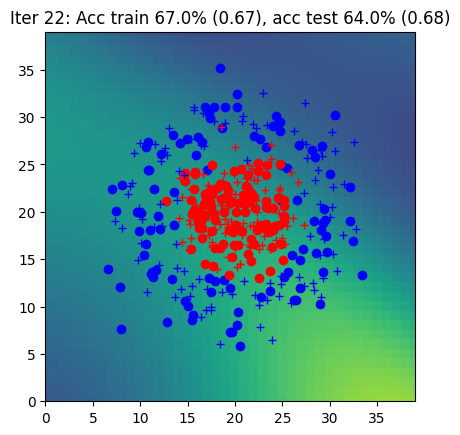

Iter 23: Acc train 69.5% (0.67), acc test 64.0% (0.67)


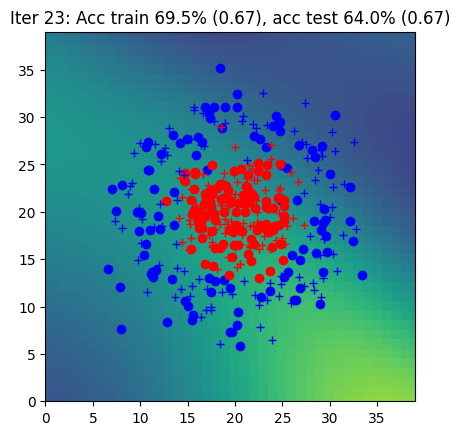

Iter 24: Acc train 69.5% (0.67), acc test 64.5% (0.67)


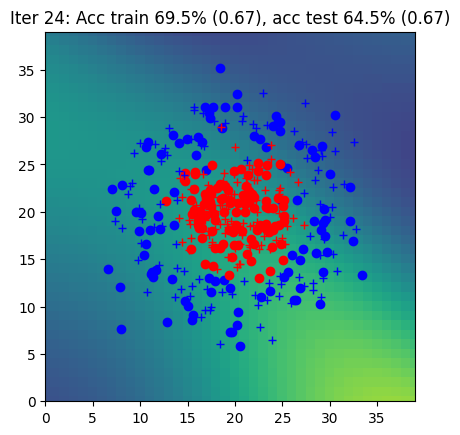

Iter 25: Acc train 68.5% (0.67), acc test 64.5% (0.67)


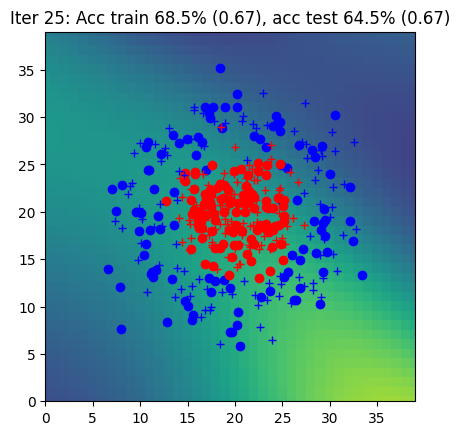

Iter 26: Acc train 68.0% (0.67), acc test 65.0% (0.67)


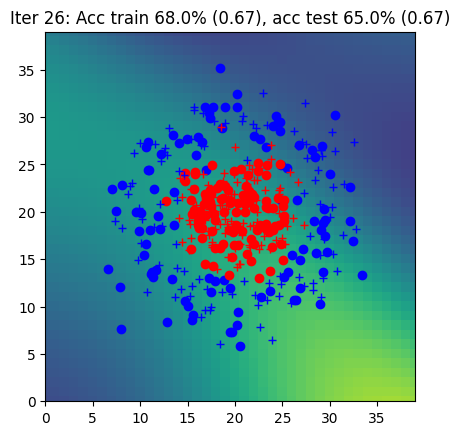

Iter 27: Acc train 72.5% (0.66), acc test 65.5% (0.67)


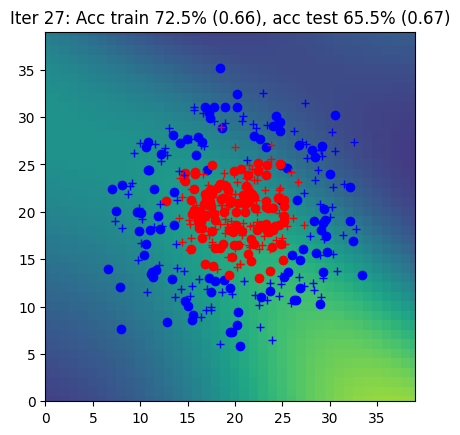

Iter 28: Acc train 72.0% (0.66), acc test 66.5% (0.67)


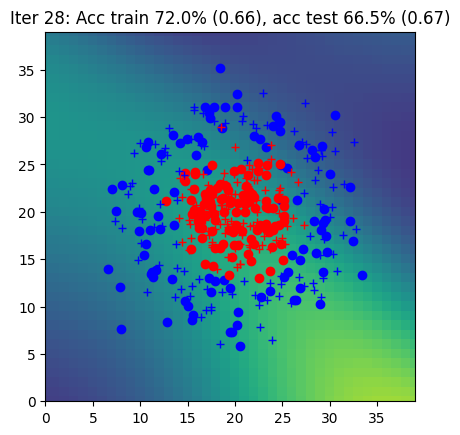

Iter 29: Acc train 75.0% (0.66), acc test 66.5% (0.67)


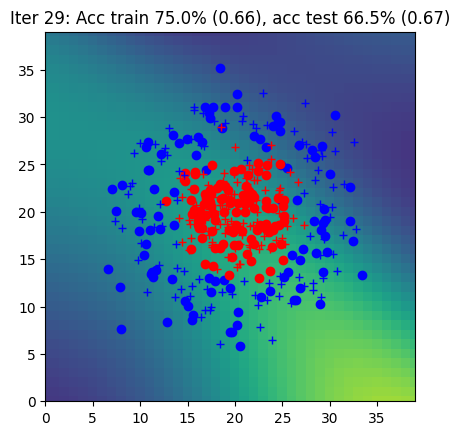

Iter 30: Acc train 74.5% (0.66), acc test 67.0% (0.66)


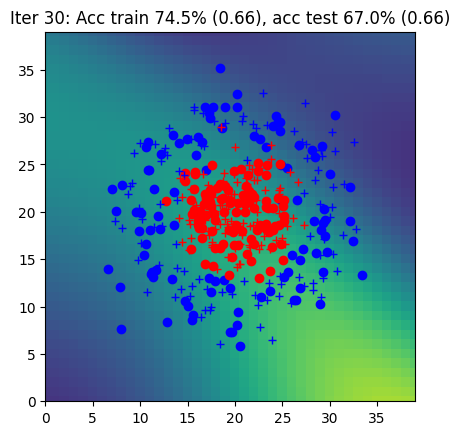

Iter 31: Acc train 69.5% (0.66), acc test 66.0% (0.66)


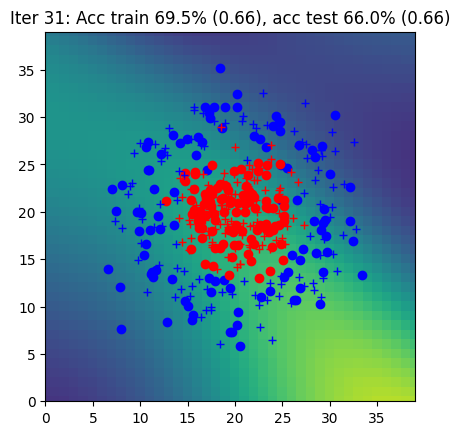

Iter 32: Acc train 75.5% (0.65), acc test 67.5% (0.66)


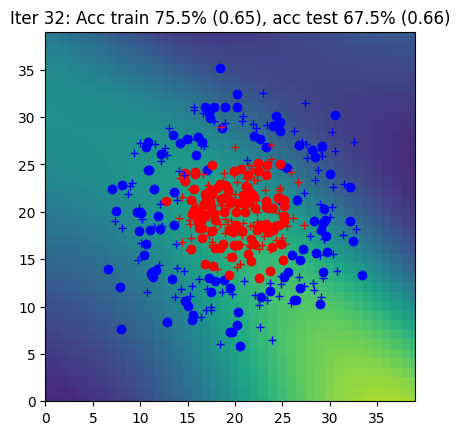

Iter 33: Acc train 72.5% (0.65), acc test 66.0% (0.66)


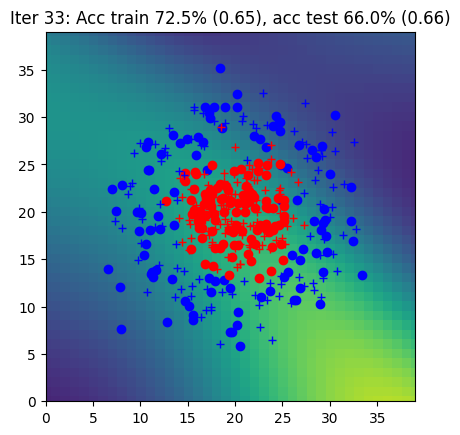

Iter 34: Acc train 76.5% (0.65), acc test 69.5% (0.66)


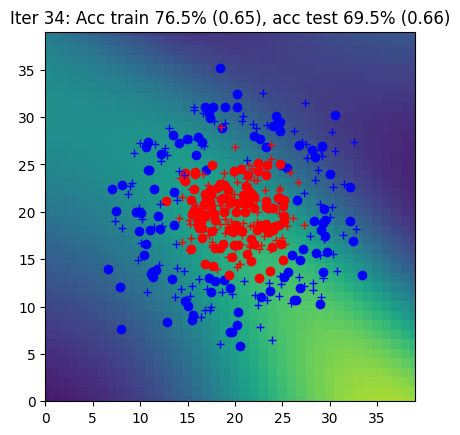

Iter 35: Acc train 76.5% (0.65), acc test 69.0% (0.66)


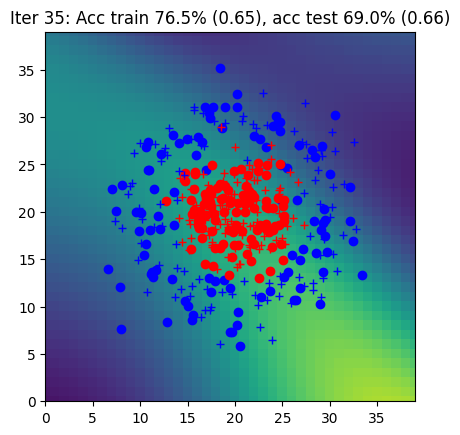

Iter 36: Acc train 75.5% (0.65), acc test 69.0% (0.65)


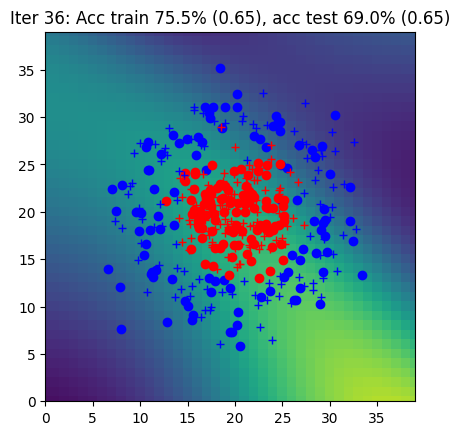

Iter 37: Acc train 75.0% (0.64), acc test 69.5% (0.65)


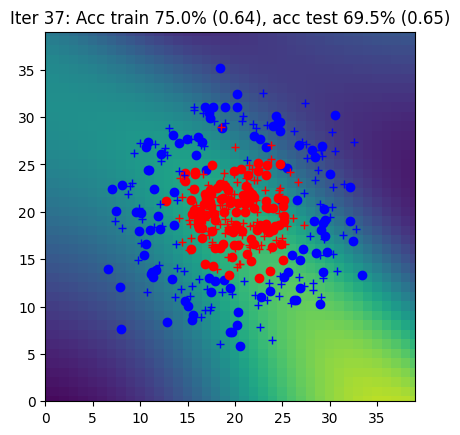

Iter 38: Acc train 75.0% (0.64), acc test 69.5% (0.65)


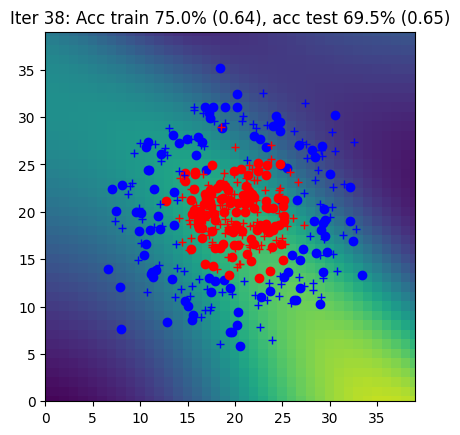

Iter 39: Acc train 76.5% (0.64), acc test 71.5% (0.65)


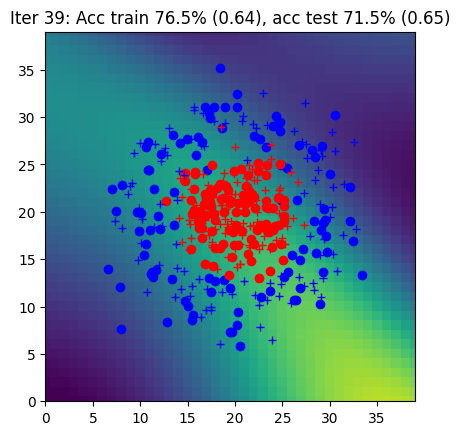

Iter 40: Acc train 76.0% (0.64), acc test 71.5% (0.65)


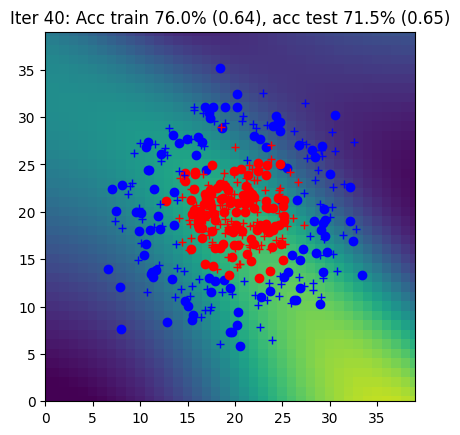

Iter 41: Acc train 77.0% (0.63), acc test 73.5% (0.64)


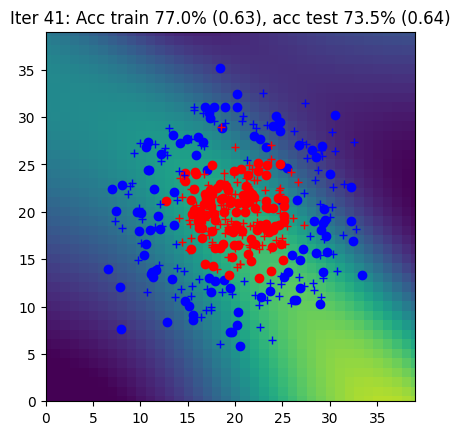

Iter 42: Acc train 75.5% (0.63), acc test 70.0% (0.64)


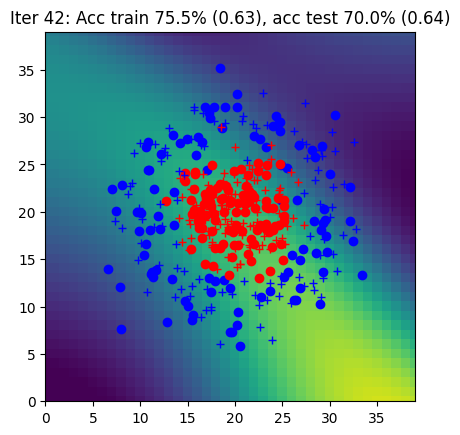

Iter 43: Acc train 77.0% (0.63), acc test 72.5% (0.64)


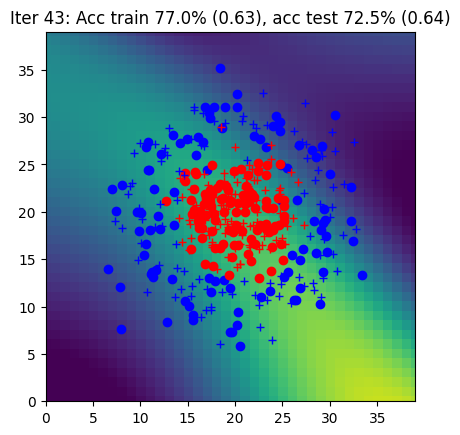

Iter 44: Acc train 77.0% (0.62), acc test 73.0% (0.64)


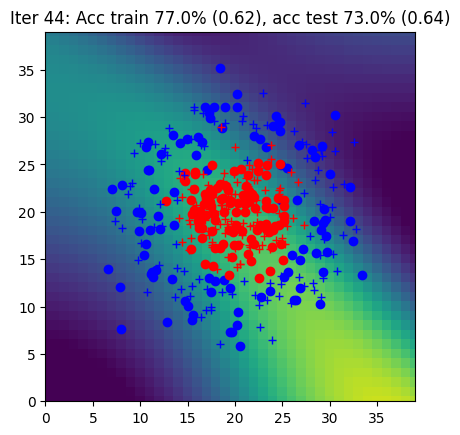

Iter 45: Acc train 77.5% (0.62), acc test 71.5% (0.63)


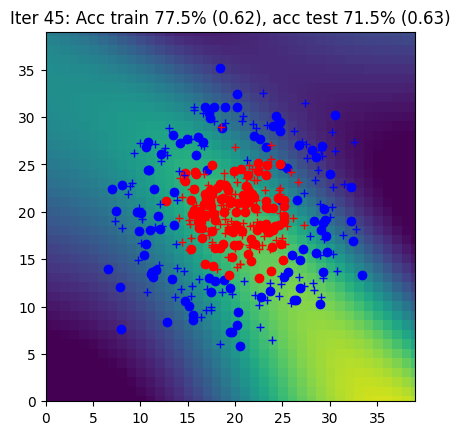

Iter 46: Acc train 77.0% (0.62), acc test 74.5% (0.63)


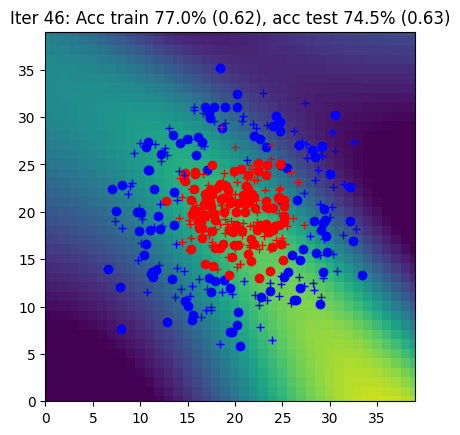

Iter 47: Acc train 77.5% (0.61), acc test 75.0% (0.63)


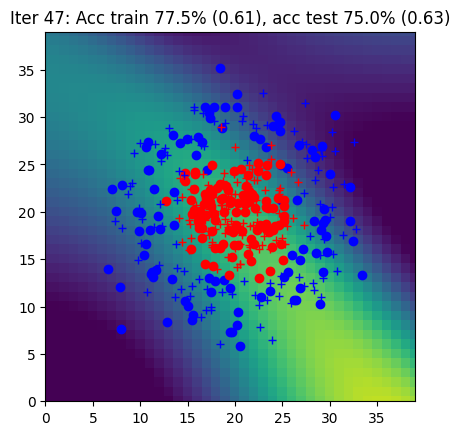

Iter 48: Acc train 77.5% (0.61), acc test 75.5% (0.62)


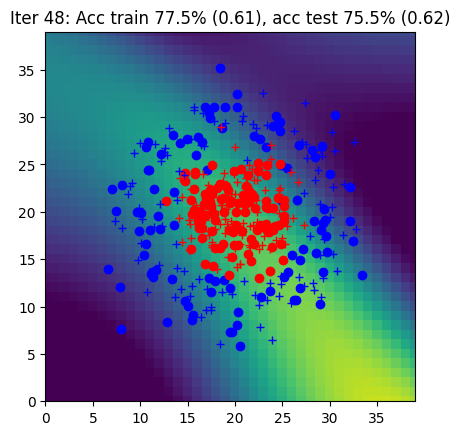

Iter 49: Acc train 77.5% (0.61), acc test 75.5% (0.62)


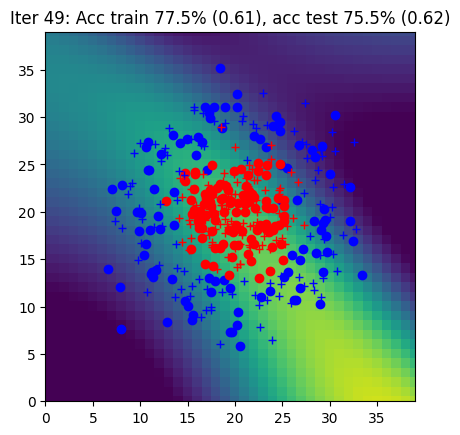

Iter 50: Acc train 79.0% (0.60), acc test 76.5% (0.62)


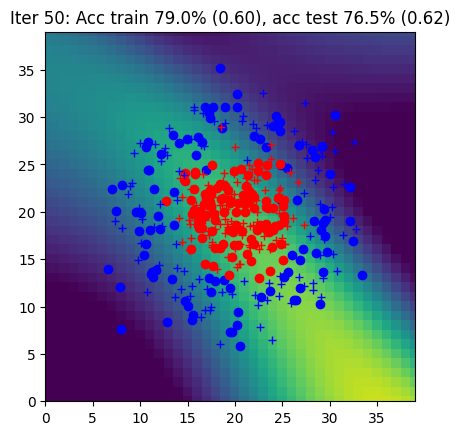

Iter 51: Acc train 79.0% (0.60), acc test 76.5% (0.62)


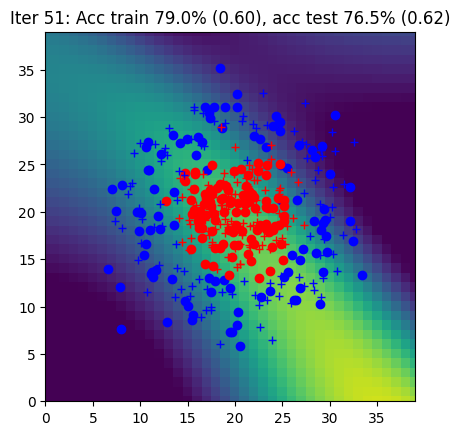

Iter 52: Acc train 79.0% (0.60), acc test 76.5% (0.61)


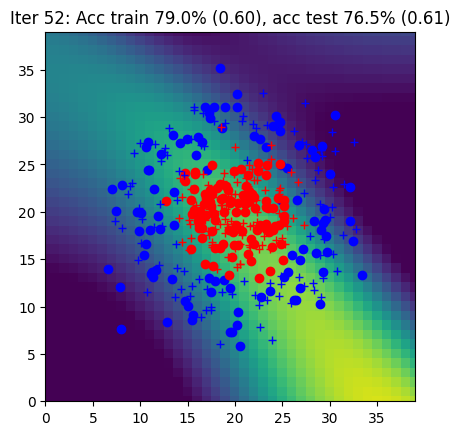

Iter 53: Acc train 78.0% (0.59), acc test 76.5% (0.61)


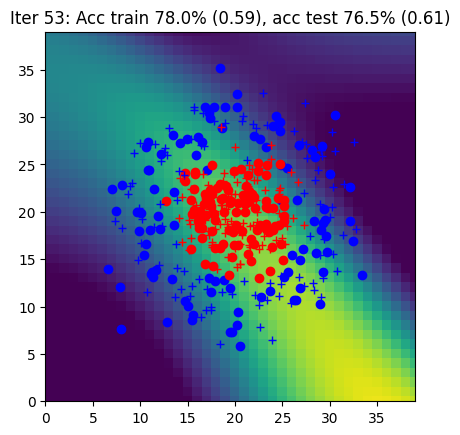

Iter 54: Acc train 78.5% (0.59), acc test 76.5% (0.61)


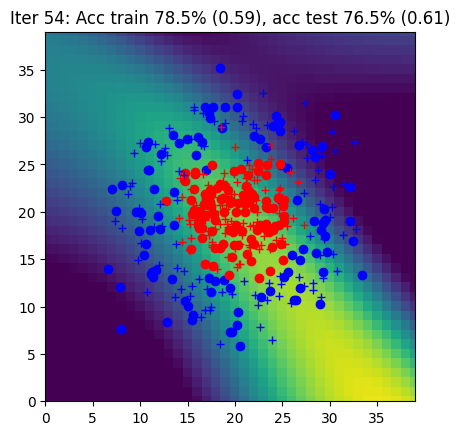

Iter 55: Acc train 78.0% (0.59), acc test 77.0% (0.60)


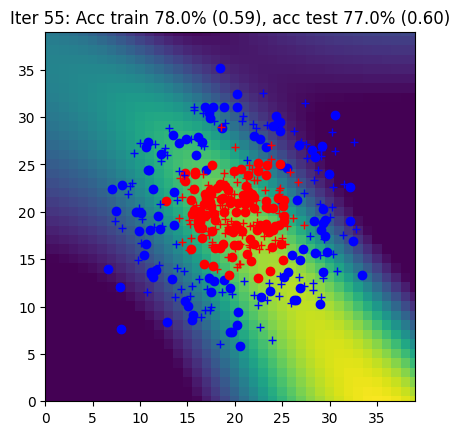

Iter 56: Acc train 78.5% (0.58), acc test 77.0% (0.60)


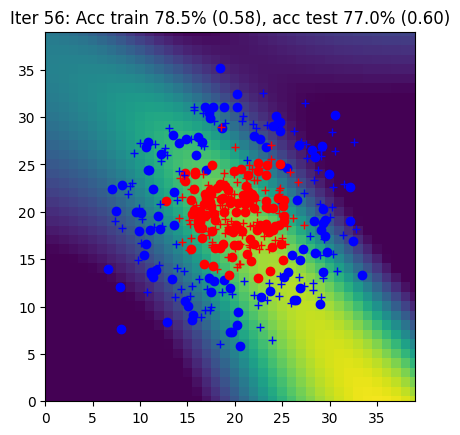

Iter 57: Acc train 80.5% (0.58), acc test 75.5% (0.60)


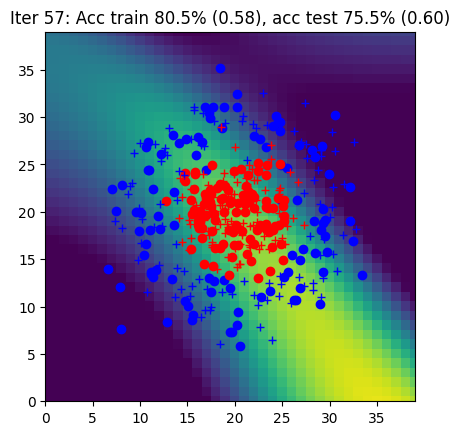

Iter 58: Acc train 80.5% (0.58), acc test 75.5% (0.59)


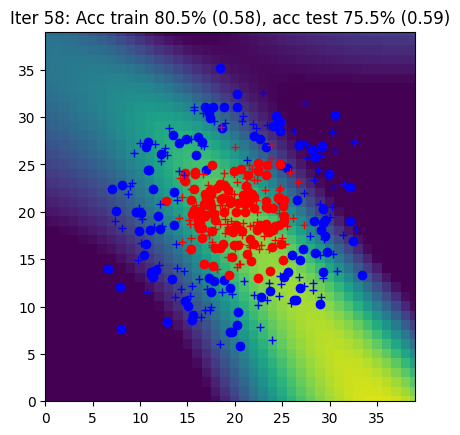

Iter 59: Acc train 80.5% (0.57), acc test 75.5% (0.59)


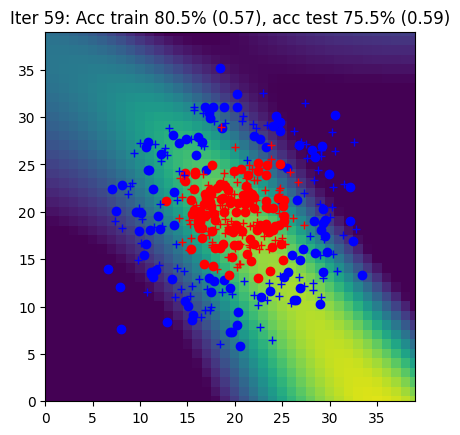

Iter 60: Acc train 80.5% (0.57), acc test 75.0% (0.59)


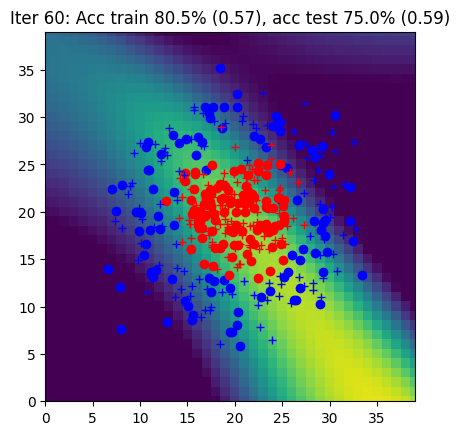

Iter 61: Acc train 80.5% (0.57), acc test 75.0% (0.59)


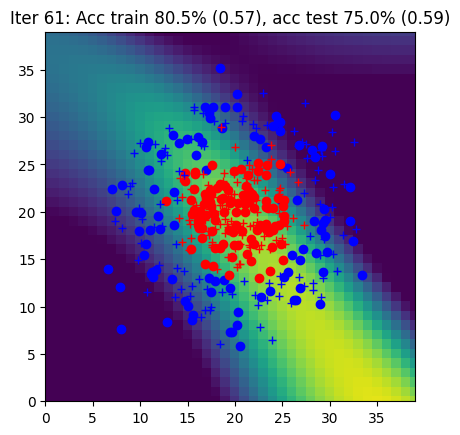

Iter 62: Acc train 81.5% (0.56), acc test 75.0% (0.58)


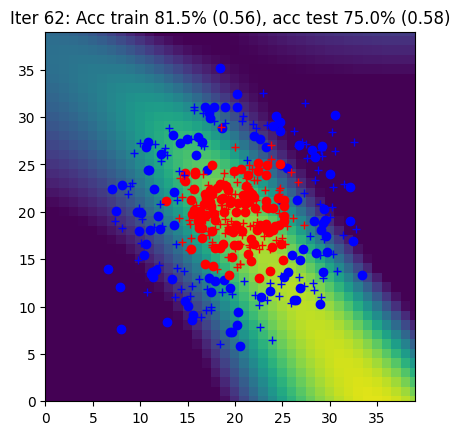

Iter 63: Acc train 81.0% (0.56), acc test 76.0% (0.58)


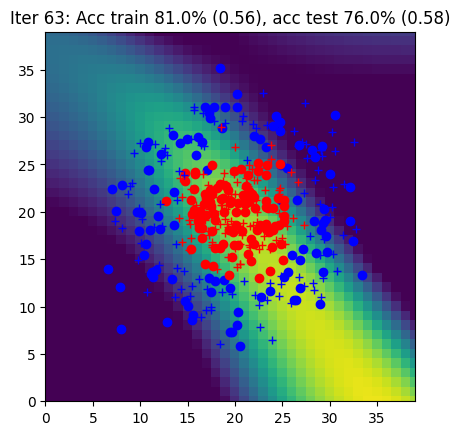

Iter 64: Acc train 81.0% (0.55), acc test 76.0% (0.58)


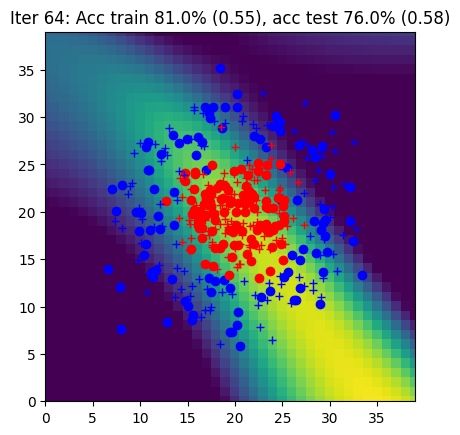

Iter 65: Acc train 81.0% (0.55), acc test 75.5% (0.57)


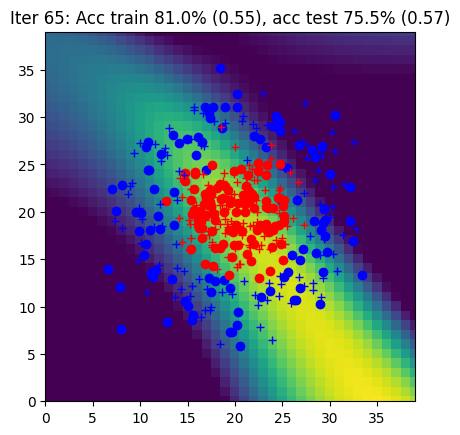

Iter 66: Acc train 81.5% (0.55), acc test 75.5% (0.57)


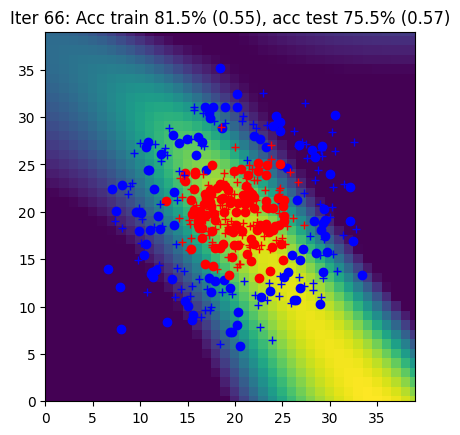

Iter 67: Acc train 81.5% (0.54), acc test 75.5% (0.57)


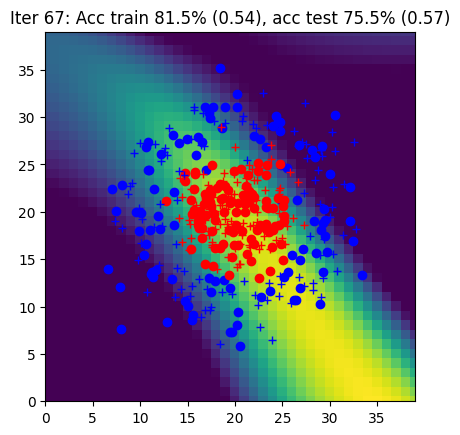

Iter 68: Acc train 81.0% (0.54), acc test 76.5% (0.56)


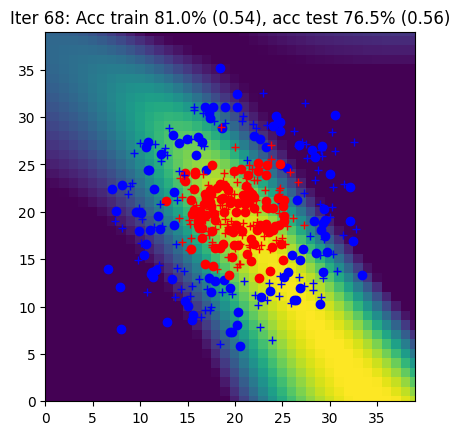

Iter 69: Acc train 82.5% (0.54), acc test 76.5% (0.56)


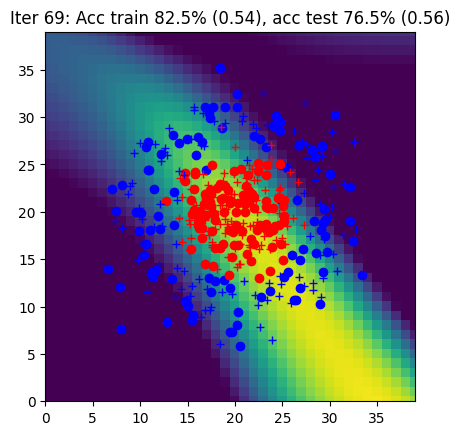

Iter 70: Acc train 82.0% (0.53), acc test 77.0% (0.56)


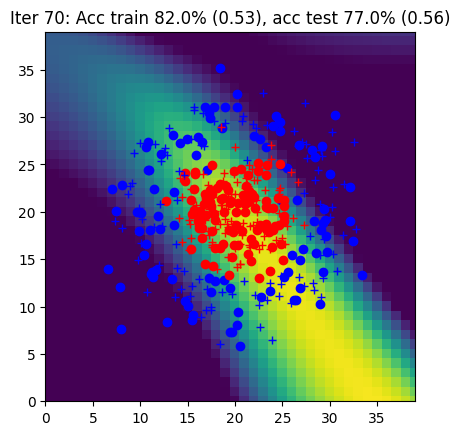

Iter 71: Acc train 82.0% (0.53), acc test 76.5% (0.55)


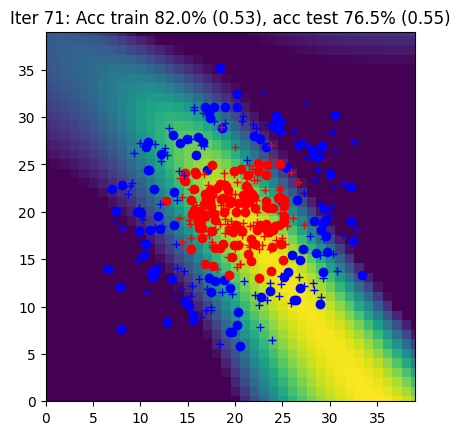

Iter 72: Acc train 82.0% (0.53), acc test 76.0% (0.55)


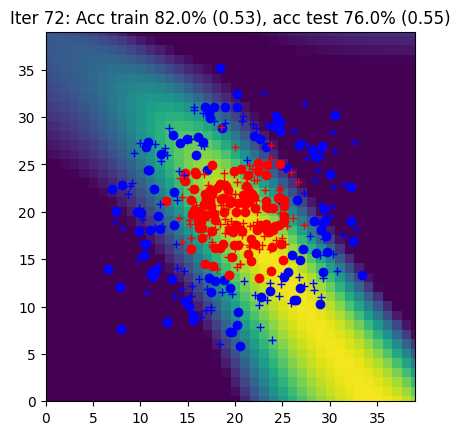

Iter 73: Acc train 82.0% (0.52), acc test 76.5% (0.55)


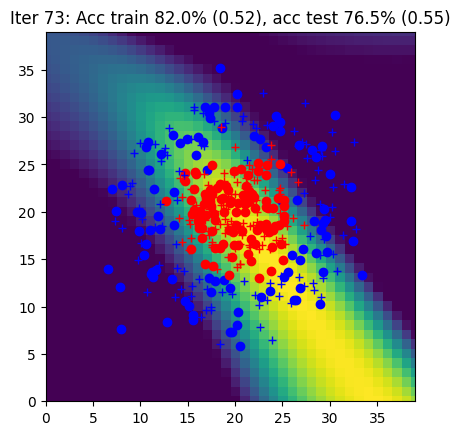

Iter 74: Acc train 82.5% (0.52), acc test 76.5% (0.55)


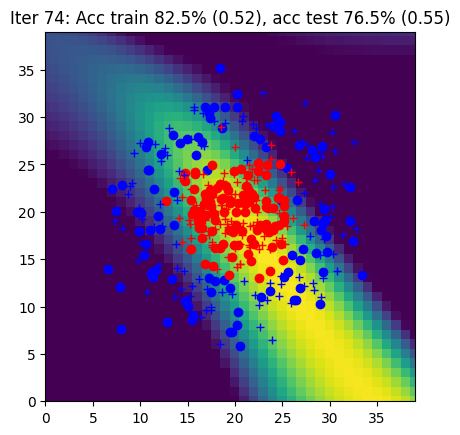

Iter 75: Acc train 81.0% (0.52), acc test 75.0% (0.54)


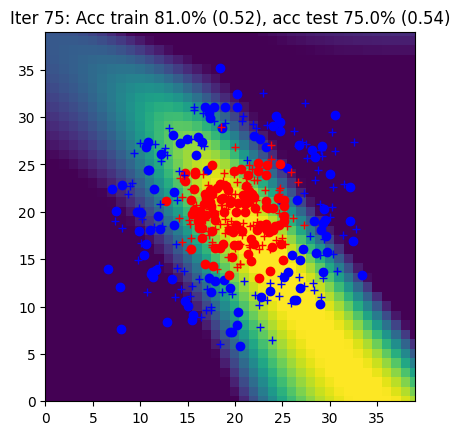

Iter 76: Acc train 81.5% (0.51), acc test 77.0% (0.54)


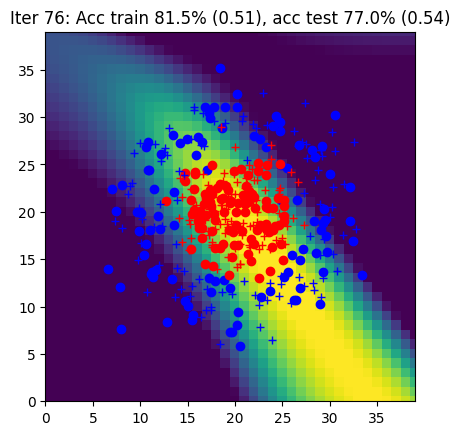

Iter 77: Acc train 81.5% (0.51), acc test 76.5% (0.54)


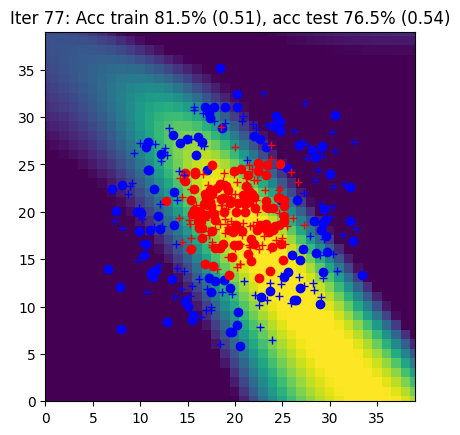

Iter 78: Acc train 83.0% (0.51), acc test 76.0% (0.53)


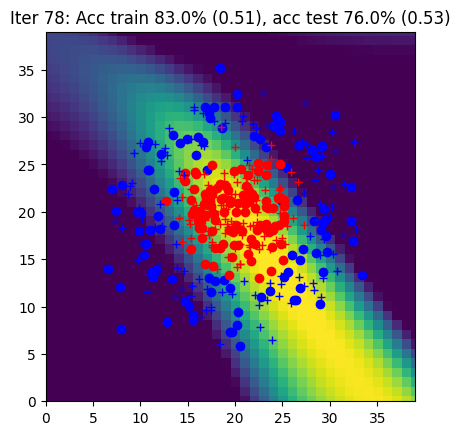

Iter 79: Acc train 83.0% (0.50), acc test 76.0% (0.53)


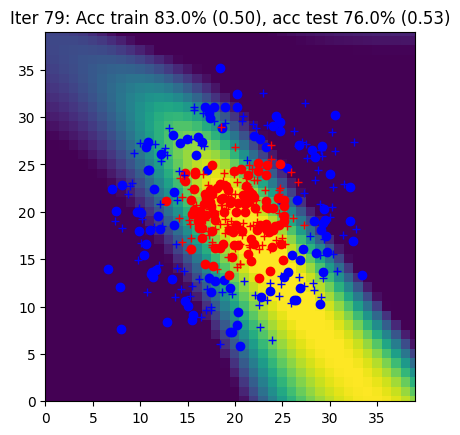

Iter 80: Acc train 82.5% (0.50), acc test 76.5% (0.53)


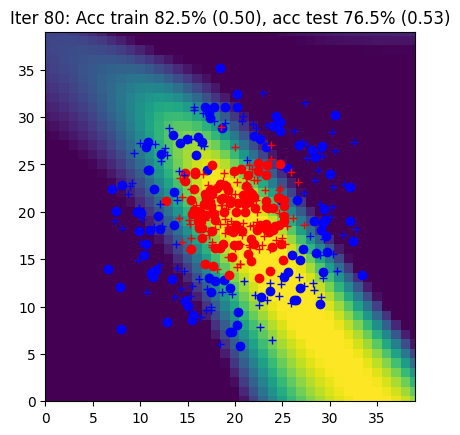

Iter 81: Acc train 83.0% (0.50), acc test 76.0% (0.53)


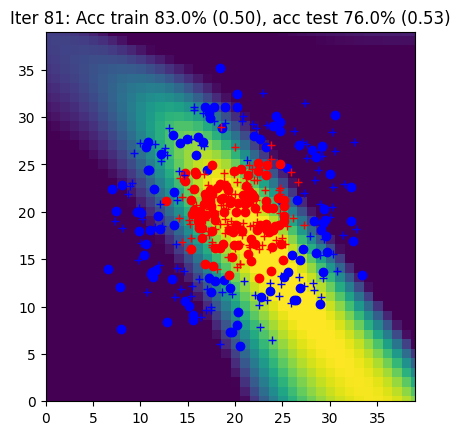

Iter 82: Acc train 83.0% (0.49), acc test 77.0% (0.53)


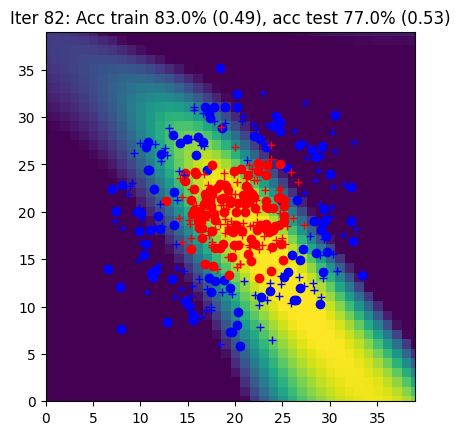

Iter 83: Acc train 82.5% (0.49), acc test 75.5% (0.52)


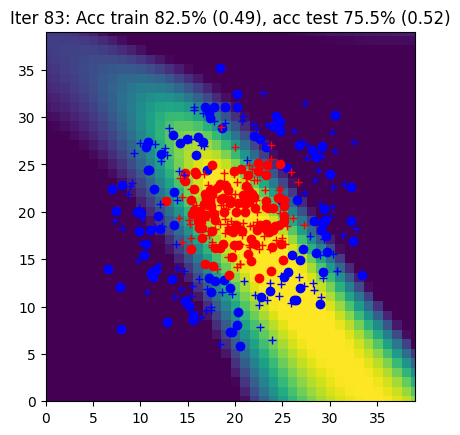

Iter 84: Acc train 83.0% (0.49), acc test 76.5% (0.52)


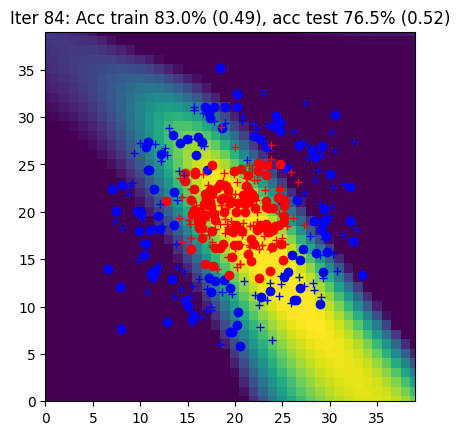

Iter 85: Acc train 83.5% (0.48), acc test 76.5% (0.52)


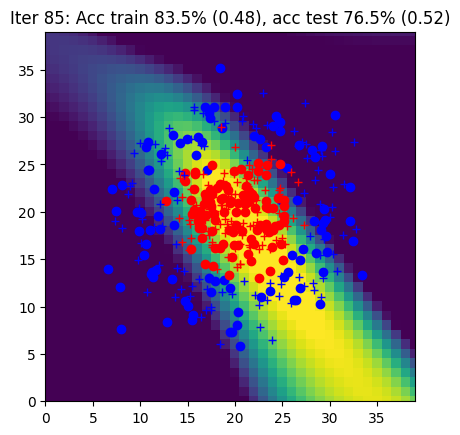

Iter 86: Acc train 82.0% (0.48), acc test 76.5% (0.51)


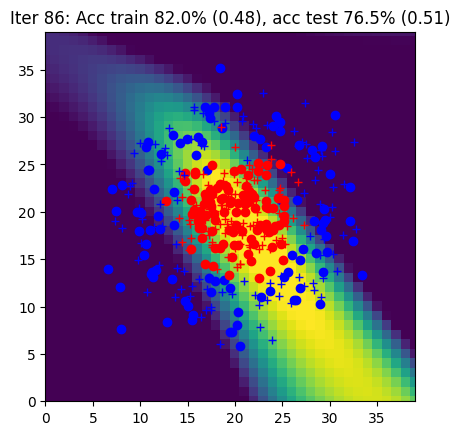

Iter 87: Acc train 82.0% (0.48), acc test 76.5% (0.51)


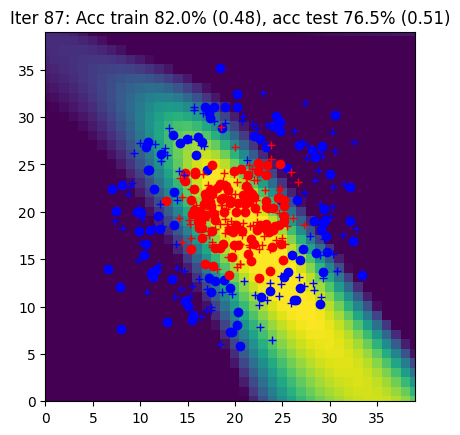

Iter 88: Acc train 83.5% (0.47), acc test 77.0% (0.51)


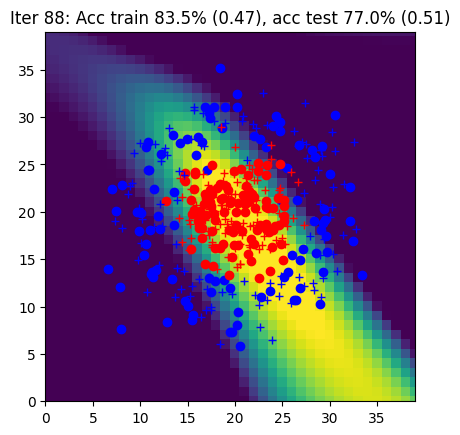

Iter 89: Acc train 83.5% (0.47), acc test 77.0% (0.51)


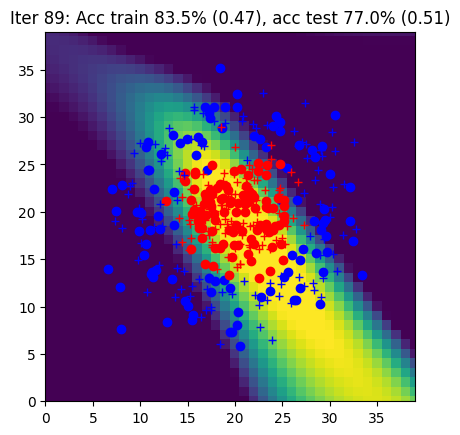

Iter 90: Acc train 83.5% (0.47), acc test 76.0% (0.50)


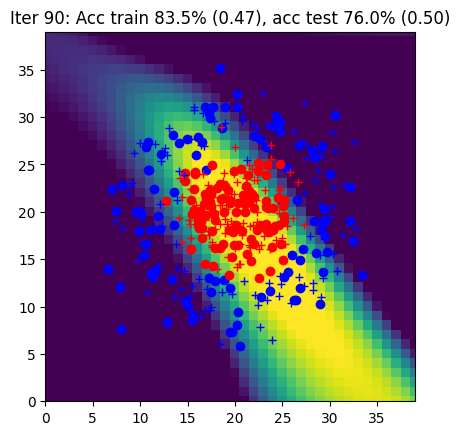

Iter 91: Acc train 82.5% (0.47), acc test 76.0% (0.50)


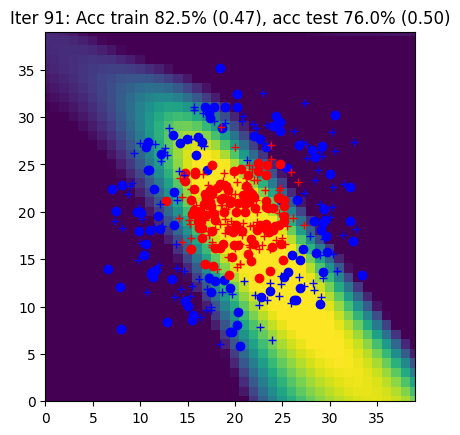

Iter 92: Acc train 82.5% (0.46), acc test 76.5% (0.50)


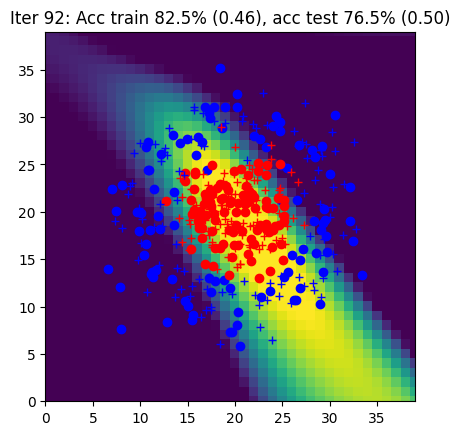

Iter 93: Acc train 83.5% (0.46), acc test 77.0% (0.50)


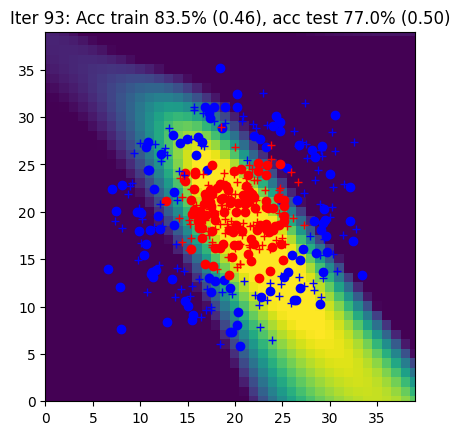

Iter 94: Acc train 83.5% (0.46), acc test 77.0% (0.49)


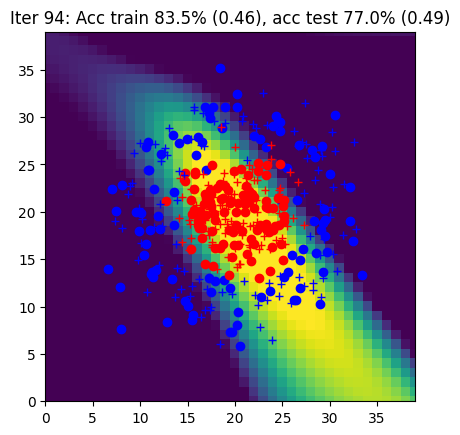

Iter 95: Acc train 83.5% (0.45), acc test 77.0% (0.49)


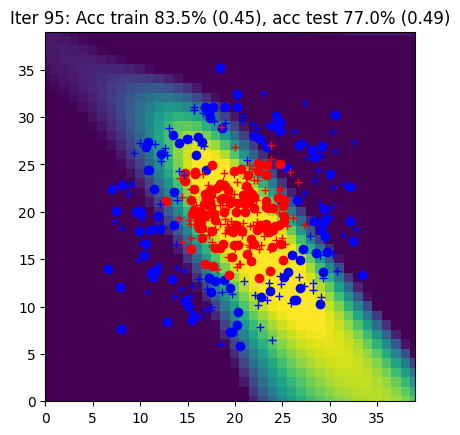

Iter 96: Acc train 83.5% (0.45), acc test 77.0% (0.49)


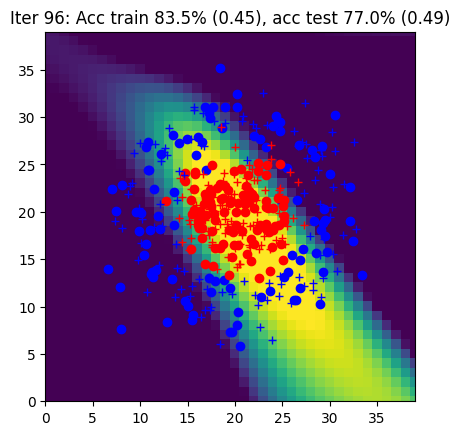

Iter 97: Acc train 83.5% (0.45), acc test 77.0% (0.49)


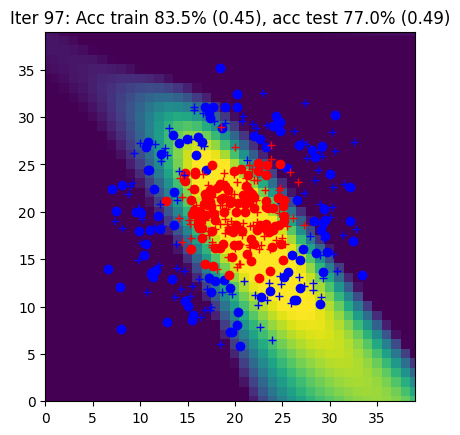

Iter 98: Acc train 83.0% (0.45), acc test 77.0% (0.48)


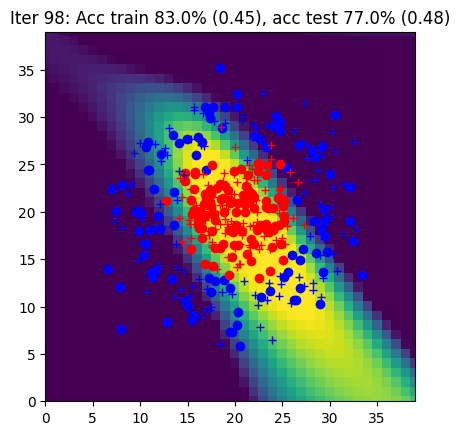

Iter 99: Acc train 83.0% (0.44), acc test 77.0% (0.48)


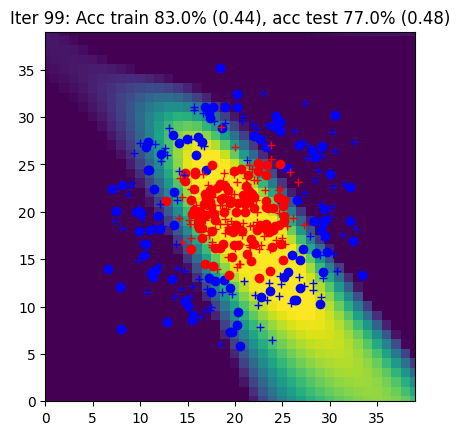

Iter 100: Acc train 83.0% (0.44), acc test 77.5% (0.48)


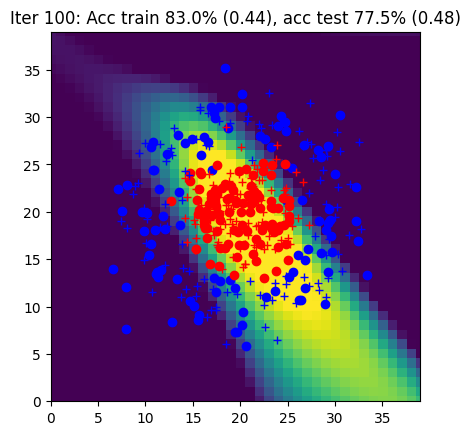

Iter 101: Acc train 83.5% (0.44), acc test 77.5% (0.47)


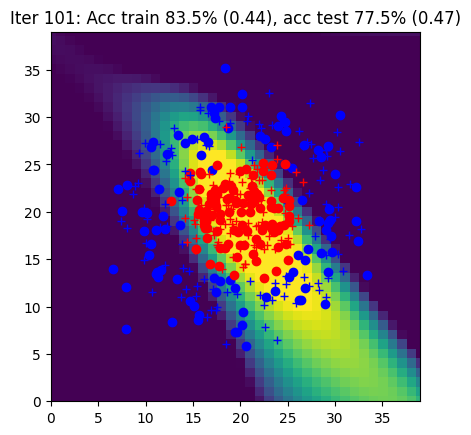

Iter 102: Acc train 84.0% (0.43), acc test 77.5% (0.47)


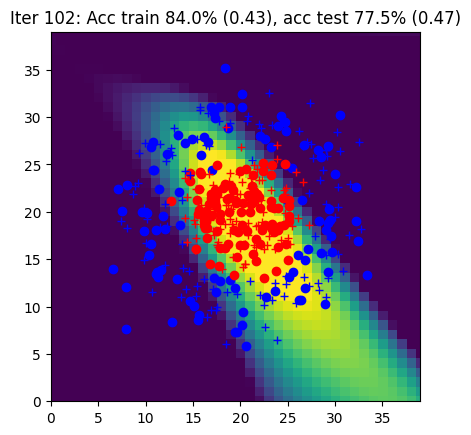

Iter 103: Acc train 84.0% (0.43), acc test 77.5% (0.47)


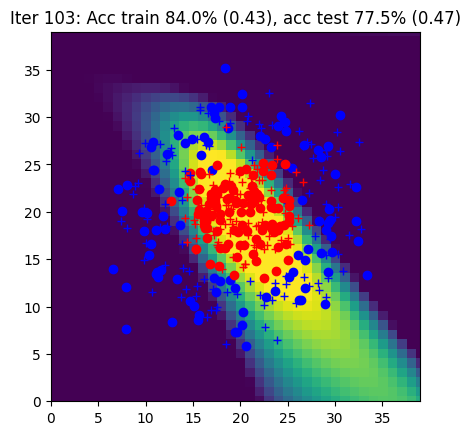

Iter 104: Acc train 85.0% (0.43), acc test 77.5% (0.46)


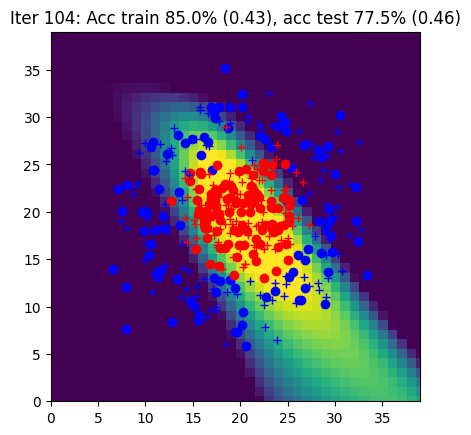

Iter 105: Acc train 84.5% (0.42), acc test 78.0% (0.46)


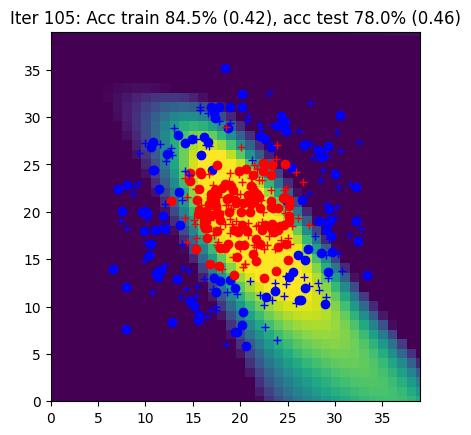

Iter 106: Acc train 85.0% (0.42), acc test 78.5% (0.46)


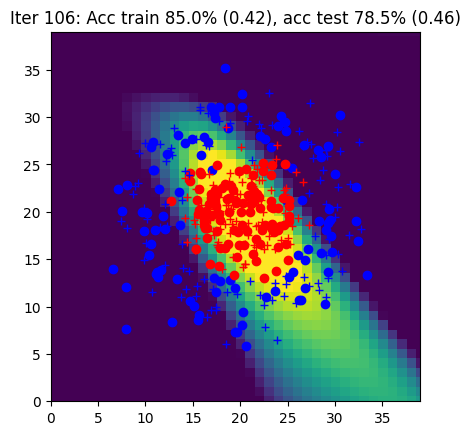

Iter 107: Acc train 85.0% (0.42), acc test 78.0% (0.45)


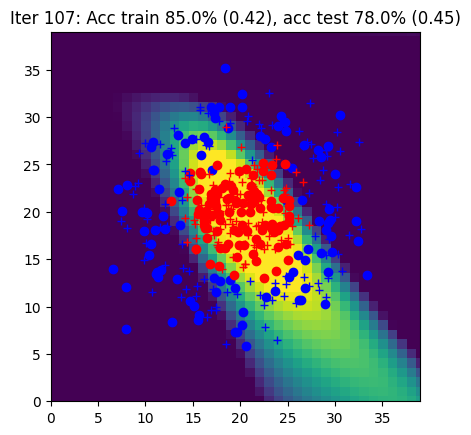

Iter 108: Acc train 85.5% (0.41), acc test 79.0% (0.45)


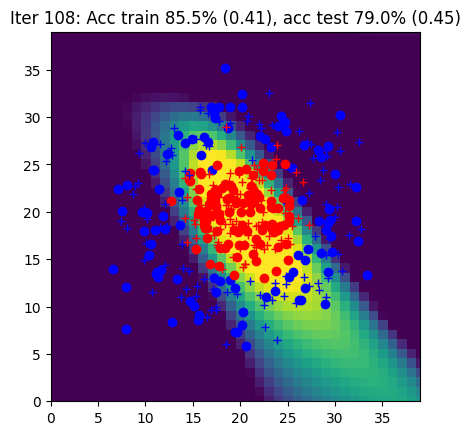

Iter 109: Acc train 85.5% (0.41), acc test 79.5% (0.44)


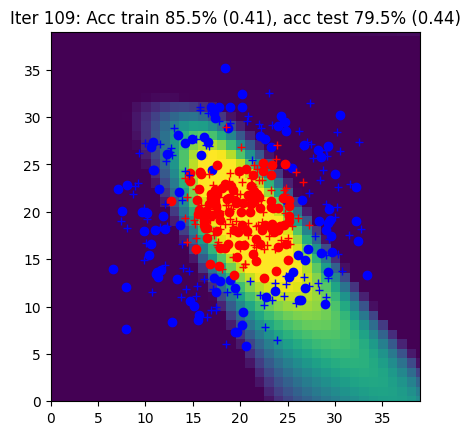

Iter 110: Acc train 84.5% (0.41), acc test 79.5% (0.44)


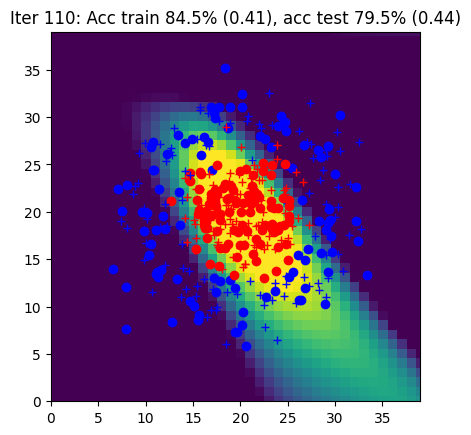

Iter 111: Acc train 84.5% (0.40), acc test 79.5% (0.44)


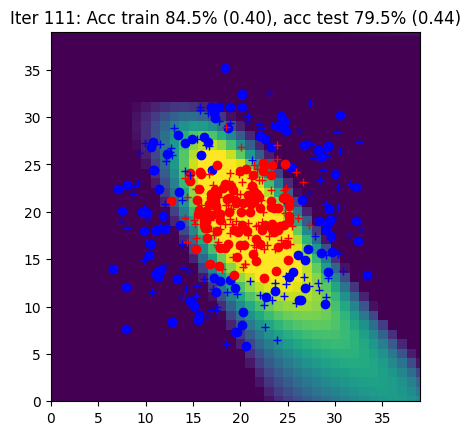

Iter 112: Acc train 84.5% (0.40), acc test 80.5% (0.43)


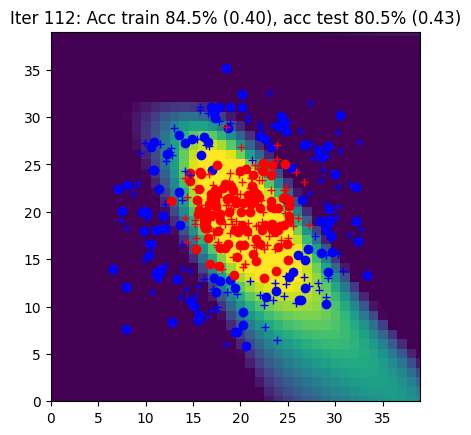

Iter 113: Acc train 84.5% (0.39), acc test 80.5% (0.43)


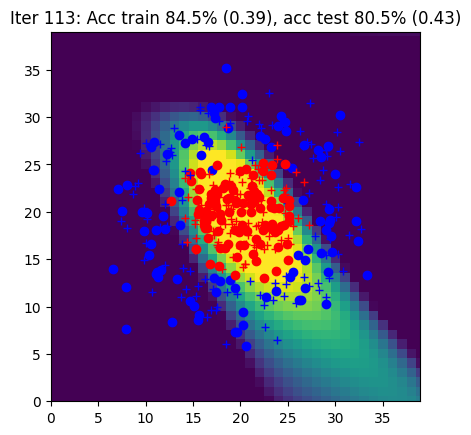

Iter 114: Acc train 84.5% (0.39), acc test 81.5% (0.42)


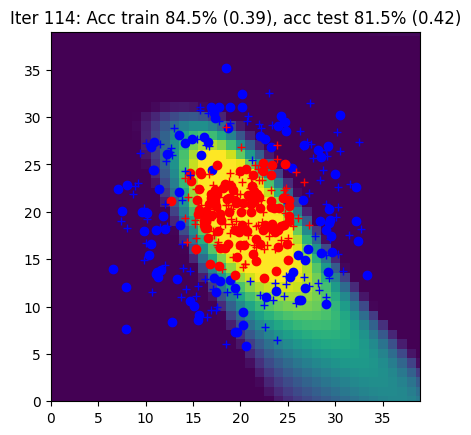

Iter 115: Acc train 85.0% (0.39), acc test 82.0% (0.42)


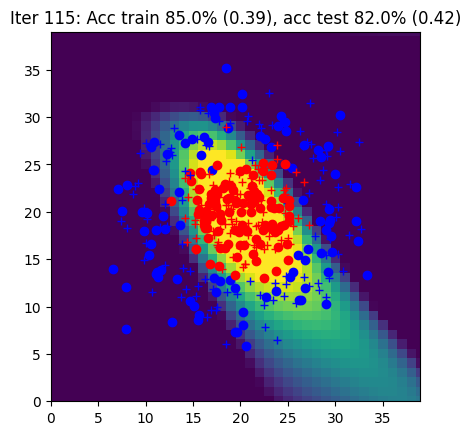

Iter 116: Acc train 85.0% (0.38), acc test 82.0% (0.42)


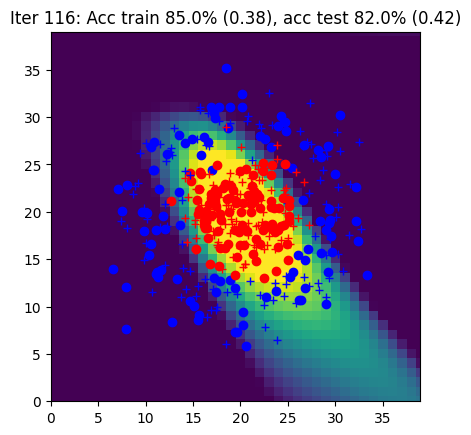

Iter 117: Acc train 86.0% (0.38), acc test 82.0% (0.41)


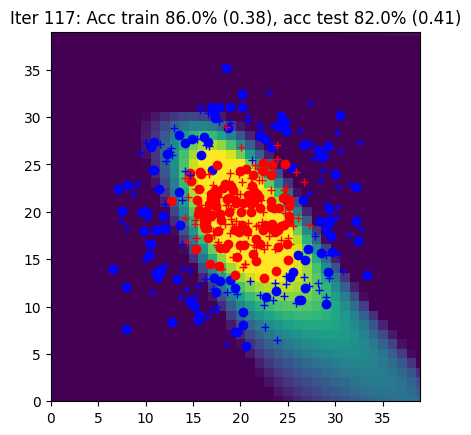

Iter 118: Acc train 86.0% (0.37), acc test 82.5% (0.41)


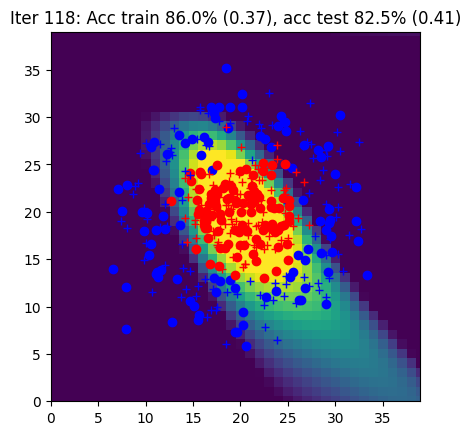

Iter 119: Acc train 86.0% (0.37), acc test 83.0% (0.40)


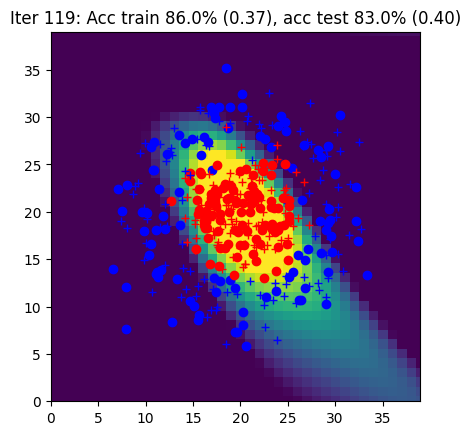

Iter 120: Acc train 87.0% (0.37), acc test 83.5% (0.40)


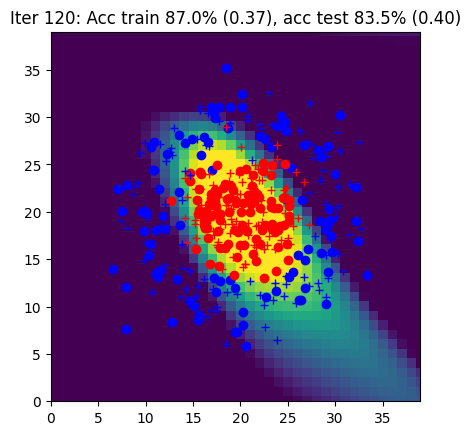

Iter 121: Acc train 87.0% (0.36), acc test 83.5% (0.39)


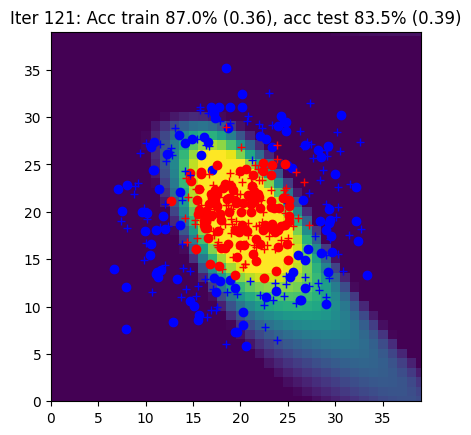

Iter 122: Acc train 87.0% (0.36), acc test 83.5% (0.39)


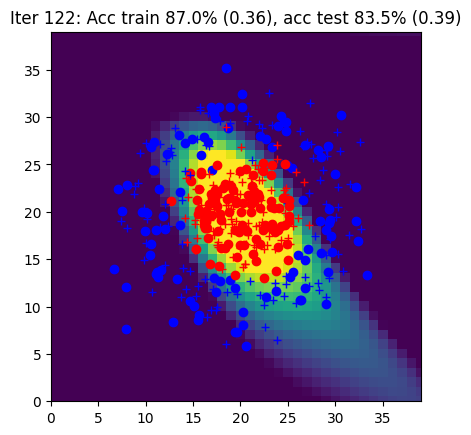

Iter 123: Acc train 87.0% (0.35), acc test 83.5% (0.38)


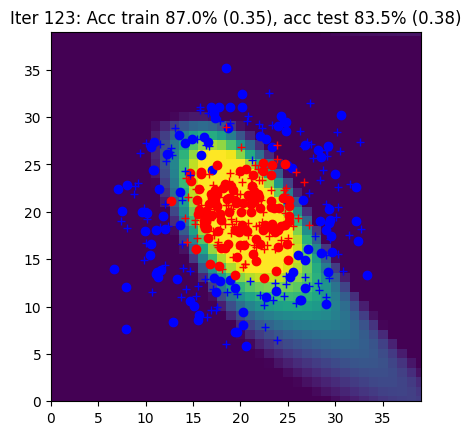

Iter 124: Acc train 87.5% (0.35), acc test 84.0% (0.38)


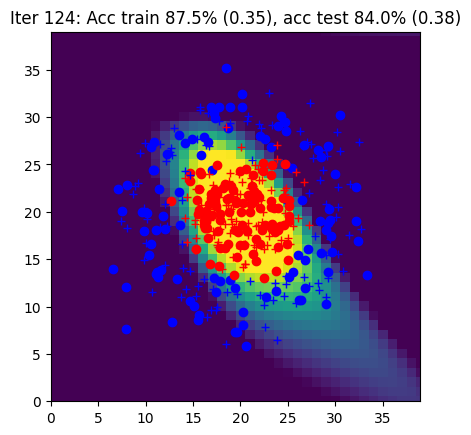

Iter 125: Acc train 88.5% (0.34), acc test 85.5% (0.37)


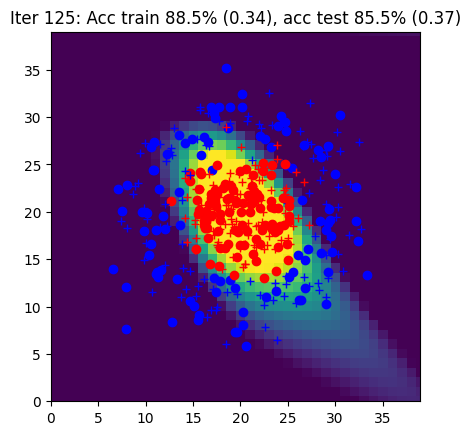

Iter 126: Acc train 88.5% (0.34), acc test 85.5% (0.37)


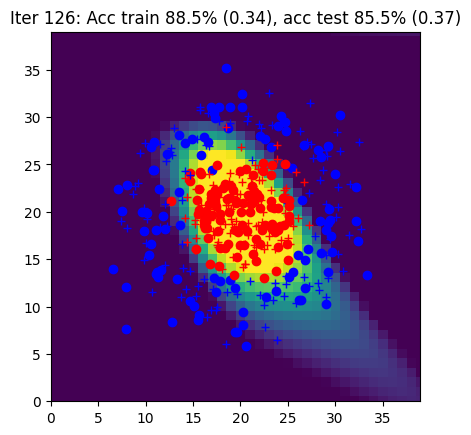

Iter 127: Acc train 88.5% (0.34), acc test 86.5% (0.36)


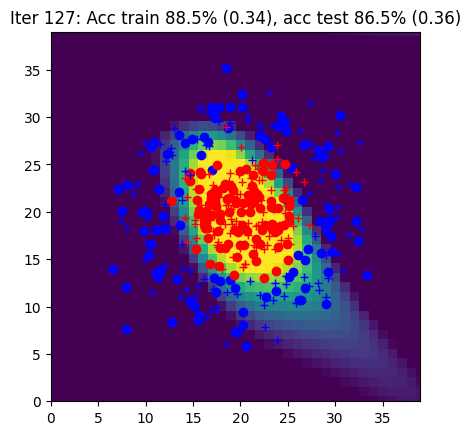

Iter 128: Acc train 91.0% (0.33), acc test 88.0% (0.36)


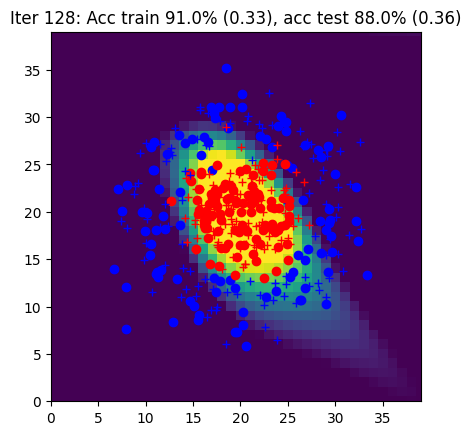

Iter 129: Acc train 91.5% (0.33), acc test 89.0% (0.36)


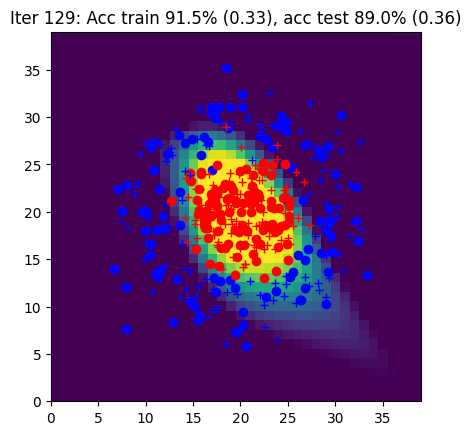

Iter 130: Acc train 92.0% (0.32), acc test 89.0% (0.35)


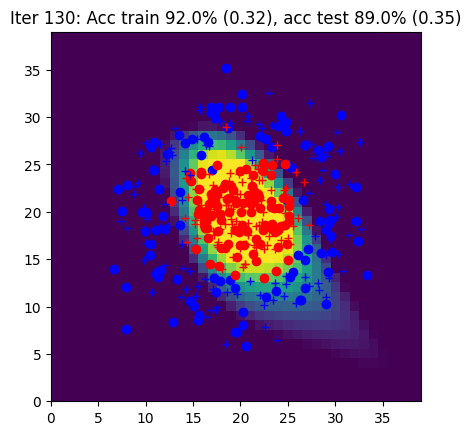

Iter 131: Acc train 91.5% (0.32), acc test 90.0% (0.35)


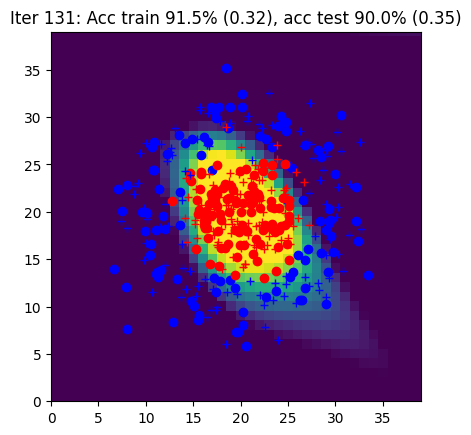

Iter 132: Acc train 92.5% (0.31), acc test 90.0% (0.34)


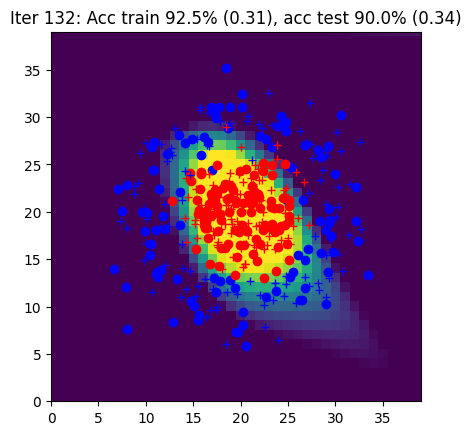

Iter 133: Acc train 93.0% (0.31), acc test 89.5% (0.34)


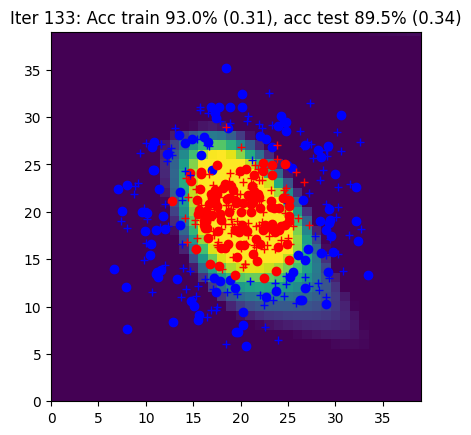

Iter 134: Acc train 93.0% (0.31), acc test 90.0% (0.33)


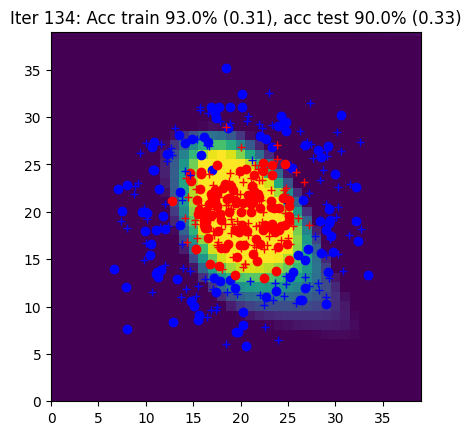

Iter 135: Acc train 93.5% (0.30), acc test 90.5% (0.33)


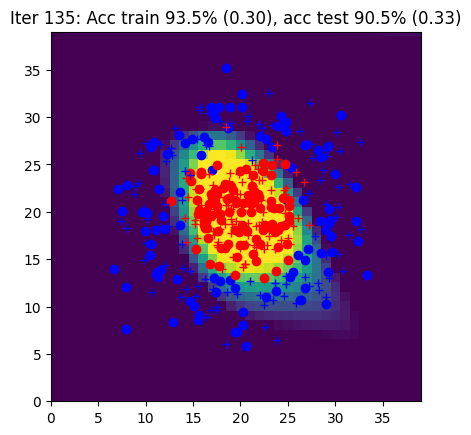

Iter 136: Acc train 93.5% (0.30), acc test 91.0% (0.32)


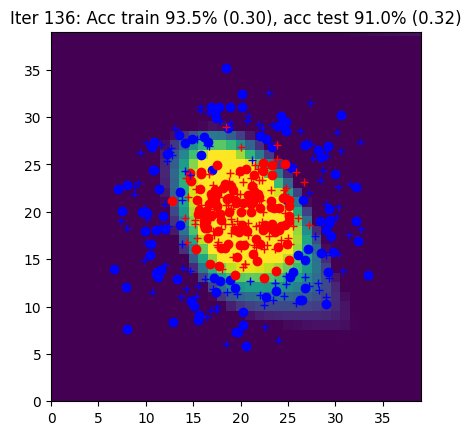

Iter 137: Acc train 93.5% (0.30), acc test 91.5% (0.32)


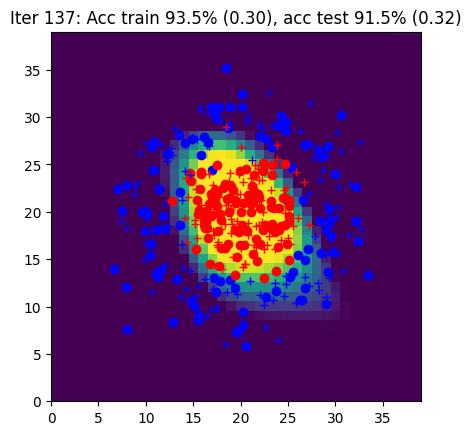

Iter 138: Acc train 93.5% (0.29), acc test 91.5% (0.32)


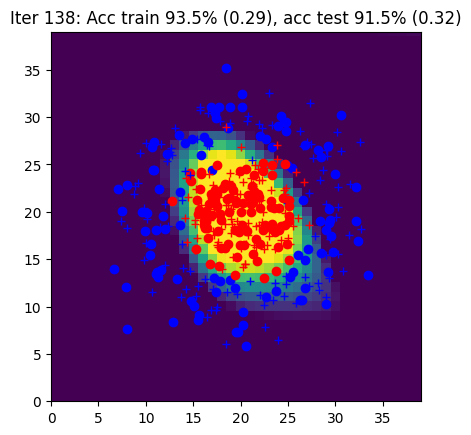

Iter 139: Acc train 94.0% (0.29), acc test 92.0% (0.31)


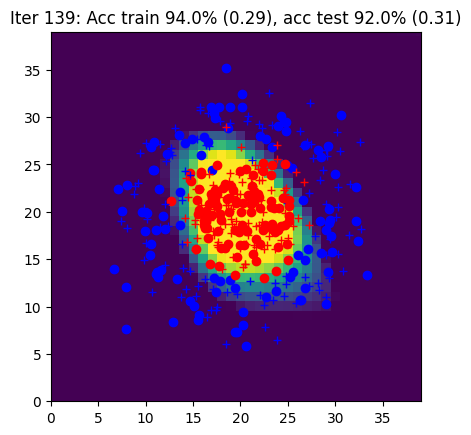

Iter 140: Acc train 93.5% (0.29), acc test 92.0% (0.31)


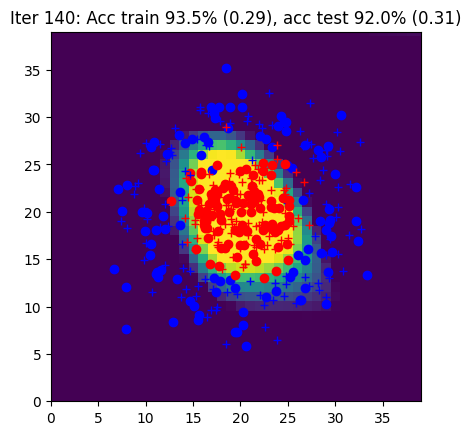

Iter 141: Acc train 93.5% (0.28), acc test 92.5% (0.30)


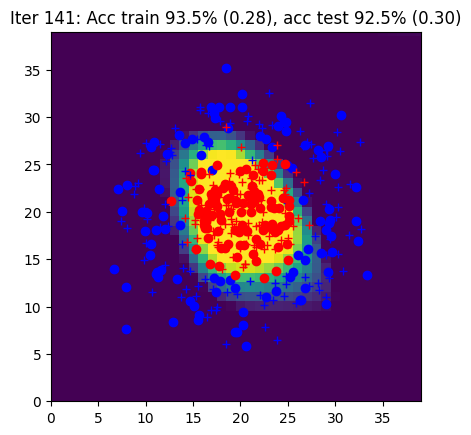

Iter 142: Acc train 95.5% (0.28), acc test 92.0% (0.30)


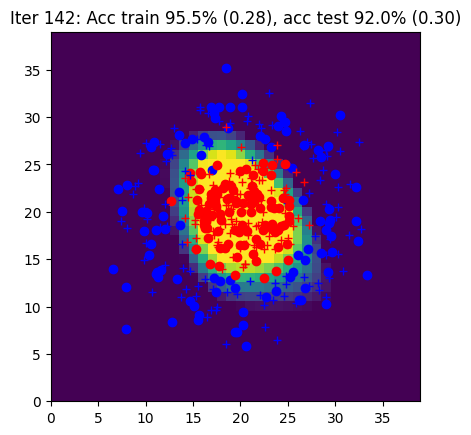

Iter 143: Acc train 95.5% (0.28), acc test 92.0% (0.30)


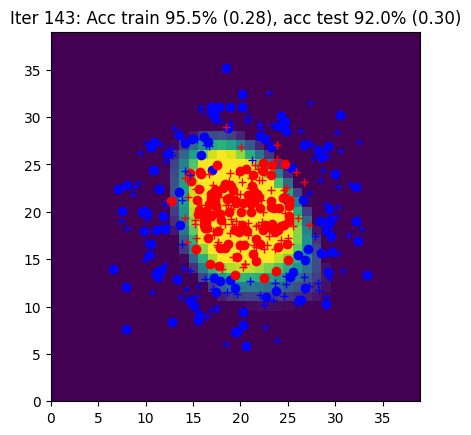

Iter 144: Acc train 96.0% (0.27), acc test 92.5% (0.29)


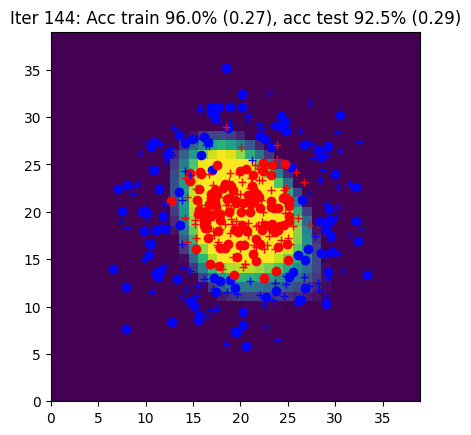

Iter 145: Acc train 96.0% (0.27), acc test 93.0% (0.29)


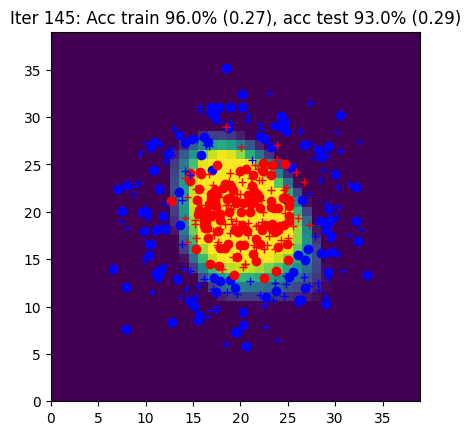

Iter 146: Acc train 95.0% (0.27), acc test 92.5% (0.29)


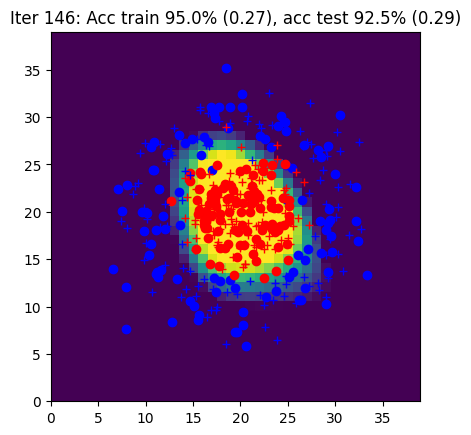

Iter 147: Acc train 96.0% (0.26), acc test 93.0% (0.29)


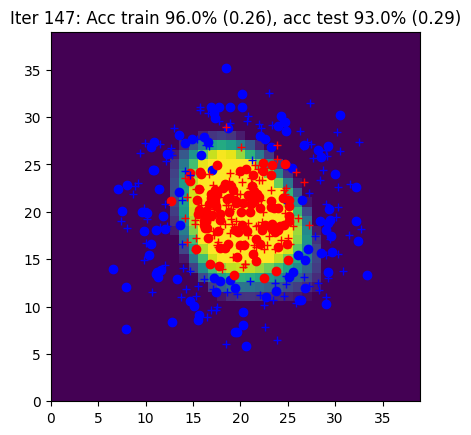

Iter 148: Acc train 96.0% (0.26), acc test 93.0% (0.28)


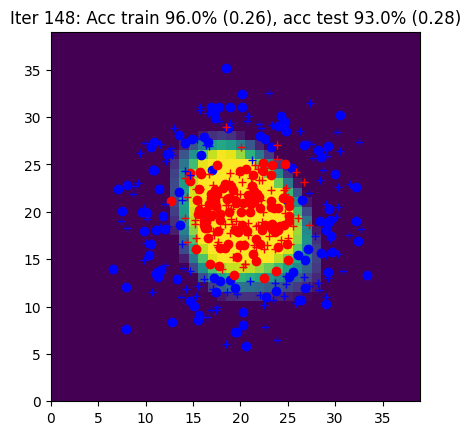

Iter 149: Acc train 96.0% (0.26), acc test 94.0% (0.28)


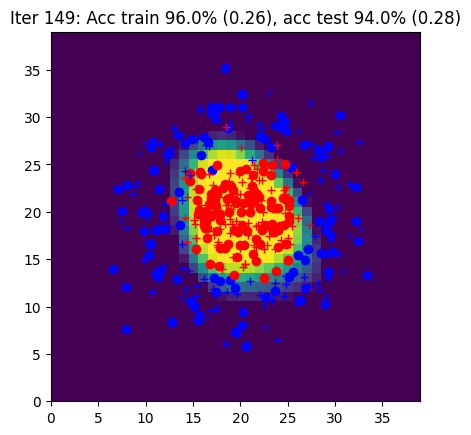

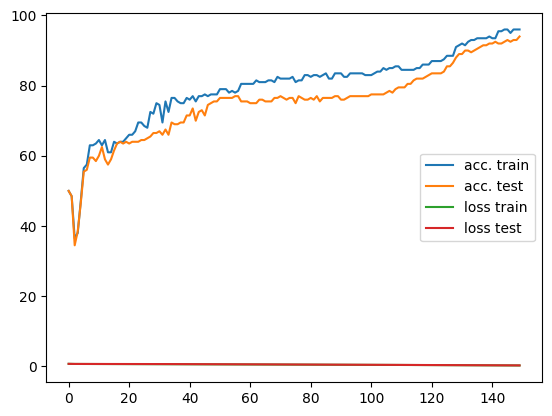

In [17]:
# init
data = CirclesData()
data.plot_data()
N = data.Xtrain.shape[0]
Nbatch = 10
nx = data.Xtrain.shape[1]
nh = 10
ny = data.Ytrain.shape[1]
eta = 0.03

model, loss, optim = init_model(nx, nh, ny, eta)

curves = [[],[], [], []]

# epoch
for iteration in range(150):

    # permute
    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    #####################
    ## Your code  here ##
    #####################
    # batches
    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j+1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        # write the optimization algorithm on the batch (X,Y)
        # using the functions: loss_accuracy
        # the forward with the predict method from the model
        # the backward function with autograd
        # and then an optimization step
        optim.zero_grad()
        L = loss(model(X), Y)
        L.backward()
        optim.step()

    ####################
    ##      FIN        #
    ####################


    Yhat_train = model(data.Xtrain)
    Yhat_test = model(data.Xtest)
    Ltrain, acctrain = loss_accuracy(loss, Yhat_train, data.Ytrain)
    Ltest, acctest = loss_accuracy(loss, Yhat_test, data.Ytest)
    Ygrid = model(data.Xgrid)

    title = 'Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})'.format(iteration, acctrain, Ltrain, acctest, Ltest)
    print(title)
    data.plot_data_with_grid(torch.nn.Softmax(dim=1)(Ygrid.detach()), title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 5 : MNIST

Apply the code from previous part code to the MNIST dataset.

Iter 0: Acc train 86.1% (0.51), acc test 86.4% (0.50)
Iter 1: Acc train 87.6% (0.45), acc test 88.2% (0.42)
Iter 2: Acc train 87.9% (0.41), acc test 88.2% (0.40)
Iter 3: Acc train 86.5% (0.45), acc test 86.5% (0.44)
Iter 4: Acc train 88.4% (0.39), acc test 88.8% (0.37)
Iter 5: Acc train 88.7% (0.38), acc test 89.1% (0.37)
Iter 6: Acc train 87.9% (0.41), acc test 88.0% (0.40)
Iter 7: Acc train 87.5% (0.42), acc test 87.6% (0.42)
Iter 8: Acc train 88.0% (0.40), acc test 88.1% (0.40)
Iter 9: Acc train 89.6% (0.36), acc test 89.4% (0.35)
Iter 10: Acc train 89.6% (0.35), acc test 89.8% (0.34)
Iter 11: Acc train 88.4% (0.38), acc test 88.4% (0.38)
Iter 12: Acc train 89.7% (0.35), acc test 89.5% (0.35)
Iter 13: Acc train 88.9% (0.37), acc test 89.0% (0.36)
Iter 14: Acc train 89.8% (0.33), acc test 89.5% (0.33)
Iter 15: Acc train 89.3% (0.36), acc test 89.2% (0.35)
Iter 16: Acc train 90.2% (0.33), acc test 90.6% (0.32)
Iter 17: Acc train 88.7% (0.37), acc test 88.8% (0.37)
Iter 18: Acc train 8

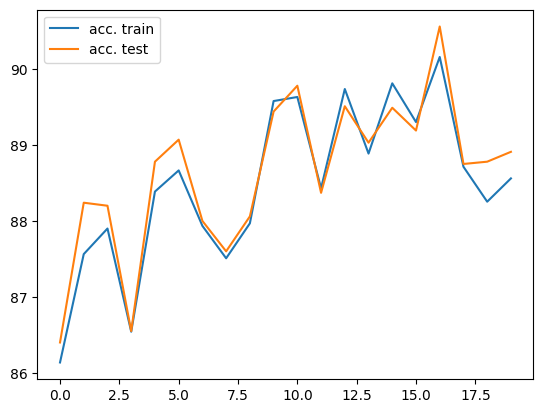

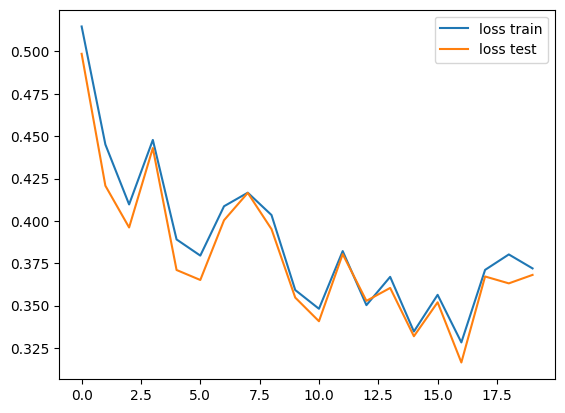

In [18]:
# init
data = MNISTData()
N = data.Xtrain.shape[0]
Nbatch = 100
nx = data.Xtrain.shape[1]
nh = 100
ny = data.Ytrain.shape[1]
eta = 0.03

model, loss, optim = init_model(nx, nh, ny, eta)

curves = [[],[], [], []]

for iteration in range(20):

    perm = np.random.permutation(N)
    Xtrain = data.Xtrain[perm, :]
    Ytrain = data.Ytrain[perm, :]

    for j in range(N // Nbatch):

        indsBatch = range(j * Nbatch, (j+1) * Nbatch)
        X = Xtrain[indsBatch, :]
        Y = Ytrain[indsBatch, :]

        optim.zero_grad()
        L = loss(model(X), Y)
        L.backward()
        optim.step()

    with torch.no_grad():
        Ltrain, acctrain = loss_accuracy(loss, model(data.Xtrain), data.Ytrain)
        Ltest, acctest = loss_accuracy(loss, model(data.Xtest), data.Ytest)

    title = 'Iter {}: Acc train {:.1f}% ({:.2f}), acc test {:.1f}% ({:.2f})'.format(iteration, acctrain, Ltrain, acctest, Ltest)
    print(title)

    curves[0].append(acctrain)
    curves[1].append(acctest)
    curves[2].append(Ltrain)
    curves[3].append(Ltest)

fig = plt.figure()
plt.plot(curves[0], label="acc. train")
plt.plot(curves[1], label="acc. test")
plt.legend()
plt.show()
fig = plt.figure()
plt.plot(curves[2], label="loss train")
plt.plot(curves[3], label="loss test")
plt.legend()
plt.show()

# Part 6: Bonus: SVM


Train a SVM model on the Circles dataset.

Ideas :
- First try a linear SVM (sklearn.svm.LinearSVC dans scikit-learn). Does it work well ? Why ?
- Then try more complex kernels (sklearn.svm.SVC). Which one is the best ? why ?
- Does the parameter C of regularization have an impact? Why ?

In [19]:
# data
data = CirclesData()
Xtrain = data.Xtrain.numpy()
Ytrain = data.Ytrain[:, 0].numpy()

Xgrid = data.Xgrid.numpy()

Xtest = data.Xtest.numpy()
Ytest = data.Ytest[:, 0].numpy()

def plot_svm_predictions(data, predictions):
      plt.figure(2)
      plt.clf()
      plt.imshow(np.reshape(predictions, (40,40)))
      plt.plot(data._Xtrain[data._Ytrain[:,0] == 1,0]*10+20, data._Xtrain[data._Ytrain[:,0] == 1,1]*10+20, 'bo', label="Train")
      plt.plot(data._Xtrain[data._Ytrain[:,1] == 1,0]*10+20, data._Xtrain[data._Ytrain[:,1] == 1,1]*10+20, 'ro')
      plt.plot(data._Xtest[data._Ytest[:,0] == 1,0]*10+20, data._Xtest[data._Ytest[:,0] == 1,1]*10+20, 'b+', label="Test")
      plt.plot(data._Xtest[data._Ytest[:,1] == 1,0]*10+20, data._Xtest[data._Ytest[:,1] == 1,1]*10+20, 'r+')
      plt.xlim(0,39)
      plt.ylim(0,39)
      plt.clim(0.3,0.7)
      plt.draw()
      plt.pause(1e-3)

In [20]:
import sklearn.svm

############################
### Your code here   #######
### Train the SVM    #######
## See https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
## and https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html
############################

svm = sklearn.svm.SVC(kernel="rbf", C=1.0)
svm.fit(Xtrain, Ytrain)

###########################

SVC()

Accuracy : 94.00


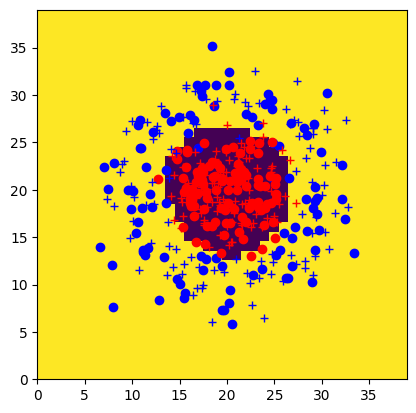

LinearSVC : train 50.00 / test 53.00


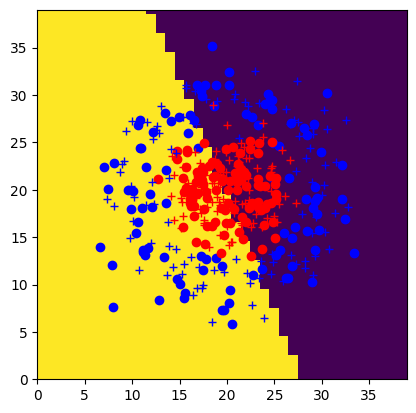


SVC {'kernel': 'linear'} : train 63.50 / test 62.00 / support vectors 199
SVC {'kernel': 'poly', 'degree': 2} : train 95.50 / test 95.50 / support vectors 45
SVC {'kernel': 'poly', 'degree': 3} : train 57.50 / test 54.50 / support vectors 192
SVC {'kernel': 'rbf'} : train 96.00 / test 94.00 / support vectors 55
SVC {'kernel': 'sigmoid'} : train 57.50 / test 65.00 / support vectors 143

SVC rbf C=0.001 : train 95.50 / test 95.00 / support vectors 200


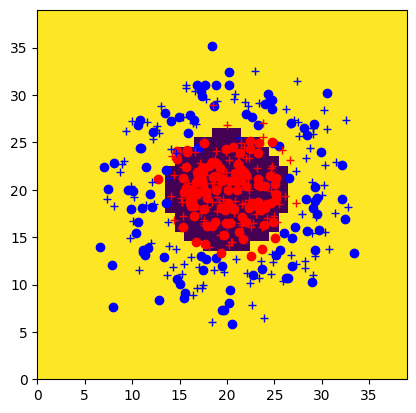

SVC rbf C=0.01 : train 95.50 / test 95.00 / support vectors 200


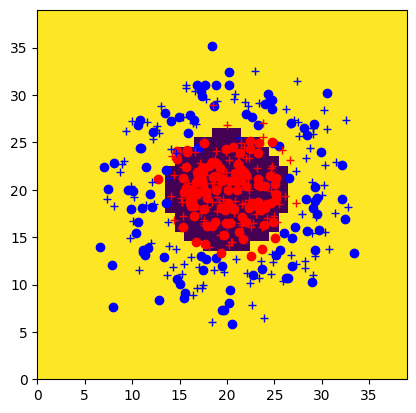

SVC rbf C=0.1 : train 95.50 / test 95.00 / support vectors 126


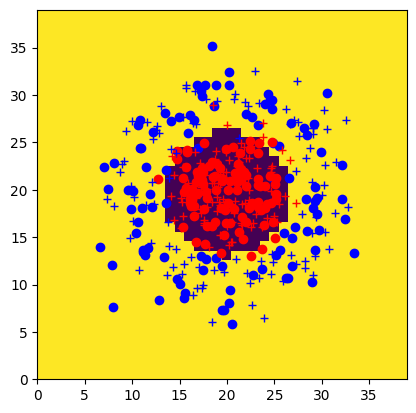

SVC rbf C=1 : train 96.00 / test 94.00 / support vectors 55


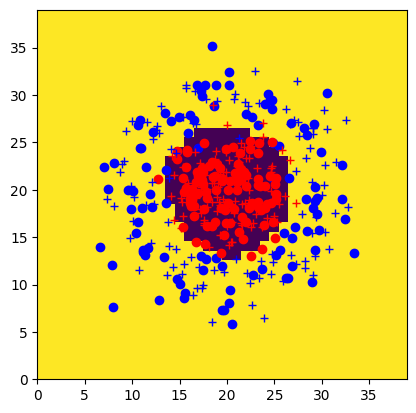

SVC rbf C=10 : train 97.00 / test 93.50 / support vectors 34


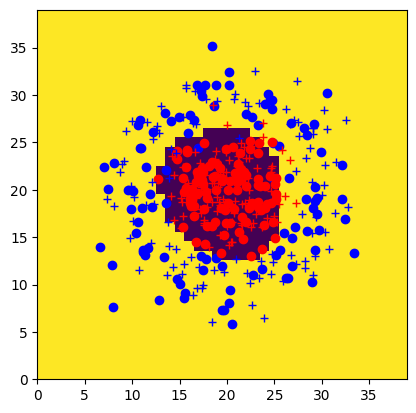

SVC rbf C=100 : train 97.50 / test 93.00 / support vectors 23


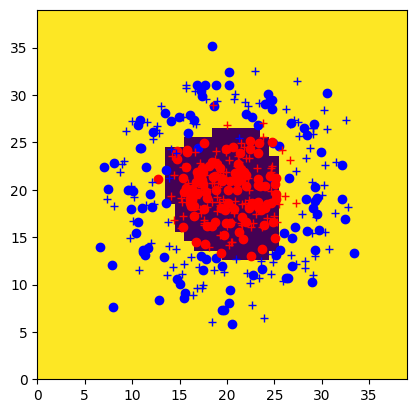

SVC rbf C=1000 : train 97.50 / test 93.00 / support vectors 23


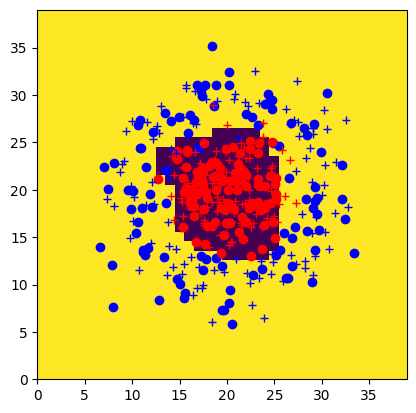

SVC rbf C=10000 : train 98.00 / test 93.50 / support vectors 26


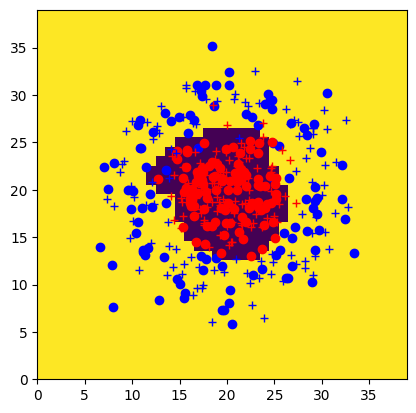

In [21]:
## Print results

Ytest_pred = svm.predict(Xtest)
accuracy = np.sum(Ytest == Ytest_pred) / len(Ytest)
print(f"Accuracy : {100 * accuracy:.2f}")
Ygrid_pred = svm.predict(Xgrid)
plot_svm_predictions(data, Ygrid_pred)

lin = sklearn.svm.LinearSVC(C=1.0)
lin.fit(Xtrain, Ytrain)
print(f"LinearSVC : train {100 * lin.score(Xtrain, Ytrain):.2f} / test {100 * lin.score(Xtest, Ytest):.2f}")
plot_svm_predictions(data, lin.predict(Xgrid))

print()
for params in [dict(kernel="linear"), dict(kernel="poly", degree=2), dict(kernel="poly", degree=3), dict(kernel="rbf"), dict(kernel="sigmoid")]:
    s = sklearn.svm.SVC(C=1.0, **params)
    s.fit(Xtrain, Ytrain)
    print(f"SVC {params} : train {100 * s.score(Xtrain, Ytrain):.2f} / test {100 * s.score(Xtest, Ytest):.2f} / support vectors {s.n_support_.sum()}")

print()
for C in [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]:
    s = sklearn.svm.SVC(kernel="rbf", C=C)
    s.fit(Xtrain, Ytrain)
    print(f"SVC rbf C={C} : train {100 * s.score(Xtrain, Ytrain):.2f} / test {100 * s.score(Xtest, Ytest):.2f} / support vectors {s.n_support_.sum()}")
    plot_svm_predictions(data, s.predict(Xgrid))